# Risk stratification for work disability in systemic lupus erythematosus from routine clinic visits: development and temporal validation of a prediction model

## What this tool is for

At each routine visit of an **employed** patient with SLE, the model estimates the chance that the patient will
**leave paid work for health reasons within the next 24 months**, and places the visit in a **risk tier**. From the
sequence of these risks, a **patient-level alarm** flags the patients the clinic should ask about work.

> **Why it matters.** Vocational support (occupational therapy, workplace adjustment, social work, vocational
> rehabilitation) works best *before* someone leaves work. A referral is cheap and carries little harm. So the
> useful question is not "who will certainly stop working?" but "**whom should we talk to about work now?**"

**Work disability** means a recorded status of *disabled*, or sick leave lasting at least 6 months without a
return to work. Leaving work for other reasons (retirement, homemaking, study, unemployment) is a different
outcome. These are handled as **competing events**: they end the patient's time at risk, but they are not counted
as work disability.

## How the notebook is organised

The notebook is organised around four questions a reader should ask of any prediction model:

1. **Is the outcome measured well enough to predict?** (Part I)
2. **Does the model rank and size risk correctly in patients it has not seen?** (Parts II-III)
3. **Does it still work in later years, and can it be kept up to date?** (Part IV)
4. **Could the results be an artefact of how the data were recorded?** (Part V)

Part VI asks whether the tool would help clinical decisions. Part VII prepares checks that do not depend on the
analysts. Part VIII sets every hypothesis against its result.

## Hypotheses

### Primary hypothesis

| | Hypothesis | What is compared | Met if |
|:--|:--|:--|:--|
| **H1** | **Routine clinic data identify who is at higher risk of work disability better than who the patient is (age, education, race).** | Cross-validated AUROC at 24 months: HazReg − demographics-only model | The 95 % CI of the difference lies above 0 |

### Secondary hypotheses

These explain *where* the primary result comes from, and how far it can be trusted.

| | Hypothesis | What is compared | Met if |
|:--|:--|:--|:--|
| | **The model ladder: where does the information come from?** | | |
| H2a | The first employed visit adds to demographics | First-visit model − demographics, AUROC | CI above 0 |
| H2b | The current visit adds to the first visit | HazReg − first-visit model, AUROC | CI above 0 |
| | **Is the tool accurate enough to use?** | | |
| H3a | Predicted risks match observed risks | Calibration slope; observed / expected (O/E) | Slope 0.8-1.2; O/E CI includes 1 |
| H3b | The model beats knowing only the clinic's average risk | Index of prediction accuracy (IPA) | CI above 0 |
| H3c | Referring by the model beats referring everyone or no one | Net benefit at a 4 % threshold | Above both, CI excluding them |
| | **Does a different kind of model do better?** | | |
| H4a | A logistic regression of the 24-month outcome performs the same | LogReg − HazReg, AUROC | CI within ± 0.02 |
| H4b | A deep-learning model reading the whole visit history is not materially better | LSTM − HazReg, AUROC | CI within ± 0.02 |
| | **Does the model hold up over calendar time?** | | |
| H5a | The ranking carries over to later years | Temporal AUROC, HazReg − demographics (pooled over periods) | CI above 0 |
| H5b | The level of risk carries over without updating | Temporal O/E, pooled | CI includes 1 |
| H5c | Temporal recalibration restores the level | Temporal O/E after recalibration, pooled | CI includes 1 |
| | **Does the result depend on the outcome definition?** | | |
| H6 | The model still ranks risk when early retirement (< 60), homemaking and "other" exits count as outcomes | HazReg − demographics under the broader outcome, AUROC | CI above 0 |
| | **Does the patient's history add to the current visit?** | | |
| H7a | The last 2 years add to the current visit | AUROC, HazReg + 2-year history summaries − HazReg | CI above 0 |
| H7b | The whole record adds to the current visit | AUROC, HazReg + whole-record history summaries − HazReg | CI above 0 |

**Every comparative hypothesis is also tested at the patient level**, with the same rule applied to the
time-matched patient C of the alarm's evaluation (Section 3.0.1). The summary (Part VIII) shows both verdicts side
by side.

> **How to read "met".** A hypothesis is met when the confidence interval falls entirely on the stated side.
> "Not met" can mean the effect is absent *or* that the data are too few to show it. The summary (Part VIII) says
> which.

## The design at a glance

| | |
|:--|:--|
| **Who** | Every clinic visit at which the patient is recorded as employed and is under 65 (a *landmark*) |
| **What is predicted** | The probability of work-disability onset within 24 months. Other exits from work compete with it. Death and leaving the clinic end follow-up without an outcome |
| **Reported model** | **HazReg**: two penalised hazard regressions (one for work disability, one for other exits) on 20 routine variables at the visit. No calendar time |
| **Model ladder** | Demographics only → the first employed visit → the current visit (HazReg) |
| **Comparators** | **LogReg** (the 24-month outcome as yes / no); **LSTM** (reads every earlier clinic visit) |
| **History** | Current visit vs the last 2 years vs the whole record, in the regression and the LSTM families |
| **Patient-level alarm** | Raised at 2 consecutive visits ≥ 4 % or 1 visit ≥ 10 %; kept until 2 consecutive visits < 2 % |
| **Patient-level evaluation** | Each onset against the patients still working at that moment, over the same 24 calendar months: patient C, sensitivity, specificity; alarms per 100 person-years, alarm PPV, lead time |
| **Validation** | 5 × 5-fold patient-grouped cross-validation; 200 bootstrap refits (optimism, stability); validation period by period over calendar time |
| **Keeping it current** | Temporal recalibration: the predictor effects are kept, the baseline risk is re-estimated from recent years |
| **Checks for artefacts** | Simulation with known truth; patients who left the clinic while employed; a multistate model; a broader outcome definition |
| **Clinical use** | Calibration; risk tiers (< 2, 2-4, 4-10, ≥ 10 %); decision curve |

**Contents**

* **Part I. Data**: source tables, recording over time, the outcome, an audit of how the outcome is recorded, the
  cohort at a glance (entry and final state, every patient's record, two example patients, the years before an onset)
* **Part II. The models**: the reported model, the ladder, the comparators, sample size, the patient-level alarm
* **Part III. How well does it work?**: visit- and patient-level evaluation; the ladder, the comparators, optimism and
  stability, what the model learned; current visit vs last 2 years vs whole record
* **Part IV. Over calendar time**: period-by-period validation, temporal recalibration, the deployed model
* **Part V. Could the results be an artefact?**: simulation, clinic leavers, a broader outcome
* **Part VI. Clinical use**: calibration, tiers, net benefit; what each threshold means per 1,000 visits; the
  patient-level alarm (rules, per 100 patients, lead time); where patients end up by risk; movement between tiers and
  how long alarms last; the risk and the alarm as an onset approaches; individual risk trajectories

Every results section reports the patient level beside the visit level.
* **Part VII. Checks that do not depend on the analysts**
* **Part VIII. Summary**: every hypothesis and its result

> **Running the notebook.** It reads the clinic's exported tables directly (`SLE_SOURCE_DIR`). Fitted models are
> checkpointed in `state_update_v22.pkl`; deleting it refits everything. `SLE_SMOKE=1` runs a quick test version.
> Figures go to `figs_update_v22/`.

---
# Part I. Data

## 1.1 Configuration

The next cell sets every analysis choice in one place: the outcome rules, the horizon, the inputs, the validation
design, the recalibration window and the equivalence margin.

In [1]:
"""Configuration: every analysis choice in one place."""
import os, json, hashlib, time, pickle, subprocess, shutil, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import brentq
from sklearn.linear_model import PoissonRegressor, LogisticRegression
from sklearn.model_selection import StratifiedKFold
from joblib import Parallel, delayed
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_rows", 200)

SMOKE = os.environ.get("SLE_SMOKE") == "1"         # quick end-to-end test only (not for results)
TAG = "update_v22"
SOURCE_DIR = os.environ.get("SLE_SOURCE_DIR",
                            "/Users/javimencia/Desktop/ReSTORE Lab/SLE Toronto Western/SLE SUDS/dataset")
REQUEST_DIR = os.path.join(SOURCE_DIR, "requested")   # tables requested from the clinic database (Section 7.4)
OUT_DIR = f"figs_{TAG}"
STATE_PATH = f"state_{TAG}{'_smoke' if SMOKE else ''}.pkl"
os.makedirs(OUT_DIR, exist_ok=True)
SEED = 240
MONTH_DAYS = 365.25 / 12
N_JOBS = max(1, (os.cpu_count() or 2) - 2)

# ---- outcome (Section 1.4)
SICK_LEAVE_MIN_MONTHS = 6
AGE_CAP_YEARS = 65
WORKING_STATES, SICK_STATES, DISABLED_STATES = {"employed"}, {"sick leave"}, {"disabled"}
OTHER_EXIT_STATES = {"retired", "homemaker", "student", "looking for work", "other"}
CAUSE_NAMES = {0: "censored", 1: "work disability", 2: "other exit"}
LEFT_CLINIC_YEARS = 2.0          # censored patients last seen more than this before the extract end "left the clinic"
# the broader outcome of the sensitivity analysis (Section 5.3): these other exits also count as work disability
BROAD_EXITS = {"homemaker", "other"}
BROAD_RETIRE_BEFORE = 60         # retirement before this age also counts

# ---- prediction
H = 24                           # horizon (months)
HORIZON_DAYS = round(H * MONTH_DAYS)

# ---- the model's inputs (Section 2.1): 20 variables at the landmark visit
COMPACT_VARS = ["age_at_record", "disease_duration_yrs", "AMS_12M", "score_n", "STERAVER_0", "FATIGUE",
                "FM_ANY", "ARTHRALGIA", "DYSPNOEA", "TREAT_LADDER", "YRS_IN_CLINIC", "AM_CLASS", "IS_CLASS",
                "ADV_CLASS", "GC_ERA_PCTL", "SDI_NP", "JOINT_COUNT", "MSK_DAMAGE", "EDU_HIGHER", "SMOKER"]
AMS_WINDOW_DAYS = 365.25         # adjusted mean SLEDAI-2K: time-weighted mean over the past 12 months
FM_TENDER_POINTS = 11            # fibromyalgia: recorded diagnosis, or at least this many tender points (ACR 1990)
DEMO_VARS = ["age_at_record", "EDU_HIGHER", "RACE_BLACK", "RACE_ASIAN", "RACE_OTHER_UNKNOWN"]   # the reference model
SPLINE_VARS = ["STERAVER_0", "score_n", "AMS_12M", "age_at_record"]
LOG1P_VARS = {"STERAVER_0", "score_n", "AMS_12M", "disease_duration_yrs", "YRS_IN_CLINIC", "JOINT_COUNT",
              "SDI_NP", "MSK_DAMAGE"}
CLIP_Z = 5.0
ALPHA_GRID = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1]   # ridge penalty, chosen per cause by inner CV
INNER_SPLITS = 3
LOGREG_C_GRID = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 1.0]  # LogReg inverse penalty, chosen by inner CV
# the LSTM comparator (Section 2.3): reads every clinic visit up to the landmark; outputs the two log-hazards
LSTM_CFG = dict(hidden=32, dropout=0.3, weight_decay=1e-2, lr=2e-3, batch_patients=32, val_share=0.15,
                max_epochs=4 if SMOKE else 150, patience=2 if SMOKE else 15)
EQUIV_MARGIN = 0.02              # H4a, H4b: AUROC differences inside +/- this margin count as equivalent

# ---- validation (Part III)
CV_SPLITS, CV_REPEATS = (3, 1) if SMOKE else (5, 5)
BOOT_REFITS = 8 if SMOKE else 200                # bootstrap refits: optimism, instability, coefficient intervals
BOOT_CI = 100 if SMOKE else 1000                 # patient-cluster bootstrap resamples for confidence intervals
PERIODS = [(2004, 2008), (2008, 2012), (2012, 2016), (2016, 2020), (2020, 2025)]   # internal-external validation
# temporal recalibration (Section 4.2): baseline hazards re-estimated on the person-time of the most recent
# RECAL_YEARS years, ending RECAL_LAG_MONTHS before the data end (onsets near the data end are not yet confirmed)
RECAL_YEARS = 4
RECAL_LAG_MONTHS = 12
ERAS = [(1970, 2000, "< 2000"), (2000, 2005, "2000-04"), (2005, 2010, "2005-09"), (2010, 2015, "2010-14"),
        (2015, 2020, "2015-19"), (2020, 2030, ">= 2020")]
RISK_TIERS = [(0.0, 0.02, "< 2 %"), (0.02, 0.04, "2-4 %"), (0.04, 0.10, "4-10 %"), (0.10, 1.01, ">= 10 %")]
DCA_THRESHOLDS = np.round(np.arange(0.01, 0.201, 0.01), 3)
SIM_REPS = 5 if SMOKE else 200                   # plasmode simulation replicates
TIP_DRAWS = 5 if SMOKE else 50                   # draws per scenario of the clinic-leaver analysis

# ---- figures: three categorical hues (fixed order) and ink
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
C4, C5 = "#4a3aa7", "#8d6e63"
MODEL_COLORS = {"HazReg": C1, "LogReg": C2, "LSTM": C4, "First visit": C3, "Demographics": C5}
INK, INK_2, GRID_C = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 8.5, "axes.edgecolor": INK_2,
                     "axes.labelcolor": INK, "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True,
                     "grid.color": GRID_C, "grid.linewidth": 0.6, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.axisbelow": True, "lines.linewidth": 2.0, "legend.frameon": False})


STATE_COLORS = {"W": C1, "S": "#eda100", "D": "#e34948", "O": C4, "U": "#d6d4cd"}   # employed / sick / disabled / other / unknown
TIER_COLORS = ["#f7e3a6", "#e8b93a", "#c98500", "#7d5300"]                         # risk tiers: one amber ramp
from matplotlib.colors import LinearSegmentedColormap
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#a9c8ee", C1, "#123f78"])


def save_table(df, name):
    """The numbers behind a figure, saved next to it (the figure is what the notebook shows)."""
    df.to_csv(os.path.join(OUT_DIR, f"{name}.csv"))


def say(text):
    """Interpretation printed under a result, as formatted text."""
    display(Markdown(textwrap.dedent(text).strip()))


def save_fig(name, fig=None):
    fig = fig or plt.gcf()
    fig.savefig(os.path.join(OUT_DIR, f"{name}.png"), bbox_inches="tight")
    fig.savefig(os.path.join(OUT_DIR, f"{name}.pdf"), bbox_inches="tight")
    plt.show()


# ---- the preprocessing class is defined here so that the checkpoint (which stores fitted models) can be read
def _slog1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


def rcs_nl(x, knots):
    """Nonlinear term of a 3-knot restricted cubic spline (Harrell)."""
    k1, k2, k3 = knots
    p3 = lambda u: np.maximum(u, 0.0) ** 3
    return (p3(x - k1) - p3(x - k2) * (k3 - k1) / (k3 - k2) + p3(x - k3) * (k2 - k1) / (k3 - k2)) / (k3 - k1) ** 2


class Prep:
    """Training-sample preprocessing: signed log1p of skewed inputs, median imputation + missing indicators, spline
    terms (knots at the training 10th / 50th / 90th percentiles), standardisation, clipping at +/- 5 SD."""

    def __init__(self, cols, spline=()):
        self.cols, self.spline = list(cols), [c for c in spline if c in cols]

    def _raw(self, X):
        Z = X[self.cols].astype(float).copy()
        for c in self.cols:
            if c in LOG1P_VARS:
                Z[c] = _slog1p(Z[c])
        return Z

    def fit(self, X):
        Z = self._raw(X)
        self.ind = [c for c in self.cols if c in MISSING_COLS]
        self.med = Z.median()
        Zf = Z.fillna(self.med)
        self.knots = {}
        for c in self.spline:
            kn = np.percentile(Zf[c].values, [10, 50, 90])
            if not np.all(np.diff(kn) > 1e-9):
                kn = np.percentile(np.unique(Zf[c].values), [10, 50, 90])
            if np.all(np.diff(kn) > 1e-9):
                self.knots[c] = tuple(kn)
        Zf = self._add_nl(Zf)
        self.mu, self.sd = Zf.mean(), Zf.std().replace(0, 1.0).fillna(1.0)
        return self

    def _add_nl(self, Z):
        for c, kn in self.knots.items():
            Z[f"{c}__NL"] = rcs_nl(Z[c].values, kn)
        return Z

    def transform(self, X):
        Z = self._raw(X)
        miss = Z[self.ind].isna().astype(float).values
        Z = self._add_nl(Z.fillna(self.med))
        Z = ((Z - self.mu) / self.sd).clip(-CLIP_Z, CLIP_Z).values
        return np.hstack([Z, miss])

    @property
    def names(self):
        return self.cols + [f"{c}__NL" for c in self.knots] + [f"{c}__MISSING" for c in self.ind]

    def to_dict(self):
        return {"cols": self.cols, "log1p": [c for c in self.cols if c in LOG1P_VARS],
                "median": {c: float(self.med[c]) for c in self.cols}, "knots": {c: list(k) for c, k in self.knots.items()},
                "mean": {c: float(v) for c, v in self.mu.items()}, "sd": {c: float(v) for c, v in self.sd.items()},
                "missing_indicators": self.ind, "clip_z": CLIP_Z}


def _load_state():
    if os.path.exists(STATE_PATH):
        with open(STATE_PATH, "rb") as f:
            return pickle.load(f)
    return {}


def _save_state():
    tmp = STATE_PATH + ".tmp"
    with open(tmp, "wb") as f:
        pickle.dump(STATE, f)
    os.replace(tmp, STATE_PATH)


STATE = _load_state()
print(f"{TAG}{' | SMOKE TEST' if SMOKE else ''} | source tables: {SOURCE_DIR} | horizon {H} months | "
      f"CV {CV_REPEATS} x {CV_SPLITS}-fold | {BOOT_REFITS} bootstrap refits | {N_JOBS} parallel jobs")

update_v22 | source tables: /Users/javimencia/Desktop/ReSTORE Lab/SLE Toronto Western/SLE SUDS/dataset | horizon 24 months | CV 5 x 5-fold | 200 bootstrap refits | 6 parallel jobs


## 1.2 From the clinic's source tables to one row per visit

The analysis starts from the tables exported from the clinic database, not from a pre-merged file. That matters
because a merged file kept only visits with a recorded employment status, which cut off years of clinical history
for some patients. Three rules follow:

1. **Every clinic visit is kept**, including visits where the employment status was not recorded. The status is
   needed only to define the outcome (Section 1.4). Clinical history (carried-forward items, years in clinic,
   treatment) uses every visit, so it is not thinned where the status field happened to be empty.
2. **Every variable is built from that visit and earlier ones only.** Carried-forward items keep their last
   recorded value. The prednisone era-percentile ranks the dose against the *previous* calendar year's clinic
   visits, so it can be computed at the time of the visit.
3. **Each table's contribution is logged** (rows read, visits matched), and every input variable's recording rate
   is shown by era (Section 1.3). A variable recorded only in some eras changes meaning over calendar time.

In [2]:
"""Source tables -> one row per visit (this and earlier visits only)."""
PROVENANCE = []
RACE_LABELS = {1: "White", 2: "Black", 3: "Chinese", 4: "Other", 5: "Native North American", 6: "Filipino",
               7: "Mixed"}
IS_TYPES = {1: "AZA", 2: "CYC", 3: "MTX", 4: "CSA", 5: "MMF", 6: "OTHER"}
SDI_NP_ITEMS = ["COGNIMP", "SEIZURX6", "CERVASAC", "CPNEUR", "TRANMYEL"]
SDI_MSK_ITEMS = ["ATROPHY", "DEARTHRIT", "OSTEOPOR", "AVASCNEC", "OSTEOMYEL", "RUPTEND"]
MAIN_MAN_COLS = ["ID", "FATIGUE", "FIBROMYA", "ARTHRALG", "DYSPNEA", "TPCOUNT", "JNTCOUNT", "CIGSMOK"]


def _read(name, **kw):
    path = os.path.join(SOURCE_DIR, name)
    if name.endswith(".xlsx"):
        return pd.read_excel(path, **kw)
    try:
        return pd.read_csv(path, low_memory=False, **kw)
    except UnicodeDecodeError:
        return pd.read_csv(path, low_memory=False, encoding="latin1", **kw)


def _date(s):
    return pd.to_datetime(s.astype(str), format="ISO8601", errors="coerce", utc=True).dt.tz_localize(None)


def _log(step, df, note=""):
    PROVENANCE.append({"Step": step, "Rows": len(df),
                       "Patients": df["PTNO"].nunique() if "PTNO" in df else np.nan, "Note": note})


def _join_visit_table(base, right, name):
    """Left-join a visit-level table on the visit ID (one row per ID)."""
    right = right.drop(columns=[c for c in ["PTNO"] if c in right.columns])
    assert right["ID"].is_unique, f"{name}: visit ID not unique"
    n = int(base["ID"].isin(right["ID"]).sum())
    PROVENANCE.append({"Step": f"join {name}", "Rows": len(right), "Patients": np.nan,
                       "Note": f"{n:,} of {len(base):,} visits matched ({n / len(base):.0%})"})
    return base.merge(right, on="ID", how="left", validate="one_to_one")


def source_hashes(source_dir=None):
    """SHA-256 of every source file (recorded with the frozen model, Section 7.1)."""
    d = source_dir or SOURCE_DIR
    out = {}
    for f in sorted(os.listdir(d)):
        p = os.path.join(d, f)
        if os.path.isfile(p) and f.lower().endswith((".csv", ".xlsx", ".xls")):
            with open(p, "rb") as fh:
                out[f] = hashlib.sha256(fh.read()).hexdigest()
    return out


def build_visits(source_dir=None):
    """One row per clinic visit with the model's inputs, built from the source tables."""
    global SOURCE_DIR
    if source_dir is not None:
        SOURCE_DIR = source_dir
    PROVENANCE.clear()
    # ---- visit spine: every assessment in employment.csv (status may be empty)
    v = _read("employment.csv")
    v["ASSDT"] = _date(v["ASSDT"])
    v["EMP"] = v["EMP"].astype("string").str.strip().str.lower().replace({"": pd.NA, "na": pd.NA, "nan": pd.NA})
    _log("employment.csv (visit spine)", v, f"{int(v['EMP'].notna().sum()):,} visits with a recorded status")
    v = v.dropna(subset=["PTNO", "ASSDT"])
    v["_has"] = v["EMP"].notna()
    v = v.sort_values(["PTNO", "ASSDT", "_has", "ID"], ascending=[True, True, False, True])
    n0 = len(v)
    v = v.drop_duplicates(["PTNO", "ASSDT"], keep="first").drop(columns="_has")
    _log("dated, one visit per patient-date", v, f"{n0 - len(v):,} same-date duplicates dropped (status-recorded "
                                                 f"row kept)")
    # ---- visit-level tables
    sl = _read("sledai.csv")[["ID", "SLEDAI2_I"]]
    v = _join_visit_table(v, sl, "sledai.csv")
    sdi = _read("updatedsdi.xlsx", usecols=["ID", "score_n"] + SDI_NP_ITEMS + SDI_MSK_ITEMS)
    for c in sdi.columns.drop("ID"):
        sdi[c] = pd.to_numeric(sdi[c], errors="coerce")
    sdi["SDI_NP_RAW"] = sdi[SDI_NP_ITEMS].sum(axis=1, min_count=1)
    sdi["MSK_RAW"] = sdi[SDI_MSK_ITEMS].sum(axis=1, min_count=1)
    v = _join_visit_table(v, sdi[["ID", "score_n", "SDI_NP_RAW", "MSK_RAW"]].rename(columns={"score_n": "SDI_RAW"}),
                          "updatedsdi.xlsx")
    st = _read("steroids.csv")[["ID", "STERAVER", "STPULSE"]]
    v = _join_visit_table(v, st, "steroids.csv")
    am = _read("amalarials.csv")[["ID", "AMDOSE"]]
    v = _join_visit_table(v, am, "amalarials.csv")
    im = _read("immunosup.csv")
    assert not im.duplicated(["ID", "ISTYPE"]).any()
    wide = pd.DataFrame({"ID": im["ID"].unique()})
    for code, nm in IS_TYPES.items():
        s = im[im["ISTYPE"] == code].set_index("ID")
        dose = pd.to_numeric(s["ISDOSE"], errors="coerce")
        anyrec = s[["ISMETH", "ISDATE", "ISDOSE", "ISAVER"]].notna().any(axis=1)
        if nm in ("CYC", "OTHER"):                   # IV cyclophosphamide / other: any record at the visit
            wide[f"ON_{nm}"] = wide["ID"].map(anyrec).fillna(False).astype(float)
        else:
            wide[f"ON_{nm}"] = (wide["ID"].map(dose).fillna(0.0) > 0).astype(float)
    v = _join_visit_table(v, wide, "immunosup.csv (one column per drug)")
    bio = _read("biologics.csv")
    flags = bio[["BIOG_RIT", "BIOG_BEL", "BIOG_ABA", "BIOG_OTH", "RIT", "BEL", "ABA", "OTH"]].apply(
        pd.to_numeric, errors="coerce").eq(1).any(axis=1)
    v = _join_visit_table(v, pd.DataFrame({"ID": bio["ID"], "ON_BIOLOGIC": flags.astype(float)}), "biologics.csv")
    mm = _read("main_man.csv", usecols=MAIN_MAN_COLS)
    v = _join_visit_table(v, mm, "main_man.csv (7 items)")
    # ---- patient-level tables
    cod = _read("Cause of death.xlsx")
    demo = _read("demo.csv")
    for d_ in (cod, demo):
        for c in ["BIRTHDT", "DATEOFDX", "DEATHDT", "LCDT"]:
            d_[c] = _date(d_[c])
    pt = cod.set_index("PTNO").combine_first(demo.set_index("PTNO"))[["BIRTHDT", "SEX", "DATEOFDX", "RACE",
                                                                      "STATUS", "DEATHDT"]]
    ds = _read("dataset.csv").set_index("PTNO")["MAX_EDU"]
    v = v.merge(pt, left_on="PTNO", right_index=True, how="left")
    v["EDU_HIGHER"] = v["PTNO"].map(ds).astype(float)
    _log("patient tables (Cause of death.xlsx + demo.csv, dataset.csv)", v,
         f"birth date for {v.drop_duplicates('PTNO')['BIRTHDT'].notna().mean():.0%} of patients; education for "
         f"{v.drop_duplicates('PTNO')['EDU_HIGHER'].notna().mean():.0%}")
    v = v.sort_values(["PTNO", "ASSDT"]).reset_index(drop=True)
    g = v.groupby("PTNO", sort=False)
    num = lambda c: pd.to_numeric(v[c], errors="coerce")

    # ---- the 20 inputs (this and earlier visits only)
    v["age_at_record"] = (v["ASSDT"] - v["BIRTHDT"]).dt.days / 365.25
    v["disease_duration_yrs"] = (v["ASSDT"] - v["DATEOFDX"]).dt.days / 365.25
    v["YRS_IN_CLINIC"] = (v["ASSDT"] - g["ASSDT"].transform("min")).dt.days / 365.25   # from the first clinic visit
    v["CAL_YEAR"] = v["ASSDT"].dt.year + (v["ASSDT"].dt.dayofyear - 1) / 365.25
    # recorded-at-this-visit flags (for the recording-rate table) before carrying forward
    raw = {"SLEDAI2_I": num("SLEDAI2_I"), "score_n": num("SDI_RAW"), "FATIGUE": num("FATIGUE"),
           "FIBROMYALGIA": num("FIBROMYA"), "ARTHRALGIA": num("ARTHRALG"), "DYSPNOEA": num("DYSPNEA"),
           "TENDER_POINTS": num("TPCOUNT"), "SMOKER": num("CIGSMOK"), "SDI_NP": num("SDI_NP_RAW"),
           "MSK_DAMAGE": num("MSK_RAW"), "JOINT_COUNT": num("JNTCOUNT")}
    for c, x in raw.items():
        v[f"_REC_{c}"] = x.notna()
        v[c] = x.groupby(v["PTNO"]).ffill()
    for c in ["FATIGUE", "FIBROMYALGIA", "ARTHRALGIA", "DYSPNOEA", "SMOKER"]:
        v[c] = (v[c] > 0).astype(float).where(v[c].notna())
    v["STERAVER_0"] = num("STERAVER").fillna(0.0)    # an empty dose field = not on the drug
    pulse = num("STPULSE").fillna(0.0) > 0
    for c in ["ON_AZA", "ON_CYC", "ON_MTX", "ON_CSA", "ON_MMF", "ON_OTHER", "ON_BIOLOGIC"]:
        v[c] = v[c].fillna(0.0)
    v["AM_CLASS"] = (num("AMDOSE").fillna(0.0) > 0).astype(float)
    v["IS_CLASS"] = ((v["ON_AZA"] + v["ON_MMF"] + v["ON_MTX"] + v["ON_CSA"]) > 0).astype(float)
    v["ADV_CLASS"] = ((v["ON_CYC"] + v["ON_BIOLOGIC"]) > 0).astype(float)
    gc = v["STERAVER_0"]
    conv = (v["IS_CLASS"] > 0) | (v["ON_OTHER"] > 0)
    # treatment ladder by drug class only (prednisone enters separately as the dose and its era percentile), so the
    # rungs mean the same in every era: 0 none, 1 antimalarial, 2 conventional immunosuppressant, 3 advanced therapy
    v["TREAT_LADDER"] = np.select([v["ADV_CLASS"] > 0, conv, v["AM_CLASS"] > 0], [3, 2, 1], 0).astype(float)
    # fibromyalgia: a recorded diagnosis, or >= 11 tender points at the last count (both carried forward)
    _fm, _tp = v["FIBROMYALGIA"], v["TENDER_POINTS"]
    v["FM_ANY"] = ((_fm > 0) | (_tp >= FM_TENDER_POINTS)).astype(float).where(_fm.notna() | _tp.notna())
    # adjusted mean SLEDAI-2K: area under the SLEDAI-2K curve (trapezoids between visits) over the past 12 months,
    # divided by the time covered; at a patient's first visit, that visit's score
    _ams = np.empty(len(v))
    _sl = v["SLEDAI2_I"].values.astype(float)
    _td = v["ASSDT"].values.astype("datetime64[D]").astype(float)
    for _idx in g.indices.values():
        t_, s_ = _td[_idx], _sl[_idx]
        lo_ = np.searchsorted(t_, t_ - AMS_WINDOW_DAYS, "left")
        for j in range(len(_idx)):
            tt, ss = t_[lo_[j]:j + 1], s_[lo_[j]:j + 1]
            ok = ~np.isnan(ss)
            tt, ss = tt[ok], ss[ok]
            _ams[_idx[j]] = (np.nan if len(ss) == 0 else ss[-1] if tt[-1] <= tt[0] else
                             np.sum((ss[1:] + ss[:-1]) / 2 * np.diff(tt)) / (tt[-1] - tt[0]))
    v["AMS_12M"] = _ams
    # prednisone dose as a mid-rank percentile of the PREVIOUS calendar year's clinic visits (computable at the visit)
    yr = v["ASSDT"].dt.year.values
    pct = np.full(len(v), np.nan)
    for y in np.unique(yr):
        ref = np.sort(gc.values[yr == y - 1])
        if len(ref) < 50:                            # first year of the clinic: the same year's visits
            ref = np.sort(gc.values[yr == y])
        k = yr == y
        lo, hi = np.searchsorted(ref, gc.values[k], "left"), np.searchsorted(ref, gc.values[k], "right")
        pct[k] = (lo + 0.5 * (hi - lo)) / len(ref)
    v["GC_ERA_PCTL"] = pct
    # race (patient constant): White / Black / Asian (Chinese, Filipino) / other, mixed or not recorded
    race = v["RACE"].map(RACE_LABELS)
    v["RACE_BLACK"] = (race == "Black").astype(float)
    v["RACE_ASIAN"] = race.isin(["Chinese", "Filipino"]).astype(float)
    v["RACE_OTHER_UNKNOWN"] = (race.isna() | race.isin(["Other", "Mixed", "Native North American"])).astype(float)
    v["RACE_GROUP"] = np.select([v["RACE_BLACK"] == 1, v["RACE_ASIAN"] == 1, v["RACE_OTHER_UNKNOWN"] == 1],
                                ["Black", "Asian", "Other / not recorded"], "White")
    v["SEX_FEMALE"] = (v["SEX"] == "F").astype(float).where(v["SEX"].notna())
    v["HAS_STATUS"] = v["EMP"].notna()
    v["EMP"] = v["EMP"].astype(object).where(v["EMP"].notna(), None)
    _log("visit table", v, f"{v['HAS_STATUS'].sum():,} visits with a recorded employment status")
    return v


visits = build_visits()
DATA_END_DATE = visits["ASSDT"].max()
display(pd.DataFrame(PROVENANCE).set_index("Step"))
_first_any = visits.groupby("PTNO")["ASSDT"].min()
_first_status = visits[visits["HAS_STATUS"]].groupby("PTNO")["ASSDT"].min()
_emp_pts = visits.loc[visits["EMP"] == "employed", "PTNO"].unique()
_gap = ((_first_status.reindex(_emp_pts) - _first_any.reindex(_emp_pts)).dt.days / 365.25)
print(f"Extract ends {DATA_END_DATE.date()}. Of {len(_emp_pts):,} patients ever recorded as employed, "
      f"{int((_gap > 5).sum())} ({(_gap > 5).mean():.0%}) attended the clinic for > 5 years before the first visit "
      f"with a recorded status; their clinical history and years in clinic start at their first clinic visit.")

,Rows,Patients,Note
Step,,,
employment.csv (visit spine),57067,2263.0,"42,800 visits with a recorded status"
"dated, one visit per patient-date",57063,2263.0,2 same-date duplicates dropped (status-recorde...
join sledai.csv,57067,NaN,"57,063 of 57,063 visits matched (100%)"
join updatedsdi.xlsx,57067,NaN,"57,063 of 57,063 visits matched (100%)"
join steroids.csv,34448,NaN,"34,448 of 57,063 visits matched (60%)"
join amalarials.csv,36088,NaN,"36,088 of 57,063 visits matched (63%)"
join immunosup.csv (one column per drug),25374,NaN,"25,374 of 57,063 visits matched (44%)"
join biologics.csv,1172,NaN,"1,172 of 57,063 visits matched (2%)"
join main_man.csv (7 items),57067,NaN,"57,063 of 57,063 visits matched (100%)"


Extract ends 2024-04-08. Of 1,121 patients ever recorded as employed, 162 (14%) attended the clinic for > 5 years before the first visit with a recorded status; their clinical history and years in clinic start at their first clinic visit.


## 1.3 How each input was recorded over calendar time

**The question.** Did the clinic record each item equally often in every era?

The figure shows the share of visits at which each item was freshly recorded (not carried forward from an earlier
visit). When an item is recorded less often, the value the model sees is older. Its effect then mixes the patient's
condition with the clinic's recording habits. The tender-point count is the clearest case, so it enters the model
only through the fibromyalgia definition (a recorded diagnosis, or at least 11 tender points), whose diagnosis
field is recorded at almost every visit.

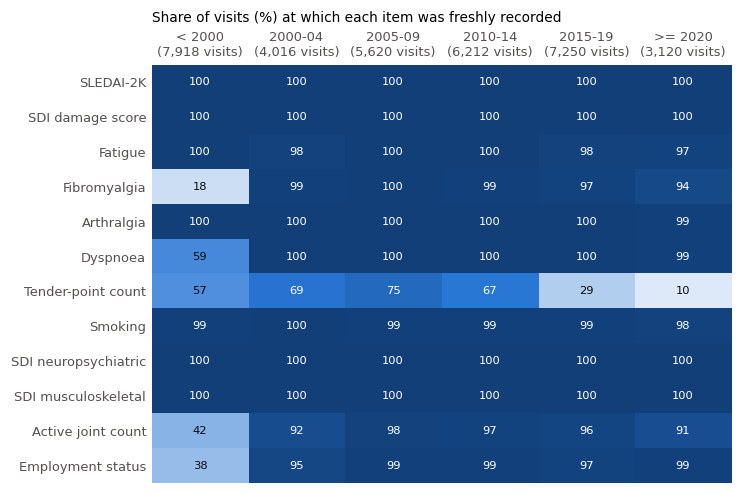

**What this means.** 5 item(s) changed recording rate by 30 percentage points or more between eras:
**FIBROMYALGIA**, **DYSPNOEA**, **TENDER_POINTS**, **JOINT_COUNT**, **HAS_STATUS**. For these, a recent value is often a
value carried forward from years earlier, so their coefficients should be read as markers of the clinic's records as
much as of the disease. The employment status itself (HAS_STATUS) is recorded at almost every visit from 2005
onward, so missing status fields cannot explain changes in the outcome rates after 2005.

In [3]:
"""Recording rate of each input by era (visits of patients ever employed)."""
_vv = visits[visits["PTNO"].isin(_emp_pts)].copy()
_vv["Era"] = pd.cut(_vv["ASSDT"].dt.year, [e[0] for e in ERAS] + [ERAS[-1][1]], right=False,
                    labels=[e[2] for e in ERAS])
_rec_cols = [c for c in _vv.columns if c.startswith("_REC_")] + ["HAS_STATUS"]
REC_TABLE = (_vv.groupby("Era", observed=True)[_rec_cols].mean() * 100).round(0).T
REC_TABLE.index = [c.replace("_REC_", "") for c in REC_TABLE.index]
REC_TABLE.loc["Visits (n)"] = _vv.groupby("Era", observed=True).size()
save_table(REC_TABLE, "recording_rates_by_era")
_REC_LABELS = {"SLEDAI2_I": "SLEDAI-2K", "score_n": "SDI damage score", "FATIGUE": "Fatigue", "FIBROMYALGIA": "Fibromyalgia",
               "ARTHRALGIA": "Arthralgia", "DYSPNOEA": "Dyspnoea", "TENDER_POINTS": "Tender-point count",
               "SMOKER": "Smoking", "SDI_NP": "SDI neuropsychiatric", "MSK_DAMAGE": "SDI musculoskeletal",
               "JOINT_COUNT": "Active joint count", "HAS_STATUS": "Employment status"}
_rt = REC_TABLE.drop(index="Visits (n)")
fig, ax = plt.subplots(figsize=(6.8, 0.32 * len(_rt) + 1.1))
ax.imshow(_rt.values.astype(float), cmap=SEQ_BLUE, vmin=0, vmax=100, aspect="auto")
for i in range(_rt.shape[0]):
    for j in range(_rt.shape[1]):
        v = float(_rt.iat[i, j])
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.5, color="white" if v >= 60 else INK)
ax.set_xticks(range(_rt.shape[1]), [f"{c}\n({int(REC_TABLE.loc['Visits (n)', c]):,} visits)" for c in _rt.columns])
ax.set_yticks(range(_rt.shape[0]), [_REC_LABELS.get(c, c) for c in _rt.index])
ax.tick_params(length=0); ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.xaxis.tick_top()
ax.set_title("Share of visits (%) at which each item was freshly recorded", loc="left", fontsize=9, pad=28)
save_fig("recording_rates_by_era")
_unstable = REC_TABLE.drop(index="Visits (n)").pipe(lambda t: t.loc[(t.max(1) - t.min(1)) >= 30])
say(f"""
**What this means.** {len(_unstable)} item(s) changed recording rate by 30 percentage points or more between eras:
{", ".join(f"**{c}**" for c in _unstable.index) if len(_unstable) else "none"}. For these, a recent value is often a
value carried forward from years earlier, so their coefficients should be read as markers of the clinic's records as
much as of the disease. The employment status itself (HAS_STATUS) is recorded at almost every visit from 2005
onward, so missing status fields cannot explain changes in the outcome rates after 2005.
""")

## 1.4 The outcome: leaving work for health reasons

> **In plain words.** At every visit where a patient is working, we look ahead to see whether they leave work for
> health reasons, leave for another reason, or are simply no longer followed. The rules below turn the clinic's
> status field into those three outcomes.

The outcome is read from the employment status recorded at visits: **working** (employed), **sick leave**,
**disabled**, **other exit** (retired, homemaker, student, looking for work, other). Visits without a recorded
status are ignored for the outcome. Follow-up of a working patient ends at the first of:

| What happens next | Classified as | Dated at |
|---|---|---|
| A visit with status *disabled* | **Work-disability onset** | that visit |
| A sick-leave spell with no return to work lasting **≥ 6 months**, whatever status follows | **Onset** | the start of the spell |
| A shorter sick-leave spell followed by *disabled* | **Onset** | the start of the spell |
| A sick-leave spell followed by a return to work | nothing (still at risk) | – |
| An other-exit status (or a short sick-leave spell followed by one) | **Competing exit** | that visit (spell start) |
| An open sick-leave spell shorter than 6 months at the last visit | **Censored** | the start of the spell |
| The last visit with a recorded status, age 65, or death | **Censored** | that date |

A **landmark** is every visit at which the patient is recorded as employed and is under 65 (except their last
recorded visit). A patient who returns to paid work after an onset re-enters at the next employed visit.

The status is only seen when the patient comes to clinic. So every onset date is really an **interval**: the
change happened after the last visit recorded as working and no later than the visit that shows it. For sick
leave, the onset is **confirmed** only at the first visit at least 6 months after the spell started. The next cell
records both quantities for every onset.

In [4]:
"""States, competing-risk follow-up from every landmark, the 24-month label, censoring weights, at-risk intervals."""
SICK_MIN_DAYS = SICK_LEAVE_MIN_MONTHS * MONTH_DAYS


def _state_of(emp):
    if emp in WORKING_STATES:
        return "W"
    if emp in SICK_STATES:
        return "S"
    if emp in DISABLED_STATES:
        return "D"
    if emp in OTHER_EXIT_STATES:
        return "O"
    return "U"


def _resolve_nonworking(states, emps, dates, j, n):
    """Outcome of the non-working spell starting at status-visit j: (kind, date, next index, detail)."""
    s = states[j]
    if s == "D":
        return "disability", dates[j], None, ("direct", emps[j], j, dates[j])
    if s == "O":
        return "other_exit", dates[j], None, ("direct", emps[j], j, dates[j])
    if s != "S":
        return "skip", None, j + 1, None
    r = j
    while r + 1 < n and states[r + 1] == "S":
        r += 1
    nxt = r + 1 if r + 1 < n else None
    if nxt is not None and states[nxt] == "W":
        return None, None, nxt, None                     # back to work: still at risk
    start = dates[j]
    spell = list(range(j, r + 1)) + ([nxt] if nxt is not None else [])
    long_enough = [q for q in spell if (dates[q] - start).days >= SICK_MIN_DAYS]
    end_emp = emps[nxt] if nxt is not None else "sick leave (open)"
    if long_enough:
        return "disability", start, None, ("long sick spell", end_emp, j, dates[long_enough[0]])
    if nxt is None:
        return "censored_sick", start, None, ("short open sick spell", end_emp, j, pd.NaT)
    if emps[nxt] in DISABLED_STATES:
        return "disability", start, None, ("short sick spell", end_emp, j, dates[nxt])
    return "other_exit", start, None, ("short sick spell", end_emp, j, dates[nxt])


def _follow_up_from(i, states, emps, dates, cap_date):
    n = len(states)
    j = i + 1
    while j < n:
        if states[j] == "W":
            j += 1
            continue
        kind, d, nxt, det = _resolve_nonworking(states, emps, dates, j, n)
        if kind in ("disability", "other_exit", "censored_sick"):
            if d > cap_date:
                return cap_date, 0, "age_cap", None
            return d, {"disability": 1, "other_exit": 2}.get(kind, 0), \
                {"censored_sick": "unresolved_sick_leave"}.get(kind, kind), det
        j = nxt
    if cap_date < dates[-1]:
        return cap_date, 0, "age_cap", None
    return dates[-1], 0, "end_of_follow_up", None


def build_landmarks(visits):
    sv = visits[visits["HAS_STATUS"]]
    rows = []
    for pid, idx in sv.groupby("PTNO", sort=False).indices.items():
        p = sv.iloc[idx]
        vrow = p.index.values
        states = [_state_of(e) for e in p["EMP"].values]
        dates, emps, ages = list(p["ASSDT"]), list(p["EMP"].values), p["age_at_record"].values
        birth = p["BIRTHDT"].iloc[0]
        cap_date = birth + pd.DateOffset(years=AGE_CAP_YEARS) if pd.notna(birth) else pd.Timestamp.max
        for i, s in enumerate(states):
            if s != "W" or ages[i] >= AGE_CAP_YEARS or i == len(states) - 1:
                continue
            d_end, cause, typ, det = _follow_up_from(i, states, emps, dates, cap_date)
            t = (d_end - dates[i]).days
            if t <= 0:
                continue
            rows.append({"pid": pid, "visit_row": int(vrow[i]), "visit_date": dates[i], "time_days": t,
                         "cause": cause, "exit_type": typ, "event_date": d_end if cause == 1 else pd.NaT,
                         "route": det[0] if det else None, "exit_emp": det[1] if det else None,
                         "last_work_date": dates[det[2] - 1] if det else pd.NaT,
                         "confirm_date": det[3] if det else pd.NaT, "last_status_date": dates[-1],
                         "dead": p["STATUS"].iloc[0] == "D"})
    return pd.DataFrame(rows)


land = build_landmarks(visits)
N_LAND = len(land)
PID_ALL = land["pid"].values
T_ALL = land["time_days"].values.astype(float)
C_ALL = land["cause"].values.astype(int)
LAND_T = ((land["visit_date"] - pd.Timestamp("1970-01-01")).dt.days).values.astype(float)
LAND_YEAR = land["visit_date"].dt.year.values + (land["visit_date"].dt.dayofyear.values - 1) / 365.25
for c in ["age_at_record", "SEX_FEMALE", "RACE_GROUP", "YRS_IN_CLINIC"]:
    land[c] = visits.loc[land["visit_row"], c].values
assert (np.diff(LAND_T)[PID_ALL[1:] == PID_ALL[:-1]] > 0).all()
LAND_X = visits.loc[land["visit_row"], sorted(set(COMPACT_VARS + DEMO_VARS))].reset_index(drop=True)

# ---- the 24-month label (complete case) and censoring weights (Kaplan-Meier of censoring)
land["admin_days"] = np.minimum((DATA_END_DATE - land["visit_date"]).dt.days.values.astype(float),
                                (AGE_CAP_YEARS - land["age_at_record"].values) * 365.25)
_h = T_ALL <= HORIZON_DAYS
Y24 = np.where((C_ALL == 1) & _h, 1.0, np.where(~_h | (C_ALL == 2), 0.0, np.nan))
Y24[land["admin_days"].values < HORIZON_DAYS] = np.nan


def km_censoring(t, censored):
    """G(s-): probability of being still uncensored just before s."""
    ut = np.unique(t[censored])
    at_risk = np.array([(t >= u).sum() for u in ut], float)
    n_c = np.array([((t == u) & censored).sum() for u in ut], float)
    surv = np.cumprod(1.0 - n_c / at_risk)

    def G_minus(s):
        idx = np.searchsorted(ut, s, side="left") - 1
        return np.where(idx >= 0, surv[np.clip(idx, 0, None)], 1.0)
    return G_minus


def ipcw_weights(t, c, rows=None, months=H):
    """IPCW weights at `months` for the cumulative-incidence target (competing exits are controls): w > 0 for every
    landmark whose status at the horizon is known; y = onset within the horizon. G is estimated on `rows`."""
    rows = np.arange(len(t)) if rows is None else rows
    tt, cc = t[rows], c[rows]
    G = km_censoring(tt, cc == 0)
    hd = round(months * MONTH_DAYS)
    ev = (cc >= 1) & (tt <= hd)
    surv = tt > hd
    w = np.zeros(len(rows))
    w[ev] = 1.0 / G(tt[ev])
    w[surv] = 1.0 / G(np.array([hd + 0.5]))[0]
    y = ((cc == 1) & (tt <= hd)).astype(float)
    return y, w


Y_IP, W_IP = ipcw_weights(T_ALL, C_ALL)

# ---- at-risk intervals between consecutive landmarks (the hazard models' target)
_END = LAND_T + T_ALL
_same_next = np.r_[PID_ALL[1:] == PID_ALL[:-1], False]
_next = np.r_[LAND_T[1:], np.inf]
_cont = _same_next & (_next < _END)
INT_END = np.where(_cont, _next, _END)
INT_YRS = (INT_END - LAND_T) / 365.25
D1 = (~_cont & (C_ALL == 1)).astype(float)
D2 = (~_cont & (C_ALL == 2)).astype(float)
ERA_LAB = pd.cut(land["visit_date"].dt.year, [e[0] for e in ERAS] + [ERAS[-1][1]], right=False,
                 labels=[e[2] for e in ERAS]).astype(str).values
ALL_PIDS = np.array(sorted(land["pid"].unique()))
PID_INDEX = {p: i for i, p in enumerate(ALL_PIDS)}
ROW_PIDX = np.array([PID_INDEX[p] for p in PID_ALL])
PT_ROWS = {p: np.flatnonzero(PID_ALL == p) for p in ALL_PIDS}
PID_EVENT = np.array([int((C_ALL[PT_ROWS[p]] == 1).any()) for p in ALL_PIDS])

print(f"Landmarks: {N_LAND:,} employed visits of {len(ALL_PIDS):,} patients (median "
      f"{land.groupby('pid').size().median():.0f} per patient)")
print(f"At-risk intervals: {INT_YRS.sum():,.0f} person-years | onsets {int(D1.sum())} in "
      f"{land.loc[C_ALL == 1, 'pid'].nunique()} patients | competing exits {int(D2.sum())} | "
      f"crude onset rate {100 * D1.sum() / INT_YRS.sum():.2f} per 100 person-years")
print(f"24-month label: onset {int(np.nansum(Y24 == 1)):,} | no onset {int(np.nansum(Y24 == 0)):,} | unresolved "
      f"{int(np.isnan(Y24).sum()):,}; IPCW cumulative incidence at 24 months {np.sum(W_IP * Y_IP) / N_LAND:.3f} "
      f"({int((W_IP > 0).sum()):,} landmarks with a known 24-month status)")

say(f"""
**What this means.** The analysis has {N_LAND:,} working visits from {len(ALL_PIDS):,} patients, with
{int(D1.sum())} work-disability onsets and {int(D2.sum())} other exits over {INT_YRS.sum():,.0f} person-years at
risk. About {100 * np.sum(W_IP * Y_IP) / N_LAND:.1f} % of working visits are followed by work disability within
24 months. The outcome is uncommon, so the tool's main job is to separate a small high-risk group from a large
low-risk one. At the patient level, {int(PID_EVENT.sum())} of the {len(ALL_PIDS):,} patients
({100 * PID_EVENT.mean():.0f} %) had at least one onset; these are the cases of the patient-level evaluation
(Section 3.0.1).
""")

Landmarks: 17,338 employed visits of 1,059 patients (median 11 per patient)
At-risk intervals: 8,625 person-years | onsets 158 in 150 patients | competing exits 237 | crude onset rate 1.83 per 100 person-years
24-month label: onset 556 | no onset 14,592 | unresolved 2,190; IPCW cumulative incidence at 24 months 0.035 (15,179 landmarks with a known 24-month status)


**What this means.** The analysis has 17,338 working visits from 1,059 patients, with
158 work-disability onsets and 237 other exits over 8,625 person-years at
risk. About 3.5 % of working visits are followed by work disability within
24 months. The outcome is uncommon, so the tool's main job is to separate a small high-risk group from a large
low-risk one. At the patient level, 150 of the 1,059 patients
(14 %) had at least one onset; these are the cases of the patient-level evaluation
(Section 3.0.1).

## 1.5 Audit of how the outcome is recorded

A prediction model can only be as good as its outcome. Here the outcome is read from a single form field filled
in at clinic visits, so five questions come before any model:

| | Question | Why it matters |
|:--|:--|:--|
| 1 | Do recorded exits from work stay put? | Frequent *disabled → employed* reversals would mean the status is noisy, or that exits are often temporary |
| 2 | How precisely is an onset dated, and how long until it is confirmed? | Onsets near the end of the data may not be visible yet |
| 3 | How does each patient's follow-up end, era by era? | A patient who stops attending while employed is counted as event-free. If some of them left work, recent risk is understated |
| 4 | How do exit rates change over calendar time, and through which route? | A change in how statuses are recorded looks exactly like a change in risk |
| 5 | Does the change survive a model built for status snapshots? | Rules out visit timing as the explanation |

### 1.5.1 Transitions in the status record

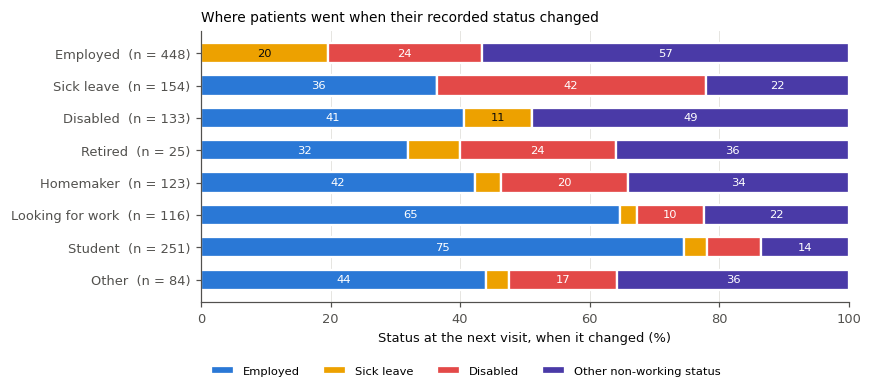

The status was unchanged at 96.7 % of consecutive recorded visits; the figure shows only the changes.


**What this means.** For every 106 moves from *employed* to *disabled* there are 54 moves back
(51%). A recorded disability is therefore often not permanent: some patients do return to work, and some
statuses are probably mis-recorded. The model handles real returns by letting a patient re-enter the risk set at
the next employed visit. Mis-recording can only be measured against the chart (Section 7.2).

In [5]:
"""Transitions between consecutive recorded statuses."""
_sv = visits.loc[visits["HAS_STATUS"], ["PTNO", "ASSDT", "EMP"]].copy()
_sv["prev"] = _sv.groupby("PTNO")["EMP"].shift()
TRANSITIONS = pd.crosstab(_sv["prev"], _sv["EMP"], rownames=["Status at a visit"], colnames=["Status at the next"])
save_table(TRANSITIONS, "status_transitions")
# where patients went when the recorded status changed (staying in the same status excluded)
_grp_next = lambda s: {"employed": "Employed", "sick leave": "Sick leave", "disabled": "Disabled"}.get(s, "Other non-working status")
_moves = TRANSITIONS.copy()
for s in _moves.index:
    if s in _moves.columns:
        _moves.loc[s, s] = 0
_mv = _moves.T.groupby(_grp_next).sum().T
_cats = [("Employed", STATE_COLORS["W"]), ("Sick leave", STATE_COLORS["S"]), ("Disabled", STATE_COLORS["D"]),
         ("Other non-working status", STATE_COLORS["O"])]
_order = ["employed", "sick leave", "disabled", "retired", "homemaker", "looking for work", "student", "other"]
_mv = _mv.reindex([s for s in _order if s in _mv.index])
_share = _mv.div(_mv.sum(1), axis=0) * 100
fig, ax = plt.subplots(figsize=(7.6, 3.2))
left = np.zeros(len(_share))
for nm, col in _cats:
    v = _share[nm].values if nm in _share else np.zeros(len(_share))
    ax.barh(range(len(_share)), v, left=left, color=col, edgecolor="white", linewidth=1.5, height=0.62, label=nm)
    for i, (l_, w_) in enumerate(zip(left, v)):
        if w_ >= 9:
            ax.text(l_ + w_ / 2, i, f"{w_:.0f}", ha="center", va="center", fontsize=7.5,
                    color="white" if nm != "Sick leave" else INK)
    left += v
ax.set_yticks(range(len(_share)), [f"{s.capitalize()}  (n = {int(_mv.loc[s].sum())})" for s in _share.index])
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_xlabel("Status at the next visit, when it changed (%)")
ax.set_title("Where patients went when their recorded status changed", loc="left", fontsize=9)
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.2), fontsize=7.5)
save_fig("status_transitions")
_stay = np.diag(TRANSITIONS.reindex(index=TRANSITIONS.columns).fillna(0).values).sum() / TRANSITIONS.values.sum()
print(f"The status was unchanged at {100 * _stay:.1f} % of consecutive recorded visits; the figure shows only the changes.")
_dw = int(TRANSITIONS.loc["disabled", "employed"]) if "employed" in TRANSITIONS else 0
_wd = int(TRANSITIONS.loc["employed", "disabled"])
say(f"""
**What this means.** For every {_wd} moves from *employed* to *disabled* there are {_dw} moves back
({_dw / _wd:.0%}). A recorded disability is therefore often not permanent: some patients do return to work, and some
statuses are probably mis-recorded. The model handles real returns by letting a patient re-enter the risk set at
the next employed visit. Mis-recording can only be measured against the chart (Section 7.2).
""")

### 1.5.2 How onsets are dated and confirmed

In [6]:
"""Onset interval (bracket) and sick-leave confirmation lag, by era."""
_on = land[C_ALL == 1].drop_duplicates(["pid", "event_date"]).copy()
_on["Bracket (months)"] = (_on["event_date"] - _on["last_work_date"]).dt.days / MONTH_DAYS
_on["Confirmation lag (months)"] = ((_on["confirm_date"] - _on["event_date"]).dt.days / MONTH_DAYS).where(
    _on["route"] != "direct")                            # sick-leave routes only (a direct onset is seen at once)
_on["Era"] = pd.cut(_on["event_date"].dt.year, [e[0] for e in ERAS] + [ERAS[-1][1]], right=False,
                    labels=[e[2] for e in ERAS])
ONSET_AUDIT = _on.groupby("Era", observed=True).agg(
    Onsets=("pid", "size"), **{"Direct (disabled)": ("route", lambda s: int((s == "direct").sum())),
                               "Long sick spell": ("route", lambda s: int((s == "long sick spell").sum())),
                               "Short spell then disabled": ("route", lambda s: int((s == "short sick spell").sum())),
                               "Bracket, median (months)": ("Bracket (months)", "median"),
                               "Bracket > 12 months (%)": ("Bracket (months)", lambda s: 100 * (s > 12).mean()),
                               "Sick-leave confirmation lag, median (months)": ("Confirmation lag (months)", "median"),
                               "Sick-leave lag, 90th pct": ("Confirmation lag (months)",
                                                              lambda s: s.quantile(0.9))}).round(1)
display(ONSET_AUDIT)
CONFIRM_P90 = float(_on["Confirmation lag (months)"].quantile(0.9))
say(f"""
**What this means.** An onset is known only to within the gap between two visits (median
{_on["Bracket (months)"].median():.1f} months), which is short relative to a 24-month horizon. Onsets through sick
leave take longer to become visible: 90 % are confirmed within {CONFIRM_P90:.0f} months of the spell's start. Onsets
in the last months of the data are therefore under-counted, which is why the temporal recalibration (Section 4.3)
stops {RECAL_LAG_MONTHS} months before the data end.
""")

,Onsets,Direct (disabled),Long sick spell,Short spell then disabled,"Bracket, median (months)",Bracket > 12 months (%),"Sick-leave confirmation lag, median (months)","Sick-leave lag, 90th pct"
Era,,,,,,,,
< 2000,26,19,7,0,3.4,15.4,6.9,9.3
2000-04,39,28,8,3,4.4,17.9,8.5,10.7
2005-09,32,18,13,1,3.8,12.5,7.2,8.8
2010-14,31,16,14,1,3.3,3.2,8.0,12.9
2015-19,21,14,7,0,3.2,4.8,7.4,9.5
>= 2020,9,9,0,0,6.4,22.2,NaN,NaN


**What this means.** An onset is known only to within the gap between two visits (median
3.9 months), which is short relative to a 24-month horizon. Onsets through sick
leave take longer to become visible: 90 % are confirmed within 11 months of the spell's start. Onsets
in the last months of the data are therefore under-counted, which is why the temporal recalibration (Section 4.3)
stops 12 months before the data end.

### 1.5.3 Sick leave has changed meaning over time

The outcome counts sick leave lasting 6 months or more as work disability. The table follows every sick-leave
spell that begins straight after an *employed* status: how long it lasts and what comes next.

In [7]:
"""Sick-leave spells starting from employment: length and what follows, by era of the spell's start."""
_svr = visits.loc[visits["HAS_STATUS"], ["PTNO", "ASSDT", "EMP"]].sort_values(["PTNO", "ASSDT"]).reset_index(drop=True)
_svr["_run"] = ((_svr["EMP"] != _svr.groupby("PTNO")["EMP"].shift()) |
                (_svr["PTNO"] != _svr["PTNO"].shift())).cumsum()
_runs = _svr.groupby("_run").agg(pid=("PTNO", "first"), emp=("EMP", "first"), start=("ASSDT", "first"),
                                 end=("ASSDT", "last"))
_runs["prev"] = _runs.groupby("pid")["emp"].shift()
_runs["next"] = _runs.groupby("pid")["emp"].shift(-1).fillna("(no later status)")
_sl = _runs[(_runs["emp"] == "sick leave") & (_runs["prev"] == "employed")].copy()
_sl["Era"] = pd.cut(_sl["start"].dt.year, [e[0] for e in ERAS] + [ERAS[-1][1]], right=False,
                    labels=[e[2] for e in ERAS])
_sl["months"] = (_sl["end"] - _sl["start"]).dt.days / MONTH_DAYS
SICK_SPELLS = _sl.groupby("Era", observed=True).agg(
    **{"Spells": ("pid", "size"), "Median recorded length (months)": ("months", "median"),
       "Then disabled": ("next", lambda s: int((s == "disabled").sum())),
       "Then back to work": ("next", lambda s: int((s == "employed").sum())),
       "Then another exit": ("next", lambda s: int(s.isin(OTHER_EXIT_STATES).sum())),
       "Still on sick leave at last status": ("next", lambda s: int((s == "(no later status)").sum()))}).round(1)
display(SICK_SPELLS)
_e_ = SICK_SPELLS.index.astype(str)
_early = SICK_SPELLS.loc[[e for e in _e_ if e in ("2000-04", "< 2000")]]
_late = SICK_SPELLS.loc[[e for e in _e_ if e in ("2010-14", "2015-19")]]
say(f"""
**What this means.** Sick leave used to be a short stop on the way back to work or on to *disabled*. In recent
eras it has become a long-term status in its own right: the median recorded spell is
{_late["Median recorded length (months)"].max():.0f} months, against {_early["Median recorded length (months)"].min():.0f}
months early on, and it is rarely followed by *disabled* ({int(_late["Then disabled"].sum())} of
{int(_late["Spells"].sum())} spells from 2010 to 2019). Patients on long-term disability insurance appear to be
recorded as *on sick leave* rather than *disabled*. The 6-month sick-leave rule is what still counts these patients
as work-disabled. Without it, recent onsets would almost vanish from the record.
""")

,Spells,Median recorded length (months),Then disabled,Then back to work,Then another exit,Still on sick leave at last status
Era,,,,,,
< 2000,13,9.0,5,5,3,0
2000-04,20,10.2,9,9,2,0
2005-09,25,14.9,7,10,5,3
2010-14,19,63.2,3,4,0,12
2015-19,11,65.0,0,3,0,8


**What this means.** Sick leave used to be a short stop on the way back to work or on to *disabled*. In recent
eras it has become a long-term status in its own right: the median recorded spell is
65 months, against 9
months early on, and it is rarely followed by *disabled* (3 of
30 spells from 2010 to 2019). Patients on long-term disability insurance appear to be
recorded as *on sick leave* rather than *disabled*. The 6-month sick-leave rule is what still counts these patients
as work-disabled. Without it, recent onsets would almost vanish from the record.

### 1.5.4 How follow-up ends, and how exit rates change over calendar time

Ending,age 65,competing exit,died (censored),left clinic (> 2 y before extract end),onset,open short sick leave,still attending,Patients
Era of the ending,,,,,,,,
< 2000,8.0,25.0,12.0,20.0,34.0,0.0,0.0,59
2000-04,5.0,30.0,6.0,30.0,29.0,0.0,0.0,105
2005-09,5.0,25.0,4.0,41.0,25.0,0.0,0.0,80
2010-14,9.0,31.0,4.0,33.0,23.0,0.0,0.0,124
2015-19,7.0,11.0,2.0,71.0,9.0,0.0,0.0,212
>= 2020,5.0,1.0,1.0,6.0,2.0,0.0,85.0,479


,Person-years,Onsets,Onset rate /100 py,95% CI,Competing exits,Competing rate /100 py
Era,,,,,,
< 2000,936.0,26,2.78,1.82-4.07,24,2.56
2000-04,1158.0,39,3.37,2.39-4.60,71,6.13
2005-09,1404.0,32,2.28,1.56-3.22,48,3.42
2010-14,1728.0,31,1.79,1.22-2.55,56,3.24
2015-19,1976.0,21,1.06,0.66-1.62,31,1.57
>= 2020,1424.0,9,0.63,0.29-1.20,7,0.49


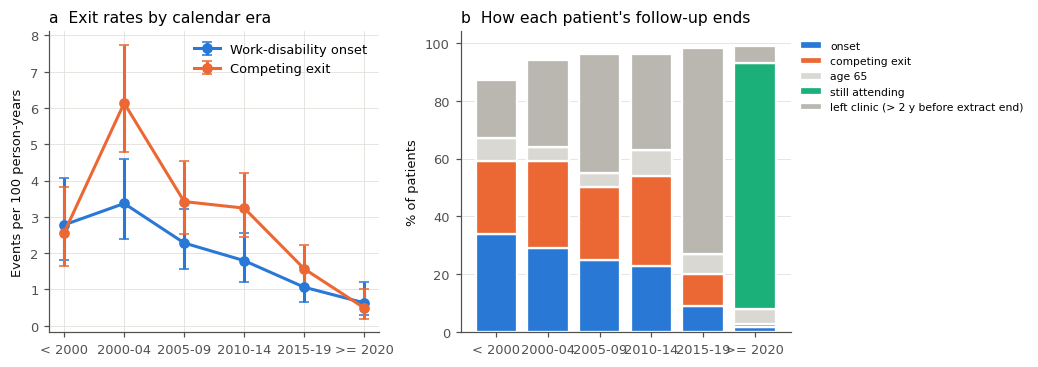

**What this means.**

* **Both kinds of exit from work fell, and other exits fell faster.** Work-disability onsets went from
  3.4 to 0.6 per 100 person-years between 2000-04 and the latest era; other exits went
  from 6.1 to 0.5. Better treatment could lower work disability. It is harder to see
  why it would lower retirement, homemaking and job loss by even more.
* **Follow-up increasingly ends with the patient simply no longer seen.** In 2015-19, 71 %
  of follow-ups ended with a patient last recorded as employed who stopped attending. Anyone among them who left
  work is missing from the outcome.

Together these point to **ascertainment**: exits from work that happen but never reach the record. Part of the fall
is real, because patients' disease profiles changed (Section 4.1 measures how much). Part V tests how much of the
rest missing onsets could explain.

In [8]:
"""Follow-up endings and exit rates by era (person-time split across eras)."""
_last = land.groupby("pid").tail(1).copy()
_left = (_last["cause"] == 0) & (_last["exit_type"] == "end_of_follow_up") & ~_last["dead"] & \
        ((DATA_END_DATE - _last["last_status_date"]).dt.days / 365.25 > LEFT_CLINIC_YEARS)
_last["Ending"] = np.select([_last["cause"] == 1, _last["cause"] == 2, _last["exit_type"] == "age_cap",
                             _last["exit_type"] == "unresolved_sick_leave", _last["dead"], _left],
                            ["onset", "competing exit", "age 65", "open short sick leave", "died (censored)",
                             f"left clinic (> {LEFT_CLINIC_YEARS:g} y before extract end)"], "still attending")
_end_date = _last["visit_date"] + pd.to_timedelta(_last["time_days"], unit="D")
_last["Era of the ending"] = pd.cut(_end_date.dt.year, [e[0] for e in ERAS] + [ERAS[-1][1]], right=False,
                                    labels=[e[2] for e in ERAS])
ENDINGS = pd.crosstab(_last["Era of the ending"], _last["Ending"], normalize="index").mul(100).round(0)
ENDINGS["Patients"] = _last.groupby("Era of the ending", observed=True).size()
display(ENDINGS)
LEFT_CLINIC_PIDS = set(_last.loc[_left, "pid"])

_edges = [(pd.Timestamp(f"{a}-01-01") - pd.Timestamp("1970-01-01")).days for a, _, _ in ERAS] + [1e9]


def rates_by_era(d1, d2):
    """Person-time of the at-risk intervals split by calendar era; events counted at the interval end."""
    py, e1, e2 = [], [], []
    for k in range(len(ERAS)):
        lo, hi = _edges[k], _edges[k + 1]
        py.append(np.clip(np.minimum(INT_END, hi) - np.maximum(LAND_T, lo), 0, None).sum() / 365.25)
        inn = (INT_END > lo) & (INT_END <= hi)
        e1.append(d1[inn].sum()); e2.append(d2[inn].sum())
    return map(np.array, (py, e1, e2))


_py, _d1, _d2 = rates_by_era(D1, D2)


def pois_ci(d, py):
    lo = np.where(d > 0, stats.chi2.ppf(0.025, 2 * d) / 2, 0.0) / py
    return lo, stats.chi2.ppf(0.975, 2 * d + 2) / 2 / py


RATES = pd.DataFrame({"Era": [e[2] for e in ERAS], "Person-years": _py.round(0), "Onsets": _d1.astype(int),
                      "Onset rate /100 py": (100 * _d1 / _py).round(2),
                      "95% CI": [f"{100 * a:.2f}-{100 * b:.2f}" for a, b in zip(*pois_ci(_d1, _py))],
                      "Competing exits": _d2.astype(int), "Competing rate /100 py": (100 * _d2 / _py).round(2)}
                     ).set_index("Era")
display(RATES)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
ax = axes[0]
x = np.arange(len(ERAS))
for d, col, lab in [(_d1, C1, "Work-disability onset"), (_d2, C2, "Competing exit")]:
    r = 100 * d / _py
    lo, hi = pois_ci(d, _py)
    ax.errorbar(x, r, yerr=[r - 100 * lo, 100 * hi - r], fmt="o-", color=col, ms=6, capsize=3, label=lab)
ax.set_xticks(x, [e[2] for e in ERAS]); ax.set_ylabel("Events per 100 person-years")
ax.set_title("a  Exit rates by calendar era", loc="left"); ax.legend()
ax = axes[1]
_E = ENDINGS.drop(columns="Patients")
_order = [c for c in ["onset", "competing exit", "age 65", "still attending",
                      f"left clinic (> {LEFT_CLINIC_YEARS:g} y before extract end)"] if c in _E]
_cols = {"onset": C1, "competing exit": C2, "still attending": C3}
bottom = np.zeros(len(_E))
for c in _order:
    ax.bar(np.arange(len(_E)), _E[c].values, bottom=bottom, color=_cols.get(c, "#b9b7b0" if "left" in c else "#dad8d2"),
           edgecolor="white", linewidth=1.5, label=c)
    bottom += _E[c].values
ax.set_xticks(np.arange(len(_E)), _E.index.astype(str)); ax.set_ylabel("% of patients")
ax.set_title("b  How each patient's follow-up ends", loc="left")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0)); ax.grid(axis="x", visible=False)
plt.tight_layout(); save_fig("fig01_outcome_process")
_lc = [c for c in ENDINGS if c.startswith("left")][0]
_r = RATES["Onset rate /100 py"]; _rc = RATES["Competing rate /100 py"]
say(f"""
**What this means.**

* **Both kinds of exit from work fell, and other exits fell faster.** Work-disability onsets went from
  {_r.iloc[1]:.1f} to {_r.iloc[-1]:.1f} per 100 person-years between 2000-04 and the latest era; other exits went
  from {_rc.iloc[1]:.1f} to {_rc.iloc[-1]:.1f}. Better treatment could lower work disability. It is harder to see
  why it would lower retirement, homemaking and job loss by even more.
* **Follow-up increasingly ends with the patient simply no longer seen.** In 2015-19, {ENDINGS.loc["2015-19", _lc]:.0f} %
  of follow-ups ended with a patient last recorded as employed who stopped attending. Anyone among them who left
  work is missing from the outcome.

Together these point to **ascertainment**: exits from work that happen but never reach the record. Part of the fall
is real, because patients' disease profiles changed (Section 4.1 measures how much). Part V tests how much of the
rest missing onsets could explain.
""")

### 1.5.5 Is the fall explained by how often patients are seen?

Statuses are snapshots taken at visits. If visits became less frequent, fewer exits would be caught between them.
A **multistate Markov model** (R package `msm`) treats each status as a snapshot of a continuous process and
estimates transition rates that do not depend on visit timing. The states are working, not working for health
reasons (sick leave or disabled) and other exit, with calendar era as a covariate on the two exits from work.

> **How to read it.** A hazard ratio well below 1 for recent eras means the drop is *not* an artefact of visit
> spacing. It can still come from exits never being recorded, or from patients leaving the clinic (Part V).

In [9]:
"""Multistate Markov model of the status record (R package msm), era on the exits from work."""
MSM_R = r'''
args <- commandArgs(trailingOnly = TRUE)
suppressMessages(library(msm))
d <- read.csv(args[1])
d <- d[order(d$pid, d$years), ]
d$era <- relevel(factor(d$era), ref = "2000-04")
Q <- rbind(c(0, 0.02, 0.03), c(0.3, 0, 0.02), c(0.3, 0.02, 0))
fit <- msm(state ~ years, subject = pid, data = d, qmatrix = Q, gen.inits = TRUE,
           covariates = list("1-2" = ~ era, "1-3" = ~ era), control = list(fnscale = 4000, maxit = 2000))
hr <- hazard.msm(fit)
out <- do.call(rbind, lapply(names(hr), function(n) {
  h <- hr[[n]]; data.frame(term = n, transition = rownames(h), HR = h[, 1], L = h[, 2], U = h[, 3]) }))
write.csv(out, args[2], row.names = FALSE)
cat("converged:", fit$opt$convergence == 0, "\n")
'''


def run_msm():
    sv = visits.loc[visits["HAS_STATUS"], ["PTNO", "ASSDT", "EMP", "age_at_record"]].copy()
    sv["state"] = sv["EMP"].map(lambda e: 1 if e in WORKING_STATES else 2 if e in SICK_STATES | DISABLED_STATES
                                else 3 if e in OTHER_EXIT_STATES else np.nan)
    sv = sv.dropna(subset=["state"])
    start = sv[(sv["state"] == 1) & (sv["age_at_record"] < AGE_CAP_YEARS)].groupby("PTNO")["ASSDT"].min()
    sv = sv[sv["PTNO"].isin(start.index)]
    sv = sv[(sv["ASSDT"] >= sv["PTNO"].map(start)) & (sv["age_at_record"] < AGE_CAP_YEARS)]
    if SMOKE:
        keep = np.random.RandomState(SEED).choice(sv["PTNO"].unique(), 300, replace=False)
        sv = sv[sv["PTNO"].isin(keep)]
    sv = sv[sv.groupby("PTNO")["PTNO"].transform("size") >= 2]
    sv["years"] = (sv["ASSDT"] - sv["PTNO"].map(start)).dt.days / 365.25
    sv["era"] = pd.cut(sv["ASSDT"].dt.year, [e[0] for e in ERAS] + [ERAS[-1][1]], right=False,
                       labels=[e[2] for e in ERAS]).astype(str)
    fin, fout, fr = [os.path.abspath(os.path.join(OUT_DIR, f)) for f in ("msm_in.csv", "msm_out.csv", "msm.R")]
    sv = sv.rename(columns={"PTNO": "pid"})
    sv[["pid", "years", "state", "era"]].to_csv(fin, index=False)
    open(fr, "w").write(MSM_R)
    if not shutil.which("Rscript"):
        print("Rscript not found: the multistate check is skipped.")
        return None
    t0 = time.time()
    res = subprocess.run(["Rscript", fr, fin, fout], capture_output=True, text=True, timeout=3600)
    if res.returncode != 0 or not os.path.exists(fout):
        print("msm failed:\n" + res.stderr[-1500:])
        return None
    out = pd.read_csv(fout)
    out["transition"] = out["transition"].str.replace("State 1 - State 2", "working -> not working (health)") \
        .str.replace("State 1 - State 3", "working -> other exit")
    print(f"msm on {sv['pid'].nunique():,} patients, {len(sv):,} statuses ({(time.time() - t0) / 60:.1f} min); "
          + res.stdout.strip())
    return out


if "msm" not in STATE:
    STATE["msm"] = run_msm()
    _save_state()
MSM = STATE["msm"]
if MSM is not None:
    _m = MSM.assign(Era=MSM["term"].str.replace("era", ""), **{"HR (95% CI)": MSM.apply(
        lambda r: f"{r.HR:.2f} ({r.L:.2f}-{r.U:.2f})", axis=1)})
    _m = _m[_m["transition"].str.contains("->") & _m["term"].str.startswith("era")]
    display(_m.pivot(index="Era", columns="transition", values="HR (95% CI)")
            .reindex([e[2] for e in ERAS if e[2] != "2000-04"]))
    print("Reference era: 2000-04.")
    _r = RATES["Onset rate /100 py"]
    _hr = [r for r in MSM.itertuples() if r.term == "era2015-19" and "not working" in r.transition]
    _hr2 = [r for r in MSM.itertuples() if r.term == "era2015-19" and "other exit" in r.transition]
    say(f"""
**What this means.** After accounting for when visits happened, the rate of leaving work for health reasons in
2015-19 was {_hr[0].HR:.2f} times the 2000-04 rate (95 % CI {_hr[0].L:.2f}-{_hr[0].U:.2f}). The rate of other exits
fell about as much ({_hr2[0].HR:.2f}). Visit spacing does not explain the fall. Whatever lowered work disability
lowered every kind of exit from work in parallel, which fits a recording effect better than a treatment effect.
""")

msm on 1,058 patients, 23,882 statuses (0.3 min); converged: TRUE


transition,working -> not working (health),working -> other exit
Era,,
< 2000,0.96 (0.63-1.48),0.60 (0.40-0.90)
2005-09,0.70 (0.46-1.07),0.47 (0.32-0.70)
2010-14,0.46 (0.30-0.72),0.51 (0.36-0.73)
2015-19,0.25 (0.15-0.41),0.21 (0.14-0.33)
>= 2020,0.16 (0.07-0.35),0.05 (0.02-0.15)


Reference era: 2000-04.


**What this means.** After accounting for when visits happened, the rate of leaving work for health reasons in
2015-19 was 0.25 times the 2000-04 rate (95 % CI 0.15-0.41). The rate of other exits
fell about as much (0.21). Visit spacing does not explain the fall. Whatever lowered work disability
lowered every kind of exit from work in parallel, which fits a recording effect better than a treatment effect.

## 1.6 The cohort at a glance

> **In plain words.** Before any model, four pictures of the data: when patients joined the working cohort and how
> their follow-up ended; every patient's employment record on one page; what the record looks like for two
> individual patients; and how the disease looked in the years before a work-disability onset.

### 1.6.1 When patients entered, and how their follow-up ended

A patient **enters** at their first visit recorded as employed before age 65 (their first landmark). Each bar is
one calendar year of entry, split by how that patient's follow-up ended. Patients with any work-disability onset
are counted as such, even if they later returned to work.

,1983-93,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
Ending,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Work disability,9.0,5.0,31.0,7.0,8.0,2.0,7.0,3.0,8.0,15.0,1.0,6.0,3.0,5.0,3.0,3.0,2.0,3.0,4.0,3.0,4.0,2.0,5.0,3.0,2.0,3.0,1.0,1.0,0.0,0.0,1.0
Other exit from work,6.0,12.0,29.0,8.0,8.0,3.0,2.0,4.0,5.0,4.0,4.0,3.0,2.0,3.0,4.0,6.0,4.0,6.0,2.0,2.0,4.0,4.0,2.0,3.0,2.0,0.0,0.0,0.0,0.0,1.0,0.0
Still working and attending,1.0,1.0,11.0,3.0,5.0,4.0,3.0,7.0,5.0,8.0,9.0,5.0,10.0,7.0,6.0,7.0,13.0,7.0,15.0,9.0,23.0,18.0,13.0,28.0,26.0,39.0,31.0,11.0,29.0,31.0,17.0
Left the clinic while working,3.0,2.0,25.0,6.0,4.0,6.0,4.0,12.0,18.0,15.0,11.0,13.0,11.0,11.0,12.0,15.0,15.0,19.0,12.0,8.0,8.0,11.0,9.0,11.0,6.0,10.0,6.0,3.0,0.0,0.0,0.0
"Reached 65, died or other censoring",5.0,5.0,26.0,4.0,6.0,4.0,3.0,2.0,3.0,4.0,0.0,0.0,3.0,1.0,5.0,2.0,2.0,4.0,0.0,1.0,0.0,0.0,2.0,2.0,1.0,0.0,2.0,1.0,0.0,0.0,0.0
Patients,24.0,25.0,122.0,28.0,31.0,19.0,19.0,28.0,39.0,46.0,25.0,27.0,29.0,27.0,30.0,33.0,36.0,39.0,33.0,23.0,39.0,35.0,31.0,47.0,37.0,52.0,40.0,16.0,29.0,32.0,18.0
Median follow-up (years),25.3,25.3,23.8,19.5,17.5,24.9,20.6,11.9,17.2,14.9,15.9,14.0,17.8,13.3,13.5,10.7,10.4,8.5,11.9,11.1,9.9,8.9,7.9,7.2,6.1,5.0,4.1,3.3,2.1,1.3,0.5


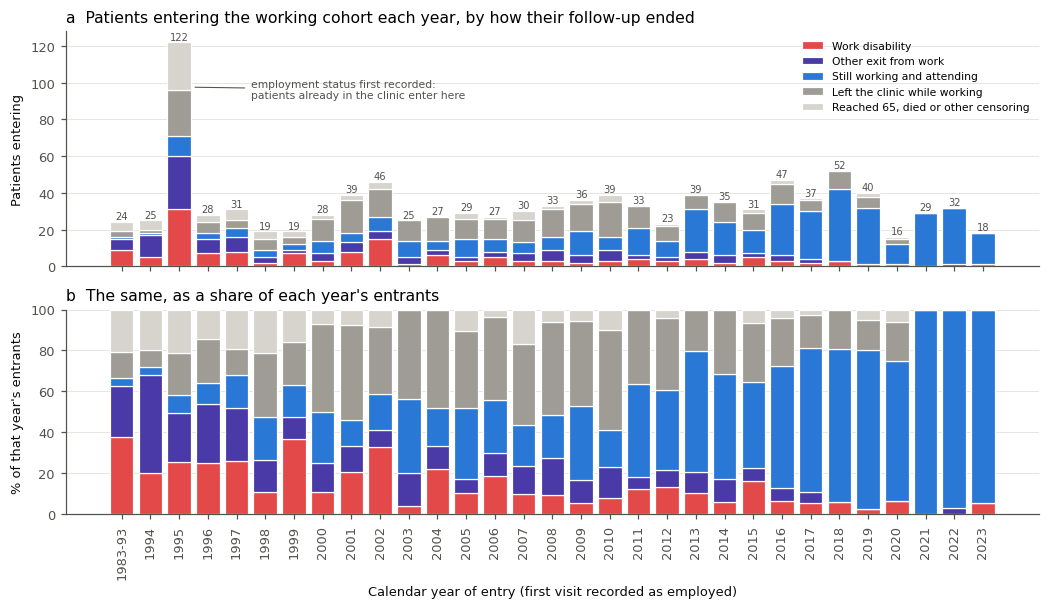

**What this means.** 1,059 patients entered the working cohort, 150 of whom later
left work for health reasons. The tall bar in 1995 is the year the clinic began recording employment status: everyone
already attending and working entered then. Patients who entered before 2005 had long follow-up (median
19 years), and 24 % of them had a
work-disability onset. Among those entering from 2015, only 5 % have had one so
far, partly because they have been followed for less time (median 4.3 years) and partly
because 15 % had already stopped attending while still working.
Recent entrants have had less time to show an outcome, and more of them leave without one recorded.

In [10]:
"""Cohort inception: year of entry and final state of every patient."""
STATE_COLORS = {"W": C1, "S": "#eda100", "D": "#e34948", "O": C4, "U": "#d6d4cd"}
STATE_NAMES = {"W": "Employed", "S": "Sick leave", "D": "Disabled", "O": "Other exit", "U": "Not recorded"}
FINAL_ORDER = ["Work disability", "Other exit from work", "Still working and attending",
               "Left the clinic while working", "Reached 65, died or other censoring"]
FINAL_COLORS = dict(zip(FINAL_ORDER, ["#e34948", C4, C1, "#9e9c95", "#d6d4cd"]))
_first_lm = land.groupby("pid").head(1).set_index("pid")
ENTRY_DATE = _first_lm["visit_date"]
_end_map = {"onset": "Work disability", "competing exit": "Other exit from work",
            "still attending": "Still working and attending",
            f"left clinic (> {LEFT_CLINIC_YEARS:g} y before extract end)": "Left the clinic while working"}
FINAL_STATE = _last.set_index("pid")["Ending"].map(_end_map).fillna(FINAL_ORDER[-1])
FINAL_STATE[pd.Series(PID_EVENT.astype(bool), index=ALL_PIDS)] = "Work disability"
FINAL_STATE = FINAL_STATE.reindex(ALL_PIDS)
_last_seen = land.groupby("pid")["last_status_date"].max()
FU_YEARS = ((_last_seen - ENTRY_DATE).dt.days / 365.25).reindex(ALL_PIDS)

_ey = ENTRY_DATE.dt.year.reindex(ALL_PIDS)
_first_bar = 1994
_eyb = _ey.clip(lower=_first_bar - 1)
INCEPTION = pd.crosstab(_eyb, FINAL_STATE).reindex(columns=FINAL_ORDER, fill_value=0)
INCEPTION.index = [f"{int(_ey.min())}-{str(_first_bar - 1)[2:]}" if y < _first_bar else str(y) for y in INCEPTION.index]
_inc_tab = INCEPTION.copy()
_inc_tab["Patients"] = INCEPTION.sum(1)
_inc_tab["Median follow-up (years)"] = FU_YEARS.groupby(_eyb.values).median().round(1).values
display(_inc_tab.T)

fig, axes = plt.subplots(2, 1, figsize=(9.6, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.15, 1]})
x = np.arange(len(INCEPTION))
_pct = INCEPTION.div(INCEPTION.sum(1), axis=0) * 100
for ax, tab in zip(axes, [INCEPTION, _pct]):
    bottom = np.zeros(len(tab))
    for c in FINAL_ORDER:
        ax.bar(x, tab[c].values, 0.82, bottom=bottom, color=FINAL_COLORS[c], edgecolor="white", linewidth=0.8,
               label=c)
        bottom += tab[c].values
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Patients entering")
axes[0].set_title("a  Patients entering the working cohort each year, by how their follow-up ended", loc="left")
for xi, n in zip(x, INCEPTION.sum(1).values):
    axes[0].text(xi, n + 1.5, f"{n}", ha="center", fontsize=6.5, color=INK_2)
_i95 = list(INCEPTION.index).index("1995") if "1995" in INCEPTION.index else None
if _i95 is not None:
    axes[0].annotate("employment status first recorded:\npatients already in the clinic enter here",
                     xy=(_i95 + 0.45, INCEPTION.iloc[_i95].sum() * 0.8), xytext=(_i95 + 2.5, INCEPTION.iloc[_i95].sum() * 0.75),
                     fontsize=7, color=INK_2, arrowprops=dict(arrowstyle="-", color=INK_2, lw=0.7))
axes[0].legend(loc="upper right", fontsize=7, ncol=1)
axes[1].set_ylabel("% of that year's entrants"); axes[1].set_ylim(0, 100)
axes[1].set_title("b  The same, as a share of each year's entrants", loc="left")
axes[1].set_xticks(x, INCEPTION.index, rotation=90)
axes[1].set_xlabel("Calendar year of entry (first visit recorded as employed)")
plt.tight_layout(); save_fig("explore01_cohort_inception")

_early = FINAL_STATE[_ey < 2005].value_counts(normalize=True)
_late = FINAL_STATE[_ey >= 2015].value_counts(normalize=True)
say(f"""
**What this means.** {len(ALL_PIDS):,} patients entered the working cohort, {int(PID_EVENT.sum())} of whom later
left work for health reasons. The tall bar in 1995 is the year the clinic began recording employment status: everyone
already attending and working entered then. Patients who entered before 2005 had long follow-up (median
{FU_YEARS[_ey < 2005].median():.0f} years), and {100 * _early.get("Work disability", 0):.0f} % of them had a
work-disability onset. Among those entering from 2015, only {100 * _late.get("Work disability", 0):.0f} % have had one so
far, partly because they have been followed for less time (median {FU_YEARS[_ey >= 2015].median():.1f} years) and partly
because {100 * _late.get("Left the clinic while working", 0):.0f} % had already stopped attending while still working.
Recent entrants have had less time to show an outcome, and more of them leave without one recorded.
""")

### 1.6.2 Every patient's employment record

One row per patient, ordered by date of entry. Each row runs from entry to the patient's last recorded status,
coloured by the status recorded at each visit (held until the next status). The picture shows the shape of the
data at once: the 1995 inception block, long records in early entrants, and how often a period of sick leave or
disability is followed by a return to work.

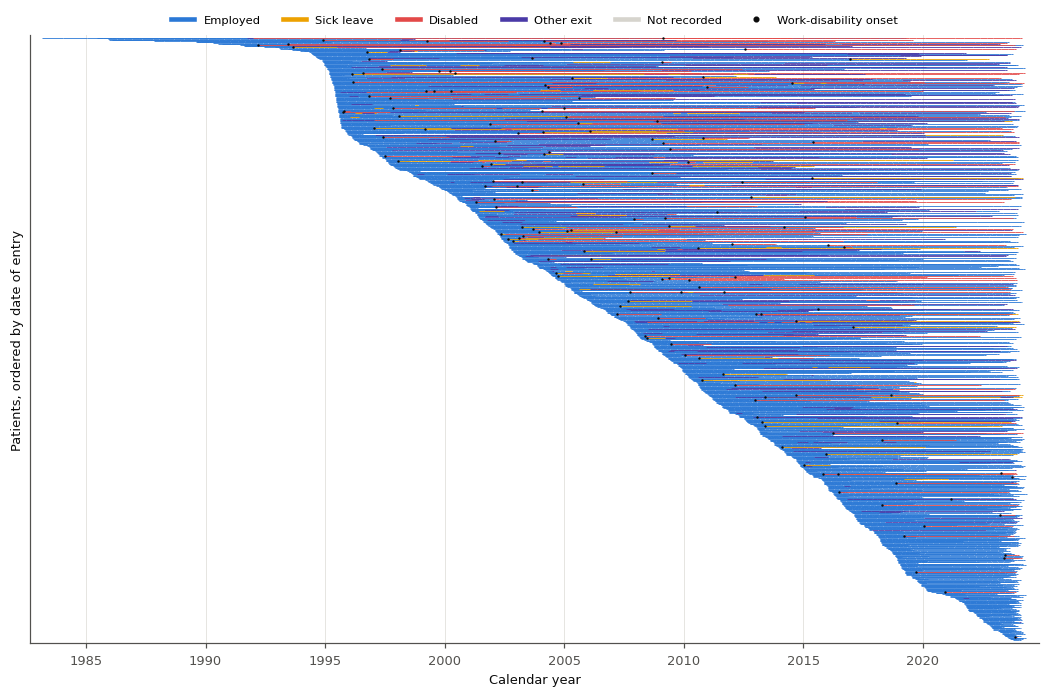

**What this means.** Most of the page is blue: working is the usual state, and work disability is a minority
outcome. 52 patients (5%) were recorded back at work after a period of sick
leave or disability, so leaving work is not always permanent. That is why the analysis lets a patient re-enter the
risk set when they return to work.

In [11]:
"""Every patient's employment record (calendar time)."""
from matplotlib.collections import LineCollection

_sv = visits.loc[visits["HAS_STATUS"] & visits["PTNO"].isin(ALL_PIDS), ["PTNO", "ASSDT", "EMP"]].copy()
_sv = _sv[_sv["ASSDT"] >= _sv["PTNO"].map(ENTRY_DATE)]
_sv["st"] = _sv["EMP"].map(_state_of)
_sv["end"] = _sv.groupby("PTNO")["ASSDT"].shift(-1)
_sv["end"] = _sv["end"].fillna(_sv["ASSDT"] + pd.Timedelta(days=30))     # last status: a short stub
_order = ENTRY_DATE.sort_values().index
_row = pd.Series(np.arange(len(_order)), index=_order)
_y = _sv["PTNO"].map(_row).values
_x0, _x1 = _sv["ASSDT"].dt.year + _sv["ASSDT"].dt.dayofyear / 365.25, _sv["end"].dt.year + _sv["end"].dt.dayofyear / 365.25
fig, ax = plt.subplots(figsize=(9.6, 6.4))
for st, col in STATE_COLORS.items():
    k = (_sv["st"] == st).values
    if k.any():
        seg = np.stack([np.column_stack([_x0.values[k], _y[k]]), np.column_stack([_x1.values[k], _y[k]])], 1)
        ax.add_collection(LineCollection(seg, colors=col, linewidths=0.55, label=STATE_NAMES[st]))
_ons = land[(C_ALL == 1)].drop_duplicates(["pid", "event_date"])
ax.scatter(_ons["event_date"].dt.year + _ons["event_date"].dt.dayofyear / 365.25, _ons["pid"].map(_row), s=2.5,
           color=INK, zorder=3, linewidths=0, label="Work-disability onset")
ax.set_xlim(_x0.min() - 0.5, _x1.max() + 0.5); ax.set_ylim(len(_order) + 5, -5)
ax.set_xlabel("Calendar year"); ax.set_ylabel("Patients, ordered by date of entry")
ax.set_yticks([]); ax.grid(axis="y", visible=False)
_h = [plt.Line2D([], [], color=STATE_COLORS[s], lw=3) for s in "WSDOU"] + \
     [plt.Line2D([], [], color=INK, marker="o", ls="", ms=3)]
ax.legend(_h, [STATE_NAMES[s] for s in "WSDOU"] + ["Work-disability onset"], ncol=6, loc="lower center",
          bbox_to_anchor=(0.5, 1.0), fontsize=7.5)
plt.tight_layout(); save_fig("explore02_every_patient")
_share_back = (_sv.assign(prev=_sv.groupby("PTNO")["st"].shift())
               .query("prev in ['S', 'D'] and st == 'W'")["PTNO"].nunique())
say(f"""
**What this means.** Most of the page is blue: working is the usual state, and work disability is a minority
outcome. {_share_back} patients ({_share_back / len(ALL_PIDS):.0%}) were recorded back at work after a period of sick
leave or disability, so leaving work is not always permanent. That is why the analysis lets a patient re-enter the
risk set when they return to work.
""")

### 1.6.3 Two patients: visits, landmarks and the clinical record

Two patients followed from entry: one who left work for health reasons and one who kept working. For each, the
top panel shows **every clinic visit** coloured by the employment status recorded there (the spacing shows how often
the patient was seen) and, underneath, the **landmarks**: the working visits at which a risk is computed. The two
lower panels show two of the model's inputs over time, disease activity (12-month adjusted mean SLEDAI-2K) and the prednisone dose. Time
is shown as years since entry, not calendar dates.

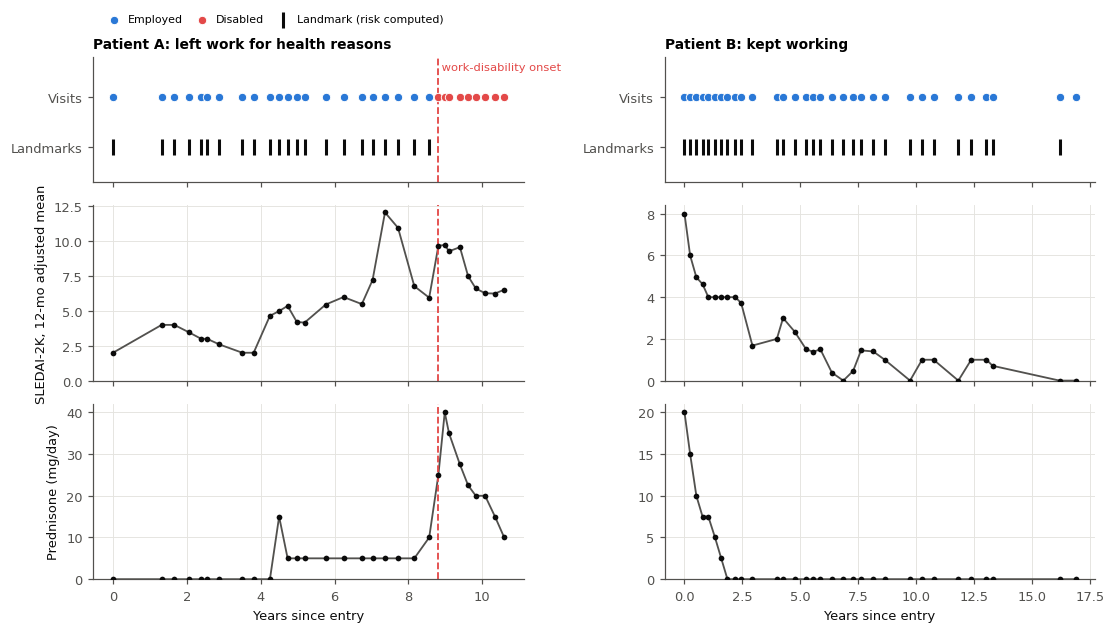

Patient A: left work for health reasons: 22 landmarks; visits every 4.0 months (median)
Patient B: kept working: 31 landmarks; visits every 5.8 months (median)


**What this means.** Patients are seen every few months, and each working visit is a fresh opportunity to compute a
risk. Disease activity and treatment vary from visit to visit in both patients. A single visit's value says little;
the model combines 20 such items at every visit.

In [12]:
"""Two example patients: visits, landmarks, disease activity and prednisone."""
FIRST_ONSET_DATE = land.loc[C_ALL == 1].groupby("pid")["event_date"].min()
_nvis = visits.groupby("PTNO").size()
CAND_ONSET = [p for p in FIRST_ONSET_DATE.index
            if (FIRST_ONSET_DATE[p] - ENTRY_DATE[p]).days > 4 * 365 and len(PT_ROWS[p]) >= 8
            and visits.loc[visits["PTNO"] == p, "STERAVER_0"].max() > 0]
CAND_WORKING = [p for p in ALL_PIDS if not PID_EVENT[PID_INDEX[p]] and FINAL_STATE[p] == "Still working and attending"
           and FU_YEARS[p] >= 8 and len(PT_ROWS[p]) >= 10]
EXAMPLE_PIDS = [sorted(CAND_ONSET, key=lambda p: len(PT_ROWS[p]))[len(CAND_ONSET) // 2],
                sorted(CAND_WORKING, key=lambda p: len(PT_ROWS[p]))[len(CAND_WORKING) // 2]]
EXAMPLE_TITLES = ["Patient A: left work for health reasons", "Patient B: kept working"]


def _yrs(d, pid):
    return (pd.to_datetime(np.asarray(d)) - ENTRY_DATE[pid]).days.values / 365.25 if np.ndim(d) else \
        (pd.Timestamp(d) - ENTRY_DATE[pid]).days / 365.25


fig, axes = plt.subplots(3, 2, figsize=(10.2, 5.8), sharex="col", gridspec_kw={"height_ratios": [1.0, 1.4, 1.4]})
for j, pid in enumerate(EXAMPLE_PIDS):
    pv = visits[(visits["PTNO"] == pid)]
    end = FIRST_ONSET_DATE[pid] + pd.DateOffset(years=2) if pid in FIRST_ONSET_DATE.index else _last_seen[pid]
    pv = pv[(pv["ASSDT"] >= ENTRY_DATE[pid] - pd.DateOffset(years=1)) & (pv["ASSDT"] <= end)]
    xv = _yrs(pv["ASSDT"].values, pid)
    ax = axes[0, j]
    for st, col in STATE_COLORS.items():
        k = np.array([_state_of(e) == st for e in pv["EMP"].values])
        if k.any():
            ax.scatter(xv[k], np.full(k.sum(), 1.0), s=30, color=col, edgecolor="white", linewidth=0.6, zorder=3,
                       label=STATE_NAMES[st])
    li = PT_ROWS[pid]
    li = li[land["visit_date"].values[li] <= np.datetime64(end)]
    ax.scatter(_yrs(land["visit_date"].values[li], pid), np.zeros(len(li)), marker="|", s=110, color=INK, zorder=3,
               label="Landmark (risk computed)")
    ax.set_yticks([0, 1], ["Landmarks", "Visits"]); ax.set_ylim(-0.7, 1.8); ax.grid(False)
    ax.set_title(EXAMPLE_TITLES[j], loc="left", fontsize=9, fontweight="bold")
    for col_, lab_, row in [("AMS_12M", "SLEDAI-2K, 12-mo adjusted mean", 1), ("STERAVER_0", "Prednisone (mg/day)", 2)]:
        a = axes[row, j]
        yv = pv[col_].values.astype(float)
        a.plot(xv, yv, "-", color=INK_2, lw=1.2, zorder=2)
        a.scatter(xv, yv, s=14, color=INK, zorder=3, linewidths=0)
        a.set_ylim(bottom=0)
        if j == 0:
            a.set_ylabel(lab_)
    if pid in FIRST_ONSET_DATE.index:
        xo = _yrs(FIRST_ONSET_DATE[pid], pid)
        for a in axes[:, j]:
            a.axvline(xo, color="#e34948", lw=1.2, ls="--")
        axes[0, j].text(xo, 1.6, " work-disability onset", color="#e34948", fontsize=7.5, va="center")
    axes[2, j].set_xlabel("Years since entry")
axes[0, 0].legend(ncol=6, loc="lower left", bbox_to_anchor=(0.0, 1.18), fontsize=7.2, handletextpad=0.2,
                  columnspacing=0.8)
plt.tight_layout(); save_fig("explore03_two_patients")
for j, pid in enumerate(EXAMPLE_PIDS):
    pv = visits[(visits["PTNO"] == pid) & (visits["ASSDT"] >= ENTRY_DATE[pid])]
    gap = pv["ASSDT"].diff().dt.days.dropna() / MONTH_DAYS
    print(f"{EXAMPLE_TITLES[j]}: {len(PT_ROWS[pid])} landmarks; visits every {gap.median():.1f} months (median)")
say("""
**What this means.** Patients are seen every few months, and each working visit is a fresh opportunity to compute a
risk. Disease activity and treatment vary from visit to visit in both patients. A single visit's value says little;
the model combines 20 such items at every visit.
""")

### 1.6.4 The clinical picture in the years before an onset

For the patients who left work for health reasons, each input is averaged over the working visits in 6-month
bins before their first onset. Patients who never left work are aligned at their last working visit for comparison.
A curve that **rises** towards the onset would be an early-warning signal; two curves that run **parallel** mean
the difference is a stable trait of the patient.

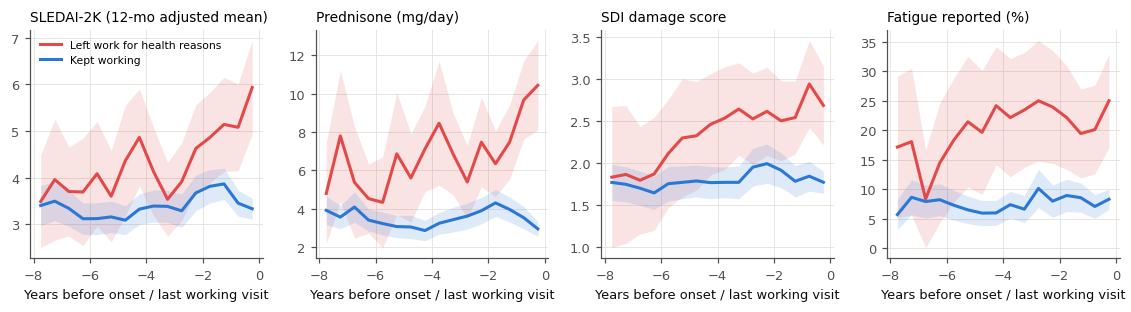

,"Onset patients, 4-6 y before","Onset patients, final year","Kept working, 4-6 y before","Kept working, final year"
SLEDAI-2K (12-mo adjusted mean),4.2,5.5,3.2,3.4
Prednisone (mg/day),6.0,10.1,3.1,3.2
SDI damage score,2.3,2.8,1.8,1.8
Fatigue reported (%),20.9,22.5,6.4,7.7


**What this means.**

* **A difference already present years earlier.** Four to six years before the onset, patients who would later
  leave work already had higher values than patients who kept working on
  4 of the 4 items (for example SLEDAI-2K 4.2 vs 3.2;
  fatigue reported at 21 % vs 6 % of visits).
* **A further rise close to the onset.** The gap widened in the final year for SLEDAI-2K (12-mo adjusted mean), Prednisone (mg/day), SDI damage score: prednisone went from 6.0 to 10.1
  mg/day in onset patients, against 3.1 and 3.2 in patients who kept working.

So the warning signs are partly a persistent trait and partly a change in the last year or two. The bands are wide
far from the onset because fewer patients were followed that long before it. Section 6.6 shows how the risk score
behaves over the same years.

In [13]:
"""Onset-aligned mean of key inputs (onset patients vs never-onset patients)."""
TRAJ_MAX_MONTHS = 96
_anc = {p: FIRST_ONSET_DATE[p] for p in FIRST_ONSET_DATE.index}
_anc.update({p: land["visit_date"].values[PT_ROWS[p]].max() + np.timedelta64(1, "D") for p in ALL_PIDS
             if p not in _anc})
_anc_arr = pd.to_datetime(pd.Series(PID_ALL).map(_anc)).values
MO_BEFORE = (_anc_arr - land["visit_date"].values) / np.timedelta64(1, "D") / MONTH_DAYS   # months before anchor
_ever = PID_EVENT[ROW_PIDX].astype(bool)
_ok = (MO_BEFORE > 0) & (MO_BEFORE <= TRAJ_MAX_MONTHS)
_bins = np.arange(0, TRAJ_MAX_MONTHS + 1, 6)
_bin = np.digitize(MO_BEFORE, _bins)


def aligned_mean(v):
    """Per group and 6-month bin: mean over patients (each patient's mean within the bin), 95 % CI."""
    d = pd.DataFrame({"pid": PID_ALL, "ev": _ever, "bin": _bin, "v": v})[_ok]
    g = d.groupby(["ev", "bin", "pid"])["v"].mean().groupby(["ev", "bin"]).agg(["mean", "sem", "size"])
    return g


_TRAJ_VARS = [("AMS_12M", "SLEDAI-2K (12-mo adjusted mean)", 1), ("STERAVER_0", "Prednisone (mg/day)", 1),
              ("score_n", "SDI damage score", 1), ("FATIGUE", "Fatigue reported (%)", 100)]
fig, axes = plt.subplots(1, 4, figsize=(10.4, 2.9))
for ax, (c, lab, sc) in zip(axes, _TRAJ_VARS):
    g = aligned_mean(LAND_X[c].values.astype(float) * sc)
    for ev, col, nm in [(True, "#e34948", "Left work for health reasons"), (False, C1, "Kept working")]:
        if ev not in g.index.get_level_values(0):
            continue
        s = g.loc[ev]
        s = s[s["size"] >= 10]
        xs = -(_bins[s.index.values - 1] + 3) / 12
        ax.fill_between(xs, s["mean"] - 1.96 * s["sem"], s["mean"] + 1.96 * s["sem"], color=col, alpha=0.15, lw=0)
        ax.plot(xs, s["mean"], "-", color=col, lw=2, label=nm)
    ax.set_title(lab, loc="left", fontsize=9)
    ax.set_xlabel("Years before onset / last working visit")
axes[0].legend(fontsize=7, loc="upper left")
plt.tight_layout(); save_fig("explore04_before_onset")
_g = {c: aligned_mean(LAND_X[c].values.astype(float) * sc) for c, _, sc in _TRAJ_VARS}


def _near_far(c, ev):
    """Mean of the patient means 0-12 months and 48-72 months before the anchor."""
    s = _g[c].loc[ev]
    return s.loc[s.index <= 2, "mean"].mean(), s.loc[(s.index >= 9) & (s.index <= 12), "mean"].mean()


BEFORE_ONSET = pd.DataFrame({lab: {"Onset patients, 4-6 y before": _near_far(c, True)[1],
                                   "Onset patients, final year": _near_far(c, True)[0],
                                   "Kept working, 4-6 y before": _near_far(c, False)[1],
                                   "Kept working, final year": _near_far(c, False)[0]}
                             for c, lab, _ in _TRAJ_VARS}).T.round(1)
display(BEFORE_ONSET)
_gap_far = (BEFORE_ONSET.iloc[:, 0] - BEFORE_ONSET.iloc[:, 2])
_gap_near = (BEFORE_ONSET.iloc[:, 1] - BEFORE_ONSET.iloc[:, 3])
_widen = [i for i in BEFORE_ONSET.index if _gap_near[i] > 1.3 * _gap_far[i] and _gap_far[i] > 0]
_b = BEFORE_ONSET
say(f"""
**What this means.**

* **A difference already present years earlier.** Four to six years before the onset, patients who would later
  leave work already had higher values than patients who kept working on
  {sum(_gap_far > 0)} of the {len(_gap_far)} items (for example SLEDAI-2K {_b.iloc[0, 0]:.1f} vs {_b.iloc[0, 2]:.1f};
  fatigue reported at {_b.iloc[3, 0]:.0f} % vs {_b.iloc[3, 2]:.0f} % of visits).
* **A further rise close to the onset.** {"The gap widened in the final year for " + ", ".join(_widen) + "" if _widen
  else "The gap did not widen much in the final year"}: prednisone went from {_b.iloc[1, 0]:.1f} to {_b.iloc[1, 1]:.1f}
  mg/day in onset patients, against {_b.iloc[1, 2]:.1f} and {_b.iloc[1, 3]:.1f} in patients who kept working.

{"So the warning signs are partly a persistent trait and partly a change in the last year or two." if _widen else
"So the warning signs are mostly a persistent trait, not a change that announces the onset."} The bands are wide
far from the onset because fewer patients were followed that long before it. Section 6.6 shows how the risk score
behaves over the same years.
""")

---
# Part II. The models

## 2.1 The reported model: HazReg

> **In plain words.** HazReg asks two questions at every working visit: *how fast is this patient likely to leave
> work for health reasons?* and *how fast for any other reason?* It combines the two answers into the chance of
> work disability within 24 months. Someone likely to retire soon has less time in which to become work-disabled,
> and the model accounts for that.

**Why a hazard model.** Two features of the data make it the natural choice:

* **Competing exits.** Retirement or homemaking ends the risk of work disability. Treating these patients as
  simply "no outcome" would overstate how safe they were.
* **Partial follow-up counts.** A visit from 2023 has only a few months of follow-up. A hazard model still learns
  from those months. A model of the 24-month yes / no outcome must discard them.

**Specification**

| | |
|:--|:--|
| Inputs | 20 routine variables at the visit (Section 3.4 lists them). No calendar time |
| Flexible effects | Restricted cubic splines for prednisone, SDI damage, 12-month adjusted mean SLEDAI-2K and age |
| Fitting | Two ridge-penalised Poisson regressions on the at-risk time between visits, one per exit type |
| Tuning | The penalty for each exit type, by 3-fold patient-grouped inner cross-validation. It is repeated inside every refit, so every performance figure includes it |
| Output | Cumulative incidence of onset at 24 months under the two hazards |

In [14]:
"""HazReg: preprocessing, the fitting procedure, prediction."""
DISPLAY = {"age_at_record": "Age (years)", "disease_duration_yrs": "Disease duration (years)",
           "AMS_12M": "SLEDAI-2K, 12-month adjusted mean", "score_n": "SDI damage score", "STERAVER_0": "Prednisone (mg/day)",
           "FATIGUE": "Fatigue", "FM_ANY": "Fibromyalgia (diagnosis or >= 11 tender points)", "ARTHRALGIA": "Arthralgia", "DYSPNOEA": "Dyspnoea",
           "TREAT_LADDER": "Treatment ladder (0 none - 3 advanced)", "YRS_IN_CLINIC": "Years since first clinic visit",
           "AM_CLASS": "Antimalarial", "IS_CLASS": "Conventional immunosuppressant", "ADV_CLASS": "Advanced therapy",
           "GC_ERA_PCTL": "Prednisone, percentile of the previous year's visits", "SDI_NP": "SDI neuropsychiatric",
           "JOINT_COUNT": "Active joint count", "MSK_DAMAGE": "SDI musculoskeletal",
           "EDU_HIGHER": "Education: post-secondary", "SMOKER": "Current smoker", "RACE_BLACK": "Race: Black",
           "RACE_ASIAN": "Race: Asian", "RACE_OTHER_UNKNOWN": "Race: other / not recorded"}

# ---- the first-visit rung of the ladder: every input at the patient's first employed visit, + years since it
_first_row = land.groupby("pid")["visit_row"].transform("first").values
for c in COMPACT_VARS:
    LAND_X[f"{c}__IDX"] = visits.loc[_first_row, c].values
LAND_X["YRS_SINCE_INDEX"] = (land["visit_date"].values - visits.loc[_first_row, "ASSDT"].values) / np.timedelta64(1, "D") / 365.25
FIRST_VARS = [f"{c}__IDX" for c in COMPACT_VARS] + ["YRS_SINCE_INDEX"]
LOG1P_VARS |= {f"{c}__IDX" for c in COMPACT_VARS if c in LOG1P_VARS} | {"YRS_SINCE_INDEX"}
for c in COMPACT_VARS:
    DISPLAY[f"{c}__IDX"] = DISPLAY[c] + " at first employed visit"
DISPLAY["YRS_SINCE_INDEX"] = "Years since first employed visit"

# ---- history summaries (Section 3.5): over the last 2 years, or the whole record since the first clinic visit, the
# mean of each time-varying input and its change (current value - first value in the window), + visits per year
HIST_ITEMS = ["SLEDAI2_I", "STERAVER_0", "score_n", "FATIGUE", "ARTHRALGIA", "DYSPNOEA", "FM_ANY", "JOINT_COUNT",
              "TREAT_LADDER"]
HIST_WINDOWS = {"2Y": 2 * 365.25, "ALL": np.inf}
_vt = visits["ASSDT"].values.astype("datetime64[D]").astype(float)


def history_summaries(win_days, tag):
    out = {f"{c}__MEAN_{tag}": np.full(len(visits), np.nan) for c in HIST_ITEMS}
    out |= {f"{c}__CHG_{tag}": np.full(len(visits), np.nan) for c in HIST_ITEMS}
    out[f"VISITS_PER_YR_{tag}"] = np.full(len(visits), np.nan)
    vals = {c: visits[c].values.astype(float) for c in HIST_ITEMS}
    for idx in visits.groupby("PTNO", sort=False).indices.values():
        t = _vt[idx]
        j = np.arange(len(idx))
        lo = np.searchsorted(t, t - win_days, "left") if np.isfinite(win_days) else np.zeros(len(idx), int)
        out[f"VISITS_PER_YR_{tag}"][idx] = (j - lo) / np.maximum((t - t[lo]) / 365.25, 0.5)
        for c in HIST_ITEMS:
            x = vals[c][idx]
            ok = ~np.isnan(x)
            cs, cn = np.r_[0.0, np.cumsum(np.where(ok, x, 0.0))], np.r_[0, np.cumsum(ok)]
            cnt = cn[j + 1] - cn[lo]
            out[f"{c}__MEAN_{tag}"][idx] = np.where(cnt > 0, (cs[j + 1] - cs[lo]) / np.maximum(cnt, 1), np.nan)
            nxt = np.minimum.accumulate(np.where(ok, j, len(idx))[::-1])[::-1]   # next recorded value at or after
            first = np.where(nxt[lo] <= j, x[np.minimum(nxt[lo], len(idx) - 1)], np.nan)
            out[f"{c}__CHG_{tag}"][idx] = x - first
    return out


HIST_VARS = {}
for _tag, _win in HIST_WINDOWS.items():
    _hs = history_summaries(_win, _tag)
    for c, v in _hs.items():
        LAND_X[c] = v[land["visit_row"].values]
    HIST_VARS[_tag] = list(_hs)
    LOG1P_VARS |= {f"{c}__{s}_{_tag}" for c in ["SLEDAI2_I", "STERAVER_0", "score_n", "JOINT_COUNT"]
                   for s in ("MEAN", "CHG")} | {f"VISITS_PER_YR_{_tag}"}
    _wl = "last 2 years" if _tag == "2Y" else "whole record"
    for c in HIST_ITEMS:
        _base = {"SLEDAI2_I": "SLEDAI-2K at the visit"}.get(c, DISPLAY.get(c, c))
        DISPLAY[f"{c}__MEAN_{_tag}"] = f"{_base}, mean over the {_wl}"
        DISPLAY[f"{c}__CHG_{_tag}"] = f"{_base}, change over the {_wl}"
    DISPLAY[f"VISITS_PER_YR_{_tag}"] = f"Clinic visits per year, {_wl}"

MISSING_COLS = [c for c in LAND_X.columns if LAND_X[c].isna().any()]   # used by Prep


def cif(eta, months=H):
    """Cumulative incidence of onset by `months` under constant cause-specific hazards exp(eta) per year."""
    l1, l2 = np.exp(np.clip(eta[:, 0], -30, 5)), np.exp(np.clip(eta[:, 1], -30, 5))
    tot = l1 + l2
    return l1 / tot * -np.expm1(-tot * months / 12.0)


def _logit(p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def _expit(z):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, float)))


def _pois_path(X, d, dt, alphas):
    """Ridge Poisson fits along the penalty path (largest first, warm-started)."""
    m = PoissonRegressor(alpha=alphas[0], max_iter=3000, warm_start=True)
    out = {}
    for a in sorted(alphas, reverse=True):
        m.set_params(alpha=a)
        m.fit(X, d / np.maximum(dt, 1e-9), sample_weight=dt)
        out[a] = (m.coef_.copy(), float(m.intercept_))
    return out


def _inner_folds(rows, seed):
    pids = PID_ALL[rows]
    up = np.unique(pids)
    fold_of = dict(zip(up, np.random.RandomState(seed).permutation(len(up)) % INNER_SPLITS))
    return np.array([fold_of[p] for p in pids])


def fit_procedure(rows, cols=COMPACT_VARS, spline=SPLINE_VARS, dt=INT_YRS, d1=D1, d2=D2, alphas=None, seed=0):
    """The whole hazard-model procedure on landmark rows (duplicates allowed: bootstrap). Inner 3-fold patient-grouped
    CV chooses the penalty of each cause on the Poisson deviance, then both causes are refitted on all `rows`."""
    rows = np.asarray(rows)
    if alphas is None:
        f = _inner_folds(rows, seed)
        dev = np.zeros((2, len(ALPHA_GRID)))
        for k in range(INNER_SPLITS):
            tr, va = rows[f != k], rows[f == k]
            pr = Prep(cols, spline).fit(LAND_X.iloc[tr])
            Xt, Xv = pr.transform(LAND_X.iloc[tr]), pr.transform(LAND_X.iloc[va])
            for c, d in enumerate((d1, d2)):
                path = _pois_path(Xt, d[tr], dt[tr], ALPHA_GRID)
                for j, a in enumerate(ALPHA_GRID):
                    eta = np.clip(Xv @ path[a][0] + path[a][1], -30, 5)
                    dev[c, j] += np.sum(np.exp(eta) * dt[va] - d[va] * eta)
        alphas = [ALPHA_GRID[int(np.argmin(dev[c]))] for c in range(2)]
    prep = Prep(cols, spline).fit(LAND_X.iloc[rows])
    X = prep.transform(LAND_X.iloc[rows])
    coef, icpt = [], []
    for c, d in enumerate((d1, d2)):
        b, a0 = _pois_path(X, d[rows], dt[rows], [alphas[c]])[alphas[c]]
        coef.append(b); icpt.append(a0)
    return {"prep": prep, "coef": np.vstack(coef), "intercept": np.array(icpt), "alphas": list(alphas)}


def predict_eta(model, rows=None, X=None):
    X = model["prep"].transform(LAND_X if rows is None else LAND_X.iloc[rows]) if X is None else X
    return X @ model["coef"].T + model["intercept"][None, :]

## 2.2 The model ladder

> **The question.** Where does the predictive information come from: *who the patient is*, *how their disease
> looked when we first saw them working*, or *how they are now*?

Three hazard models with the same machinery add information one step at a time:

| Rung | Inputs | What it represents |
|:--|:--|:--|
| **Demographics** | Age, education, race | What is known without any clinical data |
| **First visit** | All 20 inputs at the patient's first employed visit, plus years since that visit | A risk score computed once and never updated |
| **HazReg** (current visit) | All 20 inputs at the current visit | A risk score refreshed at every visit |

If the current visit adds little to the first visit, a patient's risk is mostly a stable trait. A score computed
once would then serve almost as well, and the tool's role is stratification rather than early warning.

## 2.3 Two comparators: a different target and a different architecture

| Model | How it differs from HazReg | The question it answers |
|:--|:--|:--|
| **LogReg** | Logistic regression of the 24-month yes / no outcome, same inputs and splines, censoring-weighted | Does the hazard formulation matter? |
| **LSTM** | A recurrent neural network that reads *every* earlier clinic visit (the 20 inputs and the time since the previous visit) and outputs the same two hazards | Does the patient's history, read flexibly, add anything to the current visit? |

**LogReg** learns only from visits whose 24-month outcome is known. Visits with shorter follow-up enter through
censoring weights. The penalty is chosen by inner cross-validation on the weighted log-loss.

**LSTM** is a one-layer LSTM (32 units) whose output at each landmark visit is joined to that visit's inputs and
mapped to the two log-hazards. It is trained on the same Poisson likelihood as HazReg, with weight decay, dropout
and early stopping on 15 % of the training patients.

Section 3.5 varies how much of the patient's history each family reads: the current visit alone, the last 2 years,
or the whole record.

In [15]:
"""LogReg and the LSTM: fitting and prediction."""
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence


def fit_logreg(rows, cols=COMPACT_VARS, spline=SPLINE_VARS, y=None, w=None, C=None, seed=0):
    """Penalised logistic regression of the 24-month label, IPCW-weighted; C chosen by inner CV (weighted log-loss)."""
    y = Y_IP if y is None else y
    w = W_IP if w is None else w
    rows = np.asarray(rows)
    rows = rows[w[rows] > 0]
    if C is None:
        f = _inner_folds(rows, seed)
        loss = np.zeros(len(LOGREG_C_GRID))
        for k in range(INNER_SPLITS):
            tr, va = rows[f != k], rows[f == k]
            pr = Prep(cols, spline).fit(LAND_X.iloc[tr])
            Xt, Xv = pr.transform(LAND_X.iloc[tr]), pr.transform(LAND_X.iloc[va])
            for j, c in enumerate(LOGREG_C_GRID):
                m = LogisticRegression(C=c, max_iter=3000).fit(Xt, y[tr], sample_weight=w[tr])
                p = np.clip(m.predict_proba(Xv)[:, 1], 1e-9, 1 - 1e-9)
                loss[j] -= np.sum(w[va] * (y[va] * np.log(p) + (1 - y[va]) * np.log(1 - p)))
        C = LOGREG_C_GRID[int(np.argmin(loss))]
    prep = Prep(cols, spline).fit(LAND_X.iloc[rows])
    lr = LogisticRegression(C=C, max_iter=3000).fit(prep.transform(LAND_X.iloc[rows]), y[rows], sample_weight=w[rows])
    return {"prep": prep, "lr": lr, "C": C}


def predict_logreg(model, rows=None):
    X = model["prep"].transform(LAND_X if rows is None else LAND_X.iloc[rows])
    return model["lr"].predict_proba(X)[:, 1]


# ---- visit sequences: every clinic visit of each patient from the first one to their last landmark
_vpid = visits["PTNO"].values
_vfirst = pd.Series(np.arange(len(visits))).groupby(_vpid).min()
_lm_rows = land.groupby("pid")["visit_row"].apply(np.asarray)
SEQ_VROWS, SEQ_LPOS = {}, {}
for p in ALL_PIDS:
    vr = np.arange(_vfirst[p], _lm_rows[p].max() + 1)
    SEQ_VROWS[p] = vr
    SEQ_LPOS[p] = np.searchsorted(vr, _lm_rows[p])
SEQ_ALL = np.concatenate([SEQ_VROWS[p] for p in ALL_PIDS])
_off = np.cumsum([0] + [len(SEQ_VROWS[p]) for p in ALL_PIDS])
SEQ_POS = {p: np.arange(_off[i], _off[i + 1]) for i, p in enumerate(ALL_PIDS)}
SEQ_FRAME = visits.loc[SEQ_ALL, COMPACT_VARS].reset_index(drop=True)
_gap = visits["ASSDT"].diff().dt.days.values / MONTH_DAYS
_gap[np.r_[True, _vpid[1:] != _vpid[:-1]]] = 0.0
SEQ_GAP = (np.log1p(np.clip(_gap[SEQ_ALL], 0, None)) / 2.0).astype(np.float32)   # log months since previous visit
print(f"Visit sequences: {len(SEQ_ALL):,} clinic visits of {len(ALL_PIDS):,} patients (median "
      f"{np.median([len(v) for v in SEQ_VROWS.values()]):.0f}, max {max(len(v) for v in SEQ_VROWS.values())} per patient)")


class SeqNet(nn.Module):
    """One-layer LSTM over a patient's visits; at each landmark, [hidden state, visit inputs] -> two log-hazards."""

    def __init__(self, n_in, hidden, dropout):
        super().__init__()
        self.rnn = nn.LSTM(n_in, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden + n_in, 2)

    def forward(self, x, lens, pb, pt):
        out, _ = self.rnn(pack_padded_sequence(x, lens, batch_first=True, enforce_sorted=False))
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.shape[1])
        return self.head(torch.cat([self.drop(out[pb, pt]), x[pb, pt]], -1))


def _seq_batch(pids, VX):
    lens = [len(SEQ_POS[p]) for p in pids]
    x = np.zeros((len(pids), max(lens), VX.shape[1]), np.float32)
    pb, pt, rows = [], [], []
    for b, p in enumerate(pids):
        x[b, :lens[b]] = VX[SEQ_POS[p]]
        pb.append(np.full(len(SEQ_LPOS[p]), b)); pt.append(SEQ_LPOS[p]); rows.append(PT_ROWS[p])
    return (torch.from_numpy(x), torch.tensor(lens), torch.from_numpy(np.concatenate(pb)),
            torch.from_numpy(np.concatenate(pt)), np.concatenate(rows))


_vdays = visits["ASSDT"].values.astype("datetime64[D]").astype(float)
_STARTS = {}


def seq_starts(window_days):
    """For each patient and landmark, the first sequence position inside the window that ends at the landmark
    (window_days = 0: the landmark visit alone)."""
    if window_days not in _STARTS:
        out = {}
        for p in ALL_PIDS:
            t, lp = _vdays[SEQ_VROWS[p]], SEQ_LPOS[p]
            out[p] = lp.copy() if window_days == 0 else np.minimum(np.searchsorted(t, t[lp] - window_days, "left"), lp)
        _STARTS[window_days] = out
    return _STARTS[window_days]


def _seq_batch_win(pids, VX, starts):
    """One sequence per landmark: the patient's visits inside the window ending at that landmark."""
    seqs, rows = [], []
    for p in pids:
        pos = SEQ_POS[p]
        seqs += [pos[s:e + 1] for s, e in zip(starts[p], SEQ_LPOS[p])]
        rows.append(PT_ROWS[p])
    lens = np.array([len(s) for s in seqs])
    x = np.zeros((len(seqs), lens.max(), VX.shape[1]), np.float32)
    for b, s in enumerate(seqs):
        x[b, :len(s)] = VX[s]
    return (torch.from_numpy(x), torch.from_numpy(lens), torch.arange(len(seqs)), torch.from_numpy(lens - 1),
            np.concatenate(rows))


def fit_predict_lstm(fit_pids, pred_pids, seed, dt=INT_YRS, d1=D1, d2=D2, window_days=None):
    """Train the LSTM on `fit_pids` (early stopping on 15 % of them); return (rows, log-hazards) for `pred_pids`.
    window_days=None reads every visit since the first; otherwise only the visits within that many days before each
    landmark (0: the landmark visit alone)."""
    torch.set_num_threads(1)
    torch.manual_seed(seed)
    rng = np.random.RandomState(seed)
    cfg = LSTM_CFG
    fit_pids = np.asarray(fit_pids)
    ev = np.array([d1[PT_ROWS[p]].sum() > 0 for p in fit_pids])
    va = np.zeros(len(fit_pids), bool)
    for g in (True, False):
        ix = np.flatnonzero(ev == g)
        if len(ix):
            va[rng.choice(ix, max(1, int(round(cfg["val_share"] * len(ix)))), replace=False)] = True
    tr_p, va_p = fit_pids[~va], fit_pids[va]
    tr_rows = np.concatenate([PT_ROWS[p] for p in tr_p])
    prep = Prep(COMPACT_VARS).fit(LAND_X.iloc[tr_rows])
    VX = np.hstack([prep.transform(SEQ_FRAME), SEQ_GAP[:, None]]).astype(np.float32)
    net = SeqNet(VX.shape[1], cfg["hidden"], cfg["dropout"])
    with torch.no_grad():
        yrs = dt[tr_rows].sum()
        net.head.bias[:] = torch.tensor([np.log(max(d1[tr_rows].sum(), 1) / yrs), np.log(max(d2[tr_rows].sum(), 1) / yrs)])
    opt = torch.optim.AdamW(net.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    DT, DD = torch.from_numpy(dt.astype(np.float32)), torch.from_numpy(np.column_stack([d1, d2]).astype(np.float32))
    starts = None if window_days is None else seq_starts(window_days)
    batch = (lambda b: _seq_batch(b, VX)) if starts is None else (lambda b: _seq_batch_win(b, VX, starts))

    def deviance(pids_b):
        x, lens, pb, pt, rows = batch(pids_b)
        eta = net(x, lens, pb, pt).clamp(-30, 5)
        r = torch.from_numpy(rows)
        return (torch.exp(eta) * DT[r][:, None] - DD[r] * eta).sum(), len(rows)

    best, best_state, wait = np.inf, None, 0
    for epoch in range(cfg["max_epochs"]):
        net.train()
        order = rng.permutation(tr_p)
        for i in range(0, len(order), cfg["batch_patients"]):
            loss, n = deviance(order[i:i + cfg["batch_patients"]])
            opt.zero_grad(); (loss / n).backward(); opt.step()
        net.eval()
        with torch.no_grad():
            v = sum(deviance(va_p[i:i + 128])[0].item() for i in range(0, len(va_p), 128))
        if v < best - 1e-6:
            best, wait = v, 0
            best_state = {k: t.clone() for k, t in net.state_dict().items()}
        else:
            wait += 1
            if wait >= cfg["patience"]:
                break
    net.load_state_dict(best_state)
    net.eval()
    out_rows, out_eta = [], []
    with torch.no_grad():
        for i in range(0, len(pred_pids), 128):
            x, lens, pb, pt, rows = batch(pred_pids[i:i + 128])
            out_rows.append(rows); out_eta.append(net(x, lens, pb, pt).numpy())
    return np.concatenate(out_rows), np.vstack(out_eta).astype(float), epoch + 1

Visit sequences: 25,860 clinic visits of 1,059 patients (median 17, max 158 per patient)


## 2.4 Is the sample large enough?

> **The question.** With 158 onsets, how complex can a model be before it learns noise?

The criteria of Riley et al. (2019) for time-to-event models give the number of parameters the data can support
without penalisation, and the shrinkage expected at the model's actual size. A shrinkage near 1 means the model
needs little correction for overfitting.

In [16]:
"""Sample-size check (Riley et al. 2019, time-to-event)."""


def riley_tte(n, events, person_years, P, S=0.9, delta=0.05):
    """Patients as the unit; R2_CS anticipated as 15 % of its maximum (the conservative default)."""
    ln_null = events * np.log(events / person_years) - events
    r2max = 1 - np.exp(2 * ln_null / n)
    r2 = 0.15 * r2max
    S2 = r2 / (r2 + delta * r2max)
    n_req = max(P / ((S - 1) * np.log(1 - r2 / S)), P / ((S2 - 1) * np.log(1 - r2 / S2)))
    Pmax = min(n * (S - 1) * np.log(1 - r2 / S), n * (S2 - 1) * np.log(1 - r2 / S2))
    f = lambda s: n * (s - 1) * np.log(1 - r2 / s) - P
    try:
        S_exp = brentq(f, r2 + 1e-6, 1 - 1e-9)
    except ValueError:
        S_exp = np.nan
    return {"R2_CS max": r2max, "R2_CS anticipated": r2, "Parameters": P, "Patients needed": n_req,
            "Patients available": n, "Max parameters at this n": Pmax, "Expected shrinkage": S_exp}


_P = len(Prep(COMPACT_VARS, SPLINE_VARS).fit(LAND_X).names)
RILEY = riley_tte(len(ALL_PIDS), D1.sum(), INT_YRS.sum(), _P)
display(pd.Series(RILEY).round(3).to_frame("Sample-size check (onset hazard)"))
say(f"""
**What this means.** HazReg has {_P} parameters per exit type, while the data support about
{RILEY['Max parameters at this n']:.0f} without help. Unpenalised, the model would be expected to overfit (expected
shrinkage {RILEY['Expected shrinkage']:.2f}, against a target of 0.9). The ridge penalty supplies that shrinkage. The
real test is practical: are the predictions calibrated in new patients (Section 3.1), and does a refit on another
sample of this size give the same patient the same risk (Section 3.3)? The LSTM has many more parameters again,
which is why it is a comparator and not a candidate.
""")

,Sample-size check (onset hazard)
R2_CS max,0.775
R2_CS anticipated,0.116
Parameters,34.000
Patients needed,2458.142
Patients available,1059.000
Max parameters at this n,14.648
Expected shrinkage,0.797


**What this means.** HazReg has 34 parameters per exit type, while the data support about
15 without help. Unpenalised, the model would be expected to overfit (expected
shrinkage 0.80, against a target of 0.9). The ridge penalty supplies that shrinkage. The
real test is practical: are the predictions calibrated in new patients (Section 3.1), and does a refit on another
sample of this size give the same patient the same risk (Section 3.3)? The LSTM has many more parameters again,
which is why it is a comparator and not a candidate.

## 2.5 From visit risks to a patient-level alarm

> **In plain words.** The model gives a risk at every working visit. A clinic acts on *patients*, not visits. The
> alarm turns the sequence of a patient's visit risks into one flag: *this patient should be asked about work and
> offered support*. Once raised, it stays up until the risk has clearly fallen.

**The rule** (applied in the same way to every model's risks):

| | |
|:--|:--|
| **Raise** the alarm at a visit when | the 24-month risk is **≥ 4 % at two consecutive working visits**, or **≥ 10 % at a single visit** |
| **Keep** it up | at every following working visit, until the risk is **below 2 % at two consecutive visits** |
| **Restart** | after an onset, another exit from work, or a gap in follow-up, the patient starts again unflagged |

**Why this rule.** Risk behaves mostly as a stable trait (Section 3.1), and a single visit's risk moves around a
tier boundary (Section 3.3). Asking for two visits in a row filters that noise; the single-visit ≥ 10 % arm means a
clearly high-risk patient does not wait a visit. 4 % is the referral threshold of the decision analysis (H3c), 10 %
is the top tier, and 2 % is the lowest. Section 6.3 compares the rule with simpler ones (any visit ≥ 4 %; no
stay-on; other thresholds).

Each run of flagged visits is one **alarm episode**: what a clinic would experience as one alert.

In [17]:
"""The patient-level alarm: flag state at every landmark, from any model's visit risks."""
ALARM_RULE = dict(on=0.04, n_on=2, high=0.10, off=0.02, n_off=2, stay_on=True)
ALARM_VARIANTS = {
    "Main: 2 visits ≥ 4 % or 1 ≥ 10 %": ALARM_RULE,
    "2 visits ≥ 2 % or 1 ≥ 10 %": dict(ALARM_RULE, on=0.02),
    "2 visits ≥ 10 %": dict(ALARM_RULE, on=0.10, high=None),
    "Main rule, no stay-on": dict(ALARM_RULE, stay_on=False),
    "Any visit ≥ 4 %": dict(on=0.04, n_on=1, high=None, off=None, n_off=2, stay_on=False),
}
PREV_SAME = np.r_[False, _cont[:-1]]          # the previous landmark belongs to the same at-risk episode


def _chain(mask):
    """prev_ok (the previous landmark continues the chain) and each landmark's position in its chain."""
    m = np.ones(N_LAND, bool) if mask is None else np.asarray(mask, bool)
    prev_ok = PREV_SAME & m & np.r_[False, m[:-1]]
    cid = np.cumsum(~prev_ok)
    pos = np.arange(N_LAND) - np.flatnonzero(~prev_ok)[cid - 1]
    return m, prev_ok, pos


def alarm_flags(p, rule=ALARM_RULE, mask=None):
    """Alarm state (bool) at every landmark; p is (n,) or (B, n). Chains run over consecutive landmarks of one at-risk
    episode, restricted to `mask` (landmarks outside it are never flagged and break the chain)."""
    P = np.atleast_2d(np.asarray(p, float))
    m, prev_ok, pos = _chain(mask)
    F = np.zeros(P.shape, bool)
    for k in range(int(pos[m].max()) + 1 if m.any() else 0):
        r = np.flatnonzero((pos == k) & m)
        cur = P[:, r]
        if rule["n_on"] == 1:
            on = cur >= rule["on"]
        else:
            on = (cur >= rule["on"]) & (P[:, r - 1] >= rule["on"]) if k > 0 else np.zeros(cur.shape, bool)
        if rule["high"] is not None:
            on |= cur >= rule["high"]
        if k > 0 and rule["stay_on"]:
            off = cur < rule["off"]
            if rule["n_off"] == 2:
                off &= P[:, r - 1] < rule["off"]
            on |= F[:, r - 1] & ~off
        F[:, r] = on
    return F[0] if np.ndim(p) == 1 else F


def alarm_starts(flags, mask=None):
    """The landmarks at which an alarm episode begins."""
    _, prev_ok, _ = _chain(mask)
    return flags & ~(np.r_[False, flags[:-1]] & prev_ok)

---
# Part III. How well does it work?

## 3.0 How performance is measured

Every model is judged on patients it has never seen. **5 × 5-fold cross-validation** splits the *patients* into
five groups, fits on four and predicts the fifth, and repeats this with five different splits. All five models use
the same splits, so their differences are paired. All tuning happens inside the training folds.

| Measure | What it tells you | Good value |
|:--|:--|:--|
| **AUROC** | How often a patient who goes on to work disability is ranked above one who does not | 0.5 = chance; 0.7 = useful ranking; 0.8 = strong |
| **Within-era AUROC** | The same, comparing only patients seen in the same calendar era, so falling exit rates over time cannot help | Close to the AUROC |
| **O/E** | Observed risk ÷ predicted risk overall | 1 |
| **Calibration slope** | Whether predictions are too extreme (< 1) or too timid (> 1) | 1 |
| **IPA** | How much the model improves on predicting the clinic's average risk for everyone (Brier score scale) | > 0 |

All measures are taken at 24 months. Censoring weights account for patients whose follow-up ended early.
Patients who leave work for another reason count as not having the outcome. 95 % confidence intervals come from
resampling patients (all of a patient's visits together).

**Every model is judged twice: at the visit and at the patient.** The visit-level measures above score each working
visit. The patient-level measures below score the alarm of Section 2.5, which is what a clinic would act on. They are
reported beside the visit-level results in every section.

In [18]:
"""Cross-validation of the five models on the same patient splits."""
P_N = len(ALL_PIDS)
_rng_b = np.random.RandomState(SEED + 99)
W_BOOT = np.vstack([np.ones((1, P_N)), _rng_b.multinomial(P_N, np.full(P_N, 1 / P_N), size=BOOT_CI)]).astype(np.float32)


def _chunks(n, size=200):
    return [slice(i, min(i + size, n)) for i in range(0, n, size)]


def wauc(y, p, Wr):
    """Weighted AUROC for each row of Wr (B, n); ties count 1/2."""
    o = np.argsort(p, kind="mergesort")
    ps, ys = p[o], y[o]
    starts = np.r_[0, np.flatnonzero(np.diff(ps)) + 1]
    out = np.empty(Wr.shape[0])
    for sl in _chunks(Wr.shape[0]):
        Ws = Wr[sl][:, o]
        pos = np.add.reduceat(Ws * (ys == 1), starts, axis=1)
        neg = np.add.reduceat(Ws * (ys == 0), starts, axis=1)
        cneg = np.cumsum(neg, 1) - neg
        out[sl] = (pos * (cneg + 0.5 * neg)).sum(1) / (pos.sum(1) * neg.sum(1))
    return out


def wcalibration(y, p, w):
    """Calibration slope (logistic on logit p) and calibration-in-the-large intercept, weights w."""
    k = w > 0
    z = _logit(p[k])
    slope = LogisticRegression(C=1e6, max_iter=1000).fit(z[:, None], y[k], sample_weight=w[k]).coef_[0, 0]
    f = lambda a: np.average(_expit(a + z), weights=w[k]) - np.average(y[k], weights=w[k])
    return float(slope), float(brentq(f, -20, 20))


def metric_arrays(p, Wrow, y=None, w=None, era=None):
    """AUROC, within-era AUROC, O/E, Brier, IPA for each row of the row-weight matrix Wrow (B, n)."""
    y = Y_IP if y is None else y
    w = W_IP if w is None else w
    era = ERA_LAB if era is None else era
    Wrow = np.atleast_2d(Wrow)
    k = w > 0
    Wk = Wrow[:, k] * w[k]
    out = {"AUROC": wauc(y[k], p[k], Wk)}
    num, den = np.zeros(len(Wrow)), np.zeros(len(Wrow))
    for e in np.unique(era[k]):
        ke = era[k] == e
        ne = (Wk[:, ke] * y[k][ke]).sum(1)
        if (y[k][ke] == 1).sum() >= 3 and (y[k][ke] == 0).sum() >= 3:
            a = wauc(y[k][ke], p[k][ke], Wk[:, ke])
            num += np.nan_to_num(a) * ne; den += ne
    out["Within-era AUROC"] = num / den
    tot = Wrow.sum(1)
    obs = (Wrow * w * y).sum(1) / tot
    out["O/E"] = obs / ((Wrow * p).sum(1) / tot)
    out["Brier"] = (Wrow * w * (y - p) ** 2).sum(1) / tot
    b0 = (Wrow * w * (y - obs[:, None]) ** 2).sum(1) / tot
    out["IPA"] = 1 - out["Brier"] / b0
    return out


def summarise(p, n_slope=200, y=None, w=None, era=None, W=None):
    """Point estimate and patient-cluster bootstrap 95 % CI of every metric."""
    y = Y_IP if y is None else y
    w = W_IP if w is None else w
    W = W_BOOT[:, ROW_PIDX] if W is None else W
    A = metric_arrays(p, W, y, w, era)
    res = {k: (v[0], *np.nanpercentile(v[1:], [2.5, 97.5])) for k, v in A.items()}
    sl = np.array([wcalibration(y, p, w * W[b]) for b in range(min(n_slope, len(W) - 1) + 1)])
    res["Calibration slope"] = (sl[0, 0], *np.percentile(sl[1:, 0], [2.5, 97.5]))
    res["Calibration intercept"] = (sl[0, 1], *np.percentile(sl[1:, 1], [2.5, 97.5]))
    return res, A


def fmt(t, nd=3):
    return f"{t[0]:.{nd}f} ({t[1]:.{nd}f} to {t[2]:.{nd}f})"


def ci_of(arr):
    return (arr[0], *np.nanpercentile(arr[1:], [2.5, 97.5]))


# ---- one fold of each model family
def _fold_rows(tr_p, te_p):
    return np.concatenate([PT_ROWS[p] for p in tr_p]), np.concatenate([PT_ROWS[p] for p in te_p])


def _cv_fold_haz(cols, spline, tr_p, te_p, seed, d1, d2):
    tr, te = _fold_rows(tr_p, te_p)
    m = fit_procedure(tr, cols, spline, d1=d1, d2=d2, seed=seed)
    return te, predict_eta(m, te), m["alphas"]


def _cv_fold_lr(tr_p, te_p, seed):
    tr, te = _fold_rows(tr_p, te_p)
    m = fit_logreg(tr, seed=seed)
    return te, predict_logreg(m, te), m["C"]


def _cv_fold_lstm(tr_p, te_p, seed, window=None):
    rows, eta, epochs = fit_predict_lstm(tr_p, te_p, seed, window_days=window)
    return rows, eta, epochs


def cv_tasks(make):
    """The same patient splits for every model: StratifiedKFold by ever-onset, seeds SEED + repeat."""
    tasks = []
    for r in range(CV_REPEATS):
        skf = StratifiedKFold(CV_SPLITS, shuffle=True, random_state=SEED + r)
        for f, (a, b) in enumerate(skf.split(ALL_PIDS, PID_EVENT)):
            tasks.append((r, make(ALL_PIDS[a], ALL_PIDS[b], SEED + 10 * r + f)))
    return tasks


def run_cv(kind, cols=None, spline=(), d1=D1, d2=D2, window=None):
    if kind == "haz":
        tasks = cv_tasks(lambda a, b, s: delayed(_cv_fold_haz)(cols, spline, a, b, s, d1, d2))
    elif kind == "lr":
        tasks = cv_tasks(lambda a, b, s: delayed(_cv_fold_lr)(a, b, s))
    else:
        tasks = cv_tasks(lambda a, b, s: delayed(_cv_fold_lstm)(a, b, s, window))
    res = Parallel(n_jobs=N_JOBS)(t[1] for t in tasks)
    shape = (CV_REPEATS, N_LAND) if kind == "lr" else (CV_REPEATS, N_LAND, 2)
    out = np.full(shape, np.nan)
    tuned = []
    for (r, _), (te, pred, tu) in zip(tasks, res):
        out[r, te] = pred; tuned.append(tu)
    return {"pred": out, "tuned": tuned}


MODELS = {  # name: (kind, inputs, spline terms)
    "Demographics": ("haz", DEMO_VARS, ()),
    "First visit": ("haz", FIRST_VARS, ()),
    "HazReg": ("haz", COMPACT_VARS, SPLINE_VARS),
    "LogReg": ("lr", COMPACT_VARS, SPLINE_VARS),
    "LSTM": ("lstm", COMPACT_VARS, ()),
}
for name, (kind, cols, spline) in MODELS.items():
    if f"cv_{name}" not in STATE:
        t0 = time.time()
        STATE[f"cv_{name}"] = run_cv(kind, cols, spline)
        _save_state()
        print(f"{name}: cross-validated in {(time.time() - t0) / 60:.1f} min")


def cv_risk(name):
    pr = STATE[f"cv_{name}"]["pred"]
    if pr.ndim == 2:
        return pr.mean(0)
    return cif(pr.reshape(-1, 2)).reshape(CV_REPEATS, N_LAND).mean(0)


P_CV = {name: cv_risk(name) for name in MODELS}
CV_RES, CV_ARR = {}, {}
for name in MODELS:
    CV_RES[name], CV_ARR[name] = summarise(P_CV[name])


def paired(a, b, key="AUROC"):
    """Difference a - b on the same bootstrap resamples: (estimate, low, high)."""
    return ci_of(CV_ARR[a][key] - CV_ARR[b][key])


HYP = {}   # every hypothesis and its result, filled as the notebook runs (Part VIII)


def record(code, label, measure, est, rule, nd=3):
    """est = (estimate, low, high). rule: 'above0', 'equiv', 'includes1', ('slope', lo, hi)."""
    e, lo, hi = est
    if rule == "above0":
        met = lo > 0
    elif rule == "equiv":
        met = (lo > -EQUIV_MARGIN) and (hi < EQUIV_MARGIN)
    elif rule == "includes1":
        met = lo <= 1 <= hi
    else:
        met = rule[1] <= e <= rule[2]
    HYP[code] = {"Hypothesis": label, "Measure": measure, "Result": f"{e:.{nd}f} ({lo:.{nd}f} to {hi:.{nd}f})",
                 "Met": "yes" if met else "no", "_met": met, "_est": est}
    return met


def metrics_table(names):
    t = pd.DataFrame({n: {k: fmt(v) for k, v in CV_RES[n].items() if k != "Brier"} for n in names})
    return t.loc[["AUROC", "Within-era AUROC", "IPA", "O/E", "Calibration slope", "Calibration intercept"]]

Demographics: cross-validated in 0.1 min
First visit: cross-validated in 0.1 min
HazReg: cross-validated in 0.1 min
LogReg: cross-validated in 0.1 min
LSTM: cross-validated in 2.6 min


### 3.0.1 How the patient-level alarm is judged

> **The idea.** Compare each patient who left work with the patients who were still working **at the same moment**
> and did not leave in the following 24 months, and ask whether the alarm told them apart over the **same 24
> calendar months**. Matching on calendar time means that falling exit rates over the years, or a longer follow-up,
> cannot help.

For each patient's **first work-disability onset** (date *E*):

| | Who | Their window |
|:--|:--|:--|
| **Case** | The patient with the onset | Their working visits in the 24 months before *E* |
| **Controls** | Every other patient at risk at *E* (working and followed) who has no onset in the 24 months after *E* | Their working visits in the same 24 calendar months |

A patient enters the comparison only with at least one working visit in the window. Then:

| Measure | Definition |
|:--|:--|
| **Patient C (time-matched)** | How often the case's mean risk (logit) over the window exceeds a control's, each onset's controls weighted equally. Threshold-free: the patient-level counterpart of the AUROC |
| **Sensitivity** | Share of cases whose alarm was up at any visit in the window |
| **Specificity** | Share of controls with no alarm in the window (each onset's controls weighted equally) |
| **Alarm episodes per 100 person-years** | The workload: how often a new alert is raised, over all working follow-up |
| **Episode PPV** | Share of alarm episodes followed by an onset within 24 months of the alert (censoring-weighted) |
| **Lead time** | For cases detected: months from the start of the alarm episode that covered the window to the onset |

The alarm may have been raised before the window started; it counts if it was still up during the window, as it
would be in clinic. Confidence intervals resample patients, so cases and controls move together.

In [19]:
"""Time-matched patient evaluation: cases, controls, and patient-level metrics for any model's risks."""
from scipy import sparse

PT_WINDOW_MONTHS = 24
PT_WINDOW_DAYS = PT_WINDOW_MONTHS * MONTH_DAYS


def build_pt_eval(T=None, C=None, use=None, atrisk=None, onset_from=-np.inf, onset_to=np.inf):
    """Case-control structure of the time-matched patient evaluation.
    T, C: follow-up time and cause from every landmark (default: the main outcome). use: landmarks with a prediction
    (the windows read only these). atrisk: landmarks that may define being at risk at E. Onsets with E in
    [onset_from, onset_to) only."""
    T = T_ALL if T is None else T
    C = C_ALL if C is None else C
    use = np.ones(N_LAND, bool) if use is None else np.asarray(use, bool)
    atrisk = np.ones(N_LAND, bool) if atrisk is None else np.asarray(atrisk, bool)
    end = LAND_T + T
    first = {}
    for i in np.flatnonzero(atrisk & (C == 1)):
        first.setdefault(PID_ALL[i], i)                      # landmarks are in date order: the first onset
    ent_rows, ent_pid, case_ent, pair_c, pair_k, pair_on, E_on, case_rows = [], [], [], [], [], [], [], []
    for pc, i in first.items():
        E = end[i]
        if not (onset_from <= E < onset_to):
            continue
        win = use & (LAND_T >= E - PT_WINDOW_DAYS) & (LAND_T < E)
        rc = PT_ROWS[pc][win[PT_ROWS[pc]]]
        if not len(rc):
            continue
        cov = atrisk & (LAND_T < E) & (end >= E)
        ok = np.zeros(P_N, bool)
        ok[ROW_PIDX[cov]] = True
        ok[ROW_PIDX[cov & (C == 1) & (end < E + PT_WINDOW_DAYS)]] = False     # onset within 24 months after E
        ok[PID_INDEX[pc]] = False
        wr = np.flatnonzero(win)
        wr = wr[ok[ROW_PIDX[wr]]]
        if not len(wr):
            continue
        kp, inv = np.unique(ROW_PIDX[wr], return_inverse=True)
        on = len(case_ent)
        case_ent.append(len(ent_rows)); ent_rows.append(rc); ent_pid.append(PID_INDEX[pc])
        order = np.argsort(inv, kind="stable")
        splits = np.split(wr[order], np.flatnonzero(np.diff(inv[order])) + 1)
        for kpi, rows_k in zip(kp, splits):
            pair_c.append(case_ent[-1]); pair_k.append(len(ent_rows)); pair_on.append(on)
            ent_rows.append(rows_k); ent_pid.append(kpi)
        E_on.append(E); case_rows.append(rc)
    n = np.array([len(r) for r in ent_rows])
    M = sparse.csr_matrix((np.ones(n.sum()), (np.repeat(np.arange(len(ent_rows)), n), np.concatenate(ent_rows))),
                          shape=(len(ent_rows), N_LAND))
    pair_on = np.array(pair_on)
    return {"M": M, "n": n, "ent_pid": np.array(ent_pid), "case_ent": np.array(case_ent), "pc": np.array(pair_c),
            "pk": np.array(pair_k), "pon": pair_on, "pstart": np.r_[0, np.flatnonzero(np.diff(pair_on)) + 1],
            "E": np.array(E_on), "case_rows": case_rows, "n_onsets": len(case_ent),
            "controls_per_onset": np.bincount(pair_on) if len(pair_on) else np.array([0])}


def pt_metric_arrays(ev, p, flags, W=None):
    """Patient C, sensitivity, specificity and balanced accuracy for each row of the patient weights W (B, P_N)."""
    W = W_BOOT if W is None else W
    s = (ev["M"] @ _logit(np.nan_to_num(p, nan=0.5))) / ev["n"]
    a = (ev["M"] @ flags.astype(float)) > 0
    pc, pk = ev["pc"], ev["pk"]
    conc = np.where(s[pc] > s[pk], 1.0, np.where(s[pc] == s[pk], 0.5, 0.0)).astype(np.float32)
    neg = (~a[pk]).astype(np.float32)
    hit = a[ev["case_ent"]].astype(np.float32)
    out = {k: np.empty(W.shape[0]) for k in ["C", "Sensitivity", "Specificity"]}
    for sl in _chunks(W.shape[0], 100):
        Wc = W[sl][:, ev["ent_pid"][ev["case_ent"]]]
        Wk = W[sl][:, ev["ent_pid"][pk]]
        den = np.add.reduceat(Wk, ev["pstart"], axis=1)
        okd = den > 0
        wc = Wc * okd
        sd = np.where(okd, den, 1.0)
        out["C"][sl] = (wc * np.add.reduceat(Wk * conc, ev["pstart"], axis=1) / sd).sum(1) / wc.sum(1)
        out["Specificity"][sl] = (wc * np.add.reduceat(Wk * neg, ev["pstart"], axis=1) / sd).sum(1) / wc.sum(1)
        out["Sensitivity"][sl] = (wc * hit).sum(1) / wc.sum(1)
    out["Balanced accuracy"] = (out["Sensitivity"] + out["Specificity"]) / 2
    return out


def lead_times(ev, flags, mask=None):
    """Months from the start of the alarm episode that covered each detected case's window to the onset."""
    st = alarm_starts(flags, mask)
    run_start = np.flatnonzero(st)[np.maximum(np.cumsum(st) - 1, 0)]
    out = []
    for E, rc in zip(ev["E"], ev["case_rows"]):
        f = rc[flags[rc]]
        if len(f):
            out.append((E - LAND_T[run_start[f[-1]]]) / MONTH_DAYS)
    return np.array(out)


def alarm_burden(flags, sel=None, y=None, w=None, W=None, mask=None):
    """Workload of the alarm over the landmarks in `sel`: visits flagged, patients ever flagged, episodes per 100
    person-years at risk, episode PPV (onset within 24 months of the alert, censoring-weighted) with a 95 % CI."""
    y = Y_IP if y is None else y
    w = W_IP if w is None else w
    W = W_BOOT if W is None else W
    sel = np.ones(N_LAND, bool) if sel is None else np.asarray(sel, bool)
    st = alarm_starts(flags, mask) & sel
    pts = np.unique(PID_ALL[sel])
    ever = np.unique(PID_ALL[flags & sel])
    Wr = W[:, ROW_PIDX[st]]
    ppv = (Wr * (w * y)[st]).sum(1) / np.maximum((Wr * w[st]).sum(1), 1e-12)
    return {"Visits flagged (%)": 100 * flags[sel].mean(), "Patients ever flagged (%)": 100 * len(ever) / max(len(pts), 1),
            "Alarm episodes per 100 person-years": 100 * st.sum() / INT_YRS[sel].sum(),
            "Episode PPV (%)": tuple(100 * np.array(ci_of(ppv)))}


def pt_summary(ev, p, flags, W=None, mask=None, burden=True):
    """Patient-level results for one model: (point, CI) of C, sensitivity, specificity; burden; lead time."""
    A = pt_metric_arrays(ev, p, flags, W)
    res = {k: ci_of(v) for k, v in A.items()}
    if burden:
        res |= alarm_burden(flags, mask=mask)
        lt = lead_times(ev, flags, mask)
        res["Lead time, median (months)"] = float(np.median(lt)) if len(lt) else np.nan
        res["Lead time, IQR"] = tuple(np.percentile(lt, [25, 75])) if len(lt) else (np.nan, np.nan)
    return res, A


PT_EVAL = build_pt_eval()
FLAGS = {n: alarm_flags(P_CV[n]) for n in MODELS}
PT_RES, PT_ARR = {}, {}
for name in MODELS:
    PT_RES[name], PT_ARR[name] = pt_summary(PT_EVAL, P_CV[name], FLAGS[name])
_cpo = PT_EVAL["controls_per_onset"]
print(f"Time-matched patient evaluation: {PT_EVAL['n_onsets']} first onsets with a working visit in the 24 months "
      f"before; controls per onset median {np.median(_cpo):.0f} (range {_cpo.min()}-{_cpo.max()}); "
      f"{len(np.unique(PT_EVAL['ent_pid'][PT_EVAL['pk']])):,} different control patients.")


def _ci_panel(ax, items, title, ref=None, band=None, xlabel=None):
    """Point estimates with 95 % CIs, one row per (label, estimate tuple, colour)."""
    if band is not None:
        ax.axvspan(*band, color=GRID_C, alpha=0.7, lw=0, zorder=0)
    if ref is not None:
        ax.axvline(ref, color=INK_2, lw=0.8, ls="--", zorder=1)
    for i, (lab, t, col) in enumerate(items):
        ax.plot([t[1], t[2]], [i, i], color=col, lw=2, solid_capstyle="round", zorder=2)
        ax.plot(t[0], i, "o", color=col, ms=7, mec="white", mew=1.5, zorder=3)
        ax.text(t[0], i - 0.3, f"{t[0]:.3f}", fontsize=7, color=INK_2, ha="center", va="bottom")
    ax.set_yticks(range(len(items)), [it[0] for it in items])
    ax.set_ylim(len(items) - 0.5, -0.6); ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left", fontsize=8.5)
    if xlabel:
        ax.set_xlabel(xlabel)


def ppaired(a, b, key="C", arr=None):
    """Patient-level difference a - b on the same bootstrap resamples."""
    arr = PT_ARR if arr is None else arr
    return ci_of(arr[a][key] - arr[b][key])


def record_pt(code, est, rule="above0"):
    """The patient-level counterpart of a hypothesis (same rule, on the time-matched patient C)."""
    e, lo, hi = est
    met = lo > 0 if rule == "above0" else (lo > -EQUIV_MARGIN and hi < EQUIV_MARGIN)
    HYP[code]["Patient"] = f"{e:.3f} ({lo:.3f} to {hi:.3f})"
    HYP[code]["_pmet"] = met
    HYP[code]["_pest"] = est
    return met


def pt_table(names, res=None):
    """Patient-level results, one column per model."""
    res = PT_RES if res is None else res
    rows = {}
    for n in names:
        r = res[n]
        rows[n] = {"Patient C (time-matched)": fmt(r["C"]), "Sensitivity": fmt(r["Sensitivity"], 2),
                   "Specificity": fmt(r["Specificity"], 2), "Balanced accuracy": fmt(r["Balanced accuracy"], 2)}
        if "Episode PPV (%)" in r:
            rows[n] |= {"Patients ever flagged (%)": f"{r['Patients ever flagged (%)']:.0f}",
                        "Alarm episodes per 100 person-years": f"{r['Alarm episodes per 100 person-years']:.1f}",
                        "Episode PPV (%)": fmt(r["Episode PPV (%)"], 1),
                        "Lead time, median (IQR), months": f"{r['Lead time, median (months)']:.0f} "
                                                           f"({r['Lead time, IQR'][0]:.0f}-{r['Lead time, IQR'][1]:.0f})"}
    return pd.DataFrame(rows)

Time-matched patient evaluation: 138 first onsets with a working visit in the 24 months before; controls per onset median 259 (range 11-393); 994 different control patients.


## 3.1 The model ladder: where does the information come from?

> **The question.** How much does each layer of information (demographics, then the first employed visit, then
> the current visit) add to the ranking of patients?

,Demographics,First visit,HazReg
AUROC,0.552 (0.492 to 0.611),0.644 (0.585 to 0.702),0.724 (0.680 to 0.768)
Within-era AUROC,0.553 (0.492 to 0.610),0.626 (0.567 to 0.683),0.701 (0.655 to 0.745)
IPA,0.001 (-0.002 to 0.003),0.007 (-0.007 to 0.018),0.017 (-0.010 to 0.039)
O/E,0.989 (0.814 to 1.174),0.957 (0.792 to 1.141),0.909 (0.750 to 1.080)
Calibration slope,0.920 (-0.390 to 2.873),0.932 (0.568 to 1.469),0.881 (0.708 to 1.050)
Calibration intercept,-0.013 (-0.189 to 0.156),-0.056 (-0.237 to 0.131),-0.121 (-0.294 to 0.059)


,AUROC,Within-era AUROC,IPA
H1 HazReg − Demographics,0.171 (0.105 to 0.234),0.148 (0.083 to 0.212),0.016 (-0.010 to 0.039)
H2a First visit − Demographics,0.092 (0.019 to 0.165),0.073 (0.001 to 0.146),0.006 (-0.007 to 0.018)
H2b HazReg − First visit,0.079 (0.031 to 0.129),0.075 (0.026 to 0.130),0.010 (-0.015 to 0.031)


,Demographics,First visit,HazReg
Patient C (time-matched),0.562 (0.511 to 0.613),0.656 (0.606 to 0.706),0.745 (0.700 to 0.788)
Sensitivity,0.14 (0.09 to 0.20),0.58 (0.50 to 0.66),0.70 (0.62 to 0.77)
Specificity,0.90 (0.87 to 0.93),0.58 (0.53 to 0.62),0.60 (0.56 to 0.64)
Balanced accuracy,0.52 (0.49 to 0.55),0.58 (0.54 to 0.62),0.65 (0.61 to 0.69)
Patients ever flagged (%),13,42,48
Alarm episodes per 100 person-years,1.7,5.4,6.6
Episode PPV (%),5.3 (1.8 to 9.6),7.3 (5.0 to 9.8),9.0 (6.6 to 11.4)
"Lead time, median (IQR), months",39 (16-56),30 (15-71),26 (9-54)


,Patient C,Sensitivity,Specificity
H1 HazReg − Demographics,0.183 (0.119 to 0.245),0.558 (0.467 to 0.640),-0.297 (-0.344 to -0.253)
H2a First visit − Demographics,0.094 (0.030 to 0.156),0.442 (0.351 to 0.535),-0.325 (-0.373 to -0.280)
H2b HazReg − First visit,0.089 (0.046 to 0.130),0.116 (0.034 to 0.195),0.029 (-0.008 to 0.068)


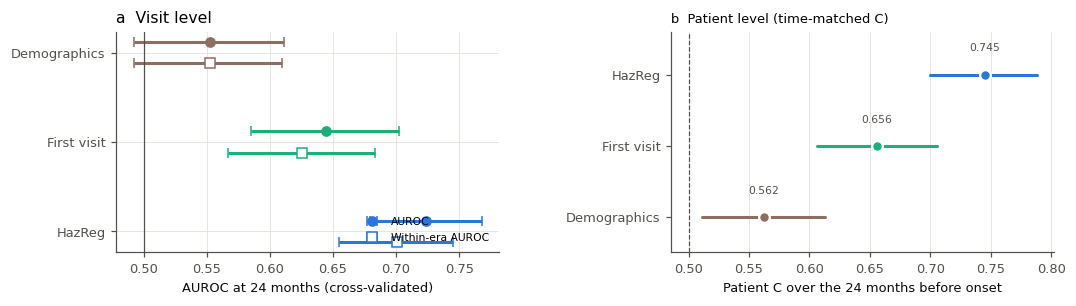

**What this means.**

* **Demographics alone barely rank patients** (AUROC 0.55, where 0.5 is chance). Age, education
  and race say little about who will leave work for health reasons.
* **About 54 % of the gain over demographics is already there at the first
  employed visit** (AUROC 0.64, a gain of +0.092). How a patient's lupus looked when we
  first saw them working says a good deal about their risk years later.
* **The current visit adds +0.079** (95 % CI +0.031 to +0.129) on top of the first visit
  (AUROC 0.72). It is a real gain: refreshing the score at each visit helps.

**At the patient level** the ladder looks the same: patient C 0.56 →
0.66 → 0.74, with the current visit adding +0.089
(+0.046 to +0.130) to the first visit. HazReg's alarm caught
70 % of patients in the 24 months before their onset, and left
60 % of patients who kept working unflagged over the same months.

Taken together, risk of work disability in SLE behaves largely as a **stable trait of the patient** that becomes
visible early. That supports using the tool to *stratify* patients, so that clinicians know whom to watch, rather
than to sound an alarm just before someone leaves work.

In [20]:
"""The ladder: demographics -> first employed visit -> current visit (HazReg)."""
LADDER = ["Demographics", "First visit", "HazReg"]
display(metrics_table(LADDER))
STEPS = pd.DataFrame({
    "H1  HazReg − Demographics": {k: fmt(paired("HazReg", "Demographics", k)) for k in ["AUROC", "Within-era AUROC", "IPA"]},
    "H2a  First visit − Demographics": {k: fmt(paired("First visit", "Demographics", k)) for k in ["AUROC", "Within-era AUROC", "IPA"]},
    "H2b  HazReg − First visit": {k: fmt(paired("HazReg", "First visit", k)) for k in ["AUROC", "Within-era AUROC", "IPA"]},
}).T
display(STEPS)
record("H1", "Routine clinic data rank risk better than demographics", "AUROC, HazReg − Demographics",
       paired("HazReg", "Demographics"), "above0")
record("H2a", "The first employed visit adds to demographics", "AUROC, First visit − Demographics",
       paired("First visit", "Demographics"), "above0")
record("H2b", "The current visit adds to the first visit", "AUROC, HazReg − First visit",
       paired("HazReg", "First visit"), "above0")

# ---- the same ladder at the patient level (time-matched patient C; the alarm's sensitivity and specificity)
display(pt_table(LADDER))
PT_STEPS = pd.DataFrame({
    "H1  HazReg − Demographics": {k: fmt(ppaired("HazReg", "Demographics", k)) for k in ["C", "Sensitivity", "Specificity"]},
    "H2a  First visit − Demographics": {k: fmt(ppaired("First visit", "Demographics", k)) for k in ["C", "Sensitivity", "Specificity"]},
    "H2b  HazReg − First visit": {k: fmt(ppaired("HazReg", "First visit", k)) for k in ["C", "Sensitivity", "Specificity"]},
}).T.rename(columns={"C": "Patient C"})
display(PT_STEPS)
record_pt("H1", ppaired("HazReg", "Demographics"))
record_pt("H2a", ppaired("First visit", "Demographics"))
record_pt("H2b", ppaired("HazReg", "First visit"))

fig, axes = plt.subplots(1, 2, figsize=(11, 2.6), gridspec_kw={"wspace": 0.45})
ax = axes[0]
for i, n in enumerate(LADDER[::-1]):
    for j, k in enumerate(["AUROC", "Within-era AUROC"]):
        e, lo, hi = CV_RES[n][k]
        ax.errorbar([e], [i + (0.12 if j == 0 else -0.12)], xerr=[[e - lo], [hi - e]], fmt="o" if j == 0 else "s",
                    color=MODEL_COLORS[n], mfc=MODEL_COLORS[n] if j == 0 else "white", ms=6, capsize=3,
                    label=k if i == 0 else None)
ax.axvline(0.5, color=INK_2, lw=0.8)
ax.set_yticks(range(len(LADDER)), LADDER[::-1]); ax.set_xlabel("AUROC at 24 months (cross-validated)")
ax.set_title("a  Visit level", loc="left"); ax.legend(loc="lower right", fontsize=7)
_ci_panel(axes[1], [(n, PT_RES[n]["C"], MODEL_COLORS[n]) for n in LADDER[::-1]], "b  Patient level (time-matched C)",
          ref=0.5, xlabel="Patient C over the 24 months before onset")
save_fig("fig02_ladder")
_a = {n: CV_RES[n]["AUROC"][0] for n in LADDER}
_s1, _s2 = paired("First visit", "Demographics"), paired("HazReg", "First visit")
_ps2 = ppaired("HazReg", "First visit")
say(f"""
**What this means.**

* **Demographics alone barely rank patients** (AUROC {_a['Demographics']:.2f}, where 0.5 is chance). Age, education
  and race say little about who will leave work for health reasons.
* **About {100 * _s1[0] / (_s1[0] + _s2[0]):.0f} % of the gain over demographics is already there at the first
  employed visit** (AUROC {_a['First visit']:.2f}, a gain of {_s1[0]:+.3f}). How a patient's lupus looked when we
  first saw them working says a good deal about their risk years later.
* **The current visit adds {_s2[0]:+.3f}** (95 % CI {_s2[1]:+.3f} to {_s2[2]:+.3f}) on top of the first visit
  (AUROC {_a['HazReg']:.2f}). {"It is a real gain: refreshing the score at each visit helps." if _s2[1] > 0 else
  "The gain is not distinguishable from zero: a score computed once would serve about as well."}

**At the patient level** the ladder looks the same: patient C {PT_RES['Demographics']['C'][0]:.2f} →
{PT_RES['First visit']['C'][0]:.2f} → {PT_RES['HazReg']['C'][0]:.2f}, with the current visit adding {_ps2[0]:+.3f}
({_ps2[1]:+.3f} to {_ps2[2]:+.3f}) to the first visit. HazReg's alarm caught
{100 * PT_RES['HazReg']['Sensitivity'][0]:.0f} % of patients in the 24 months before their onset, and left
{100 * PT_RES['HazReg']['Specificity'][0]:.0f} % of patients who kept working unflagged over the same months.

Taken together, risk of work disability in SLE behaves largely as a **stable trait of the patient** that becomes
visible early. That supports using the tool to *stratify* patients, so that clinicians know whom to watch, rather
than to sound an alarm just before someone leaves work.
""")

## 3.2 Does a different kind of model do better?

> **The question.** Would a logistic regression, or a deep-learning model that reads every earlier visit, rank
> patients better than HazReg?

The comparison is **equivalence**: a difference within ± 0.02 AUROC is too small to matter clinically. A
comparator "performs the same" if the whole 95 % CI of its difference from HazReg lies inside that margin.

,HazReg,LogReg,LSTM
Patient C (time-matched),0.745 (0.700 to 0.788),0.731 (0.687 to 0.773),0.726 (0.680 to 0.769)
Sensitivity,0.70 (0.62 to 0.77),0.68 (0.61 to 0.76),0.65 (0.58 to 0.73)
Specificity,0.60 (0.56 to 0.64),0.61 (0.58 to 0.65),0.64 (0.60 to 0.68)
Balanced accuracy,0.65 (0.61 to 0.69),0.65 (0.61 to 0.69),0.65 (0.61 to 0.69)
Patients ever flagged (%),48,43,45
Alarm episodes per 100 person-years,6.6,5.9,6.1
Episode PPV (%),9.0 (6.6 to 11.4),9.5 (7.1 to 12.1),8.6 (6.4 to 11.0)
"Lead time, median (IQR), months",26 (9-54),25 (10-57),27 (11-54)


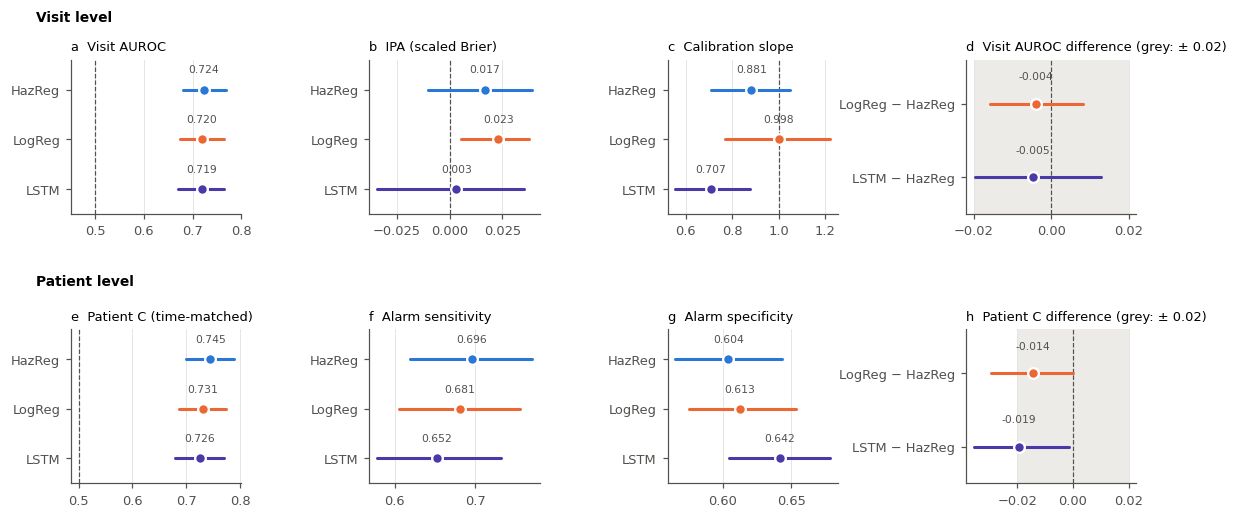

Rank correlation of the cross-validated risks: HazReg-LogReg 0.95, HazReg-LSTM 0.90. LSTM training stopped after a median of 21 epochs (range 19-33).


**What this means.**

* **LogReg vs HazReg: -0.004** (95 % CI -0.016 to +0.008); equivalent to HazReg. The two models
  produce nearly the same ranking (rank correlation 0.95). The hazard formulation is
  chosen for its handling of competing exits and partial follow-up, not for better ranking. That matters most over
  calendar time (Section 4.1).
* **LSTM vs HazReg: -0.005** (95 % CI -0.020 to +0.013); equivalent to HazReg. Reading the whole visit
  history flexibly does not find signal the current visit misses. That fits the ladder: the information is a stable
  trait, and a stable trait is visible at any single visit.
* **At the patient level:** LogReg − HazReg -0.014 (-0.029 to -0.000; worse than HazReg); LSTM −
  HazReg -0.019 (-0.036 to -0.001; worse than HazReg) in time-matched patient C. Neither comparator
  ranks patients better than HazReg. Because each model's risks have a
  different spread, the same alarm rule flags different numbers of patients: sensitivity
  HazReg 70 %, LogReg 68 %, LSTM 65 %; specificity
  HazReg 60 %, LogReg 61 %, LSTM 64 %. At a fixed rule these partly reflect
  the level of risk each model assigns, not only its ranking; the patient C compares ranking alone.

In [21]:
"""HazReg against LogReg and the LSTM (same splits, paired)."""
COMPARE = ["HazReg", "LogReg", "LSTM"]
save_table(metrics_table(COMPARE), "model_comparison_metrics")
CMP = pd.DataFrame({f"{n} − HazReg": {k: fmt(paired(n, "HazReg", k)) for k in ["AUROC", "Within-era AUROC", "IPA"]}
                    for n in ["LogReg", "LSTM"]}).T
save_table(CMP, "model_comparison_differences")


PT_CMP = pt_table(COMPARE)
display(PT_CMP)
save_table(PT_CMP, "model_comparison_patient")
fig, axes = plt.subplots(2, 4, figsize=(12.5, 5.0), gridspec_kw={"wspace": 0.75, "hspace": 0.75})
_ci_panel(axes[0, 0], [(n, CV_RES[n]["AUROC"], MODEL_COLORS[n]) for n in COMPARE], "a  Visit AUROC", ref=0.5)
_ci_panel(axes[0, 1], [(n, CV_RES[n]["IPA"], MODEL_COLORS[n]) for n in COMPARE], "b  IPA (scaled Brier)", ref=0.0)
_ci_panel(axes[0, 2], [(n, CV_RES[n]["Calibration slope"], MODEL_COLORS[n]) for n in COMPARE], "c  Calibration slope", ref=1.0)
_ci_panel(axes[0, 3], [(f"{n} − HazReg", paired(n, "HazReg"), MODEL_COLORS[n]) for n in ["LogReg", "LSTM"]],
          f"d  Visit AUROC difference (grey: ± {EQUIV_MARGIN})", ref=0.0, band=(-EQUIV_MARGIN, EQUIV_MARGIN))
_ci_panel(axes[1, 0], [(n, PT_RES[n]["C"], MODEL_COLORS[n]) for n in COMPARE], "e  Patient C (time-matched)", ref=0.5)
_ci_panel(axes[1, 1], [(n, PT_RES[n]["Sensitivity"], MODEL_COLORS[n]) for n in COMPARE], "f  Alarm sensitivity")
_ci_panel(axes[1, 2], [(n, PT_RES[n]["Specificity"], MODEL_COLORS[n]) for n in COMPARE], "g  Alarm specificity")
_ci_panel(axes[1, 3], [(f"{n} − HazReg", ppaired(n, "HazReg"), MODEL_COLORS[n]) for n in ["LogReg", "LSTM"]],
          f"h  Patient C difference (grey: ± {EQUIV_MARGIN})", ref=0.0, band=(-EQUIV_MARGIN, EQUIV_MARGIN))
axes[0, 0].set_xlim(0.45, 0.8)
fig.text(0.1, 0.95, "Visit level", fontsize=9, fontweight="bold"); fig.text(0.1, 0.47, "Patient level", fontsize=9, fontweight="bold")
save_fig("model_comparison")
record("H4a", "LogReg performs the same as HazReg", f"AUROC, LogReg − HazReg (margin ± {EQUIV_MARGIN})",
       paired("LogReg", "HazReg"), "equiv")
record("H4b", "The LSTM is not materially better than HazReg", f"AUROC, LSTM − HazReg (margin ± {EQUIV_MARGIN})",
       paired("LSTM", "HazReg"), "equiv")
record_pt("H4a", ppaired("LogReg", "HazReg"), "equiv")
record_pt("H4b", ppaired("LSTM", "HazReg"), "equiv")
_rho = pd.DataFrame({n: P_CV[n] for n in COMPARE}).corr(method="spearman")
_ep = np.array(STATE["cv_LSTM"]["tuned"])
print(f"Rank correlation of the cross-validated risks: HazReg-LogReg {_rho.loc['HazReg', 'LogReg']:.2f}, "
      f"HazReg-LSTM {_rho.loc['HazReg', 'LSTM']:.2f}. LSTM training stopped after a median of {np.median(_ep):.0f} "
      f"epochs (range {_ep.min()}-{_ep.max()}).")
_dl, _dn = paired("LogReg", "HazReg"), paired("LSTM", "HazReg")
_pl, _pn = ppaired("LogReg", "HazReg"), ppaired("LSTM", "HazReg")


def _verdict(d):
    if d[1] > -EQUIV_MARGIN and d[2] < EQUIV_MARGIN:
        return "equivalent to HazReg"
    if d[1] > 0:
        return "better than HazReg"
    if d[2] < 0:
        return "worse than HazReg"
    return "inconclusive: the interval is too wide to call equivalence or a difference"


say(f"""
**What this means.**

* **LogReg vs HazReg: {_dl[0]:+.3f}** (95 % CI {_dl[1]:+.3f} to {_dl[2]:+.3f}); {_verdict(_dl)}. The two models
  produce nearly the same ranking (rank correlation {_rho.loc['HazReg', 'LogReg']:.2f}). The hazard formulation is
  chosen for its handling of competing exits and partial follow-up, not for better ranking. That matters most over
  calendar time (Section 4.1).
* **LSTM vs HazReg: {_dn[0]:+.3f}** (95 % CI {_dn[1]:+.3f} to {_dn[2]:+.3f}); {_verdict(_dn)}. Reading the whole visit
  history flexibly does not find signal the current visit misses. That fits the ladder: the information is a stable
  trait, and a stable trait is visible at any single visit.
* **At the patient level:** LogReg − HazReg {_pl[0]:+.3f} ({_pl[1]:+.3f} to {_pl[2]:+.3f}; {_verdict(_pl)}); LSTM −
  HazReg {_pn[0]:+.3f} ({_pn[1]:+.3f} to {_pn[2]:+.3f}; {_verdict(_pn)}) in time-matched patient C. Neither comparator
  ranks patients better than HazReg. Because each model's risks have a
  different spread, the same alarm rule flags different numbers of patients: sensitivity
  {", ".join(f"{n} {100 * PT_RES[n]['Sensitivity'][0]:.0f} %" for n in COMPARE)}; specificity
  {", ".join(f"{n} {100 * PT_RES[n]['Specificity'][0]:.0f} %" for n in COMPARE)}. At a fixed rule these partly reflect
  the level of risk each model assigns, not only its ranking; the patient C compares ranking alone.
""")

## 3.3 Optimism and stability of the final model

The final HazReg is fitted on all patients. Two questions are answered with **200 bootstrap refits** (each a full
rerun of the procedure, tuning included, on a resample of patients):

1. **How optimistic is its apparent performance?** (Harrell's bootstrap) Each refit is scored on its own sample and
   on the original data. The average gap is the optimism.
2. **Would a model built on another sample of this size give this patient the same risk?** (Riley & Collins 2023)
   For each visit, the spread of its 200 bootstrap risks shows how much the prediction depends on the particular
   sample. For a tiered tool, the key figure is how often the bootstrap models put the visit in the same tier.

200 bootstrap refits (1.1 min).


,Apparent,Optimism,Optimism-corrected,Cross-validated
AUROC,0.742,0.016,0.725,0.724
Within-era AUROC,0.722,0.018,0.705,0.701
O/E,0.939,-0.001,0.940,0.909
Brier,0.033,-0.000,0.033,0.033
IPA,0.035,0.010,0.024,0.017
Calibration slope,1.196,0.081,1.115,0.881
Calibration intercept,-0.080,0.000,-0.080,-0.121


,Landmarks,Median MAPE (risk points),Same tier as final model (mean %)
< 2 %,4603,0.003,89.826
2-4 %,7920,0.005,71.197
4-10 %,4073,0.010,76.117
>= 10 %,742,0.033,82.014


,Patients,Same status in >= 80 % of refits (%),Mean agreement (%)
Ever flagged by the final model,506,82.4,91.3
Never flagged by the final model,553,86.4,93.6


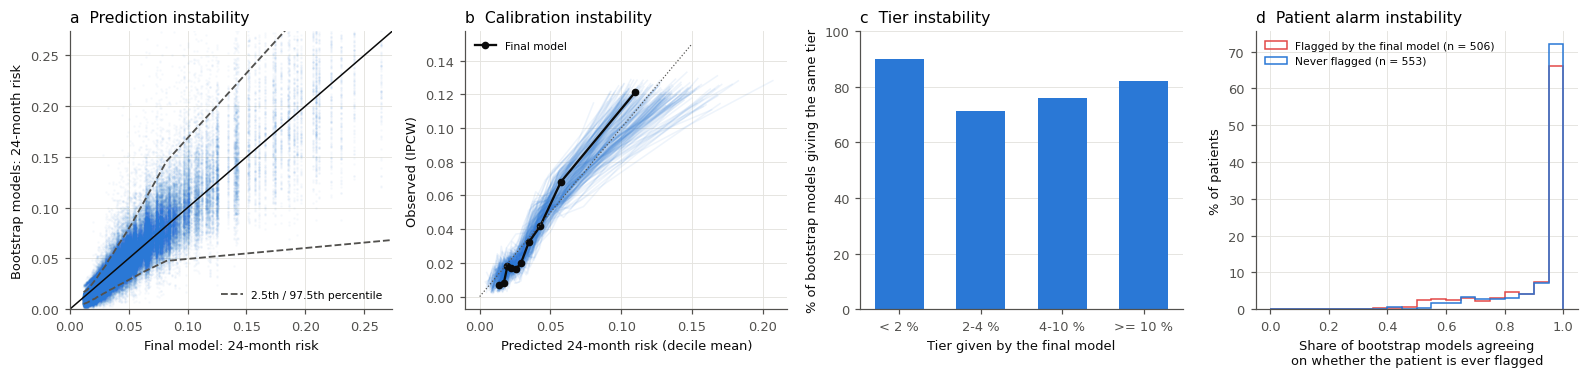

**What this means.**

* **Little optimism.** The apparent AUROC of 0.742 drops only to 0.725
  after correction, matching cross-validation (0.724). The penalty keeps the model honest at
  the population level.
* **Individual risks are less certain than the summary suggests.** On average a visit's risk moves by
  0.8 percentage points between bootstrap models, against a mean risk of 3.7 %.
  Only 52 % of visits get the same tier in at least 80 % of the bootstrap models.
  Visits near a tier boundary can fall either side of it.

* **The patient alarm is steadier than the visit tier.**
  85 % of patients get the same answer (ever flagged or never flagged) from at least
  80 % of the bootstrap models, against 52 % of visits for the tier; a visit's alarm
  state agrees with the final model in 90 % of refits on average. Among patients flagged
  by the final model 82 % are stable, against 86 % of those never flagged.

In practice: present the tier as a **guide to whom to talk to**, not as a precise number. Report the bottom and top
tiers with most confidence, because tier instability is concentrated in the middle.

In [22]:
"""Final model, 200 bootstrap refits, optimism-corrected performance, instability."""
if "final" not in STATE:
    STATE["final"] = fit_procedure(np.arange(N_LAND), seed=SEED)
    _save_state()
FINAL = STATE["final"]
ETA_FULL = predict_eta(FINAL)
P_FULL = cif(ETA_FULL)


def _boot_refit(b):
    rng = np.random.RandomState(SEED + 7000 + b)
    draw = rng.randint(0, P_N, P_N)
    mult = np.bincount(draw, minlength=P_N).astype(float)
    rows = np.concatenate([PT_ROWS[ALL_PIDS[i]] for i in draw])
    m = fit_procedure(rows, seed=SEED + 7000 + b)
    eta = predict_eta(m).astype(np.float32)
    return {"eta": eta, "coef": m["coef"], "intercept": m["intercept"], "alphas": m["alphas"], "prep": m["prep"],
            "mult": mult.astype(np.float32)}


if "boot" not in STATE or len(STATE["boot"]) < BOOT_REFITS:
    t0 = time.time()
    STATE["boot"] = Parallel(n_jobs=N_JOBS)(delayed(_boot_refit)(b) for b in range(BOOT_REFITS))
    _save_state()
    print(f"{BOOT_REFITS} bootstrap refits ({(time.time() - t0) / 60:.1f} min).")
BOOT = STATE["boot"][:BOOT_REFITS]
P_B = np.vstack([cif(b["eta"].astype(float)) for b in BOOT])        # (B, n): bootstrap models on the original data


def _point(p, wrow):
    a = {k: v[0] for k, v in metric_arrays(p, wrow[None, :]).items()}
    a["Calibration slope"], a["Calibration intercept"] = wcalibration(Y_IP, p, W_IP * wrow)
    return a


APPARENT = _point(P_FULL, np.ones(N_LAND))
_opt = []
for b, pb in zip(BOOT, P_B):
    app = _point(pb, b["mult"][ROW_PIDX])
    tst = _point(pb, np.ones(N_LAND))
    _opt.append({k: app[k] - tst[k] for k in app})
OPTIMISM = pd.DataFrame(_opt).mean()
OPT_TABLE = pd.DataFrame({"Apparent": pd.Series(APPARENT), "Optimism": OPTIMISM,
                          "Optimism-corrected": pd.Series(APPARENT) - OPTIMISM,
                          "Cross-validated": pd.Series({k: v[0] for k, v in CV_RES["HazReg"].items()})}).round(3)
display(OPT_TABLE)

MAPE = np.abs(P_B - P_FULL[None, :]).mean(0)
_tier = lambda p: np.digitize(p, [t[1] for t in RISK_TIERS[:-1]])
TIER_FULL = _tier(P_FULL)
TIER_AGREE = (np.vstack([_tier(pb) for pb in P_B]) == TIER_FULL[None, :]).mean(0)
INSTAB = pd.DataFrame({"Landmarks": pd.Series(TIER_FULL).value_counts().reindex(range(len(RISK_TIERS))).fillna(0).values,
                       "Median MAPE (risk points)": [np.median(MAPE[TIER_FULL == k]) if (TIER_FULL == k).any() else np.nan
                                                     for k in range(len(RISK_TIERS))],
                       "Same tier as final model (mean %)": [100 * TIER_AGREE[TIER_FULL == k].mean()
                                                             if (TIER_FULL == k).any() else np.nan
                                                             for k in range(len(RISK_TIERS))]},
                      index=[t[2] for t in RISK_TIERS]).round(3)
display(INSTAB)

# ---- the same at the patient level: does a refit on another sample flag the same patients?
FLAGS_FULL = alarm_flags(P_FULL)
FLAGS_B = alarm_flags(P_B)
_pst = np.array([PT_ROWS[p][0] for p in ALL_PIDS])
assert (np.diff(_pst) > 0).all()
EVER_FULL = np.add.reduceat(FLAGS_FULL.astype(int), _pst) > 0
EVER_B = np.add.reduceat(FLAGS_B.astype(int), _pst, axis=1) > 0
PT_AGREE = (EVER_B == EVER_FULL[None, :]).mean(0)
VISIT_FLAG_AGREE = (FLAGS_B == FLAGS_FULL[None, :]).mean(0)
PT_INSTAB = pd.DataFrame({
    "Patients": [int(EVER_FULL.sum()), int((~EVER_FULL).sum())],
    "Same status in >= 80 % of refits (%)": [100 * (PT_AGREE[EVER_FULL] >= 0.8).mean(), 100 * (PT_AGREE[~EVER_FULL] >= 0.8).mean()],
    "Mean agreement (%)": [100 * PT_AGREE[EVER_FULL].mean(), 100 * PT_AGREE[~EVER_FULL].mean()]},
    index=["Ever flagged by the final model", "Never flagged by the final model"]).round(1)
display(PT_INSTAB)

fig, axes = plt.subplots(1, 4, figsize=(14.5, 3.5))
ax = axes[0]
_s = np.random.RandomState(1).choice(N_LAND, min(1500, N_LAND), replace=False)
ax.scatter(np.repeat(P_FULL[_s], len(P_B)), P_B[:, _s].T.ravel(), s=2, color=C1, alpha=0.05, linewidths=0)
_qbins = np.quantile(P_FULL, np.linspace(0, 1, 21))
_bc = 0.5 * (_qbins[1:] + _qbins[:-1])
_qs = np.array([np.percentile(P_B[:, (P_FULL >= a) & (P_FULL <= b_)], [2.5, 97.5]) for a, b_ in zip(_qbins[:-1], _qbins[1:])])
ax.plot(_bc, _qs[:, 0], "--", color=INK_2, lw=1.2); ax.plot(_bc, _qs[:, 1], "--", color=INK_2, lw=1.2,
                                                            label="2.5th / 97.5th percentile")
lim = np.percentile(P_FULL, 99.5) * 1.3
ax.plot([0, lim], [0, lim], color=INK, lw=1); ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("Final model: 24-month risk"); ax.set_ylabel("Bootstrap models: 24-month risk")
ax.set_title("a  Prediction instability", loc="left"); ax.legend(fontsize=7)
ax = axes[1]


def _cal_points(p):
    dec = pd.qcut(p, 10, labels=False, duplicates="drop")
    o = np.array([np.sum((W_IP * Y_IP)[dec == k]) / (dec == k).sum() for k in range(dec.max() + 1)])
    e = np.array([p[dec == k].mean() for k in range(dec.max() + 1)])
    return e, o


for pb in P_B:
    ax.plot(*_cal_points(pb), color=C1, alpha=0.08, lw=1)
ax.plot(*_cal_points(P_FULL), "o-", color=INK, ms=4, lw=1.5, label="Final model")
ax.plot([0, 0.15], [0, 0.15], color=INK_2, lw=0.8, ls=":")
ax.set_xlabel("Predicted 24-month risk (decile mean)"); ax.set_ylabel("Observed (IPCW)")
ax.set_title("b  Calibration instability", loc="left"); ax.legend(fontsize=7)
ax = axes[2]
ax.bar(np.arange(len(RISK_TIERS)), INSTAB["Same tier as final model (mean %)"], color=C1, width=0.6)
ax.set_xticks(np.arange(len(RISK_TIERS)), INSTAB.index); ax.set_ylim(0, 100); ax.grid(axis="x", visible=False)
ax.set_xlabel("Tier given by the final model"); ax.set_ylabel("% of bootstrap models giving the same tier")
ax.set_title("c  Tier instability", loc="left")
ax = axes[3]
_hb = np.linspace(0, 1, 21)
for flag, col, nm in [(True, "#e34948", "Flagged by the final model"), (False, C1, "Never flagged")]:
    k = EVER_FULL == flag
    ax.hist(PT_AGREE[k], bins=_hb, weights=np.full(k.sum(), 100 / max(k.sum(), 1)), histtype="step", lw=2, color=col,
            label=f"{nm} (n = {k.sum():,})")
ax.set_xlabel("Share of bootstrap models agreeing\non whether the patient is ever flagged"); ax.set_ylabel("% of patients")
ax.set_title("d  Patient alarm instability", loc="left"); ax.legend(fontsize=7, loc="upper left")
plt.tight_layout(); save_fig("fig03_instability")
_oc = OPT_TABLE.loc["AUROC"]
say(f"""
**What this means.**

* **Little optimism.** The apparent AUROC of {_oc['Apparent']:.3f} drops only to {_oc['Optimism-corrected']:.3f}
  after correction, matching cross-validation ({_oc['Cross-validated']:.3f}). The penalty keeps the model honest at
  the population level.
* **Individual risks are less certain than the summary suggests.** On average a visit's risk moves by
  {100 * MAPE.mean():.1f} percentage points between bootstrap models, against a mean risk of {100 * P_FULL.mean():.1f} %.
  Only {100 * (TIER_AGREE >= 0.8).mean():.0f} % of visits get the same tier in at least 80 % of the bootstrap models.
  Visits near a tier boundary can fall either side of it.

* **The patient alarm{" is steadier than the visit tier" if (PT_AGREE >= 0.8).mean() > (TIER_AGREE >= 0.8).mean() else " is no steadier than the visit tier"}.**
  {100 * (PT_AGREE >= 0.8).mean():.0f} % of patients get the same answer (ever flagged or never flagged) from at least
  80 % of the bootstrap models, against {100 * (TIER_AGREE >= 0.8).mean():.0f} % of visits for the tier; a visit's alarm
  state agrees with the final model in {100 * VISIT_FLAG_AGREE.mean():.0f} % of refits on average. Among patients flagged
  by the final model {PT_INSTAB.iloc[0, 1]:.0f} % are stable, against {PT_INSTAB.iloc[1, 1]:.0f} % of those never flagged.

In practice: present the tier as a **guide to whom to talk to**, not as a precise number. Report the bottom and top
tiers with most confidence, because tier instability is concentrated in the middle.
""")

## 3.4 What the model has learned

The table gives each input's hazard ratio per standard deviation, with bootstrap intervals and the share of
refits that agree on its direction. The curves show the four inputs with flexible effects.

> **How to read it.** These are *predictive* associations, shrunk toward no effect by the penalty. They say which
> patients are at higher risk, not what would lower that risk. An input marked by unstable direction (same sign in
> well under 90 % of refits) should not be interpreted on its own.

,Onset HR per SD,95% bootstrap interval,Same sign (%),Competing-exit HR per SD
Term,,,,
Fibromyalgia (diagnosis or >= 11 tender points),1.17,1.11-1.41,100.0,0.99
Prednisone (mg/day) (spline term),1.16,1.07-1.29,99.5,0.89
Prednisone (mg/day),1.11,1.07-1.59,100.0,1.59
Fatigue,1.11,1.03-1.22,99.0,1.02
Dyspnoea,1.11,1.03-1.22,99.0,0.99
"SLEDAI-2K, 12-month adjusted mean (spline term)",1.11,1.04-1.30,99.0,0.91
SDI damage score,1.10,1.05-1.31,100.0,0.86
SDI damage score (spline term),1.10,1.05-1.20,99.0,1.08
Current smoker,1.08,1.02-1.24,98.5,1.00


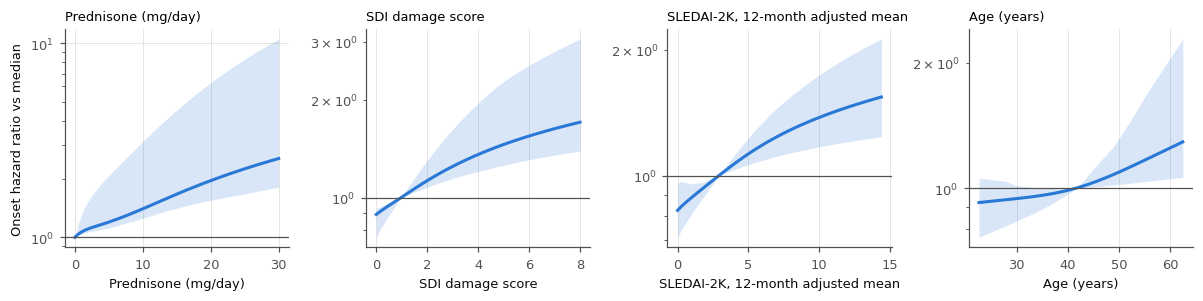

,Flagged: at the first alarm,Never flagged: at the last working visit
Age (years),38.9,40.9
"SLEDAI-2K, 12-mo adjusted mean",8.4,2.9
Prednisone (mg/day),15.8,1.7
SDI damage score,1.7,1.1
Fatigue (%),33.3,6.9
Fibromyalgia (%),25.9,2.9
Treatment ladder (0-3),1.4,1.2
Post-secondary education (%),42.5,51.8
Patients (n),506.0,553.0
Later work disability (%),23.1,6.0


**What this means.** The inputs most consistently linked to **higher** risk are Fibromyalgia (diagnosis or >= 11 tender points), Prednisone (mg/day), Fatigue, Dyspnoea. Those most
consistently linked to **lower** risk are Years since first clinic visit, Antimalarial, Disease duration (years). The picture is of a patient carrying a heavier disease
and symptom burden (more treatment, more damage, more pain and fatigue), rather than of one isolated marker. Several
of these inputs are defined so that they mean the same in every era: the treatment ladder counts drug classes only,
and fibromyalgia combines the recorded diagnosis with the tender-point count, which is examined less often in recent
years (Section 1.3).

**The patients the alarm picks out.** At their first alarm they were on
15.8 mg/day of prednisone (against
1.7 in never-flagged patients at their last working visit), reported
fatigue at 33 % of visits (against 7 %),
and had an SDI of 1.7 (against 1.1).
23 % of flagged patients later left work for health reasons,
against 6 % of those never flagged.

In [23]:
"""Coefficients of the final model and the spline curves, with bootstrap intervals."""
_names = FINAL["prep"].names
_cb = np.stack([b["coef"] for b in BOOT if b["prep"].names == _names])
COEF = pd.DataFrame({"Term": [DISPLAY.get(n.replace("__NL", "").replace("__MISSING", ""), n) +
                              (" (spline term)" if n.endswith("__NL") else " (missing)" if n.endswith("__MISSING") else "")
                              for n in _names],
                     "Onset HR per SD": np.exp(FINAL["coef"][0]),
                     "95% bootstrap interval": [f"{np.exp(a):.2f}-{np.exp(b_):.2f}" for a, b_ in
                                                np.percentile(_cb[:, 0], [2.5, 97.5], axis=0).T],
                     "Same sign (%)": 100 * (np.sign(_cb[:, 0]) == np.sign(FINAL["coef"][0])[None, :]).mean(0),
                     "Competing-exit HR per SD": np.exp(FINAL["coef"][1])}).round(2)
display(COEF.sort_values("Onset HR per SD", ascending=False).set_index("Term"))


def _partial(m, c, grid):
    """Log-hazard of onset across `grid` (raw values of input c), other inputs at the training medians."""
    pr = m["prep"]
    X = pd.DataFrame({k: np.full(len(grid), np.nan) for k in pr.cols})
    for k in pr.cols:
        X[k] = np.expm1(pr.med[k]) if k in LOG1P_VARS else pr.med[k]
    X[c] = grid
    eta = predict_eta(m, X=pr.transform(X))[:, 0]
    return eta - eta[np.argmin(np.abs(grid - np.nanmedian(LAND_X[c])))]


fig, axes = plt.subplots(1, len(SPLINE_VARS), figsize=(11, 2.8))
for ax, c in zip(axes, SPLINE_VARS):
    grid = np.linspace(*np.nanpercentile(LAND_X[c], [2, 98]), 60)
    curves = np.array([_partial({"prep": b["prep"], "coef": b["coef"], "intercept": b["intercept"]}, c, grid)
                       for b in BOOT])
    lo, hi = np.percentile(curves, [2.5, 97.5], axis=0)
    ax.fill_between(grid, np.exp(lo), np.exp(hi), color=C1, alpha=0.18, linewidth=0)
    ax.plot(grid, np.exp(_partial(FINAL, c, grid)), color=C1)
    ax.axhline(1, color=INK_2, lw=0.8)
    ax.set_yscale("log"); ax.set_xlabel(DISPLAY[c]); ax.set_title(DISPLAY[c], loc="left", fontsize=8.5)
axes[0].set_ylabel("Onset hazard ratio vs median")
plt.tight_layout(); save_fig("fig04_spline_effects")
# ---- at the patient level: what the patients the alarm picks out look like (cross-validated HazReg alarm)
_fl = FLAGS["HazReg"]
_first_flag = pd.Series(np.where(_fl, np.arange(N_LAND), N_LAND)).groupby(PID_ALL).min().reindex(ALL_PIDS).values
_last_lm = np.array([PT_ROWS[p][-1] for p in ALL_PIDS])
_flagged = _first_flag < N_LAND
_prof_rows = np.where(_flagged, np.minimum(_first_flag, N_LAND - 1), _last_lm)
_PROF = [("age_at_record", "Age (years)", 1), ("AMS_12M", "SLEDAI-2K, 12-mo adjusted mean", 1),
         ("STERAVER_0", "Prednisone (mg/day)", 1), ("score_n", "SDI damage score", 1), ("FATIGUE", "Fatigue (%)", 100),
         ("FM_ANY", "Fibromyalgia (%)", 100), ("TREAT_LADDER", "Treatment ladder (0-3)", 1),
         ("EDU_HIGHER", "Post-secondary education (%)", 100)]
FLAG_PROFILE = pd.DataFrame({lab: {"Flagged: at the first alarm": np.nanmean(LAND_X[c].values[_prof_rows[_flagged]]) * sc,
                                   "Never flagged: at the last working visit": np.nanmean(LAND_X[c].values[_prof_rows[~_flagged]]) * sc}
                             for c, lab, sc in _PROF}).T.round(1)
FLAG_PROFILE.loc["Patients (n)"] = [int(_flagged.sum()), int((~_flagged).sum())]
FLAG_PROFILE.loc["Later work disability (%)"] = [100 * PID_EVENT[_flagged].mean(), 100 * PID_EVENT[~_flagged].mean()]
display(FLAG_PROFILE.round(1))

_main = COEF[[not n.endswith(("__NL", "__MISSING")) for n in _names]].copy()
_stable = _main[_main["Same sign (%)"] >= 90]
_up = _stable.sort_values("Onset HR per SD", ascending=False).head(4)["Term"].tolist()
_dn_ = _stable.sort_values("Onset HR per SD").head(3)["Term"].tolist()
say(f"""
**What this means.** The inputs most consistently linked to **higher** risk are {", ".join(_up)}. Those most
consistently linked to **lower** risk are {", ".join(_dn_)}. The picture is of a patient carrying a heavier disease
and symptom burden (more treatment, more damage, more pain and fatigue), rather than of one isolated marker. Several
of these inputs are defined so that they mean the same in every era: the treatment ladder counts drug classes only,
and fibromyalgia combines the recorded diagnosis with the tender-point count, which is examined less often in recent
years (Section 1.3).

**The patients the alarm picks out.** At their first alarm they were on
{FLAG_PROFILE.loc['Prednisone (mg/day)'].iloc[0]:.1f} mg/day of prednisone (against
{FLAG_PROFILE.loc['Prednisone (mg/day)'].iloc[1]:.1f} in never-flagged patients at their last working visit), reported
fatigue at {FLAG_PROFILE.loc['Fatigue (%)'].iloc[0]:.0f} % of visits (against {FLAG_PROFILE.loc['Fatigue (%)'].iloc[1]:.0f} %),
and had an SDI of {FLAG_PROFILE.loc['SDI damage score'].iloc[0]:.1f} (against {FLAG_PROFILE.loc['SDI damage score'].iloc[1]:.1f}).
{FLAG_PROFILE.loc['Later work disability (%)'].iloc[0]:.0f} % of flagged patients later left work for health reasons,
against {FLAG_PROFILE.loc['Later work disability (%)'].iloc[1]:.0f} % of those never flagged.
""")

## 3.5 Does the patient's history add to the current visit?

> **The question.** At a working visit, is it enough to know how the patient is *now*, or does knowing how they
> have been over the **last 2 years**, or over their **whole record** since the first clinic visit, rank them
> better?

The same question is asked of both model families, so that a null result cannot be blamed on one way of reading
history:

| | **Current visit** | **Last 2 years** | **Whole record** |
|:--|:--|:--|:--|
| **Regression** (hazard model) | HazReg: the 20 inputs at the visit | HazReg + summaries of the last 2 years | HazReg + the same summaries over the whole record |
| **LSTM** (reads visits in order) | The landmark visit alone | Every clinic visit in the 2 years before the landmark | Every clinic visit since the first (the LSTM of Section 3.2) |

**The history summaries** (19 per window): for each of nine inputs that change from visit to visit (SLEDAI-2K,
prednisone, SDI, fatigue, arthralgia, dyspnoea, fibromyalgia, active joint count, treatment ladder), the **mean**
over the window and the **change** from the first value in the window to now; plus the number of **clinic visits
per year** in the window. All are computed from that visit and earlier ones only. Everything else (splines,
penalty, tuning, splits) is the same as for HazReg.

Visit-level and patient-level results are both shown. The hypotheses are tested on the regression family, whose
three models differ only in their inputs:

| | Hypothesis | What is compared | Met if |
|:--|:--|:--|:--|
| H7a | The last 2 years add to the current visit | AUROC, HazReg + 2-year history − HazReg | CI above 0 |
| H7b | The whole record adds to the current visit | AUROC, HazReg + whole-record history − HazReg | CI above 0 |

HazReg + 2-year history: cross-validated in 0.4 min
HazReg + whole-record history: cross-validated in 0.3 min
LSTM, current visit: cross-validated in 0.7 min
LSTM, last 2 years: cross-validated in 2.1 min


,Regression: Current visit,Regression: Last 2 years,Regression: Whole record,LSTM: Current visit,LSTM: Last 2 years,LSTM: Whole record
AUROC,0.724 (0.680 to 0.768),0.725 (0.681 to 0.768),0.715 (0.668 to 0.763),0.713 (0.669 to 0.757),0.719 (0.670 to 0.766),0.719 (0.670 to 0.764)
Within-era AUROC,0.701 (0.655 to 0.745),0.702 (0.658 to 0.746),0.693 (0.643 to 0.740),0.689 (0.645 to 0.734),0.689 (0.640 to 0.738),0.691 (0.643 to 0.741)
IPA,0.017 (-0.010 to 0.039),0.025 (-0.003 to 0.051),0.022 (-0.003 to 0.045),0.005 (-0.027 to 0.032),0.009 (-0.028 to 0.040),0.003 (-0.035 to 0.035)
O/E,0.909 (0.750 to 1.080),0.909 (0.750 to 1.082),0.914 (0.754 to 1.093),0.897 (0.737 to 1.069),0.879 (0.720 to 1.056),0.863 (0.705 to 1.039)
Calibration slope,0.881 (0.708 to 1.050),0.917 (0.724 to 1.102),0.917 (0.694 to 1.123),0.700 (0.551 to 0.849),0.728 (0.575 to 0.888),0.707 (0.555 to 0.877)
Calibration intercept,-0.121 (-0.294 to 0.059),-0.124 (-0.306 to 0.048),-0.118 (-0.303 to 0.068),-0.144 (-0.341 to 0.044),-0.164 (-0.373 to 0.026),-0.190 (-0.383 to 0.003)
Patient C (time-matched),0.745 (0.700 to 0.788),0.742 (0.699 to 0.785),0.740 (0.695 to 0.785),0.738 (0.692 to 0.779),0.720 (0.675 to 0.764),0.726 (0.680 to 0.769)
Sensitivity,0.70 (0.62 to 0.77),0.70 (0.62 to 0.77),0.70 (0.62 to 0.78),0.67 (0.60 to 0.75),0.66 (0.58 to 0.74),0.65 (0.58 to 0.73)
Specificity,0.60 (0.56 to 0.64),0.60 (0.57 to 0.64),0.60 (0.57 to 0.64),0.63 (0.59 to 0.67),0.64 (0.61 to 0.68),0.64 (0.60 to 0.68)
Balanced accuracy,0.65 (0.61 to 0.69),0.65 (0.61 to 0.69),0.65 (0.61 to 0.69),0.65 (0.61 to 0.69),0.65 (0.61 to 0.69),0.65 (0.61 to 0.69)


,Visit AUROC,Within-era AUROC,Patient C,Alarm sensitivity,Alarm specificity
Regression: Last 2 years − current visit,0.001 (-0.012 to 0.014),0.001 (-0.013 to 0.015),-0.003 (-0.018 to 0.015),0.00 (-0.05 to 0.05),0.00 (-0.02 to 0.02)
Regression: Whole record − current visit,-0.009 (-0.029 to 0.009),-0.008 (-0.030 to 0.010),-0.005 (-0.022 to 0.012),0.01 (-0.04 to 0.06),0.00 (-0.01 to 0.02)
LSTM: Last 2 years − current visit,0.006 (-0.009 to 0.022),-0.000 (-0.017 to 0.017),-0.018 (-0.035 to -0.001),-0.01 (-0.06 to 0.03),0.01 (-0.00 to 0.03)
LSTM: Whole record − current visit,0.006 (-0.008 to 0.021),0.002 (-0.013 to 0.018),-0.012 (-0.027 to 0.004),-0.02 (-0.08 to 0.04),0.01 (-0.01 to 0.03)


Parameters per exit type: HazReg 34, + 2-year history 65, + whole-record history 65. Median clinic visits read per landmark: 6 in the last 2 years; whole record 17 visits per patient up to their last landmark.


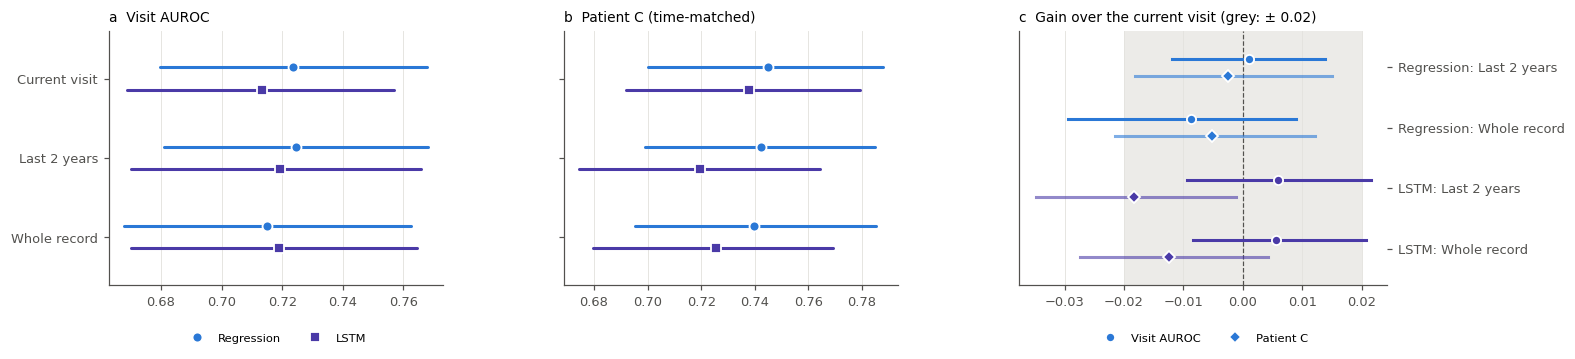

**What this means.**

* **Regression family.** Adding the last 2 years changes the visit AUROC by +0.001 (-0.012 to
  +0.014; no clear difference), and the whole record by -0.009 (-0.029 to +0.009;
  no clear difference). At the patient level the changes are -0.003 and -0.005 in time-matched C.
* **LSTM family.** Reading the last 2 years instead of the landmark visit alone changes the visit AUROC by
  +0.006 (-0.009 to +0.022), and reading every visit since the first by +0.006
  (-0.008 to +0.021).
* **Neither family finds information in the history that the current visit lacks**, at the visit or at the patient level. That is what a stable trait predicts: damage, treatment and symptom burden accumulate and are carried into the current visit.

In practice, the tool needs only the current visit's record. It does not depend on how complete a patient's earlier record is, which matters for patients who joined the clinic recently or transferred from elsewhere.

In [24]:
"""Current visit vs last 2 years vs whole record, in the regression and LSTM families (same splits, paired)."""
HIST_MODELS = {  # name: (kind, inputs, spline terms, LSTM window in days)
    "HazReg + 2-year history": ("haz", COMPACT_VARS + HIST_VARS["2Y"], SPLINE_VARS, None),
    "HazReg + whole-record history": ("haz", COMPACT_VARS + HIST_VARS["ALL"], SPLINE_VARS, None),
    "LSTM, current visit": ("lstm", None, (), 0),
    "LSTM, last 2 years": ("lstm", None, (), 2 * 365.25),
}
for name, (kind, cols, spline, win) in HIST_MODELS.items():
    if f"cv_{name}" not in STATE:
        t0 = time.time()
        STATE[f"cv_{name}"] = run_cv(kind, cols, spline, window=win)
        _save_state()
        print(f"{name}: cross-validated in {(time.time() - t0) / 60:.1f} min")
for name in HIST_MODELS:
    P_CV[name] = cv_risk(name)
    CV_RES[name], CV_ARR[name] = summarise(P_CV[name])
    FLAGS[name] = alarm_flags(P_CV[name])
    PT_RES[name], PT_ARR[name] = pt_summary(PT_EVAL, P_CV[name], FLAGS[name])

HIST_GRID = {"Regression": ["HazReg", "HazReg + 2-year history", "HazReg + whole-record history"],
             "LSTM": ["LSTM, current visit", "LSTM, last 2 years", "LSTM"]}
WINDOW_NAMES = ["Current visit", "Last 2 years", "Whole record"]
_hist_lab = {n: f"{fam}: {w}" for fam, ns in HIST_GRID.items() for n, w in zip(ns, WINDOW_NAMES)}
_allh = [n for ns in HIST_GRID.values() for n in ns]
HIST_TABLE = pd.concat([metrics_table(_allh), pt_table(_allh)]).rename(columns=_hist_lab)
display(HIST_TABLE)
save_table(HIST_TABLE, "history_comparison")
HIST_DIFF = pd.DataFrame({
    f"{fam}: {w} − current visit": {
        "Visit AUROC": fmt(paired(n, ns[0])), "Within-era AUROC": fmt(paired(n, ns[0], "Within-era AUROC")),
        "Patient C": fmt(ppaired(n, ns[0])), "Alarm sensitivity": fmt(ppaired(n, ns[0], "Sensitivity"), 2),
        "Alarm specificity": fmt(ppaired(n, ns[0], "Specificity"), 2)}
    for fam, ns in HIST_GRID.items() for n, w in zip(ns[1:], WINDOW_NAMES[1:])}).T
display(HIST_DIFF)
save_table(HIST_DIFF, "history_differences")
record("H7a", "The last 2 years add to the current visit", "AUROC, HazReg + 2-year history − HazReg",
       paired("HazReg + 2-year history", "HazReg"), "above0")
record("H7b", "The whole record adds to the current visit", "AUROC, HazReg + whole-record history − HazReg",
       paired("HazReg + whole-record history", "HazReg"), "above0")
record_pt("H7a", ppaired("HazReg + 2-year history", "HazReg"))
record_pt("H7b", ppaired("HazReg + whole-record history", "HazReg"))
_P_h = {t: len(Prep(COMPACT_VARS + HIST_VARS[t], SPLINE_VARS).fit(LAND_X).names) for t in HIST_VARS}
_st2 = seq_starts(2 * 365.25)
_nv2 = np.concatenate([SEQ_LPOS[p] - _st2[p] + 1 for p in ALL_PIDS])        # visits read per landmark, last 2 years
print(f"Parameters per exit type: HazReg {_P}, + 2-year history {_P_h['2Y']}, + whole-record history {_P_h['ALL']}. "
      f"Median clinic visits read per landmark: {np.median(_nv2):.0f} in the last 2 years; whole record "
      f"{np.median([len(SEQ_VROWS[p]) for p in ALL_PIDS]):.0f} visits per patient up to their last landmark.")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.0), gridspec_kw={"wspace": 0.35, "width_ratios": [1, 1, 1.1]})
_fam_col = {"Regression": C1, "LSTM": C4}
for ax, (key, res, ttl, ref) in zip(axes[:2], [("AUROC", CV_RES, "a  Visit AUROC", 0.5),
                                               ("C", PT_RES, "b  Patient C (time-matched)", 0.5)]):
    for j, (fam, ns) in enumerate(HIST_GRID.items()):
        for i, n in enumerate(ns):
            e, lo, hi = res[n][key]
            y = i + (j - 0.5) * 0.28
            ax.plot([lo, hi], [y, y], color=_fam_col[fam], lw=2, solid_capstyle="round")
            ax.plot(e, y, "o" if fam == "Regression" else "s", color=_fam_col[fam], ms=6.5, mec="white", mew=1.2,
                    label=fam if i == 0 else None)
    ax.set_yticks(range(3), WINDOW_NAMES); ax.set_ylim(2.6, -0.6); ax.grid(axis="y", visible=False)
    ax.set_title(ttl, loc="left", fontsize=9)
axes[0].legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
axes[1].tick_params(labelleft=False)
ax = axes[2]
ax.axvspan(-EQUIV_MARGIN, EQUIV_MARGIN, color=GRID_C, alpha=0.7, lw=0, zorder=0)
ax.axvline(0, color=INK_2, lw=0.8, ls="--")
_items = [(f"{fam}: {w}", n, ns[0], fam) for fam, ns in HIST_GRID.items() for n, w in zip(ns[1:], WINDOW_NAMES[1:])]
for i, (lab, n, ref_, fam) in enumerate(_items):
    for j, (fn, mk) in enumerate([(paired, "o"), (ppaired, "D")]):
        t = fn(n, ref_)
        y = i + (j - 0.5) * 0.28
        ax.plot([t[1], t[2]], [y, y], color=_fam_col[fam], lw=2, alpha=1 if j == 0 else 0.6)
        ax.plot(t[0], y, mk, color=_fam_col[fam], ms=6, mec="white", mew=1.2,
                label=("Visit AUROC" if j == 0 else "Patient C") if i == 0 else None)
ax.set_yticks(range(len(_items)), [it[0] for it in _items]); ax.set_ylim(len(_items) - 0.4, -0.6)
ax.grid(axis="y", visible=False); ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
ax.yaxis.tick_right()
ax.set_title(f"c  Gain over the current visit (grey: ± {EQUIV_MARGIN})", loc="left", fontsize=9)
save_fig("history_comparison")
_h2, _ha = paired("HazReg + 2-year history", "HazReg"), paired("HazReg + whole-record history", "HazReg")
_l2, _la = paired("LSTM, last 2 years", "LSTM, current visit"), paired("LSTM", "LSTM, current visit")
_p2, _pa = ppaired("HazReg + 2-year history", "HazReg"), ppaired("HazReg + whole-record history", "HazReg")
_word = lambda d: "a real gain" if d[1] > 0 else "a loss" if d[2] < 0 else "no clear difference"
if max(_h2[1], _ha[1], _l2[1], _la[1], _p2[1], _pa[1]) <= 0:
    _hist_concl = ("* **Neither family finds information in the history that the current visit lacks**, at the visit or at "
                   "the patient level. That is what a stable trait predicts: damage, treatment and symptom burden "
                   "accumulate and are carried into the current visit.\n\nIn practice, the tool needs only the current "
                   "visit's record. It does not depend on how complete a patient's earlier record is, which matters for "
                   "patients who joined the clinic recently or transferred from elsewhere.")
else:
    _hist_concl = ("* **Some history adds information** (an interval above zero in the table above). The gain should be "
                   "weighed against the extra inputs the tool would need, and against the size of the gain relative to "
                   f"the ± {EQUIV_MARGIN} margin used for the model comparison.")
say(f"""
**What this means.**

* **Regression family.** Adding the last 2 years changes the visit AUROC by {_h2[0]:+.3f} ({_h2[1]:+.3f} to
  {_h2[2]:+.3f}; {_word(_h2)}), and the whole record by {_ha[0]:+.3f} ({_ha[1]:+.3f} to {_ha[2]:+.3f};
  {_word(_ha)}). At the patient level the changes are {_p2[0]:+.3f} and {_pa[0]:+.3f} in time-matched C.
* **LSTM family.** Reading the last 2 years instead of the landmark visit alone changes the visit AUROC by
  {_l2[0]:+.3f} ({_l2[1]:+.3f} to {_l2[2]:+.3f}), and reading every visit since the first by {_la[0]:+.3f}
  ({_la[1]:+.3f} to {_la[2]:+.3f}).
{_hist_concl}
""")

---
# Part IV. Over calendar time

Exit rates from work fell sharply over the study period (Section 1.5). A model fitted to all years together
predicts an *average* level of risk, which may be too high for today's patients. This part asks three questions:

1. **How much of the fall do patients' own characteristics explain?** (4.1)
2. **Does the model still rank patients, and size their risk, in later years?** (4.2)
3. **Can its level be brought up to date without refitting it?** (4.3, temporal recalibration)

## 4.1 How much of the fall is explained by who the patients are?

> **The idea.** The model has no calendar time, so its predictions change over the years only because patients
> changed: less prednisone, less damage, different symptoms. Comparing the onsets it *expects* era by era with
> those *observed* splits the fall into a part explained by patients (case mix) and a part that is not.

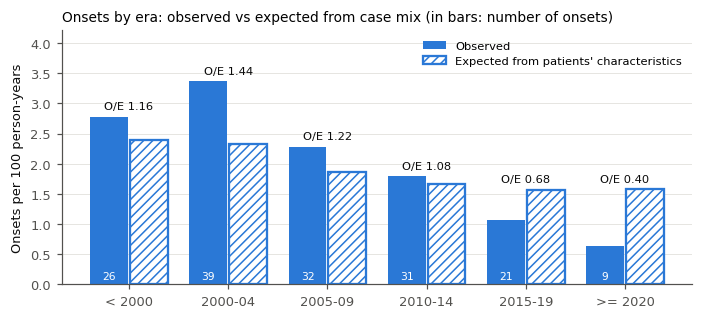

**What this means.** From 2000-04 to >= 2020, the observed onset rate fell to 0.19 times its earlier
level. The rate expected from patients' characteristics fell to 0.68 times. On the log scale, **case mix
accounts for about 23 % of the fall.** The rest shows as observed / expected drifting from
1.44 to 0.40. Other exits drift the
same way (1.59 → 0.31).

Patients really have become healthier in ways that matter for work, and the model sees that without being told the
year. The unexplained remainder affects every kind of exit from work alike. It is what temporal recalibration
(Section 4.3) adjusts for, and what Part V tests as possible under-recording.

,Patients seen,Visits flagged (%),Patients ever flagged (%),Alarm episodes per 100 person-years,Episode PPV (%),Episode PPV 95% CI
Era,,,,,,
< 2000,268,45.5,47.4,12.0,6.1,2.3-10.3
2000-04,347,52.1,50.4,9.3,14.7,8.4-21.1
2005-09,398,46.0,48.2,6.5,6.4,2.1-11.9
2010-14,487,38.0,38.4,4.9,13.0,6.5-20.5
2015-19,558,32.1,35.7,4.9,6.1,2.0-11.3
>= 2020,433,32.4,32.8,4.1,5.8,0.0-18.8


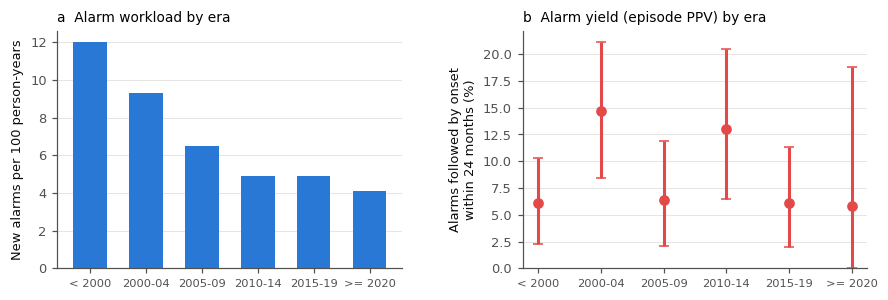

**At the patient level**, new alarms went from 12.0 per 100
person-years in < 2000 to 4.1 in >= 2020
(× 0.34), as the case mix changed. The share of alarms followed by a recorded onset within 24 months went from
6 % to 6 % (× 0.95).
The yield of an alarm did not fall with the number of alarms.

In [25]:
"""Expected (from patient characteristics, no calendar time) vs observed onsets by era."""
_day = lambda y: float((pd.Timestamp(f"{y}-01-01") - pd.Timestamp("1970-01-01")).days)
_rows_ce = []
for k, (a, b, lab) in enumerate(ERAS):
    lo, hi = _edges[k], _edges[k + 1]
    expo = np.clip(np.minimum(INT_END, hi) - np.maximum(LAND_T, lo), 0, None) / 365.25
    inn = (INT_END > lo) & (INT_END <= hi)
    py = expo.sum()
    if py < 50:
        continue
    e1 = np.sum(np.exp(ETA_FULL[:, 0]) * expo)
    e2 = np.sum(np.exp(ETA_FULL[:, 1]) * expo)
    _rows_ce.append({"Era": lab, "Person-years": round(py), "Onsets observed": int(D1[inn].sum()),
                     "Onsets expected": e1, "Observed / expected": D1[inn].sum() / e1,
                     "Expected rate /100 py": 100 * e1 / py, "Observed rate /100 py": 100 * D1[inn].sum() / py,
                     "Other exits O/E": D2[inn].sum() / e2})
CASE_MIX = pd.DataFrame(_rows_ce).set_index("Era").round(2)
save_table(CASE_MIX, "case_mix_by_era")
fig, ax = plt.subplots(figsize=(7.4, 3.0))
_x = np.arange(len(CASE_MIX))
_bo = ax.bar(_x - 0.2, CASE_MIX["Observed rate /100 py"], 0.38, color=C1, label="Observed")
_be = ax.bar(_x + 0.2, CASE_MIX["Expected rate /100 py"], 0.38, color="white", edgecolor=C1, linewidth=1.5, hatch="////",
             label="Expected from patients' characteristics")
for i, (o, e, oe) in enumerate(zip(CASE_MIX["Observed rate /100 py"], CASE_MIX["Expected rate /100 py"],
                                   CASE_MIX["Observed / expected"])):
    ax.text(i, max(o, e) + 0.12, f"O/E {oe:.2f}", ha="center", fontsize=7.5, color=INK)
    ax.text(i - 0.2, 0.08, f"{int(CASE_MIX['Onsets observed'].iloc[i])}", ha="center", fontsize=7, color="white")
ax.set_xticks(_x, CASE_MIX.index); ax.grid(axis="x", visible=False)
ax.set_ylabel("Onsets per 100 person-years")
ax.set_ylim(0, CASE_MIX[["Observed rate /100 py", "Expected rate /100 py"]].values.max() * 1.25)
ax.set_title("Onsets by era: observed vs expected from case mix (in bars: number of onsets)",
             loc="left", fontsize=9)
ax.legend(loc="upper right", fontsize=7.5)
save_fig("case_mix_by_era")
_cm = CASE_MIX
_first, _lastera = ("2000-04" if "2000-04" in _cm.index else _cm.index[0]), _cm.index[-1]
_exp_ratio = _cm.loc[_lastera, "Expected rate /100 py"] / _cm.loc[_first, "Expected rate /100 py"]
_obs_ratio = _cm.loc[_lastera, "Observed rate /100 py"] / _cm.loc[_first, "Observed rate /100 py"]
_share = np.log(_exp_ratio) / np.log(_obs_ratio) if _obs_ratio < 1 else np.nan
say(f"""
**What this means.** From {_first} to {_lastera}, the observed onset rate fell to {_obs_ratio:.2f} times its earlier
level. The rate expected from patients' characteristics fell to {_exp_ratio:.2f} times. On the log scale, **case mix
accounts for about {100 * _share:.0f} % of the fall.** The rest shows as observed / expected drifting from
{_cm.loc[_first, "Observed / expected"]:.2f} to {_cm.loc[_lastera, "Observed / expected"]:.2f}. Other exits drift the
same way ({_cm.loc[_first, "Other exits O/E"]:.2f} → {_cm.loc[_lastera, "Other exits O/E"]:.2f}).

Patients really have become healthier in ways that matter for work, and the model sees that without being told the
year. The unexplained remainder affects every kind of exit from work alike. It is what temporal recalibration
(Section 4.3) adjusts for, and what Part V tests as possible under-recording.
""")

# ---- the patient alarm by era: workload and yield (cross-validated HazReg, alarm rule of Section 2.5)
_rows_ae = []
for e in [x[2] for x in ERAS]:
    sel = ERA_LAB == e
    if INT_YRS[sel].sum() < 50:
        continue
    b = alarm_burden(FLAGS["HazReg"], sel=sel)
    _rows_ae.append({"Era": e, "Patients seen": len(np.unique(PID_ALL[sel])), **{k: v for k, v in b.items() if k != "Episode PPV (%)"},
                     "Episode PPV (%)": b["Episode PPV (%)"][0],
                     "Episode PPV 95% CI": f"{b['Episode PPV (%)'][1]:.1f}-{b['Episode PPV (%)'][2]:.1f}"})
ALARM_BY_ERA = pd.DataFrame(_rows_ae).set_index("Era").round(1)
display(ALARM_BY_ERA)
save_table(ALARM_BY_ERA, "alarm_by_era")
fig, axes = plt.subplots(1, 2, figsize=(9.5, 2.8), gridspec_kw={"wspace": 0.35})
_xa = np.arange(len(ALARM_BY_ERA))
axes[0].bar(_xa, ALARM_BY_ERA["Alarm episodes per 100 person-years"], 0.6, color=C1)
axes[0].set_ylabel("New alarms per 100 person-years"); axes[0].set_title("a  Alarm workload by era", loc="left", fontsize=9)
_pp = ALARM_BY_ERA["Episode PPV (%)"].values
_lo_hi = np.array([[float(x) for x in c.split("-")] for c in ALARM_BY_ERA["Episode PPV 95% CI"]])
axes[1].errorbar(_xa, _pp, yerr=[_pp - _lo_hi[:, 0], _lo_hi[:, 1] - _pp], fmt="o", color="#e34948", ms=6, capsize=3)
axes[1].set_ylabel("Alarms followed by onset\nwithin 24 months (%)"); axes[1].set_ylim(bottom=0)
axes[1].set_title("b  Alarm yield (episode PPV) by era", loc="left", fontsize=9)
for ax in axes:
    ax.set_xticks(_xa, ALARM_BY_ERA.index, fontsize=7.5); ax.grid(axis="x", visible=False)
save_fig("alarm_by_era")
_ae = ALARM_BY_ERA
_r_epi = _ae['Alarm episodes per 100 person-years'].iloc[-1] / _ae['Alarm episodes per 100 person-years'].iloc[0]
_r_ppv = _ae['Episode PPV (%)'].iloc[-1] / max(_ae['Episode PPV (%)'].iloc[0], 1e-9)
say(f"""
**At the patient level**, new alarms went from {_ae['Alarm episodes per 100 person-years'].iloc[0]:.1f} per 100
person-years in {_ae.index[0]} to {_ae['Alarm episodes per 100 person-years'].iloc[-1]:.1f} in {_ae.index[-1]}
(× {_r_epi:.2f}), as the case mix changed. The share of alarms followed by a recorded onset within 24 months went from
{_ae['Episode PPV (%)'].iloc[0]:.0f} % to {_ae['Episode PPV (%)'].iloc[-1]:.0f} % (× {_r_ppv:.2f}).
{"The yield fell faster than the number of alarms: the alarms follow case mix, but not the part of the fall that case mix does not explain." if _r_ppv < _r_epi else "The yield of an alarm did not fall with the number of alarms."}
""")

## 4.2 Validation period by period

> **The idea.** Pretend to stand at the start of each 4-year period, with only the data available then. Fit every
> model on earlier visits, with their follow-up cut at that date, and test it on the period's visits. This is
> repeated for five periods, and the results are pooled.

* **Pooled estimate**: the average performance across periods.
* **Prediction interval**: the range expected in *the next* period. This is the honest answer to "how will it do
  in the clinic next year?"

Four predictions are tested in each period: **HazReg** as fitted, **HazReg recalibrated** (Section 4.3),
**LogReg** and **Demographics**. The LSTM is not refitted per period: Section 3.2 already showed it adds nothing.

AUROC                                            O/E                                        
Model     HazReg HazReg recalibrated LogReg Demographics HazReg HazReg recalibrated LogReg Demographics
Period                                                                                                 
2004-2007  0.662               0.661  0.676        0.488  0.697               0.821  0.723        0.712
2008-2011  0.710               0.711  0.712        0.544  0.953               0.837  1.016        0.814
2012-2015  0.691               0.691  0.661        0.581  0.677               0.586  0.724        0.605
2016-2019  0.809               0.809  0.776        0.702  0.290               0.399  0.307        0.254
2020-2024  0.498               0.499  0.455        0.478  0.484               0.662  0.512        0.427

,AUROC pooled (95% CI),O/E pooled (95% CI),AUROC prediction interval,O/E prediction interval
HazReg,0.687 (0.621-0.746),0.629 (0.433-0.913),0.540-0.803,0.192-2.054
HazReg recalibrated,0.686 (0.620-0.746),0.691 (0.540-0.885),0.538-0.805,0.400-1.195
LogReg,0.667 (0.586-0.738),0.667 (0.461-0.965),0.433-0.840,0.206-2.154
Demographics,0.540 (0.474-0.604),0.574 (0.398-0.828),0.433-0.643,0.181-1.822


Temporal AUROC, HazReg − Demographics, pooled: +0.136 (+0.069 to +0.203)


C                                         Sensitivity                                         Specificity                                        
Model     HazReg HazReg recalibrated LogReg Demographics      HazReg HazReg recalibrated LogReg Demographics      HazReg HazReg recalibrated LogReg Demographics
Period                                                                                                                                                          
2004-2007  0.747               0.748  0.751        0.461       0.733               0.533  0.733        0.533       0.632               0.691  0.514        0.353
2008-2011  0.660               0.660  0.657        0.545       0.615               0.654  0.654        0.769       0.721               0.644  0.693        0.200
2012-2015  0.742               0.742  0.711        0.613       0.571               0.619  0.476        0.762       0.685               0.615  0.711        0.195
2016-2019  0.808               0.808  0.770        0.658       0.615               0.538  0.538        0.615       0.731               0.863  0.755        0.385
2020-2024  0.640               0.642  0.570        0.498       0.143               0.000  0.143        0.286       0.811               0.885  0.819        0.738

,C pooled (95% CI),Sensitivity pooled (95% CI),Specificity pooled (95% CI)
HazReg,0.711 (0.641-0.773),0.601 (0.448-0.736),0.709 (0.657-0.757)
HazReg recalibrated,0.712 (0.642-0.773),0.578 (0.418-0.724),0.753 (0.641-0.839)
LogReg,0.687 (0.620-0.748),0.577 (0.428-0.714),0.702 (0.605-0.784)
Demographics,0.540 (0.474-0.605),0.681 (0.465-0.839),0.355 (0.213-0.529)


Temporal patient C, HazReg − Demographics, pooled: +0.160 (+0.080 to +0.240)


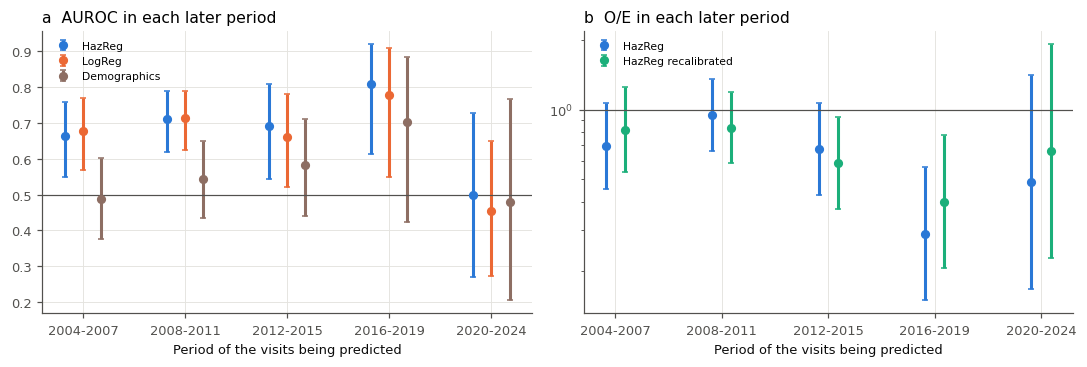

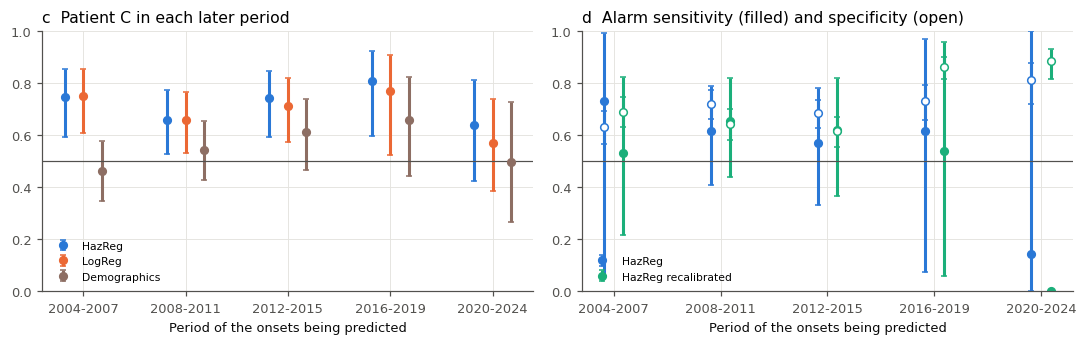

**What this means.**

* **The ranking holds up in later years.** Pooled over periods, HazReg's AUROC is 0.687, and the next
  period's AUROC is expected to lie between 0.54 and 0.80. Demographics alone reach
  0.540. HazReg's advantage over them is +0.136 (+0.069 to +0.203).
* **LogReg: pooled AUROC 0.667**, against 0.687 for HazReg. It transports less well.
  Fitted on data cut at each period's start, LogReg can learn only from visits that already have 24 months of
  follow-up, so it loses the most recent years. HazReg learns from their partial follow-up too.
* **The level of risk does not carry over.** As fitted, HazReg over-predicts later periods: pooled O/E
  0.63 (0.43-0.91), with a prediction interval of
  0.19-2.05. Patients are ranked correctly, but everyone's risk is set too high.
* **At the patient level the ranking also holds.** Pooled time-matched patient C is
  0.711 (0.641-0.773),
  +0.160 (+0.080 to +0.240) above demographics. The alarm of the model as
  fitted caught 60 % of later onsets with a specificity of
  71 %. Because the level is set too high, the as-fitted alarm errs towards flagging: more patients caught, and more patients flagged who keep working.

In [26]:
"""Forward-chaining validation by calendar period, with temporal recalibration inside each training set."""


def period_shift(eta, w0, w1, rows=None, d1=D1, d2=D2):
    """Temporal recalibration: the two baseline log-hazards re-estimated on the person-time inside [w0, w1), with
    the predictor effects (eta) fixed. Closed form for a Poisson model with offset: log(events / expected)."""
    use = np.zeros(N_LAND, bool)
    use[np.arange(N_LAND) if rows is None else rows] = True
    expo = np.clip(np.minimum(INT_END, w1) - np.maximum(LAND_T, w0), 0, None) / 365.25 * use
    inn = (INT_END > w0) & (INT_END <= w1) & use
    obs = np.array([d1[inn].sum(), d2[inn].sum()])
    exp_ = np.array([np.sum(np.exp(eta[:, c]) * expo) for c in range(2)])
    return np.log(np.maximum(obs, 0.5) / exp_), obs, expo.sum()


RECAL_W = lambda end: (end - RECAL_LAG_MONTHS * MONTH_DAYS - RECAL_YEARS * 365.25, end - RECAL_LAG_MONTHS * MONTH_DAYS)


def _iecv_period(a, b):
    cut, cut_b = _day(a), _day(b)
    tr = np.flatnonzero(LAND_T < cut)
    end = np.minimum(INT_END, cut)
    dt = (end - LAND_T) / 365.25
    keep = INT_END <= cut
    d1, d2 = D1 * keep, D2 * keep
    te = np.flatnonzero((LAND_T >= cut) & (LAND_T < cut_b))
    m = fit_procedure(tr, dt=dt, d1=d1, d2=d2, seed=SEED + a)
    w0, w1 = RECAL_W(cut)
    shift, ev, py = period_shift(predict_eta(m), w0, w1, rows=tr, d1=d1, d2=d2)
    md = fit_procedure(tr, DEMO_VARS, (), dt=dt, d1=d1, d2=d2, seed=SEED + a)
    # LogReg: 24-month labels as known at the cut
    t_c = np.minimum(T_ALL, cut - LAND_T)
    c_c = np.where(LAND_T + T_ALL <= cut, C_ALL, 0)
    yv, wv = ipcw_weights(t_c, c_c, rows=tr)
    yf, wf = np.zeros(N_LAND), np.zeros(N_LAND)
    yf[tr], wf[tr] = yv, wv
    ml = fit_logreg(tr, y=yf, w=wf, seed=SEED + a)
    eta_te = predict_eta(m, te)
    return {"a": a, "b": b, "te": te, "n_tr": len(tr), "eta": eta_te, "shift": shift, "shift_events": ev,
            "shift_py": py, "Demographics": cif(predict_eta(md, te)), "LogReg": predict_logreg(ml, te)}


if "iecv" not in STATE:
    STATE["iecv"] = Parallel(n_jobs=min(N_JOBS, len(PERIODS)))(delayed(_iecv_period)(a, b) for a, b in PERIODS)
    _save_state()


def dl_pool(est, se):
    """DerSimonian-Laird random-effects pool: estimate, 95 % CI, tau^2, 95 % prediction interval."""
    est, se = np.asarray(est, float), np.asarray(se, float)
    w = 1 / se ** 2
    fe = np.sum(w * est) / w.sum()
    q = np.sum(w * (est - fe) ** 2)
    k = len(est)
    tau2 = max(0.0, (q - (k - 1)) / (w.sum() - np.sum(w ** 2) / w.sum()))
    wr = 1 / (se ** 2 + tau2)
    mu = np.sum(wr * est) / wr.sum()
    se_mu = np.sqrt(1 / wr.sum())
    t = stats.t.ppf(0.975, max(k - 2, 1))
    return mu, mu - 1.96 * se_mu, mu + 1.96 * se_mu, tau2, mu - t * np.sqrt(tau2 + se_mu ** 2), \
        mu + t * np.sqrt(tau2 + se_mu ** 2)


def _fin_sd(x):
    """SD of the finite bootstrap values (a resample without onsets gives O/E = 0, log = -inf)."""
    x = np.asarray(x, float)
    return float(np.std(x[np.isfinite(x)], ddof=1))


IECV_MODELS = ["HazReg", "HazReg recalibrated", "LogReg", "Demographics"]
_rows, _diff = [], []
for r in STATE["iecv"]:
    te = r["te"]
    y, w = ipcw_weights(T_ALL, C_ALL, rows=te)
    Wb = W_BOOT[:, ROW_PIDX[te]]
    preds = {"HazReg": cif(r["eta"]), "HazReg recalibrated": cif(r["eta"] + r["shift"][None, :]),
             "LogReg": r["LogReg"], "Demographics": r["Demographics"]}
    arrs = {}
    for name, p in preds.items():
        A = metric_arrays(p, Wb, y, w, ERA_LAB[te])
        arrs[name] = A
        _rows.append({"Period": f"{r['a']}-{r['b'] - 1}", "Model": name, "Training landmarks": r["n_tr"],
                      "Test landmarks": len(te), "Onsets within 24 mo": int((y * (w > 0)).sum()),
                      "AUROC": A["AUROC"][0], "AUROC SE (logit)": _fin_sd(_logit(A["AUROC"][1:])),
                      "O/E": A["O/E"][0], "O/E SE (log)": _fin_sd(np.log(A["O/E"][1:])),
                      "Calibration slope": wcalibration(y, p, w)[0], "IPA": A["IPA"][0]})
    d = arrs["HazReg"]["AUROC"] - arrs["Demographics"]["AUROC"]
    _diff.append({"Period": f"{r['a']}-{r['b'] - 1}", "est": d[0], "se": _fin_sd(d[1:])})
IECV_ALL = pd.DataFrame(_rows)
IECV = IECV_ALL[IECV_ALL["Model"] == "HazReg"].set_index("Period")
IECV_POOLED = {}
for name in IECV_MODELS:
    t = IECV_ALL[IECV_ALL["Model"] == name]
    pa = dl_pool(_logit(t["AUROC"]), t["AUROC SE (logit)"])
    po = dl_pool(np.log(t["O/E"]), t["O/E SE (log)"])
    IECV_POOLED[name] = {"AUROC": tuple(_expit(v) for v in (pa[0], pa[1], pa[2], pa[4], pa[5])),
                         "O/E": tuple(np.exp(v) for v in (po[0], po[1], po[2], po[4], po[5]))}
_dd = pd.DataFrame(_diff)
_pd = dl_pool(_dd["est"], _dd["se"])
IECV_DIFF = (_pd[0], _pd[1], _pd[2])

_show = IECV_ALL.pivot(index="Period", columns="Model", values=["AUROC", "O/E"]).round(3)
_show = _show.reindex(columns=[(m_, n_) for m_ in ["AUROC", "O/E"] for n_ in IECV_MODELS if (m_, n_) in _show.columns])
display(_show)
_pool_tab = pd.DataFrame({name: {f"{k} pooled (95% CI)": f"{v[0]:.3f} ({v[1]:.3f}-{v[2]:.3f})" for k, v in d.items()}
                          | {f"{k} prediction interval": f"{v[3]:.3f}-{v[4]:.3f}" for k, v in d.items()}
                          for name, d in IECV_POOLED.items()}).T
display(_pool_tab)
print(f"Temporal AUROC, HazReg − Demographics, pooled: {IECV_DIFF[0]:+.3f} ({IECV_DIFF[1]:+.3f} to {IECV_DIFF[2]:+.3f})")
_ph, _pr = IECV_POOLED["HazReg"], IECV_POOLED["HazReg recalibrated"]
record("H5a", "The ranking carries over to later years", "Temporal AUROC, HazReg − Demographics, pooled", IECV_DIFF,
       "above0")
record("H5b", "The level of risk carries over without updating", "Temporal O/E, HazReg as fitted, pooled",
       _ph["O/E"][:3], "includes1", nd=2)
record("H5c", "Temporal recalibration restores the level", "Temporal O/E, HazReg recalibrated, pooled",
       _pr["O/E"][:3], "includes1", nd=2)

# ---- the same validation at the patient level: onsets in each period, time-matched controls, the period's
# predictions only (each period's alarm chains start at the period's first visit)
_ptp_rows, _ptp_arr = [], {}
for r in STATE["iecv"]:
    te = r["te"]
    per = f"{r['a']}-{r['b'] - 1}"
    use = np.zeros(N_LAND, bool); use[te] = True
    ev = build_pt_eval(use=use, onset_from=_day(r["a"]), onset_to=_day(r["b"]))
    if ev["n_onsets"] < 3:
        continue
    preds = {"HazReg": cif(r["eta"]), "HazReg recalibrated": cif(r["eta"] + r["shift"][None, :]),
             "LogReg": r["LogReg"], "Demographics": r["Demographics"]}
    for name, pv in preds.items():
        pf = np.full(N_LAND, np.nan); pf[te] = pv
        A = pt_metric_arrays(ev, pf, alarm_flags(np.nan_to_num(pf), mask=use))
        _ptp_arr[(per, name)] = A
        _ptp_rows.append({"Period": per, "Model": name, "Onsets": ev["n_onsets"],
                          **{k: A[k][0] for k in ["C", "Sensitivity", "Specificity"]},
                          **{f"{k} SE (logit)": _fin_sd(_logit(A[k][1:])) for k in ["C", "Sensitivity", "Specificity"]}})
IECV_PT = pd.DataFrame(_ptp_rows)


def _pool_prop(t, k):
    """Random-effects pool on the logit scale. Sensitivity (few onsets per period): a period at 0 or 1 is moved half a
    case inward and its SE floored at the binomial value."""
    se = t[f"{k} SE (logit)"].values
    if k != "Sensitivity":                                   # C and specificity rest on many controls
        return tuple(_expit(x) for x in np.array(dl_pool(_logit(t[k].values), se))[[0, 1, 2, 4, 5]])
    n = t["Onsets"].values
    v = np.clip(t[k].values, 0.5 / n, 1 - 0.5 / n)
    se = np.maximum(np.nan_to_num(se, nan=1.0), 1 / np.sqrt(n * v * (1 - v)))
    return tuple(_expit(x) for x in np.array(dl_pool(_logit(v), se))[[0, 1, 2, 4, 5]])


IECV_PT_POOLED = {name: {k: _pool_prop(IECV_PT[IECV_PT["Model"] == name], k) for k in ["C", "Sensitivity", "Specificity"]}
                  for name in IECV_MODELS}
_pd_pt = [{"est": _ptp_arr[(p_, "HazReg")]["C"][0] - _ptp_arr[(p_, "Demographics")]["C"][0],
           "se": _fin_sd(_ptp_arr[(p_, "HazReg")]["C"][1:] - _ptp_arr[(p_, "Demographics")]["C"][1:])}
          for p_ in IECV_PT["Period"].unique()]
_pdp = dl_pool([d["est"] for d in _pd_pt], [d["se"] for d in _pd_pt])
IECV_PT_DIFF = (_pdp[0], _pdp[1], _pdp[2])
display(IECV_PT.pivot(index="Period", columns="Model", values=["C", "Sensitivity", "Specificity"]).round(3)
        .reindex(columns=[(m_, n_) for m_ in ["C", "Sensitivity", "Specificity"] for n_ in IECV_MODELS]))
display(pd.DataFrame({name: {f"{k} pooled (95% CI)": f"{v[0]:.3f} ({v[1]:.3f}-{v[2]:.3f})" for k, v in d.items()}
                      for name, d in IECV_PT_POOLED.items()}).T)
print(f"Temporal patient C, HazReg − Demographics, pooled: {IECV_PT_DIFF[0]:+.3f} ({IECV_PT_DIFF[1]:+.3f} to "
      f"{IECV_PT_DIFF[2]:+.3f})")
record_pt("H5a", IECV_PT_DIFF)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
_per = list(IECV.index)
x = np.arange(len(_per))
for ax, k, models, se_k, tr, ref in [
        (axes[0], "AUROC", ["HazReg", "LogReg", "Demographics"], "AUROC SE (logit)", (_logit, _expit), 0.5),
        (axes[1], "O/E", ["HazReg", "HazReg recalibrated"], "O/E SE (log)", (np.log, np.exp), 1.0)]:
    f, finv = tr
    for j, name in enumerate(models):
        t = IECV_ALL[IECV_ALL["Model"] == name].set_index("Period").reindex(_per)
        est, se = f(t[k].values), t[se_k].values
        col = {"HazReg recalibrated": C3}.get(name, MODEL_COLORS.get(name))
        off = (j - (len(models) - 1) / 2) * 0.18
        ax.errorbar(x + off, t[k], yerr=[t[k] - finv(est - 1.96 * se), finv(est + 1.96 * se) - t[k]], fmt="o",
                    color=col, ms=5, capsize=2, label=name)
    ax.axhline(ref, color=INK_2, lw=0.8)
    ax.set_xticks(x, _per); ax.set_xlabel("Period of the visits being predicted")
    ax.set_title(f"{'a' if k == 'AUROC' else 'b'}  {k} in each later period", loc="left"); ax.legend(fontsize=7)
axes[1].set_yscale("log")
plt.tight_layout(); save_fig("fig05_temporal")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
_perp = list(IECV_PT["Period"].unique())
for ax, (keys, models, ttl) in zip(axes, [(["C"], ["HazReg", "LogReg", "Demographics"], "c  Patient C in each later period"),
                                         (["Sensitivity", "Specificity"], ["HazReg", "HazReg recalibrated"],
                                          "d  Alarm sensitivity (filled) and specificity (open)")]):
    for k in keys:
        for j, name in enumerate(models):
            t = IECV_PT[IECV_PT["Model"] == name].set_index("Period").reindex(_perp)
            est, se = _logit(t[k].values), t[f"{k} SE (logit)"].values
            col = {"HazReg recalibrated": C3}.get(name, MODEL_COLORS.get(name))
            off = (j - (len(models) - 1) / 2) * 0.18
            _lo = np.clip(t[k] - _expit(est - 1.96 * np.nan_to_num(se)), 0, None)
            _hi = np.clip(_expit(est + 1.96 * np.nan_to_num(se)) - t[k], 0, None)
            ax.errorbar(np.arange(len(_perp)) + off, t[k], yerr=[_lo, _hi],
                        fmt="o", color=col, mfc=col if k != "Specificity" else "white", ms=5, capsize=2,
                        label=name if k == keys[0] else None)
    ax.axhline(0.5, color=INK_2, lw=0.8)
    ax.set_xticks(np.arange(len(_perp)), _perp); ax.set_xlabel("Period of the onsets being predicted")
    ax.set_ylim(0, 1); ax.set_title(ttl, loc="left"); ax.legend(fontsize=7, loc="lower left")
plt.tight_layout(); save_fig("fig05b_temporal_patient")
_lr_p, _dm_p = IECV_POOLED["LogReg"]["AUROC"], IECV_POOLED["Demographics"]["AUROC"]
say(f"""
**What this means.**

* **The ranking holds up in later years.** Pooled over periods, HazReg's AUROC is {_ph['AUROC'][0]:.3f}, and the next
  period's AUROC is expected to lie between {_ph['AUROC'][3]:.2f} and {_ph['AUROC'][4]:.2f}. Demographics alone reach
  {_dm_p[0]:.3f}. HazReg's advantage over them is {IECV_DIFF[0]:+.3f} ({IECV_DIFF[1]:+.3f} to {IECV_DIFF[2]:+.3f}).
* **LogReg: pooled AUROC {_lr_p[0]:.3f}**, against {_ph['AUROC'][0]:.3f} for HazReg. {"It transports less well." if _lr_p[0] < _ph['AUROC'][0] - 0.01 else "It transports about as well."}
  Fitted on data cut at each period's start, LogReg can learn only from visits that already have 24 months of
  follow-up, so it loses the most recent years. HazReg learns from their partial follow-up too.
* **The level of risk does not carry over.** As fitted, HazReg over-predicts later periods: pooled O/E
  {_ph['O/E'][0]:.2f} ({_ph['O/E'][1]:.2f}-{_ph['O/E'][2]:.2f}), with a prediction interval of
  {_ph['O/E'][3]:.2f}-{_ph['O/E'][4]:.2f}. Patients are ranked correctly, but everyone's risk is set too high.
* **At the patient level{" the ranking also holds" if IECV_PT_DIFF[1] > 0 else ", the advantage over demographics is not clear"}.** Pooled time-matched patient C is
  {IECV_PT_POOLED['HazReg']['C'][0]:.3f} ({IECV_PT_POOLED['HazReg']['C'][1]:.3f}-{IECV_PT_POOLED['HazReg']['C'][2]:.3f}),
  {IECV_PT_DIFF[0]:+.3f} ({IECV_PT_DIFF[1]:+.3f} to {IECV_PT_DIFF[2]:+.3f}) above demographics. The alarm of the model as
  fitted caught {100 * IECV_PT_POOLED['HazReg']['Sensitivity'][0]:.0f} % of later onsets with a specificity of
  {100 * IECV_PT_POOLED['HazReg']['Specificity'][0]:.0f} %.{" Because the level is set too high, the as-fitted alarm errs towards flagging: more patients caught, and more patients flagged who keep working." if _ph['O/E'][0] < 1 else ""}
""")

## 4.3 Temporal recalibration: keeping the level up to date

> **The idea** (Booth, Riley et al., *Int J Epidemiol* 2020; extended to competing risks in 2023). Keep everything
> the model learned about *which* patients are at higher risk. Re-estimate only *how high* the baseline risk is,
> from the most recent years. In HazReg this changes two numbers, the baseline log-hazard of each exit type. All
> patients' risks then move together while their ranking stays the same.

**The rule.** The baselines are re-estimated on the person-time of the most recent
**4 years**, ending **12 months** before the data end. The lag leaves time for
sick-leave onsets to be confirmed (Section 1.5.2).

**The test.** Section 4.2 applied exactly this rule inside each period's training data (the 4 years
before the period started, ending 12 months earlier) and compared the recalibrated predictions
with what happened next. That makes it a fair test of the rule as it would be used in practice.

> **An important caution.** Recalibration adapts the model to the outcomes *as currently recorded*. If recent
> onsets are under-recorded (Part V), a recalibrated model predicts the risk of a *recorded* onset, which is lower
> than the true risk. The deployed risks should be read as a floor, and the tiers are more robust than the
> absolute numbers.

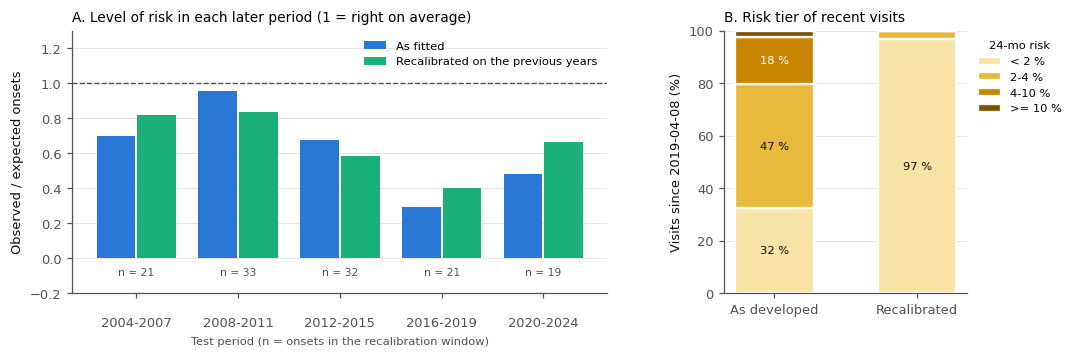

,Visits flagged (%),Patients ever flagged (%),Alarm episodes per 100 person-years,Episode PPV (%)
"Patient alarm, visits since 2019-04-08",,,,
As developed,37.6,37.0,3.8,3.1 (0.0-10.3)
Recalibrated (deployed),0.3,0.2,0.0,0.0 (0.0-0.0)


**What this means.**

* **In the fair test, recalibration brings the level closer to what happened.**
  Pooled O/E moves from 0.63 as fitted to 0.69 after recalibration (95 % CI
  0.54-0.89; prediction interval 0.40-1.20). The ranking
  (AUROC) is unchanged by construction.
* **The deployed model.** Re-estimated on 2019-04-08 to 2023-04-08 (5 onsets in 1,522
  person-years), the baseline hazard of work disability is multiplied by **0.20**, and that
  of other exits by 0.21. The average predicted 24-month risk for recent visits goes from
  3.2 % to 0.7 %. More recent visits fall in the
  lowest tier (32 % → 97 %).

* **The patient alarm.** In the fair test, recalibration changes the alarm's balance: pooled sensitivity
  60 % → 58 %, specificity
  71 % → 75 %. Among recent visits the deployed model
  would flag 0 % of patients, against
  37 % with the model as developed, and raise
  0.0 rather than
  3.8 new alarms per 100 person-years.

**Recommendation: do not use the recalibrated risks for the tiers yet.** In the fair test, recalibration did not restore the level: observed risk kept falling after each window, so a baseline estimated on the previous 4 years still lagged behind. The deployed shift also rests on only 5 recorded onsets, from the years where under-recording is most likely (Part V). Applied to the tiers, it would put 97 % of recent visits in the lowest tier. Until chart review or tracing (Part VII) shows whether the recent fall is real:

* **Assign tiers with the model as developed.** Its ranking transports (H5a), and its tiers keep their *relative* meaning.
* **Report the recalibrated risk beside it** as the risk of a *recorded* onset under current recording practice: a lower bound, not a best estimate.
* **Re-run the recalibration test** when a new extract arrives (Section 7.1). The frozen file holds both the model as developed and the recalibrated model.

In [27]:
"""Temporal recalibration: the test inside each period, and the deployed (recalibrated) final model."""
_rc = IECV_ALL.pivot(index="Period", columns="Model", values="O/E")[["HazReg", "HazReg recalibrated"]]
_rc["Baseline shift (onset HR)"] = [np.exp(r["shift"][0]) for r in STATE["iecv"]]
_rc["Onsets in the recalibration window"] = [int(r["shift_events"][0]) for r in STATE["iecv"]]
save_table(_rc.round(2), "recalibration_by_period")

W0, W1 = RECAL_W(float((DATA_END_DATE - pd.Timestamp("1970-01-01")).days))
DEPLOY_SHIFT, _dev, _dpy = period_shift(ETA_FULL, W0, W1)
ETA_DEPLOY = ETA_FULL + DEPLOY_SHIFT[None, :]
P_DEPLOY = cif(ETA_DEPLOY)
_wdate = lambda d: (pd.Timestamp("1970-01-01") + pd.Timedelta(days=d)).date()
_recent = LAND_T >= W0
_tiers = lambda p: pd.Series(np.digitize(p, [t[1] for t in RISK_TIERS[:-1]])).value_counts(normalize=True) \
    .reindex(range(len(RISK_TIERS))).fillna(0).values * 100
DEPLOY_TABLE = pd.DataFrame({"As developed": _tiers(P_FULL[_recent]), "Recalibrated (deployed)": _tiers(P_DEPLOY[_recent])},
                            index=[t[2] for t in RISK_TIERS]).round(1)
DEPLOY_TABLE.index.name = f"Tier: % of visits since {_wdate(W0)}"
save_table(DEPLOY_TABLE, "deployment_tiers")
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.1), gridspec_kw={"width_ratios": [2.2, 1], "wspace": 0.3})
ax = axes[0]
_xp = np.arange(len(_rc))
ax.bar(_xp - 0.2, _rc["HazReg"], 0.38, color=C1, label="As fitted")
ax.bar(_xp + 0.2, _rc["HazReg recalibrated"], 0.38, color=C3, label="Recalibrated on the previous years")
ax.axhline(1, color=INK_2, ls="--", lw=0.9)
for i, n_ in enumerate(_rc["Onsets in the recalibration window"]):
    ax.text(i, -0.1, f"n = {n_}", ha="center", fontsize=7, color=INK_2)
ax.set_xticks(_xp, _rc.index); ax.set_ylim(-0.2, max(1.3, _rc[["HazReg", "HazReg recalibrated"]].values.max() * 1.15))
ax.tick_params(axis="x", pad=12); ax.grid(axis="x", visible=False)
ax.set_ylabel("Observed / expected onsets"); ax.legend(loc="upper right", fontsize=7.5)
ax.set_xlabel("Test period (n = onsets in the recalibration window)", fontsize=7.5, color=INK_2)
ax.set_title("A. Level of risk in each later period (1 = right on average)", loc="left", fontsize=9)
ax = axes[1]
for j, col in enumerate(DEPLOY_TABLE.columns):
    bottom = 0.0
    for k, (tier, v) in enumerate(DEPLOY_TABLE[col].items()):
        ax.bar(j, v, 0.55, bottom=bottom, color=TIER_COLORS[k], edgecolor="white", linewidth=1.5,
               label=tier if j == 0 else None)
        if v >= 6:
            ax.text(j, bottom + v / 2, f"{v:.0f} %", ha="center", va="center", fontsize=7.5,
                    color="white" if k >= 2 else INK)
        bottom += v
ax.set_xticks([0, 1], ["As developed", "Recalibrated"]); ax.set_ylim(0, 100); ax.grid(axis="x", visible=False)
ax.set_ylabel(f"Visits since {_wdate(W0)} (%)")
ax.set_title("B. Risk tier of recent visits", loc="left", fontsize=9)
ax.legend(title="24-mo risk", loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=7.5, title_fontsize=7.5)
save_fig("recalibration")
FLAGS_FULL_DEV, FLAGS_DEPLOY = alarm_flags(P_FULL), alarm_flags(P_DEPLOY)
DEPLOY_ALARM = pd.DataFrame({"As developed": alarm_burden(FLAGS_FULL_DEV, sel=_recent),
                             "Recalibrated (deployed)": alarm_burden(FLAGS_DEPLOY, sel=_recent)}).T
DEPLOY_ALARM["Episode PPV (%)"] = DEPLOY_ALARM["Episode PPV (%)"].map(lambda t: f"{t[0]:.1f} ({t[1]:.1f}-{t[2]:.1f})")
for _c in DEPLOY_ALARM.columns.drop("Episode PPV (%)"):
    DEPLOY_ALARM[_c] = DEPLOY_ALARM[_c].astype(float)
DEPLOY_ALARM.index.name = f"Patient alarm, visits since {_wdate(W0)}"
display(DEPLOY_ALARM.round(1))
save_table(DEPLOY_ALARM, "deployment_alarm")
_rf = IECV_PT_POOLED["HazReg"]; _rr = IECV_PT_POOLED["HazReg recalibrated"]
_gain = np.abs(np.log(np.array(_ph["O/E"][0]))) - np.abs(np.log(np.array(_pr["O/E"][0])))
if HYP["H5c"]["_met"]:
    _deploy_advice = ("**Recommendation.** In the fair test, recalibration restored the level. Deploy the recalibrated "
                      "model and re-estimate the two baselines every few years with the same rule. If chart review or "
                      "tracing (Part VII) shows that recent onsets are being missed, relax the recalibration: it would "
                      "then be learning the missing records rather than a real fall in risk.")
else:
    _deploy_advice = (
        f"**Recommendation: do not use the recalibrated risks for the tiers yet.** In the fair test, recalibration "
        f"did not restore the level: observed risk kept falling after each window, so a baseline estimated on the "
        f"previous {RECAL_YEARS} years still lagged behind. The deployed shift also rests on only {int(_dev[0])} "
        f"recorded onsets, from the years where under-recording is most likely (Part V). Applied to the tiers, it would "
        f"put {DEPLOY_TABLE.iloc[0, 1]:.0f} % of recent visits in the lowest tier. Until chart review or tracing "
        f"(Part VII) shows whether the recent fall is real:\n\n"
        f"* **Assign tiers with the model as developed.** Its ranking transports (H5a), and its tiers keep their "
        f"*relative* meaning.\n"
        f"* **Report the recalibrated risk beside it** as the risk of a *recorded* onset under current recording "
        f"practice: a lower bound, not a best estimate.\n"
        f"* **Re-run the recalibration test** when a new extract arrives (Section 7.1). The frozen file holds both "
        f"the model as developed and the recalibrated model.")
say(f"""
**What this means.**

* **In the fair test, recalibration {"brings the level closer to what happened" if _gain > 0 else "does not improve the level"}.**
  Pooled O/E moves from {_ph['O/E'][0]:.2f} as fitted to {_pr['O/E'][0]:.2f} after recalibration (95 % CI
  {_pr['O/E'][1]:.2f}-{_pr['O/E'][2]:.2f}; prediction interval {_pr['O/E'][3]:.2f}-{_pr['O/E'][4]:.2f}). The ranking
  (AUROC) is unchanged by construction.
* **The deployed model.** Re-estimated on {_wdate(W0)} to {_wdate(W1)} ({int(_dev[0])} onsets in {_dpy:,.0f}
  person-years), the baseline hazard of work disability is multiplied by **{np.exp(DEPLOY_SHIFT[0]):.2f}**, and that
  of other exits by {np.exp(DEPLOY_SHIFT[1]):.2f}. The average predicted 24-month risk for recent visits goes from
  {100 * P_FULL[_recent].mean():.1f} % to {100 * P_DEPLOY[_recent].mean():.1f} %. More recent visits fall in the
  lowest tier ({DEPLOY_TABLE.iloc[0, 0]:.0f} % → {DEPLOY_TABLE.iloc[0, 1]:.0f} %).

* **The patient alarm.** In the fair test, recalibration changes the alarm's balance: pooled sensitivity
  {100 * _rf['Sensitivity'][0]:.0f} % → {100 * _rr['Sensitivity'][0]:.0f} %, specificity
  {100 * _rf['Specificity'][0]:.0f} % → {100 * _rr['Specificity'][0]:.0f} %. Among recent visits the deployed model
  would flag {DEPLOY_ALARM.iloc[1]['Patients ever flagged (%)']:.0f} % of patients, against
  {DEPLOY_ALARM.iloc[0]['Patients ever flagged (%)']:.0f} % with the model as developed, and raise
  {DEPLOY_ALARM.iloc[1]['Alarm episodes per 100 person-years']:.1f} rather than
  {DEPLOY_ALARM.iloc[0]['Alarm episodes per 100 person-years']:.1f} new alarms per 100 person-years.

{_deploy_advice}
""")

---
# Part V. Could the results be an artefact?

The data raise one central worry: **exits from work that happen but never reach the record**, especially in recent
years and among patients who stop attending. This part asks how much that could change the conclusions, in three
ways:

1. **A simulation where the truth is known** (5.1): do the methods recover the truth, and what would missing onsets
   look like?
2. **Patients who left the clinic while employed** (5.2): how many would have to be hidden onsets to explain the
   low recent risk?
3. **A broader outcome** (5.3): does the model still work if early retirement, homemaking and "other" exits count
   as work disability?

## 5.1 A simulation with known truth (plasmode)

> **The idea.** Keep the real patients, visits and inputs, but replace the outcomes with outcomes drawn from the
> model's own hazards. The true risk and true 24-month status of every visit are then known, and the analysis can
> be checked against them.

| Scenario | What is simulated | What it answers |
|:--|:--|:--|
| **A** | Outcomes recorded whenever they happen within follow-up | Are the performance estimators unbiased on this data structure? |
| **B** | A quarter of onsets, in any era, end follow-up unrecorded (the patient stops attending) | What does uniform under-recording do? |
| **C** | Half of onsets from 2015 on are lost this way | Can recent under-recording alone produce the observed fall in O/E? |

A refit check under scenario A also fits the model on half of the simulated patients and tests it on the other
half. The calibration slope should then be near 1 and the estimated AUROC near the truth.

In [28]:
"""Plasmode simulation: outcomes drawn from the final model on the real landmarks and observation windows."""
LAM = np.exp(np.clip(ETA_FULL, -30, 5)) / 365.25                  # per day
_tot = LAM.sum(1)
_seg = np.where(_same_next, _next - LAND_T, np.inf)                # landmark to the next landmark (days)
_admin_end = LAND_T + land["admin_days"].values
_last_seen = ((land["last_status_date"] - pd.Timestamp("1970-01-01")).dt.days).values.astype(float)
OBS_END = pd.Series(np.minimum(_last_seen, _admin_end)).groupby(PID_ALL).transform("min").values
_segh = np.where(np.isinf(_seg), 0.0, _tot * _seg)               # cumulative hazard of each landmark's segment
_cum_start = pd.Series(_segh).groupby(PID_ALL).cumsum().values - _segh
_cum_end = np.where(np.isinf(_seg), np.inf, _cum_start + _segh)  # the last landmark's hazard continues


def simulate(rng, q_all=0.0, q_from_2015=0.0):
    """One plasmode replicate. Returns kept rows, observed (time, cause), true 24-month label, interval arrays."""
    E = rng.exponential(1.0, P_N)[ROW_PIDX]
    hit = (_cum_end >= E) & (E >= _cum_start)
    j = pd.Series(np.where(hit, np.arange(N_LAND), N_LAND)).groupby(PID_ALL).transform("min").values
    t_ev = LAND_T[np.minimum(j, N_LAND - 1)] + (E - _cum_start[np.minimum(j, N_LAND - 1)]) / \
        _tot[np.minimum(j, N_LAND - 1)]
    jj = np.minimum(j, N_LAND - 1)
    u = rng.uniform(size=P_N)[ROW_PIDX]
    cause_true = np.where(u < LAM[jj, 0] / _tot[jj], 1, 2)
    keep = np.arange(N_LAND) <= j
    obs = t_ev <= OBS_END
    ev_year = 1970 + t_ev / 365.25
    lose = (cause_true == 1) & obs & (rng.uniform(size=P_N)[ROW_PIDX] <
                                      np.where(ev_year >= 2015, max(q_all, q_from_2015), q_all))
    end_abs = np.where(obs, t_ev, OBS_END)
    cause_obs = np.where(obs & ~lose, cause_true, 0)
    T = end_abs - LAND_T
    y_true = ((cause_true == 1) & (t_ev - LAND_T <= HORIZON_DAYS)).astype(float)
    nxt_kept = np.r_[keep[1:] & _same_next[:-1], False]
    iend = np.where(nxt_kept, np.minimum(_next, end_abs), end_abs)
    dt = np.clip(iend - LAND_T, 1e-6, None) / 365.25
    last_kept = keep & ~nxt_kept
    d1 = (last_kept & (cause_obs == 1)).astype(float)
    d2 = (last_kept & (cause_obs == 2)).astype(float)
    return keep & (T > 0), T, cause_obs, y_true, dt, d1, d2, np.where(obs, cause_true, 0)


def _sim_metrics(k, T, Cc, y_true, p):
    rows = np.flatnonzero(k)
    y, w = ipcw_weights(T, Cc, rows=rows)
    A = metric_arrays(p[rows], np.ones((1, len(rows))), y, w, ERA_LAB[rows])
    one = np.ones((1, len(rows)))
    ora = wauc(y_true[rows], p[rows], one)[0]
    out = {"AUROC estimated": A["AUROC"][0], "AUROC true": ora, "O/E estimated": A["O/E"][0],
           "O/E true": y_true[rows].mean() / p[rows].mean()}
    for a, b in PERIODS[2:]:
        kp = (LAND_T[rows] >= _day(a)) & (LAND_T[rows] < _day(b))
        out[f"O/E {a}-{b - 1}"] = np.sum((w * y)[kp]) / kp.sum() / p[rows][kp].mean()
        out[f"O/E {a}-{b - 1} true"] = y_true[rows][kp].mean() / p[rows][kp].mean()
    return out


SCENARIOS = {"A: independent censoring": {}, "B: 25% of onsets unrecorded": {"q_all": 0.25},
             "C: 50% of onsets unrecorded from 2015": {"q_from_2015": 0.5}}
if "plasmode" not in STATE:
    rng = np.random.RandomState(SEED + 3)
    res = {s: [] for s in SCENARIOS}
    for r in range(SIM_REPS):
        for s, kw in SCENARIOS.items():
            res[s].append(_sim_metrics(*simulate(rng, **kw)[:4], P_FULL))
    # refit check (scenario A): fit on half the patients with the final model's penalties, evaluate the other half
    refit = []
    for r in range(max(2, SIM_REPS // 10)):
        k, T, Cc, y_true, dt, d1, d2, _ = simulate(rng)
        half = rng.permutation(P_N) < P_N // 2
        tr = np.flatnonzero(k & half[ROW_PIDX]); te = np.flatnonzero(k & ~half[ROW_PIDX])
        m = fit_procedure(tr, dt=dt, d1=d1, d2=d2, alphas=FINAL["alphas"])
        p_te = cif(predict_eta(m, te))
        y, w = ipcw_weights(T, Cc, rows=te)
        refit.append({"AUROC estimated": metric_arrays(p_te, np.ones((1, len(te))), y, w, ERA_LAB[te])["AUROC"][0],
                      "AUROC true": wauc(y_true[te], p_te, np.ones((1, len(te))))[0],
                      "Calibration slope estimated": wcalibration(y, p_te, w)[0],
                      "Calibration slope true": wcalibration(y_true[te], p_te, np.ones(len(te)))[0]})
    STATE["plasmode"] = {"res": {s: pd.DataFrame(v) for s, v in res.items()}, "refit": pd.DataFrame(refit)}
    _save_state()
PLASMODE = STATE["plasmode"]
_tab = {}
for s, d in PLASMODE["res"].items():
    _tab[s] = {"AUROC: estimated - true": (d["AUROC estimated"] - d["AUROC true"]).mean(),
               "O/E estimated (mean)": d["O/E estimated"].mean(), "O/E true (mean)": d["O/E true"].mean()}
    _tab[s].update({c: d[c].mean() for c in d.columns if c.startswith("O/E 20") and not c.endswith("true")})
PLASMODE_TABLE = pd.DataFrame(_tab).T.round(3)
display(PLASMODE_TABLE)
_rf = PLASMODE["refit"].mean()
_obs_oe = IECV["O/E"]
_pc_ = PLASMODE_TABLE.loc["C: 50% of onsets unrecorded from 2015"]
_c1619 = [c for c in PLASMODE_TABLE.columns if c.startswith("O/E 2016")][0]

# ---- the patient-level evaluation in the same simulation: estimated (recorded onsets) vs true (every onset)
if "plasmode_pt" not in STATE:
    rng = np.random.RandomState(SEED + 4)
    _one = np.ones((1, P_N), np.float32)
    out = []
    for r in range(SIM_REPS):
        for sname in ["A: independent censoring", "C: 50% of onsets unrecorded from 2015"]:
            k, T, Cc, _, _, _, _, Ct = simulate(rng, **SCENARIOS[sname])
            for lab, CC in [("estimated", Cc), ("true", Ct)]:
                ev = build_pt_eval(T=T, C=CC, use=k, atrisk=k)
                A = pt_metric_arrays(ev, P_FULL, FLAGS_FULL, W=_one)
                out.append({"Scenario": sname, "Version": lab, "Onsets": ev["n_onsets"],
                            **{m_: A[m_][0] for m_ in ["C", "Sensitivity", "Specificity"]}})
    STATE["plasmode_pt"] = pd.DataFrame(out)
    _save_state()
PLASMODE_PT = STATE["plasmode_pt"].groupby(["Scenario", "Version"]).mean().round(3).unstack("Version")
display(PLASMODE_PT)
_ppa, _ppc = PLASMODE_PT.loc["A: independent censoring"], PLASMODE_PT.loc["C: 50% of onsets unrecorded from 2015"]
say(f"""
**What this means.**

* **The methods work on this data structure.** Under independent censoring, the estimated AUROC is off by
  {PLASMODE_TABLE.iloc[0]['AUROC: estimated - true']:+.3f} on average. In the refit check, the estimated AUROC is
  {_rf['AUROC estimated']:.3f} against a true {_rf['AUROC true']:.3f}, and the calibration slope is
  {_rf['Calibration slope estimated']:.2f} against {_rf['Calibration slope true']:.2f}.
* **Missing onsets damage calibration, not ranking.** When half of the onsets from 2015 go unrecorded, the 2016-19
  O/E drops to {_pc_[_c1619]:.2f} while the AUROC barely moves. The real data show {_obs_oe.get('2016-2019', np.nan):.2f}
  for that period. Under-recording on this scale is therefore *enough* to produce the observed pattern, although
  the simulation cannot prove that it happened.
* **The patient-level evaluation.** Under independent censoring
  the estimated patient C is {_ppa[('C', 'estimated')]:.3f} against a true {_ppa[('C', 'true')]:.3f}, and the alarm's
  sensitivity {_ppa[('Sensitivity', 'estimated')]:.2f} against {_ppa[('Sensitivity', 'true')]:.2f}. With half of the
  recent onsets lost, the estimates are {_ppc[('C', 'estimated')]:.3f} (true {_ppc[('C', 'true')]:.3f}) and
  {_ppc[('Sensitivity', 'estimated')]:.2f} (true {_ppc[('Sensitivity', 'true')]:.2f}), with specificity
  {_ppc[('Specificity', 'estimated')]:.2f} against {_ppc[('Specificity', 'true')]:.2f}. Lost onsets put hidden cases
  among the controls, so any bias they cause shows in the specificity and the patient C, not in the sensitivity.
""")

,AUROC: estimated - true,O/E estimated (mean),O/E true (mean),O/E 2012-2015,O/E 2016-2019,O/E 2020-2024
A: independent censoring,-0.003,0.983,0.978,0.991,1.007,0.652
B: 25% of onsets unrecorded,-0.003,0.725,0.962,0.759,0.737,0.501
C: 50% of onsets unrecorded from 2015,0.011,0.815,0.959,0.721,0.484,0.305


Onsets                  C        Sensitivity        Specificity       
Version                               estimated     true estimated   true   estimated   true   estimated   true
Scenario                                                                                                       
A: independent censoring                121.070  121.070     0.675  0.675       0.586  0.586       0.612  0.612
C: 50% of onsets unrecorded from 2015   100.425  118.985     0.681  0.676       0.607  0.587       0.601  0.612

**What this means.**

* **The methods work on this data structure.** Under independent censoring, the estimated AUROC is off by
  -0.003 on average. In the refit check, the estimated AUROC is
  0.623 against a true 0.630, and the calibration slope is
  0.76 against 0.81.
* **Missing onsets damage calibration, not ranking.** When half of the onsets from 2015 go unrecorded, the 2016-19
  O/E drops to 0.48 while the AUROC barely moves. The real data show 0.29
  for that period. Under-recording on this scale is therefore *enough* to produce the observed pattern, although
  the simulation cannot prove that it happened.
* **The patient-level evaluation.** Under independent censoring
  the estimated patient C is 0.675 against a true 0.675, and the alarm's
  sensitivity 0.59 against 0.59. With half of the
  recent onsets lost, the estimates are 0.681 (true 0.676) and
  0.61 (true 0.59), with specificity
  0.60 against 0.61. Lost onsets put hidden cases
  among the controls, so any bias they cause shows in the specificity and the patient C, not in the sensitivity.

## 5.2 Patients who left the clinic while employed: a tipping-point analysis

> **The question.** A patient last recorded as working who stops attending is counted as event-free. If some of
> them actually left work, how many would it take to explain the low risk observed in recent years?

A share *q* of these patients is given an onset 6 months after their last visit. They are chosen either at random
or in proportion to their predicted risk. The cross-validated predictions are then re-evaluated. *q* is raised until
the recent period's O/E reaches about 1: that is the tipping point.

In [29]:
"""Tipping point: imputed onsets among patients who left the clinic while employed."""
P_MAIN = P_CV["HazReg"]
_lrows = np.flatnonzero(np.isin(PID_ALL, list(LEFT_CLINIC_PIDS)) & (C_ALL == 0) &
                        (land["exit_type"].values == "end_of_follow_up"))
_lpids = np.unique(PID_ALL[_lrows])
_p_last = pd.Series(P_MAIN[_lrows], index=PID_ALL[_lrows]).groupby(level=0).last().reindex(_lpids).values


def _tip_eval(T, Cc):
    y, w = ipcw_weights(T, Cc)
    A = metric_arrays(P_MAIN, np.ones((1, N_LAND)), y, w)
    out = {"AUROC": A["AUROC"][0], "O/E": A["O/E"][0]}
    for a, b in PERIODS[1:]:
        k = (LAND_T >= _day(a)) & (LAND_T < _day(b))
        out[f"O/E {a}-{b - 1}"] = np.sum((w * y)[k]) / k.sum() / P_MAIN[k].mean()
    return out


if "tipping_v22" not in STATE:
    rng = np.random.RandomState(SEED + 5)
    out = []
    for q in [0.0, 0.1, 0.2, 0.3, 0.5]:
        for how in ["random", "risk-proportional"]:
            if q == 0 and how != "random":
                continue
            for _ in range(TIP_DRAWS if q > 0 else 1):
                pr = np.full(len(_lpids), q) if how == "random" else np.clip(q * _p_last / _p_last.mean(), 0, 1)
                chosen = set(_lpids[rng.uniform(size=len(_lpids)) < pr])
                T, Cc = T_ALL.copy(), C_ALL.copy()
                k = _lrows[np.isin(PID_ALL[_lrows], list(chosen))]
                newT = T[k] + 182.0
                ok = newT <= land["admin_days"].values[k]
                T[k[ok]], Cc[k[ok]] = newT[ok], 1
                ev = build_pt_eval(T=T, C=Cc)
                A = pt_metric_arrays(ev, P_MAIN, FLAGS["HazReg"], W=np.ones((1, P_N), np.float32))
                out.append({"q": q, "Selection": how, **_tip_eval(T, Cc),
                            **{f"Patient {m_}": A[m_][0] for m_ in ["C", "Sensitivity", "Specificity"]}})
    STATE["tipping_v22"] = pd.DataFrame(out)
    _save_state()
TIPPING = STATE["tipping_v22"].groupby(["q", "Selection"]).mean().round(3)
print(f"Patients who left the clinic while employed: {len(_lpids)} (of {P_N:,} with a landmark).")
display(TIPPING)
_tip = STATE["tipping_v22"].query("Selection == 'random'").groupby("q")["O/E 2016-2019"].mean()
_tpt = STATE["tipping_v22"].groupby(["q", "Selection"])[["Patient C", "Patient Sensitivity"]].mean()
Q_TIP = next((q for q, v in _tip.items() if v >= 0.9), None)
say(f"""
**What this means.** Of the {len(_lpids)} patients who stopped attending while recorded as working,
{"about " + format(Q_TIP, ".0%") if Q_TIP is not None else "more than half"} would need to have left work for health
reasons to bring the 2016-19 O/E up to about 1. That is a large share, but not an implausible one: work
disability is a common reason to stop attending a specialist clinic, and these patients were followed for years
before they left. The AUROC barely changes across scenarios, so **the ranking is robust to this uncertainty and the
absolute level is not.** Tracing these patients (Part VII) would settle the question. The same holds at the
patient level: as hidden onsets are added (up to half of the leavers), the patient C moves between
{_tpt['Patient C'].min():.3f} and {_tpt['Patient C'].max():.3f}, and the alarm's sensitivity between
{_tpt['Patient Sensitivity'].min():.2f} and {_tpt['Patient Sensitivity'].max():.2f}. With half of the leavers imputed,
patient C is {_tpt.loc[(0.5, 'risk-proportional'), 'Patient C']:.3f} when the imputed onsets follow the predicted risk
and {_tpt.loc[(0.5, 'random'), 'Patient C']:.3f} when they are random.
""")

Patients who left the clinic while employed: 296 (of 1,059 with a landmark).


AUROC    O/E  O/E 2008-2011  O/E 2012-2015  O/E 2016-2019  O/E 2020-2024  Patient C  Patient Sensitivity  Patient Specificity
q   Selection                                                                                                                                       
0.0 random             0.724  0.909          1.275          0.935          0.383          0.316      0.745                0.696                0.604
0.1 random             0.704  0.985          1.355          1.022          0.573          0.334      0.708                0.641                0.609
    risk-proportional  0.717  0.996          1.354          1.012          0.565          0.339      0.735                0.676                0.607
0.2 random             0.688  1.060          1.420          1.097          0.780          0.351      0.680                0.602                0.613
    risk-proportional  0.712  1.069          1.417          1.083          0.711          0.362      0.729                0.662                0.609
0.3 random             0.672  1.145          1.516          1.181          0.987          0.368      0.657                0.568                0.615
    risk-proportional  0.707  1.142          1.490          1.152          0.868          0.378      0.719                0.645                0.612
0.5 random             0.649  1.286          1.653          1.340          1.338          0.397      0.624                0.524                0.619
    risk-proportional  0.692  1.268          1.616          1.279          1.181          0.412      0.701                0.610                0.616

**What this means.** Of the 296 patients who stopped attending while recorded as working,
about 30% would need to have left work for health
reasons to bring the 2016-19 O/E up to about 1. That is a large share, but not an implausible one: work
disability is a common reason to stop attending a specialist clinic, and these patients were followed for years
before they left. The AUROC barely changes across scenarios, so **the ranking is robust to this uncertainty and the
absolute level is not.** Tracing these patients (Part VII) would settle the question. The same holds at the
patient level: as hidden onsets are added (up to half of the leavers), the patient C moves between
0.624 and 0.745, and the alarm's sensitivity between
0.52 and 0.70. With half of the leavers imputed,
patient C is 0.701 when the imputed onsets follow the predicted risk
and 0.624 when they are random.

## 5.3 A broader outcome: counting early retirement, homemaking and "other" exits

> **The question.** Some patients who leave work for "another reason" may in fact have left because of their
> health: an early retirement at 55, or becoming a homemaker after years of fatigue. Would the conclusions change
> if these exits counted as work disability?

Studies of work in SLE define the outcome in two ways. Some count only **health-attributed** exits (disability or
long sick leave), as here. Others count **any loss of employment**, such as the Lupus Outcomes Study (any
cessation of work) or the GOAL cohort (disability benefits or unemployment before 65). The sensitivity model sits
between the two:

| Exit | Main analysis | Sensitivity analysis |
|:--|:--|:--|
| Disabled, or sick leave ≥ 6 months | Work disability | Work disability |
| **Retired before 60** | Competing exit | **Work disability** |
| **Homemaker** | Competing exit | **Work disability** |
| **Other** | Competing exit | **Work disability** |
| Retired at 60-64, student, looking for work | Competing exit | Competing exit |

First, how do patients who took these exits look at their last working visit, compared with patients who became
work-disabled? Then the whole procedure (HazReg and the demographics model, same cross-validation) is rerun with
the broader outcome.

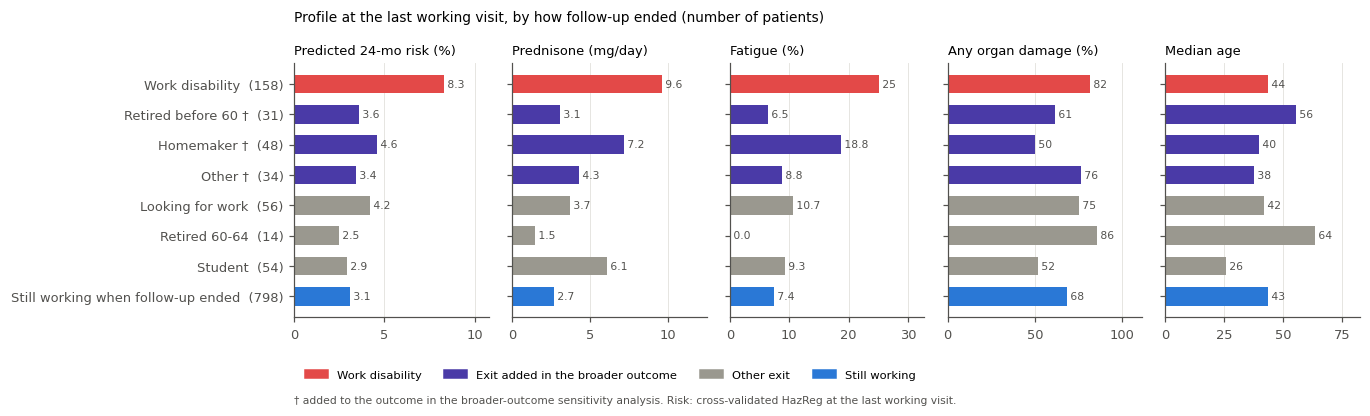

**What this means.** At their last working visit, patients who later became work-disabled had an average predicted
risk of 8.3 %, against 3.1 % for patients still
working when follow-up ended. Patients who **retired before 60** looked like those still working
(3.6 %): little prednisone, little fatigue, and a median age in the mid-fifties. Most
look like ordinary early retirement rather than disguised work disability. **Homemakers** and **other** exits sit in
between (4.6 % and 3.4 %), so some of them are probably health-related.
Adding all of them to the outcome mixes a minority of health-related exits with a majority that are not.

In [30]:
"""Who takes each kind of exit: risk profile at the last working visit before it."""
_age_end = land["age_at_record"].values + T_ALL / 365.25
_ex = land["exit_emp"].astype(object).fillna("").values
BROAD_FLAG = (C_ALL == 2) & (np.isin(_ex, list(BROAD_EXITS)) | ((_ex == "retired") & (_age_end < BROAD_RETIRE_BEFORE)))
_final = ~_cont                                                       # the interval that ends each follow-up
_grp = np.select([C_ALL == 1,
                  (C_ALL == 2) & (_ex == "retired") & (_age_end < BROAD_RETIRE_BEFORE),
                  (C_ALL == 2) & (_ex == "retired"),
                  (C_ALL == 2) & (_ex == "homemaker"), (C_ALL == 2) & (_ex == "other"),
                  (C_ALL == 2) & (_ex == "looking for work"), (C_ALL == 2) & (_ex == "student"),
                  C_ALL == 0],
                 ["Work disability", "Retired before 60 *", "Retired 60-64", "Homemaker *", "Other *",
                  "Looking for work", "Student", "Still working when follow-up ended"], "")
_pf = pd.DataFrame({"Group": _grp, "Age": _age_end, "Risk": P_MAIN,
                    "Prednisone": LAND_X["STERAVER_0"].values, "Fatigue": LAND_X["FATIGUE"].values,
                    "SDI >= 1": (LAND_X["score_n"].values >= 1).astype(float)})[_final & (_grp != "")]
EXIT_PROFILE = _pf.groupby("Group").agg(**{"Exits": ("Age", "size"), "Median age": ("Age", "median"),
                                            "Predicted 24-mo risk (%)": ("Risk", lambda s: 100 * s.mean()),
                                            "Prednisone (mg/day)": ("Prednisone", "mean"),
                                            "Fatigue (%)": ("Fatigue", lambda s: 100 * s.mean()),
                                            "Any organ damage (%)": ("SDI >= 1", lambda s: 100 * s.mean())}) \
    .reindex(["Work disability", "Retired before 60 *", "Homemaker *", "Other *", "Looking for work", "Retired 60-64",
              "Student", "Still working when follow-up ended"]).round(1)
save_table(EXIT_PROFILE, "exit_profile")
_role = lambda g: (STATE_COLORS["D"] if g == "Work disability" else STATE_COLORS["W"] if g.startswith("Still")
                   else C4 if g.endswith("*") else "#9a988f")
_ylab = [f"{g.replace(' *', '')}{' †' if g.endswith('*') else ''}  ({int(n)})" for g, n in EXIT_PROFILE["Exits"].items()]
_cols = ["Predicted 24-mo risk (%)", "Prednisone (mg/day)", "Fatigue (%)", "Any organ damage (%)", "Median age"]
fig, axes = plt.subplots(1, len(_cols), figsize=(12.5, 3.0), sharey=True, gridspec_kw={"wspace": 0.12})
for ax, c in zip(axes, _cols):
    v = EXIT_PROFILE[c].values
    ax.barh(range(len(v)), v, color=[_role(g) for g in EXIT_PROFILE.index], height=0.62)
    for i, x in enumerate(v):
        ax.text(x, i, f" {x:.1f}" if x < 20 else f" {x:.0f}", va="center", fontsize=7, color=INK_2)
    ax.set_xlim(0, v.max() * 1.3); ax.grid(axis="y", visible=False)
    ax.set_title(c, loc="left", fontsize=8.5)
axes[0].set_yticks(range(len(_ylab)), _ylab); axes[0].invert_yaxis()
fig.suptitle("Profile at the last working visit, by how follow-up ended (number of patients)", x=0.125, ha="left",
             fontsize=9, y=1.04)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=STATE_COLORS["D"], label="Work disability"), Patch(color=C4, label="Exit added in the broader outcome"),
                    Patch(color="#9a988f", label="Other exit"), Patch(color=STATE_COLORS["W"], label="Still working")],
           ncol=4, loc="upper left", bbox_to_anchor=(0.125, -0.02), fontsize=7.5)
fig.text(0.125, -0.15, "† added to the outcome in the broader-outcome sensitivity analysis. Risk: cross-validated "
         "HazReg at the last working visit.", fontsize=7, color=INK_2)
save_fig("exit_profile")
_ep = EXIT_PROFILE["Predicted 24-mo risk (%)"]
say(f"""
**What this means.** At their last working visit, patients who later became work-disabled had an average predicted
risk of {_ep['Work disability']:.1f} %, against {_ep['Still working when follow-up ended']:.1f} % for patients still
working when follow-up ended. Patients who **retired before 60** looked like those still working
({_ep['Retired before 60 *']:.1f} %): little prednisone, little fatigue, and a median age in the mid-fifties. Most
look like ordinary early retirement rather than disguised work disability. **Homemakers** and **other** exits sit in
between ({_ep['Homemaker *']:.1f} % and {_ep['Other *']:.1f} %), so some of them are probably health-related.
Adding all of them to the outcome mixes a minority of health-related exits with a majority that are not.
""")

,Main outcome: HazReg,Broader outcome: HazReg,Broader outcome: Demographics
AUROC,0.724 (0.680 to 0.768),0.700 (0.668 to 0.735),0.604 (0.560 to 0.648)
Within-era AUROC,0.701 (0.655 to 0.745),0.666 (0.632 to 0.704),0.569 (0.524 to 0.616)
IPA,0.017 (-0.010 to 0.039),0.006 (-0.029 to 0.032),0.013 (0.002 to 0.024)
O/E,0.909 (0.750 to 1.080),0.891 (0.770 to 1.018),0.949 (0.824 to 1.083)
Calibration slope,0.881 (0.708 to 1.050),0.819 (0.635 to 0.994),0.911 (0.644 to 1.200)
Patient C (time-matched),0.745 (0.700 to 0.788),0.693 (0.656 to 0.731),0.579 (0.542 to 0.619)
Alarm sensitivity,0.70 (0.62 to 0.77),0.87 (0.82 to 0.91),0.73 (0.67 to 0.79)
Alarm specificity,0.60 (0.56 to 0.64),0.26 (0.22 to 0.29),0.27 (0.24 to 0.31)


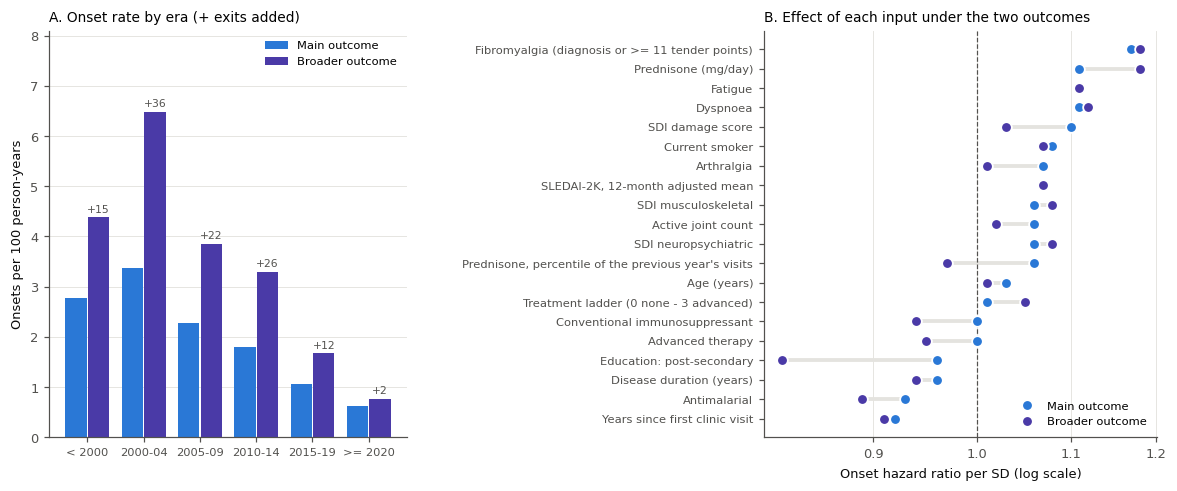

**What this means.**

* **The broader outcome adds 113 exits** to the 158 work-disability onsets, 73 of them
  before 2010, when other exits were common. The fall over calendar time therefore becomes steeper, not gentler
  (panel A above). Broadening the outcome does not remove the drift.
* **The model ranks the broader outcome less well:** AUROC 0.700 (0.668-0.735), against
  0.724 for the main outcome. It still beats demographics by +0.096 (+0.055 to +0.137).
  The added exits are harder to predict from disease markers, as expected if most of them are not health-related.
  At the patient level the pattern is the same: patient C 0.693 against
  0.745, +0.114 (+0.076 to +0.155) above demographics; the alarm
  catches 87 % of the broader onsets, against
  70 % of the main ones.
* **The same patients are flagged.** 17 of 20 inputs keep the direction of
  their effect, and 6 have a weaker effect under the broader outcome, as expected when the outcome becomes
  less specific.

**Conclusion.** The main outcome is the better target for a tool meant to prompt vocational support: it is more
predictable, and closer to what the support is for. The broader definition is still useful when comparing with
studies that count any loss of employment, and it gives the same conclusions about who is at risk.

In [31]:
"""The broader outcome: cross-validation of HazReg and the demographics model, and the refitted coefficients."""
C_BROAD = np.where(BROAD_FLAG, 1, C_ALL)
D1_B = (~_cont & (C_BROAD == 1)).astype(float)
D2_B = (~_cont & (C_BROAD == 2)).astype(float)
Y_B, W_B = ipcw_weights(T_ALL, C_BROAD)
for name, cols, spline in [("HazReg", COMPACT_VARS, SPLINE_VARS), ("Demographics", DEMO_VARS, ())]:
    if f"cv_broad_{name}" not in STATE:
        STATE[f"cv_broad_{name}"] = run_cv("haz", cols, spline, d1=D1_B, d2=D2_B)
        _save_state()
P_BROAD = {n: cif(STATE[f"cv_broad_{n}"]["pred"].reshape(-1, 2)).reshape(CV_REPEATS, N_LAND).mean(0)
           for n in ["HazReg", "Demographics"]}
BROAD_RES, BROAD_ARR = {}, {}
for n, p in P_BROAD.items():
    BROAD_RES[n], BROAD_ARR[n] = summarise(p, y=Y_B, w=W_B)
_bd = ci_of(BROAD_ARR["HazReg"]["AUROC"] - BROAD_ARR["Demographics"]["AUROC"])
BROAD_TABLE = pd.DataFrame({"Main outcome: HazReg": {k: fmt(v) for k, v in CV_RES["HazReg"].items()},
                            "Broader outcome: HazReg": {k: fmt(v) for k, v in BROAD_RES["HazReg"].items()},
                            "Broader outcome: Demographics": {k: fmt(v) for k, v in BROAD_RES["Demographics"].items()}})
BROAD_TABLE = BROAD_TABLE.loc[["AUROC", "Within-era AUROC", "IPA", "O/E", "Calibration slope"]]
# patient level under the broader outcome: its onsets are the cases, the same alarm rule
PT_EVAL_B = build_pt_eval(C=C_BROAD)
PT_BROAD_RES, PT_BROAD_ARR = {}, {}
for n, p in P_BROAD.items():
    PT_BROAD_RES[n], PT_BROAD_ARR[n] = pt_summary(PT_EVAL_B, p, alarm_flags(p), burden=False)
_bdp = ppaired("HazReg", "Demographics", arr=PT_BROAD_ARR)
for col, r_ in [("Main outcome: HazReg", PT_RES["HazReg"]), ("Broader outcome: HazReg", PT_BROAD_RES["HazReg"]),
                ("Broader outcome: Demographics", PT_BROAD_RES["Demographics"])]:
    BROAD_TABLE.loc["Patient C (time-matched)", col] = fmt(r_["C"])
    BROAD_TABLE.loc["Alarm sensitivity", col] = fmt(r_["Sensitivity"], 2)
    BROAD_TABLE.loc["Alarm specificity", col] = fmt(r_["Specificity"], 2)
display(BROAD_TABLE)
record("H6", "The model still ranks risk under the broader outcome", "AUROC, HazReg − Demographics (broader outcome)",
       _bd, "above0")
record_pt("H6", _bdp)

_pyb, _d1b, _d2b = rates_by_era(D1_B, D2_B)
BROAD_RATES = pd.DataFrame({"Era": [e[2] for e in ERAS], "Main: onsets /100 py": 100 * _d1 / _py,
                            "Broader: onsets /100 py": 100 * _d1b / _pyb,
                            "Broader: added exits": (_d1b - _d1).astype(int)}).set_index("Era").round(2)
save_table(BROAD_RATES, "broad_outcome_rates")

if "final_broad" not in STATE:
    STATE["final_broad"] = fit_procedure(np.arange(N_LAND), d1=D1_B, d2=D2_B, seed=SEED)
    _save_state()
_fb = STATE["final_broad"]
_keep = [i for i, n in enumerate(FINAL["prep"].names) if not n.endswith(("__NL", "__MISSING"))]
BROAD_COEF = pd.DataFrame({"Main outcome HR per SD": np.exp(FINAL["coef"][0][_keep]),
                           "Broader outcome HR per SD": np.exp(_fb["coef"][0][_keep])},
                          index=[DISPLAY[FINAL["prep"].names[i]] for i in _keep]).round(2)
BROAD_COEF["Same direction"] = np.where(np.sign(np.log(BROAD_COEF.iloc[:, 0])) == np.sign(np.log(BROAD_COEF.iloc[:, 1])),
                                        "yes", "no")
save_table(BROAD_COEF, "broad_outcome_coefficients")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.1], "wspace": 0.95})
ax = axes[0]
_xb = np.arange(len(BROAD_RATES))
ax.bar(_xb - 0.2, BROAD_RATES["Main: onsets /100 py"], 0.38, color=C1, label="Main outcome")
ax.bar(_xb + 0.2, BROAD_RATES["Broader: onsets /100 py"], 0.38, color=C4, label="Broader outcome")
for i, n_ in enumerate(BROAD_RATES["Broader: added exits"]):
    ax.text(i + 0.2, BROAD_RATES["Broader: onsets /100 py"].iloc[i] + 0.1, f"+{n_}", ha="center", fontsize=7,
            color=INK_2)
ax.set_xticks(_xb, BROAD_RATES.index, fontsize=7.5); ax.grid(axis="x", visible=False)
ax.set_ylabel("Onsets per 100 person-years"); ax.legend(fontsize=7.5, loc="upper right")
ax.set_ylim(0, BROAD_RATES["Broader: onsets /100 py"].max() * 1.25)
ax.set_title("A. Onset rate by era (+ exits added)", loc="left", fontsize=9)
ax = axes[1]
_bc = BROAD_COEF.sort_values("Main outcome HR per SD")
_yb = np.arange(len(_bc))
ax.axvline(1, color=INK_2, ls="--", lw=0.8)
ax.hlines(_yb, _bc.iloc[:, 0], _bc.iloc[:, 1], color=GRID_C, lw=2.5, zorder=1)
ax.plot(_bc.iloc[:, 0], _yb, "o", color=C1, ms=7, mec="white", mew=1.2, label="Main outcome", zorder=2)
ax.plot(_bc.iloc[:, 1], _yb, "o", color=C4, ms=7, mec="white", mew=1.2, label="Broader outcome", zorder=2)
ax.set_xscale("log"); ax.set_yticks(_yb, _bc.index, fontsize=7.5); ax.grid(axis="y", visible=False)
from matplotlib.ticker import FixedLocator, NullLocator, FormatStrFormatter
ax.xaxis.set_major_locator(FixedLocator([0.8, 0.9, 1.0, 1.1, 1.2, 1.3])); ax.xaxis.set_minor_locator(NullLocator())
ax.xaxis.set_major_formatter(FormatStrFormatter("%.1f"))
ax.set_xlabel("Onset hazard ratio per SD (log scale)"); ax.legend(fontsize=7.5, loc="lower right")
ax.set_title("B. Effect of each input under the two outcomes", loc="left", fontsize=9)
save_fig("broad_outcome")
_ba, _ma = BROAD_RES["HazReg"]["AUROC"], CV_RES["HazReg"]["AUROC"]
_nadd = int(D1_B.sum() - D1.sum())
_flip = (BROAD_COEF["Same direction"] == "no").sum()
_smaller = int((np.abs(np.log(BROAD_COEF.iloc[:, 1])) < np.abs(np.log(BROAD_COEF.iloc[:, 0]))).sum())
_early_add = int(BROAD_RATES["Broader: added exits"].iloc[:3].sum())
say(f"""
**What this means.**

* **The broader outcome adds {_nadd} exits** to the {int(D1.sum())} work-disability onsets, {_early_add} of them
  before 2010, when other exits were common. The fall over calendar time therefore becomes steeper, not gentler
  (panel A above). Broadening the outcome does not remove the drift.
* **The model ranks the broader outcome less well:** AUROC {_ba[0]:.3f} ({_ba[1]:.3f}-{_ba[2]:.3f}), against
  {_ma[0]:.3f} for the main outcome. It still beats demographics by {_bd[0]:+.3f} ({_bd[1]:+.3f} to {_bd[2]:+.3f}).
  The added exits are harder to predict from disease markers, as expected if most of them are not health-related.
  At the patient level the pattern is the same: patient C {PT_BROAD_RES['HazReg']['C'][0]:.3f} against
  {PT_RES['HazReg']['C'][0]:.3f}, {_bdp[0]:+.3f} ({_bdp[1]:+.3f} to {_bdp[2]:+.3f}) above demographics; the alarm
  catches {100 * PT_BROAD_RES['HazReg']['Sensitivity'][0]:.0f} % of the broader onsets, against
  {100 * PT_RES['HazReg']['Sensitivity'][0]:.0f} % of the main ones.
* **The same patients are flagged.** {len(BROAD_COEF) - _flip} of {len(BROAD_COEF)} inputs keep the direction of
  their effect, and {_smaller} have a weaker effect under the broader outcome, as expected when the outcome becomes
  less specific.

**Conclusion.** The main outcome is the better target for a tool meant to prompt vocational support: it is more
predictable, and closer to what the support is for. The broader definition is still useful when comparing with
studies that count any loss of employment, and it gives the same conclusions about who is at risk.
""")

---
# Part VI. Clinical use

> **The decision.** At a routine visit, should this working patient be asked about work and offered vocational
> support? A referral is cheap and low-harm, and missing someone who then leaves work is costly. So the relevant
> risk thresholds are low, around 2-10 % over 24 months.

Three questions, all answered with the cross-validated predictions (each visit scored by models that never saw
its patient):

1. **Are the predicted risks right?** Calibration by tenth of predicted risk.
2. **What do the tiers mean in practice?** The share of visits in each tier, and the risk actually observed there.
3. **Does using the model beat simple policies?** Net benefit (decision curve) against referring everyone or no one.
   A net benefit of 0.01 means the same as finding 1 extra future case per 100 visits with no unnecessary
   referrals.

## 6.1 Calibration, risk tiers and net benefit

,Landmarks (%),Patients,Mean predicted (%),Observed 24-mo risk (%),95% CI,Share of onsets (%)
Tier,,,,,,
< 2 %,36.8,640,1.5,1.2,0.7-1.8,13.1
2-4 %,35.6,788,2.8,2.4,1.8-3.3,24.9
4-10 %,21.3,597,6.0,6.3,4.8-7.9,38.4
>= 10 %,6.3,308,16.4,13.0,9.4-17.4,23.5


,Net benefit: model,95% CI low,95% CI high,Net benefit: refer all,Referrals avoided per 100 (vs all)
Threshold,,,,,
0.02,0.0180,0.0130,0.0238,0.0153,13.3591
0.04,0.0108,0.0068,0.0152,-0.0052,38.4979
0.06,0.0055,0.0021,0.0097,-0.0266,50.2987
0.10,0.0019,-0.0007,0.0052,-0.0723,66.7339


,Patient alarm (cross-validated HazReg)
Alarms raised,565
Mean predicted 24-mo risk at the alert (%),10.123492
Observed: onset within 24 months of the alert (%),9.031222
95% CI,6.6-11.4


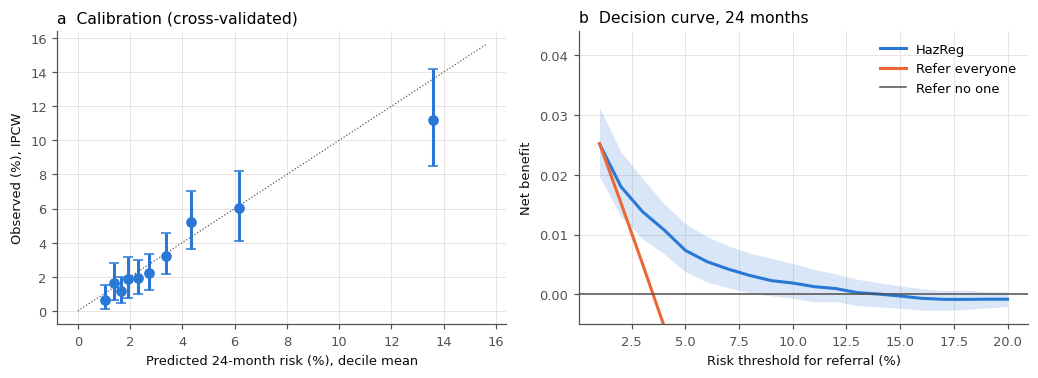

**What this means.**

* **Calibration.** Across tenths of predicted risk, observed risk follows prediction (slope 0.88,
  O/E 0.91). These are averages over all years; recent years have lower recorded risk
  (Section 4.3).
* **The tiers separate patients usefully.** The lowest tier holds 37 % of visits,
  with an observed 24-month risk of 1.2 %. The highest holds
  6 % of visits, with a risk of 13.0 %, about
  11 times higher. The
  top two tiers together contain 62 % of future onsets.
* **Using the model beats simple policies** for referral thresholds from about 2 % to
  14 %. At 4 %, it is equivalent to finding
  1.1 extra future
  cases per 100 visits with no unnecessary referrals, compared with the better of referring everyone or no one.

* **At the moment an alarm is raised**, the mean predicted risk is 10.1 %,
  and 9.0 % (95 % CI 6.6-11.4) of alarms are
  followed by an onset within 24 months: the alarm's risk is about right at the patient level too.

In clinic: **ask every patient in the top two tiers about work at each visit, and offer referral**. In the lowest
tier, a brief check at the yearly review is enough.

In [32]:
"""Calibration by decile, risk tiers, decision curve (cross-validated predictions)."""
_k = W_IP > 0
_Wb = W_BOOT[:, ROW_PIDX]
_dec = pd.qcut(P_MAIN, 10, labels=False, duplicates="drop")
_cal = []
for d in range(_dec.max() + 1):
    m_ = _dec == d
    obs = (_Wb[:, m_] * (W_IP * Y_IP)[m_]).sum(1) / _Wb[:, m_].sum(1)
    _cal.append((P_MAIN[m_].mean(), obs[0], *np.percentile(obs[1:], [2.5, 97.5])))
_cal = np.array(_cal)

_tiers = np.digitize(P_MAIN, [t[1] for t in RISK_TIERS[:-1]])
_on24 = (W_IP * Y_IP)
TIERS = []
for i, (_, _, lab) in enumerate(RISK_TIERS):
    m_ = _tiers == i
    obs = (_Wb[:, m_] * _on24[m_]).sum(1) / _Wb[:, m_].sum(1)
    TIERS.append({"Tier": lab, "Landmarks (%)": 100 * m_.mean(), "Patients": len(np.unique(PID_ALL[m_])),
                  "Mean predicted (%)": 100 * P_MAIN[m_].mean(), "Observed 24-mo risk (%)": 100 * obs[0],
                  "95% CI": f"{100 * np.percentile(obs[1:], 2.5):.1f}-{100 * np.percentile(obs[1:], 97.5):.1f}",
                  "Share of onsets (%)": 100 * _on24[m_].sum() / _on24.sum()})
TIERS = pd.DataFrame(TIERS).set_index("Tier").round(1)
display(TIERS)


def net_benefit(p, thresholds, Wrow):
    Wk = Wrow * W_IP
    n = Wk.sum(1)
    out = []
    for t in thresholds:
        a = p >= t
        tp = (Wk * (Y_IP * a)).sum(1) / n
        fp = (Wk * ((1 - Y_IP) * a * (W_IP > 0))).sum(1) / n
        out.append(tp - fp * t / (1 - t))
    return np.array(out)                           # (thresholds, B)


_nb = net_benefit(P_MAIN, DCA_THRESHOLDS, _Wb[:201])
_nb_all = net_benefit(np.ones(N_LAND), DCA_THRESHOLDS, _Wb[:201])
DCA = pd.DataFrame({"Threshold": DCA_THRESHOLDS, "Net benefit: model": _nb[:, 0],
                    "95% CI low": np.percentile(_nb[:, 1:], 2.5, axis=1),
                    "95% CI high": np.percentile(_nb[:, 1:], 97.5, axis=1), "Net benefit: refer all": _nb_all[:, 0],
                    "Referrals avoided per 100 (vs all)": 100 * (_nb[:, 0] - _nb_all[:, 0]) /
                                                          (DCA_THRESHOLDS / (1 - DCA_THRESHOLDS))}).set_index("Threshold")
display(DCA.loc[[0.02, 0.04, 0.06, 0.1]].round(4))

# ---- patient level: is the risk at the moment an alarm is raised right? (predicted vs observed after the alert)
_st_alarm = alarm_starts(FLAGS["HazReg"])
_ka = _st_alarm & (W_IP > 0)
ALARM_CAL = {"Alarms raised": int(_st_alarm.sum()), "Mean predicted 24-mo risk at the alert (%)": 100 * P_MAIN[_st_alarm].mean(),
             "Observed: onset within 24 months of the alert (%)": PT_RES["HazReg"]["Episode PPV (%)"][0],
             "95% CI": "{:.1f}-{:.1f}".format(*PT_RES["HazReg"]["Episode PPV (%)"][1:])}
display(pd.Series(ALARM_CAL).to_frame("Patient alarm (cross-validated HazReg)"))

# ---- hypotheses H3a-c
_cr = CV_RES["HazReg"]
_h3a = (_cr["Calibration slope"][0], _cr["Calibration slope"][1], _cr["Calibration slope"][2])
record("H3a", "Predicted risks match observed risks", "Calibration slope (and O/E)", _h3a, ("slope", 0.8, 1.2), nd=2)
_oe_ok = _cr["O/E"][1] <= 1 <= _cr["O/E"][2]
HYP["H3a"]["Result"] += f"; O/E {_cr['O/E'][0]:.2f} ({_cr['O/E'][1]:.2f} to {_cr['O/E'][2]:.2f})"
HYP["H3a"]["_met"] = HYP["H3a"]["_met"] and _oe_ok
HYP["H3a"]["Met"] = "yes" if HYP["H3a"]["_met"] else "no"
record("H3b", "The model beats knowing only the clinic's average risk", "IPA", _cr["IPA"], "above0")
_i4 = list(DCA_THRESHOLDS).index(0.04)
_nb_gain = _nb[_i4] - np.maximum(_nb_all[_i4], 0.0)
record("H3c", "Referring by the model beats referring everyone or no one",
       "Net benefit at 4 %, model − best simple policy", ci_of(_nb_gain), "above0", nd=4)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.5))
ax = axes[0]
ax.errorbar(100 * _cal[:, 0], 100 * _cal[:, 1], yerr=[100 * (_cal[:, 1] - _cal[:, 2]), 100 * (_cal[:, 3] - _cal[:, 1])],
            fmt="o", color=C1, ms=6, capsize=3)
_l = 100 * max(_cal[:, 0].max(), _cal[:, 3].max()) * 1.1
ax.plot([0, _l], [0, _l], color=INK_2, lw=0.8, ls=":")
ax.set_xlabel("Predicted 24-month risk (%), decile mean"); ax.set_ylabel("Observed (%), IPCW")
ax.set_title("a  Calibration (cross-validated)", loc="left")
ax = axes[1]
x = 100 * DCA_THRESHOLDS
ax.fill_between(x, DCA["95% CI low"], DCA["95% CI high"], color=C1, alpha=0.18, linewidth=0)
ax.plot(x, DCA["Net benefit: model"], color=C1, label="HazReg")
ax.plot(x, DCA["Net benefit: refer all"], color=C2, label="Refer everyone")
ax.axhline(0, color=INK_2, lw=1, label="Refer no one")
ax.set_ylim(min(-0.005, DCA["Net benefit: model"].min() * 1.2), max(DCA["Net benefit: refer all"].max(), 0.04) * 1.1)
ax.set_xlabel("Risk threshold for referral (%)"); ax.set_ylabel("Net benefit")
ax.set_title("b  Decision curve, 24 months", loc="left"); ax.legend()
plt.tight_layout(); save_fig("fig06_clinical_use")
_t = TIERS
_cross = DCA.index[(DCA["Net benefit: model"] > DCA["Net benefit: refer all"]) & (DCA["Net benefit: model"] > 0)]
say(f"""
**What this means.**

* **Calibration.** Across tenths of predicted risk, observed risk follows prediction (slope {_cr['Calibration slope'][0]:.2f},
  O/E {_cr['O/E'][0]:.2f}). These are averages over all years; recent years have lower recorded risk
  (Section 4.3).
* **The tiers separate patients usefully.** The lowest tier holds {_t.iloc[0]['Landmarks (%)']:.0f} % of visits,
  with an observed 24-month risk of {_t.iloc[0]['Observed 24-mo risk (%)']:.1f} %. The highest holds
  {_t.iloc[-1]['Landmarks (%)']:.0f} % of visits, with a risk of {_t.iloc[-1]['Observed 24-mo risk (%)']:.1f} %, about
  {_t.iloc[-1]['Observed 24-mo risk (%)'] / max(_t.iloc[0]['Observed 24-mo risk (%)'], 0.1):.0f} times higher. The
  top two tiers together contain {_t.iloc[-2:]['Share of onsets (%)'].sum():.0f} % of future onsets.
* **Using the model beats simple policies** for referral thresholds from about {100 * _cross.min():.0f} % to
  {100 * _cross.max():.0f} %. At 4 %, it is equivalent to finding
  {100 * (DCA.loc[0.04, 'Net benefit: model'] - max(DCA.loc[0.04, 'Net benefit: refer all'], 0)):.1f} extra future
  cases per 100 visits with no unnecessary referrals, compared with the better of referring everyone or no one.

* **At the moment an alarm is raised**, the mean predicted risk is {ALARM_CAL['Mean predicted 24-mo risk at the alert (%)']:.1f} %,
  and {ALARM_CAL['Observed: onset within 24 months of the alert (%)']:.1f} % (95 % CI {ALARM_CAL['95% CI']}) of alarms are
  followed by an onset within 24 months: the alarm's risk is {"about right" if abs(np.log(ALARM_CAL['Observed: onset within 24 months of the alert (%)'] / ALARM_CAL['Mean predicted 24-mo risk at the alert (%)'])) < 0.2 else "off by a factor of " + format(ALARM_CAL['Observed: onset within 24 months of the alert (%)'] / ALARM_CAL['Mean predicted 24-mo risk at the alert (%)'], ".2f")} at the patient level too.

In clinic: **ask every patient in the top two tiers about work at each visit, and offer referral**. In the lowest
tier, a brief check at the yearly review is enough.
""" if len(_cross) else "**What this means.** The model does not beat referring everyone or no one at any threshold.")

## 6.2 What the risk scores look like, and what each threshold means

> **The question.** If a clinic acted on the score at a given threshold, what would happen at 1,000 working visits?

Every risk below is **cross-validated**: each visit is scored by models that never saw that patient. Panel a shows
how the predicted 24-month risks are spread, separately for visits that were followed by an onset within 24 months
and visits that were not, with the four risk tiers as background bands. Panel b turns three referral thresholds
(2 %, 4 % and 10 %) into **natural frequencies**: of 1,000 working visits, how many would be flagged, and how many
of those flagged (and not flagged) would be followed by work disability within 24 months. Counts use the censoring
weights, so visits with short follow-up are represented correctly.

,"Flagged, onset follows","Flagged, no onset","Not flagged, onset follows (missed)","Not flagged, no onset","Flagged per 1,000",PPV (%),NPV (%),Sensitivity (%),Specificity (%),Visits flagged per onset found
Threshold,,,,,,,,,,
≥ 2 %,30.4,606.4,4.6,358.7,636.7,4.8,98.7,86.9,37.2,21.0
≥ 4 %,21.7,261.1,13.3,703.9,282.8,7.7,98.1,62.0,72.9,13.0
≥ 10 %,8.2,57.1,26.7,907.9,65.4,12.6,97.1,23.5,94.1,7.9


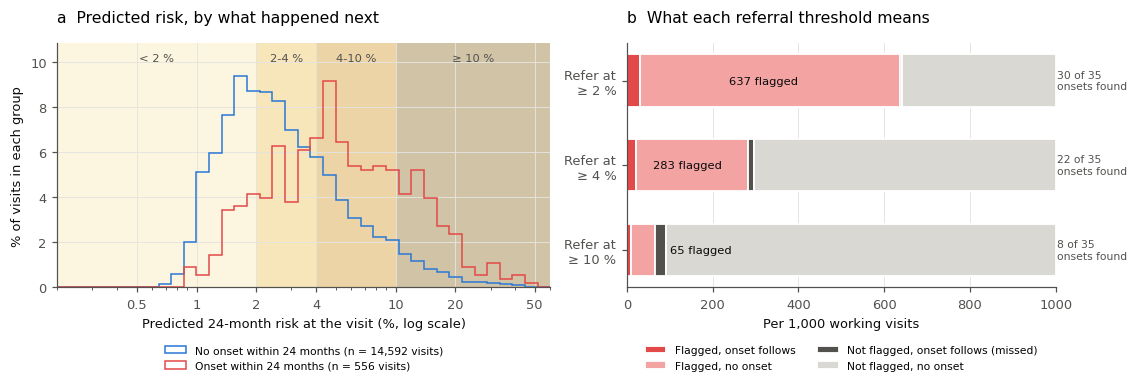

**What this means.**

* **The two groups overlap, but are shifted.** The upper two tiers hold 28 %
  of all working visits but 62 % of the visits followed by an onset. No
  threshold separates the groups cleanly, which is expected for an uncommon outcome predicted two years ahead.
* **At a 4 % threshold**, 283 of every 1,000 working visits would prompt a conversation
  about work. These flagged visits contain 22 of the
  35 visits followed by an onset
  (sensitivity 62 %). About 13 visits are flagged
  for each one that precedes an onset. Among visits not flagged, 98.1 % are not followed by an onset.
* **The threshold is a choice about workload.** A 2 % threshold finds 87 % of
  future onsets but flags 637 of 1,000 visits; a 10 % threshold flags only
  65 but finds 24 %. Because a conversation about work is cheap, the lower
  thresholds are the reasonable ones (Section 6.1).

In [33]:
"""Risk distribution by outcome, and natural frequencies at three thresholds."""
TIER_COLORS = ["#f7e3a6", "#e8b93a", "#c98500", "#7d5300"]
TIER_NAMES = [t[2].replace(">=", "≥") for t in RISK_TIERS]
TIER_LINE_COLORS = ["#e6c34f", "#cf9410", "#9c6200", "#4f3300"]   # darker steps of the same hue, for lines
TIER_OF = lambda p: np.digitize(p, [t[1] for t in RISK_TIERS[:-1]])
THRESHOLDS_SHOW = [0.02, 0.04, 0.10]


def _tier_bands(ax, orient="x", alpha=0.35, label=True):
    lims = [max(RISK_TIERS[0][0], 1e-3), *[t[1] for t in RISK_TIERS[:-1]], 1.0]
    for k in range(len(RISK_TIERS)):
        lo, hi = 100 * lims[k], 100 * lims[k + 1]
        (ax.axvspan if orient == "x" else ax.axhspan)(lo, hi, color=TIER_COLORS[k], alpha=alpha, lw=0, zorder=0)


fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.7), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
_bins_p = np.logspace(np.log10(0.2), np.log10(60), 40)
_known = ~np.isnan(Y24)
for yv, col, nm in [(0, C1, "No onset within 24 months"), (1, "#e34948", "Onset within 24 months")]:
    k = _known & (Y24 == yv)
    ax.hist(100 * P_MAIN[k], bins=_bins_p, density=False, weights=np.full(k.sum(), 100 / k.sum()),
            histtype="step", lw=2, color=col, label=f"{nm} (n = {k.sum():,} visits)")
_tier_bands(ax)
ax.set_xscale("log"); ax.set_xlim(0.2, 60)
ax.set_xticks([0.5, 1, 2, 4, 10, 20, 50], ["0.5", "1", "2", "4", "10", "20", "50"])
ax.set_xlabel("Predicted 24-month risk at the visit (%, log scale)"); ax.set_ylabel("% of visits in each group")
_ymax = ax.get_ylim()[1]
for k, nm in enumerate(TIER_NAMES):
    lo = max(RISK_TIERS[k][0], 0.002) * 100; hi = min(RISK_TIERS[k][1], 0.6) * 100
    ax.text(np.sqrt(lo * hi), _ymax * 1.02, nm, ha="center", fontsize=7.5, color=INK_2)
ax.set_ylim(0, _ymax * 1.1)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1, fontsize=7)
ax.set_title("a  Predicted risk, by what happened next", loc="left", pad=14)

# natural frequencies per 1,000 visits (IPCW)
_N = W_IP.sum()
NATFREQ = []
for t in THRESHOLDS_SHOW:
    a = P_MAIN >= t
    tp = np.sum(W_IP * Y_IP * a) / _N * 1000
    fn = np.sum(W_IP * Y_IP * ~a) / _N * 1000
    fp = np.sum(W_IP * (1 - Y_IP) * a) / _N * 1000
    tn = 1000 - tp - fn - fp
    NATFREQ.append({"Threshold": f"≥ {100 * t:.0f} %", "Flagged, onset follows": tp, "Flagged, no onset": fp,
                    "Not flagged, onset follows (missed)": fn, "Not flagged, no onset": tn,
                    "Flagged per 1,000": tp + fp, "PPV (%)": 100 * tp / (tp + fp), "NPV (%)": 100 * tn / (tn + fn),
                    "Sensitivity (%)": 100 * tp / (tp + fn), "Specificity (%)": 100 * tn / (tn + fp),
                    "Visits flagged per onset found": (tp + fp) / tp})
NATFREQ = pd.DataFrame(NATFREQ).set_index("Threshold")
display(NATFREQ.round(1))
ax = axes[1]
_parts = [("Flagged, onset follows", "#e34948"), ("Flagged, no onset", "#f2a3a2"),
          ("Not flagged, onset follows (missed)", INK_2), ("Not flagged, no onset", "#dad8d2")]
for i, (thr, row) in enumerate(NATFREQ.iterrows()):
    left = 0
    for c, col in _parts:
        ax.barh(i, row[c], left=left, color=col, edgecolor="white", linewidth=1.2, height=0.62,
                label=c if i == 0 else None)
        left += row[c]
    _wide = row["Flagged per 1,000"] > 150
    ax.text(row["Flagged per 1,000"] / 2 if _wide else left - row["Not flagged, no onset"] + 8, i,
            f"{row['Flagged per 1,000']:.0f} flagged", ha="center" if _wide else "left", va="center", fontsize=7.5,
            color=INK)
    ax.text(1003, i, f"{row['Flagged, onset follows']:.0f} of {row['Flagged, onset follows'] + row['Not flagged, onset follows (missed)']:.0f}\nonsets found",
            va="center", fontsize=7, color=INK_2)
ax.set_yticks(range(len(NATFREQ)), [f"Refer at\n{t}" for t in NATFREQ.index]); ax.invert_yaxis()
ax.set_xlim(0, 1000); ax.set_xlabel("Per 1,000 working visits"); ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=7)
ax.set_title("b  What each referral threshold means", loc="left", pad=14)
plt.tight_layout(); save_fig("risk01_distribution_thresholds")
_n4 = NATFREQ.loc["≥ 4 %"]
say(f"""
**What this means.**

* **The two groups overlap, but are shifted.** The upper two tiers hold {TIERS.iloc[-2:]['Landmarks (%)'].sum():.0f} %
  of all working visits but {TIERS.iloc[-2:]['Share of onsets (%)'].sum():.0f} % of the visits followed by an onset. No
  threshold separates the groups cleanly, which is expected for an uncommon outcome predicted two years ahead.
* **At a 4 % threshold**, {_n4['Flagged per 1,000']:.0f} of every 1,000 working visits would prompt a conversation
  about work. These flagged visits contain {_n4['Flagged, onset follows']:.0f} of the
  {_n4['Flagged, onset follows'] + _n4['Not flagged, onset follows (missed)']:.0f} visits followed by an onset
  (sensitivity {_n4['Sensitivity (%)']:.0f} %). About {_n4['Visits flagged per onset found']:.0f} visits are flagged
  for each one that precedes an onset. Among visits not flagged, {_n4['NPV (%)']:.1f} % are not followed by an onset.
* **The threshold is a choice about workload.** A 2 % threshold finds {NATFREQ.iloc[0]['Sensitivity (%)']:.0f} % of
  future onsets but flags {NATFREQ.iloc[0]['Flagged per 1,000']:.0f} of 1,000 visits; a 10 % threshold flags only
  {NATFREQ.iloc[-1]['Flagged per 1,000']:.0f} but finds {NATFREQ.iloc[-1]['Sensitivity (%)']:.0f} %. Because a conversation about work is cheap, the lower
  thresholds are the reasonable ones (Section 6.1).
""")

## 6.3 The patient-level alarm

> **The question.** If the clinic acted on the alarm of Section 2.5, how many of the patients who go on to leave work
> would it catch, how early, and how many patients who keep working would it flag along the way?

Everything here uses the cross-validated HazReg risks and the time-matched comparison of Section 3.0.1: each patient
who left work is set against the patients still working at that moment, over the same 24 calendar months. Panel a
compares the alarm rule with simpler ones. Panel b turns the main rule into **natural frequencies per 100
patients**. Panel c shows how long before the onset the alarm was raised.

,Sensitivity,Specificity,Balanced accuracy,Visits flagged (%),Patients ever flagged (%),Alarm episodes per 100 person-years,Episode PPV (%),"Lead time, median (IQR), months"
Main: 2 visits ≥ 4 % or 1 ≥ 10 %,0.70 (0.62 to 0.77),0.60 (0.56 to 0.64),0.65 (0.61 to 0.69),40,48,6.6,9.0 (6.6 to 11.4),26 (9-54)
2 visits ≥ 2 % or 1 ≥ 10 %,0.80 (0.74 to 0.87),0.37 (0.34 to 0.41),0.59 (0.55 to 0.62),59,75,12.1,5.7 (4.3 to 7.2),27 (10-59)
2 visits ≥ 10 %,0.31 (0.24 to 0.39),0.87 (0.84 to 0.90),0.59 (0.55 to 0.63),14,15,1.9,16.3 (10.9 to 22.2),23 (9-46)
"Main rule, no stay-on",0.64 (0.57 to 0.72),0.71 (0.67 to 0.74),0.68 (0.64 to 0.72),22,48,9.1,7.7 (5.7 to 9.7),17 (8-33)
Any visit ≥ 4 %,0.75 (0.67 to 0.82),0.61 (0.58 to 0.65),0.68 (0.64 to 0.72),28,60,13.5,6.8 (5.3 to 8.5),17 (7-33)


Onsets from 2012 (46): patient C 0.761 (0.685 to 0.840), sensitivity 0.63 (0.50 to 0.77), specificity 0.67 (0.63 to 0.71); 4.5 new alarms per 100 person-years, episode PPV 8.3 (4.4 to 12.6) %.


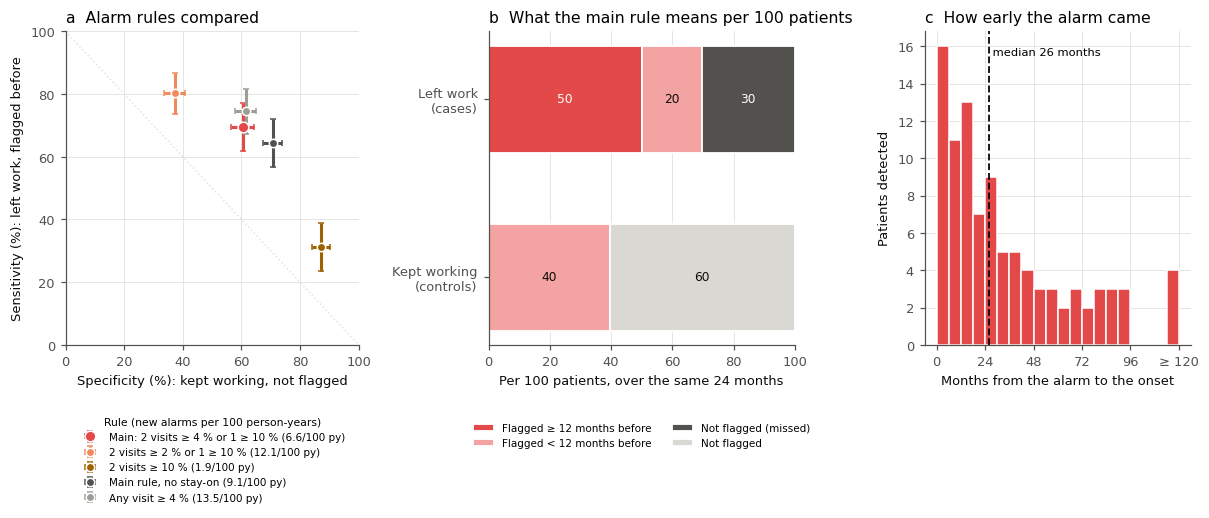

**What this means.**

* **The main rule flagged 70 % of patients before they left work** (95 % CI
  62-77 %), and left
  60 % of patients who kept working unflagged over the same 24 months. Of 100 patients
  who went on to leave work, about 50 were flagged at least a year ahead, 20 in the final year and
  30 were missed. The median warning was 26 months, enough time for a referral to act.
* **Workload and yield.** The clinic would see 6.6 new alarms per 100 working patient-years, and
  48 % of patients would be flagged at some point. 9 %
  of alarms were followed by an onset within 24 months, 2.6 times the
  average risk of a working visit (3.5 %).
* **Against simpler rules.** Flagging any visit ≥ 4 %: sensitivity 75 %, specificity
  61 %, 13.5 alarms per 100 person-years. The main rule without the stay-on
  part: 64 %, 71 %, 9.1.
  Both raise more alarms than the main rule, because patients near the threshold are flagged, unflagged and flagged again.
  Changing the threshold moves sensitivity and specificity in opposite directions (panel a).
* **In recent years** (onsets from 2012): patient C 0.76, sensitivity
  63 %, specificity 67 %, episode PPV
  8 % (lower than over all years, matching the lower recorded risk of Part IV).

Because risk is mostly a stable trait, a flag usually means *this is a patient to keep asking about work*, rather than
*this patient is about to leave*. Section 6.6 shows how the alarm behaves as an onset approaches.

In [34]:
"""The patient-level alarm: rule comparison, natural frequencies per 100 patients, lead time, recent era."""
ALARM_RES = {}
for nm, rule in ALARM_VARIANTS.items():
    ALARM_RES[nm] = pt_summary(PT_EVAL, P_MAIN, alarm_flags(P_MAIN, rule))[0]
ALARM_TABLE = pd.DataFrame({nm: {"Sensitivity": fmt(r["Sensitivity"], 2), "Specificity": fmt(r["Specificity"], 2),
                                 "Balanced accuracy": fmt(r["Balanced accuracy"], 2),
                                 "Visits flagged (%)": f"{r['Visits flagged (%)']:.0f}",
                                 "Patients ever flagged (%)": f"{r['Patients ever flagged (%)']:.0f}",
                                 "Alarm episodes per 100 person-years": f"{r['Alarm episodes per 100 person-years']:.1f}",
                                 "Episode PPV (%)": fmt(r["Episode PPV (%)"], 1),
                                 "Lead time, median (IQR), months": f"{r['Lead time, median (months)']:.0f} "
                                                                   f"({r['Lead time, IQR'][0]:.0f}-{r['Lead time, IQR'][1]:.0f})"}
                            for nm, r in ALARM_RES.items()}).T
display(ALARM_TABLE)
save_table(ALARM_TABLE, "alarm_rules")

# the recent era: onsets from 2012, the same rule
PT_EVAL_RECENT = build_pt_eval(onset_from=_day(2012))
ALARM_RECENT = pt_summary(PT_EVAL_RECENT, P_MAIN, FLAGS["HazReg"], burden=False)[0]
ALARM_RECENT_BURDEN = alarm_burden(FLAGS["HazReg"], sel=LAND_YEAR >= 2012)
print(f"Onsets from 2012 ({PT_EVAL_RECENT['n_onsets']}): patient C {fmt(ALARM_RECENT['C'])}, sensitivity "
      f"{fmt(ALARM_RECENT['Sensitivity'], 2)}, specificity {fmt(ALARM_RECENT['Specificity'], 2)}; "
      f"{ALARM_RECENT_BURDEN['Alarm episodes per 100 person-years']:.1f} new alarms per 100 person-years, episode PPV "
      f"{fmt(ALARM_RECENT_BURDEN['Episode PPV (%)'], 1)} %.")

LEAD = lead_times(PT_EVAL, FLAGS["HazReg"])
_main = ALARM_RES[list(ALARM_VARIANTS)[0]]
fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.7), gridspec_kw={"width_ratios": [1.1, 1.15, 1], "wspace": 0.45})
ax = axes[0]
_vcol = ["#e34948", "#f08a5d", "#9c6200", INK_2, "#9e9c95"]
for (nm, r), col in zip(ALARM_RES.items(), _vcol):
    se, sp = r["Sensitivity"], r["Specificity"]
    ax.errorbar(100 * sp[0], 100 * se[0], xerr=[[100 * (sp[0] - sp[1])], [100 * (sp[2] - sp[0])]],
                yerr=[[100 * (se[0] - se[1])], [100 * (se[2] - se[0])]], fmt="o", color=col, ms=7 if nm.startswith("Main:") else 5.5,
                capsize=2, mec="white", mew=1.0, label=f"{nm} ({r['Alarm episodes per 100 person-years']:.1f}/100 py)")
ax.plot([0, 100], [100, 0], color=GRID_C, lw=1, ls=":")
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel("Specificity (%): kept working, not flagged"); ax.set_ylabel("Sensitivity (%): left work, flagged before")
ax.legend(fontsize=6.8, loc="upper center", bbox_to_anchor=(0.5, -0.2), title="Rule (new alarms per 100 person-years)",
          title_fontsize=7)
ax.set_title("a  Alarm rules compared", loc="left")

ax = axes[1]
_n_on = PT_EVAL["n_onsets"]
_early = 100 * np.sum(LEAD >= 12) / _n_on
_late = 100 * np.sum(LEAD < 12) / _n_on
_miss = 100 - _early - _late
_fp = 100 * (1 - _main["Specificity"][0])
_bars = [("Left work\n(cases)", [(_early, "#e34948", "Flagged ≥ 12 months before"), (_late, "#f2a3a2", "Flagged < 12 months before"),
                                 (_miss, INK_2, "Not flagged (missed)")]),
         ("Kept working\n(controls)", [(_fp, "#f2a3a2", None), (100 - _fp, "#dad8d2", "Not flagged")])]
for i, (lab, parts) in enumerate(_bars):
    left = 0
    for v, col, nm in parts:
        ax.barh(i, v, left=left, color=col, edgecolor="white", linewidth=1.2, height=0.6, label=nm)
        if v >= 7:
            ax.text(left + v / 2, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if col in ("#e34948", INK_2) else INK)
        left += v
ax.set_yticks([0, 1], [b[0] for b in _bars]); ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("Per 100 patients, over the same 24 months"); ax.grid(axis="y", visible=False)
_h, _l = ax.get_legend_handles_labels()
ax.legend([h for h, l in zip(_h, _l) if l], [l for l in _l if l], fontsize=6.8, loc="upper center",
          bbox_to_anchor=(0.5, -0.22), ncol=2)
ax.set_title("b  What the main rule means per 100 patients", loc="left")

ax = axes[2]
ax.hist(np.minimum(LEAD, 119), bins=np.arange(0, 126, 6), color="#e34948", edgecolor="white")
ax.set_xticks([0, 24, 48, 72, 96, 120], ["0", "24", "48", "72", "96", "≥ 120"])
ax.axvline(np.median(LEAD), color=INK, lw=1.2, ls="--")
ax.text(np.median(LEAD), ax.get_ylim()[1] * 0.95, f" median {np.median(LEAD):.0f} months", fontsize=7.5, va="top")
ax.set_xlabel("Months from the alarm to the onset"); ax.set_ylabel("Patients detected")
ax.set_title("c  How early the alarm came", loc="left")
save_fig("alarm01_patient_alarm")
_any = ALARM_RES["Any visit ≥ 4 %"]; _nostay = ALARM_RES["Main rule, no stay-on"]
_epi = lambda r: r["Alarm episodes per 100 person-years"]
_avg_risk = 100 * np.sum(W_IP * Y_IP) / N_LAND
_rec_ppv = ALARM_RECENT_BURDEN["Episode PPV (%)"][0]
say(f"""
**What this means.**

* **The main rule flagged {100 * _main['Sensitivity'][0]:.0f} % of patients before they left work** (95 % CI
  {100 * _main['Sensitivity'][1]:.0f}-{100 * _main['Sensitivity'][2]:.0f} %), and left
  {100 * _main['Specificity'][0]:.0f} % of patients who kept working unflagged over the same 24 months. Of 100 patients
  who went on to leave work, about {_early:.0f} were flagged at least a year ahead, {_late:.0f} in the final year and
  {_miss:.0f} were missed. The median warning was {np.median(LEAD):.0f} months{", enough time for a referral to act" if np.median(LEAD) >= 6 else ", short for a referral to act on"}.
* **Workload and yield.** The clinic would see {_epi(_main):.1f} new alarms per 100 working patient-years, and
  {_main['Patients ever flagged (%)']:.0f} % of patients would be flagged at some point. {_main['Episode PPV (%)'][0]:.0f} %
  of alarms were followed by an onset within 24 months, {_main['Episode PPV (%)'][0] / max(_avg_risk, 1e-9):.1f} times the
  average risk of a working visit ({_avg_risk:.1f} %).
* **Against simpler rules.** Flagging any visit ≥ 4 %: sensitivity {100 * _any['Sensitivity'][0]:.0f} %, specificity
  {100 * _any['Specificity'][0]:.0f} %, {_epi(_any):.1f} alarms per 100 person-years. The main rule without the stay-on
  part: {100 * _nostay['Sensitivity'][0]:.0f} %, {100 * _nostay['Specificity'][0]:.0f} %, {_epi(_nostay):.1f}.
  {"Both raise more alarms than the main rule, because patients near the threshold are flagged, unflagged and flagged again." if min(_epi(_any), _epi(_nostay)) > _epi(_main) else "The main rule does not reduce the number of alarms compared with these simpler rules."}
  Changing the threshold moves sensitivity and specificity in opposite directions (panel a).
* **In recent years** (onsets from 2012): patient C {ALARM_RECENT['C'][0]:.2f}, sensitivity
  {100 * ALARM_RECENT['Sensitivity'][0]:.0f} %, specificity {100 * ALARM_RECENT['Specificity'][0]:.0f} %, episode PPV
  {_rec_ppv:.0f} %{" (lower than over all years, matching the lower recorded risk of Part IV)" if _rec_ppv < _main['Episode PPV (%)'][0] else ""}.

Because risk is mostly a stable trait, a flag usually means *this is a patient to keep asking about work*, rather than
*this patient is about to leave*. Section 6.6 shows how the alarm behaves as an onset approaches.
""")

## 6.4 Where patients end up, by their risk

> **The question.** Do patients who are flagged go on to leave work more often than patients who are not?

Here the unit is the **patient**. Panel a groups patients by whether the alarm (Section 2.5) was ever raised, and
whether their risk ever reached each threshold, while they were working (before any onset), and shows how their
follow-up ended. Panel b groups them by their risk
tier at **entry**, their first working visit, and shows the same. Panel b is the cleaner view: it uses only the first
score, so a patient followed for longer has no extra chances to be flagged.

Ending,Work disability,Other exit from work,Still working and attending,Left the clinic while working,"Reached 65, died or other censoring",Patients
Alarm ever raised,22.4,10.2,34.9,21.2,11.4,501
Alarm never raised,6.8,14.7,40.7,32.3,5.6,558
Ever ≥ 2 %,15.8,11.7,38.0,25.3,9.1,928
Never ≥ 2 %,2.3,18.3,37.4,38.9,3.1,131
Ever ≥ 4 %,19.7,11.3,35.4,23.0,10.6,635
Never ≥ 4 %,5.9,14.4,41.7,33.0,5.0,424
Ever ≥ 10 %,27.3,10.2,31.6,18.8,12.2,304
Never ≥ 10 %,8.9,13.5,40.5,30.3,6.8,755
< 2 % at entry,6.3,17.4,38.3,33.6,4.3,253
2-4 % at entry,10.5,10.7,42.2,27.1,9.5,391


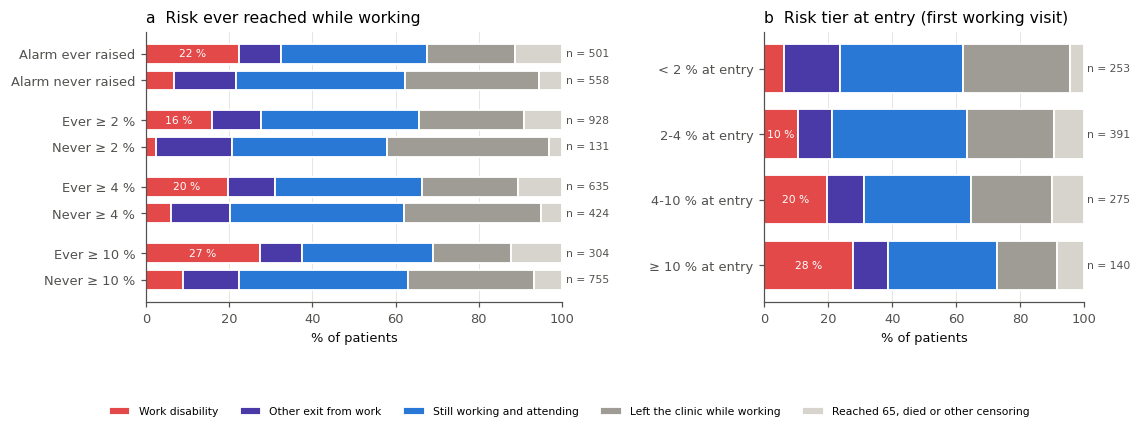

**What this means.** Among patients for whom the alarm was raised while they were working, 22 % later
left work for health reasons, against 7 % of patients never flagged
(501 and 558
patients). Among patients whose risk reached 4 % at some working visit, 20 % later left work
for health reasons, against 6 % of patients who never reached it. The tier at entry alone already
separates patients: 28 % of patients who entered in the highest tier had a work-disability onset during
follow-up, against 6 % of those who entered in the lowest.

In [35]:
"""Final state of each patient by threshold reached and by risk tier at entry."""
_pre = np.ones(N_LAND, bool)
for p in FIRST_ONSET_DATE.index:
    r = PT_ROWS[p]
    _pre[r] = land["visit_date"].values[r] < np.datetime64(FIRST_ONSET_DATE[p])
MAX_RISK_PT = pd.Series(np.where(_pre, P_MAIN, np.nan)).groupby(PID_ALL).max().reindex(ALL_PIDS)
FIRST_ROW = np.array([PT_ROWS[p][0] for p in ALL_PIDS])
ENTRY_TIER = pd.Series(TIER_OF(P_MAIN[FIRST_ROW]), index=ALL_PIDS)

EVER_ALARM_PT = pd.Series(np.where(_pre, FLAGS["HazReg"], False)).groupby(PID_ALL).any().reindex(ALL_PIDS)
_rows = []
for flag, nm in [(True, "Alarm ever raised"), (False, "Alarm never raised")]:
    k = EVER_ALARM_PT == flag
    _rows.append((nm, FINAL_STATE[k].value_counts(normalize=True).reindex(FINAL_ORDER).fillna(0) * 100, int(k.sum())))
for t in THRESHOLDS_SHOW:
    for flag, nm in [(True, f"Ever ≥ {100 * t:.0f} %"), (False, f"Never ≥ {100 * t:.0f} %")]:
        k = (MAX_RISK_PT >= t) == flag
        _rows.append((nm, FINAL_STATE[k].value_counts(normalize=True).reindex(FINAL_ORDER).fillna(0) * 100, int(k.sum())))
_rows_e = []
for i, nm in enumerate(TIER_NAMES):
    k = ENTRY_TIER == i
    _rows_e.append((f"{nm} at entry", FINAL_STATE[k].value_counts(normalize=True).reindex(FINAL_ORDER).fillna(0) * 100,
                    int(k.sum())))
FINAL_BY_RISK = pd.DataFrame({nm: v for nm, v, _ in _rows + _rows_e}).T.round(1)
FINAL_BY_RISK["Patients"] = [n for _, _, n in _rows + _rows_e]
display(FINAL_BY_RISK)

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.9), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.55})
for ax, rows, ttl in [(axes[0], _rows, "a  Risk ever reached while working"),
                      (axes[1], _rows_e, "b  Risk tier at entry (first working visit)")]:
    ypos = []
    y = 0
    for j, (nm, v, n) in enumerate(rows):
        if ax is axes[0] and j and j % 2 == 0:
            y += 0.5                                   # a gap between threshold pairs
        left = 0
        for c in FINAL_ORDER:
            ax.barh(y, v[c], left=left, color=FINAL_COLORS[c], edgecolor="white", linewidth=1.2, height=0.75,
                    label=c if (j == 0 and ax is axes[0]) else None)
            left += v[c]
        if v.iloc[0] >= 9:
            ax.text(v.iloc[0] / 2, y, f"{v.iloc[0]:.0f} %", ha="center", va="center", fontsize=7, color="white")
        ax.text(101, y, f"n = {n}", va="center", fontsize=7, color=INK_2)
        ypos.append(y); y += 1
    ax.set_yticks(ypos, [nm for nm, _, _ in rows]); ax.invert_yaxis()
    ax.set_xlim(0, 100); ax.set_xlabel("% of patients"); ax.grid(axis="y", visible=False)
    ax.set_title(ttl, loc="left")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, -0.04), ncol=5, fontsize=7)
fig.subplots_adjust(bottom=0.25, left=0.13, right=0.95)
save_fig("risk02_final_state_by_risk")
_lo, _hi = _rows_e[0][1].iloc[0], _rows_e[-1][1].iloc[0]
_f4 = FINAL_BY_RISK.loc[["Ever ≥ 4 %", "Never ≥ 4 %"], "Work disability"]
_fa = FINAL_BY_RISK.loc[["Alarm ever raised", "Alarm never raised"], "Work disability"]
say(f"""
**What this means.** Among patients for whom the alarm was raised while they were working, {_fa.iloc[0]:.0f} % later
left work for health reasons, against {_fa.iloc[1]:.0f} % of patients never flagged
({int(FINAL_BY_RISK.loc['Alarm ever raised', 'Patients'])} and {int(FINAL_BY_RISK.loc['Alarm never raised', 'Patients'])}
patients). Among patients whose risk reached 4 % at some working visit, {_f4.iloc[0]:.0f} % later left work
for health reasons, against {_f4.iloc[1]:.0f} % of patients who never reached it. The tier at entry alone already
separates patients: {_hi:.0f} % of patients who entered in the highest tier had a work-disability onset during
follow-up, against {_lo:.0f} % of those who entered in the lowest. """)

### 6.4.1 Cumulative incidence by risk tier at entry

The same comparison over time: the cumulative incidence of work disability from entry, by the tier of the first
working visit, with retirement and other exits as competing events (Aalen-Johansen estimator). The table under the
curves gives the number of patients still at risk.

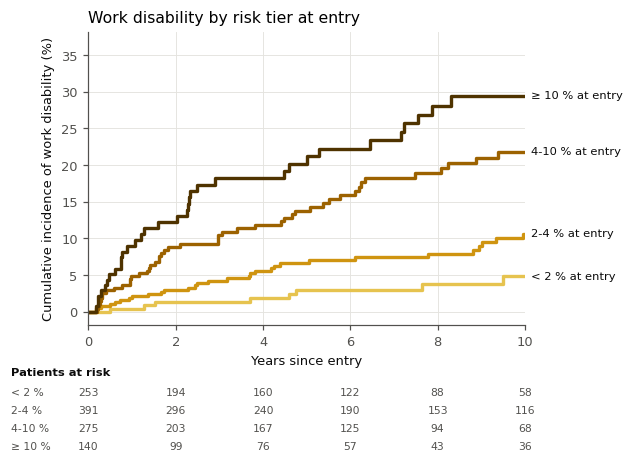

,2 y,4 y,6 y,8 y,10 y
< 2 %,1.3,1.8,3.0,3.8,4.8
2-4 %,3.0,5.6,7.0,7.9,10.6
4-10 %,8.8,11.8,15.9,18.9,21.8
≥ 10 %,12.2,18.2,22.2,28.1,29.4


**What this means.** The risk tier at a patient's first working visit predicts their course for years. After 10
years, 29 % of patients who entered in the highest tier had left work for health reasons,
against 5 % of those who entered in the lowest. The curves separate early and keep
separating. A single score at entry already carries much of the information, which fits risk being largely a stable
characteristic of the patient.

In [36]:
"""Aalen-Johansen cumulative incidence of onset from entry, by entry tier."""


def aalen_johansen(t, c, cause=1):
    """Cumulative incidence of `cause` with competing causes (c = 0 censored)."""
    order = np.argsort(t)
    t, c = t[order], c[order]
    ut = np.unique(t[c > 0])
    S, F, out_t, out_f = 1.0, 0.0, [0.0], [0.0]
    for u in ut:
        n = (t >= u).sum()
        d_all = ((t == u) & (c > 0)).sum()
        d_k = ((t == u) & (c == cause)).sum()
        F += S * d_k / n
        S *= 1 - d_all / n
        out_t.append(u); out_f.append(F)
    return np.array(out_t), np.array(out_f)


_t1 = T_ALL[FIRST_ROW] / 365.25
_c1 = C_ALL[FIRST_ROW]
CIF_YEARS = [0, 2, 4, 6, 8, 10]
fig = plt.figure(figsize=(6.4, 4.6))
ax = fig.add_axes([0.13, 0.36, 0.62, 0.58])
CIF_TABLE = {}
for i, nm in enumerate(TIER_NAMES):
    k = ENTRY_TIER.values == i
    if k.sum() < 10:
        continue
    tt, ff = aalen_johansen(_t1[k], _c1[k])
    ax.step(tt, 100 * ff, where="post", color=TIER_LINE_COLORS[i], lw=2.2)
    f_at = lambda y: 100 * ff[np.searchsorted(tt, y, side="right") - 1]
    ax.text(10.15, f_at(10), f"{nm} at entry", va="center", fontsize=7.5, color=INK)
    CIF_TABLE[nm] = {f"{y} y": f_at(y) for y in CIF_YEARS[1:]}
    for j, y in enumerate(CIF_YEARS):
        fig.text(0.13 + 0.62 * y / 10, 0.22 - 0.035 * i, f"{int((_t1[k] >= y).sum())}", ha="center", fontsize=7,
                 color=INK_2)
    fig.text(0.02, 0.22 - 0.035 * i, nm, fontsize=7, color=INK_2)
fig.text(0.02, 0.26, "Patients at risk", fontsize=7.5, fontweight="bold", color=INK)
ax.set_xlim(0, 10); ax.set_xticks(CIF_YEARS)
ax.set_xlabel("Years since entry"); ax.set_ylabel("Cumulative incidence of work disability (%)")
ax.set_title("Work disability by risk tier at entry", loc="left")
save_fig("risk03_cumulative_incidence_by_entry_tier")
CIF_TABLE = pd.DataFrame(CIF_TABLE).T.round(1)
display(CIF_TABLE)
say(f"""
**What this means.** The risk tier at a patient's first working visit predicts their course for years. After 10
years, {CIF_TABLE.iloc[-1]['10 y']:.0f} % of patients who entered in the highest tier had left work for health reasons,
against {CIF_TABLE.iloc[0]['10 y']:.0f} % of those who entered in the lowest. The curves separate early and keep
separating. A single score at entry already carries much of the information, which fits risk being largely a stable
characteristic of the patient.
""")

## 6.5 Moving between tiers

> **The question.** Once a patient is in a tier, do they stay there?

Panel a: from one working visit to the next, the share of visits that stay in their tier or move (rows sum to
100 %). Panel b follows every patient from entry, every two years: their tier at that time (the last working visit
before it), or the way their follow-up had already ended.

Tier at the next visit,< 2 %,2-4 %,4-10 %,≥ 10 %
Tier at a visit,,,,
< 2 %,89.0,9.0,1.0,0.0
2-4 %,13.0,76.0,10.0,1.0
4-10 %,1.0,22.0,68.0,8.0
≥ 10 %,0.0,3.0,35.0,62.0


,Year 0,Year 2,Year 4,Year 6
≥ 10 %,140,43,36,17
4-10 %,275,177,114,86
2-4 %,391,276,205,162
< 2 %,253,296,288,229
Work disability,0,53,76,94
Other exit from work,0,75,107,132
No longer followed,0,139,233,339


,Episodes,Median duration (months),Share (%)
Follow-up ended,249,56.0,44.0
Other exit from work,73,32.0,13.0
Risk fell: alarm lowered,137,37.0,24.0
Work-disability onset,106,27.0,19.0


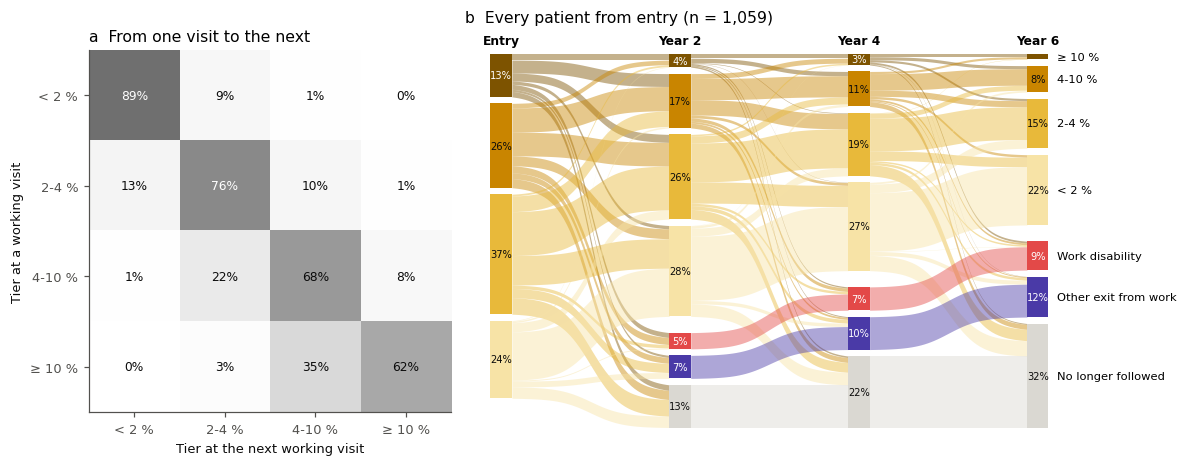

**What this means.**

* **Tiers are stable from visit to visit.** The tier stays the same at 78 % of consecutive working visits
  and jumps by more than one tier at only 1.3 %. Moves happen mostly between neighbouring tiers.
* **Over years, patients drift, and the high tiers feed work disability.** Of patients who entered in the highest tier,
  19 % had left work for health reasons within six years, against
  2 % of those who entered in the lowest tier.

* **How long alarms last.** Of 565 alarm episodes, the median lasted
  45 months (until the risk fell, or follow-up ended). 24 %
  ended because the risk fell below 2 % twice; 19 % ended
  in a work-disability onset.

In practice, a patient's tier is a stable flag that is worth re-checking at each visit, not a number that swings from
one visit to the next.

In [37]:
"""Tier transitions between consecutive visits, and the flow of patients between tiers over six years."""
from matplotlib.patches import Rectangle

_tz = TIER_OF(P_MAIN)
_pair = _cont                                          # the next landmark belongs to the same at-risk episode
_a, _b = _tz[:-1][_pair[:-1]], _tz[1:][_pair[:-1]]
TIER_MOVE = pd.crosstab(pd.Categorical(np.array(TIER_NAMES)[_a], TIER_NAMES),
                        pd.Categorical(np.array(TIER_NAMES)[_b], TIER_NAMES), normalize="index",
                        rownames=["Tier at a visit"], colnames=["Tier at the next visit"])
display((100 * TIER_MOVE).round(0))

FLOW_YEARS = [0, 2, 4, 6]
ABSORB = {1: "Work disability", 2: "Other exit from work", 0: "No longer followed"}
ABSORB_COLORS = {"Work disability": "#e34948", "Other exit from work": C4, "No longer followed": "#dad8d2"}
_entry_ns = ENTRY_DATE.reindex(ALL_PIDS).values
_states = {}
for y in FLOW_YEARS:
    s = []
    for i, p in enumerate(ALL_PIDS):
        if _t1[i] < y:
            s.append(ABSORB[_c1[i]])
        else:
            r = PT_ROWS[p]
            r = r[land["visit_date"].values[r] <= _entry_ns[i] + np.timedelta64(int(y * 365.25), "D")]
            s.append(TIER_NAMES[_tz[r[-1]]])
    _states[y] = np.array(s)
NODE_ORDER = TIER_NAMES[::-1] + list(ABSORB.values())
NODE_COLORS = dict(zip(TIER_NAMES, TIER_COLORS)) | ABSORB_COLORS
FLOW_TABLE = pd.DataFrame({f"Year {y}": pd.Series(_states[y]).value_counts().reindex(NODE_ORDER).fillna(0).astype(int)
                           for y in FLOW_YEARS})
display(FLOW_TABLE)

# ---- alarm episodes: how long an alarm stays up, and how it ends
_fh = FLAGS["HazReg"]
_st = alarm_starts(_fh)
_run = np.cumsum(_st) * _fh                              # episode number at each flagged landmark (0 = not flagged)
_ep_rows = pd.Series(np.flatnonzero(_fh)).groupby(_run[_fh]).agg(["first", "last"])
_nxt_ok = np.r_[PREV_SAME[1:], False]                   # the next landmark continues the chain
_after = _ep_rows["last"].values
_ends_by = np.where(_nxt_ok[_after], "Risk fell: alarm lowered",
                    np.where(C_ALL[_after] == 1, "Work-disability onset",
                             np.where(C_ALL[_after] == 2, "Other exit from work", "Follow-up ended")))
_dur = np.where(_nxt_ok[_after], (LAND_T[np.minimum(_after + 1, N_LAND - 1)] - LAND_T[_ep_rows["first"].values]) / MONTH_DAYS,
                (LAND_T[_after] + np.minimum(T_ALL[_after], 1e9) - LAND_T[_ep_rows["first"].values]) / MONTH_DAYS)
ALARM_EPISODES = pd.DataFrame({"Episodes": pd.Series(_ends_by).value_counts(),
                               "Median duration (months)": pd.Series(_dur).groupby(_ends_by).median().round(0)})
ALARM_EPISODES["Share (%)"] = (100 * ALARM_EPISODES["Episodes"] / ALARM_EPISODES["Episodes"].sum()).round(0)
display(ALARM_EPISODES)


def alluvial(ax, states, years, order, colors, gap=0.02, width=0.12):
    n = len(next(iter(states.values())))
    pos = {}
    for j, y in enumerate(years):
        top = 1.0
        for nd in order:
            h = np.mean(states[y] == nd)
            extra = 0.03 if nd == list(ABSORB.values())[0] else 0
            top -= extra
            pos[(y, nd)] = (top - h, top)
            if h > 0:
                ax.add_patch(Rectangle((j - width / 2, top - h), width, h, color=colors[nd], lw=0, zorder=3))
                if h > 0.025:
                    ax.text(j, top - h / 2, f"{100 * h:.0f}%", ha="center", va="center", fontsize=6.5, zorder=4,
                            color="white" if nd in ("≥ 10 %", "Work disability", "Other exit from work") else INK)
            top -= h + gap
    xs = np.linspace(0, 1, 50)
    sig = 1 / (1 + np.exp(-(xs - 0.5) * 10))
    sig = (sig - sig[0]) / (sig[-1] - sig[0])
    for j in range(len(years) - 1):
        y0, y1 = years[j], years[j + 1]
        out_off = {nd: pos[(y0, nd)][1] for nd in order}
        in_off = {nd: pos[(y1, nd)][1] for nd in order}
        for a in order:
            for b in order:
                h = np.mean((states[y0] == a) & (states[y1] == b))
                if h <= 0:
                    continue
                t0, t1 = out_off[a], in_off[b]
                top = t0 + (t1 - t0) * sig
                ax.fill_between(j + width / 2 + xs * (1 - width), top - h, top, color=colors[a], alpha=0.45, lw=0,
                                zorder=2)
                out_off[a] -= h; in_off[b] -= h
    for j, y in enumerate(years):
        ax.text(j, 1.03, "Entry" if y == 0 else f"Year {y}", ha="center", fontsize=8, fontweight="bold")
    for nd in order:
        lo, hi = pos[(years[-1], nd)]
        if hi - lo > 0:
            ax.text(len(years) - 1 + width / 2 + 0.05, (lo + hi) / 2, nd, va="center", fontsize=7.5)
    ax.set_xlim(-0.2, len(years) - 0.4); ax.set_ylim(min(v[0] for v in pos.values()) - 0.01, 1.07)
    ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [0.8, 1.5]})
ax = axes[0]
_M = 100 * TIER_MOVE.values
ax.imshow(_M, cmap="Greys", vmin=0, vmax=140)
for i in range(len(TIER_NAMES)):
    for j in range(len(TIER_NAMES)):
        ax.text(j, i, f"{_M[i, j]:.0f}%", ha="center", va="center", fontsize=8,
                color="white" if _M[i, j] > 70 else INK)
ax.set_xticks(range(len(TIER_NAMES)), TIER_NAMES); ax.set_yticks(range(len(TIER_NAMES)), TIER_NAMES)
ax.set_xlabel("Tier at the next working visit"); ax.set_ylabel("Tier at a working visit"); ax.grid(False)
ax.set_title("a  From one visit to the next", loc="left")
alluvial(axes[1], _states, FLOW_YEARS, NODE_ORDER, NODE_COLORS)
axes[1].set_title(f"b  Every patient from entry (n = {len(ALL_PIDS):,})", loc="left")
plt.tight_layout(); save_fig("risk04_tier_transitions")
_stay = float(np.mean(_a == _b)); _jump = float(np.mean(np.abs(_a - _b) > 1))
_hi_from = _states[0] == TIER_NAMES[-1]
_lo_from = _states[0] == TIER_NAMES[0]
say(f"""
**What this means.**

* **Tiers are stable from visit to visit.** The tier stays the same at {100 * _stay:.0f} % of consecutive working visits
  and jumps by more than one tier at only {100 * _jump:.1f} %. Moves happen mostly between neighbouring tiers.
* **Over years, patients drift, and the high tiers feed work disability.** Of patients who entered in the highest tier,
  {100 * np.mean(_states[6][_hi_from] == "Work disability"):.0f} % had left work for health reasons within six years, against
  {100 * np.mean(_states[6][_lo_from] == "Work disability"):.0f} % of those who entered in the lowest tier.

* **How long alarms last.** Of {int(ALARM_EPISODES['Episodes'].sum())} alarm episodes, the median lasted
  {np.median(_dur):.0f} months (until the risk fell, or follow-up ended). {ALARM_EPISODES['Share (%)'].get('Risk fell: alarm lowered', 0):.0f} %
  ended because the risk fell below 2 % twice; {ALARM_EPISODES['Share (%)'].get('Work-disability onset', 0):.0f} % ended
  in a work-disability onset.

In practice, a patient's tier is a stable flag that is worth re-checking at each visit, not a number that swings from
one visit to the next.
""")

## 6.6 How the risk changes as an onset approaches

> **The question.** Does a patient's predicted risk climb in the years before they leave work, or is it high all
> along?

Panel a aligns every patient who left work for health reasons at their onset and shows the predicted risk at their
working visits in the eight years before it (median and interquartile range in 6-month bins; faint lines are
individual patients). Patients who never left work are aligned at their last working visit. Panel b shows, for the
patients with an onset, which tier their visits were in at each time before the onset.

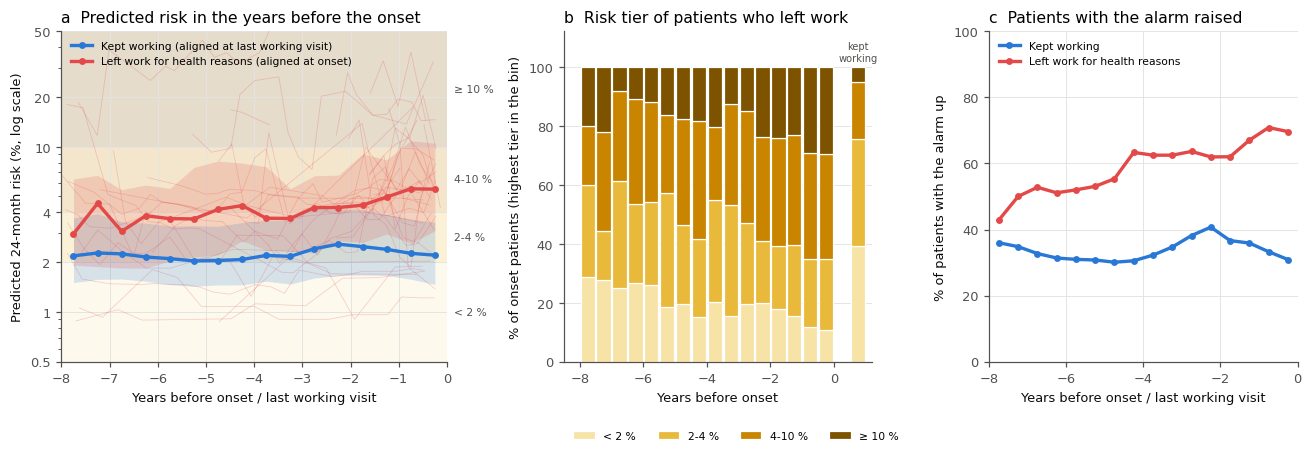

**What this means.**

* **Risk is raised long before the onset.** Four to six years before leaving work, the median predicted risk of
  patients who later did so was already 4.0 %, against 2.1 % in patients who kept working
  (1.9 times higher).
* **It rises further in the final years.** In the last year before the onset the median was 5.6 %
  (1.4 times its level four to six years earlier), while it stayed at 2.2 % in patients who
  kept working.
* **The share in a raised tier grows as the onset nears.** 50 % of onset patients had a visit in the 4-10 %
  or ≥ 10 % tier four to six years before the onset, and 65 % in the final year. Among the visits of patients
  who kept working, 24 % were in these tiers.

* **The alarm follows the same pattern.** 56 %
  of onset patients had the alarm up four to six years before the onset, and
  70 % in the
  final year; among patients who kept working, 34 % at any given time.

The score therefore works as **stratification first** (it picks out who is at higher risk years ahead) with a
**modest early-warning component** on top (risk climbs as the onset nears). Both support asking high-tier patients
about work at every visit.

In [38]:
"""Onset-aligned predicted risk (median, IQR) and the tier mix before the onset."""
_ok2 = (MO_BEFORE > 0) & (MO_BEFORE <= TRAJ_MAX_MONTHS)
_dfa = pd.DataFrame({"pid": PID_ALL, "ev": _ever, "bin": _bin, "mo": MO_BEFORE, "p": 100 * P_MAIN, "tier": _tz})[_ok2]
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.9), gridspec_kw={"width_ratios": [1.25, 1, 1], "wspace": 0.35})
ax = axes[0]
_tier_bands(ax, orient="y", alpha=0.2)
_rng = np.random.RandomState(SEED)
for p in _rng.choice(_dfa.loc[_dfa["ev"], "pid"].unique(), 40, replace=False):
    d = _dfa[_dfa["pid"] == p].sort_values("mo")
    ax.plot(-d["mo"] / 12, d["p"], color="#e34948", lw=0.5, alpha=0.25, zorder=1)
RISK_BEFORE = {}
for ev, col, nm in [(False, C1, "Kept working (aligned at last working visit)"),
                    (True, "#e34948", "Left work for health reasons (aligned at onset)")]:
    g = _dfa[_dfa["ev"] == ev].groupby(["bin", "pid"])["p"].mean().groupby("bin")
    q = g.quantile([0.25, 0.5, 0.75]).unstack()
    n = g.size()
    q = q[n >= 10]
    xs = -(_bins[q.index.values - 1] + 3) / 12
    ax.fill_between(xs, q[0.25], q[0.75], color=col, alpha=0.18, lw=0, zorder=2)
    ax.plot(xs, q[0.5], "-o", ms=3.5, color=col, lw=2.2, zorder=3, label=nm)
    RISK_BEFORE[nm] = pd.Series(q[0.5].values, index=xs)
ax.set_yscale("log"); ax.set_ylim(0.5, 50)
ax.set_yticks([0.5, 1, 2, 4, 10, 20, 50], ["0.5", "1", "2", "4", "10", "20", "50"])
ax.set_xlabel("Years before onset / last working visit"); ax.set_ylabel("Predicted 24-month risk (%, log scale)")
ax.legend(loc="upper left", fontsize=7)
ax.set_title("a  Predicted risk in the years before the onset", loc="left")
for k, nm in enumerate(TIER_NAMES):
    lo = max(RISK_TIERS[k][0], 0.005) * 100; hi = min(RISK_TIERS[k][1], 0.5) * 100
    ax.text(0.15, np.sqrt(lo * hi), nm, va="center", fontsize=7, color=INK_2, clip_on=False)
ax.set_xlim(-TRAJ_MAX_MONTHS / 12, 0)

ax = axes[1]
_mix = (_dfa[_dfa["ev"]].groupby(["bin", "pid"])["tier"].max().reset_index()
        .pipe(lambda d: pd.crosstab(d["bin"], d["tier"], normalize="index")).reindex(columns=range(4), fill_value=0))
_mix = _mix[_dfa[_dfa["ev"]].groupby("bin")["pid"].nunique().reindex(_mix.index) >= 10]
_xb = -(_bins[_mix.index.values - 1] + 3) / 12
_ctrl = pd.Series(_tz[~_ever]).value_counts(normalize=True).reindex(range(4)).fillna(0)
bottom = np.zeros(len(_mix))
for k in range(4):
    ax.bar(_xb, 100 * _mix[k].values, 0.45, bottom=bottom, color=TIER_COLORS[k], edgecolor="white", linewidth=0.8,
           label=TIER_NAMES[k])
    bottom += 100 * _mix[k].values
bottom = 0
for k in range(4):
    ax.bar(0.75, 100 * _ctrl[k], 0.45, bottom=bottom, color=TIER_COLORS[k], edgecolor="white", linewidth=0.8)
    bottom += 100 * _ctrl[k]
ax.text(0.75, 102, "kept\nworking", ha="center", fontsize=6.5, color=INK_2)
ax.set_xlim(-TRAJ_MAX_MONTHS / 12 - 0.5, 1.2); ax.set_ylim(0, 112)
ax.set_xlabel("Years before onset"); ax.set_ylabel("% of onset patients (highest tier in the bin)")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.18), ncol=4, fontsize=7, title=None)
ax.grid(axis="x", visible=False)
ax.set_title("b  Risk tier of patients who left work", loc="left")
ax = axes[2]
_dfa["flag"] = FLAGS["HazReg"][_ok2]
ALARM_BEFORE = {}
for ev, col, nm in [(False, C1, "Kept working"), (True, "#e34948", "Left work for health reasons")]:
    g = _dfa[_dfa["ev"] == ev].groupby(["bin", "pid"])["flag"].max().groupby("bin")
    sh, n = g.mean(), g.size()
    sh = sh[n >= 10]
    xs = -(_bins[sh.index.values - 1] + 3) / 12
    ax.plot(xs, 100 * sh.values, "-o", ms=3.5, color=col, lw=2.2, label=nm)
    ALARM_BEFORE[nm] = pd.Series(100 * sh.values, index=xs)
ax.set_ylim(0, 100); ax.set_xlim(-TRAJ_MAX_MONTHS / 12, 0)
ax.set_xlabel("Years before onset / last working visit"); ax.set_ylabel("% of patients with the alarm up")
ax.legend(loc="upper left", fontsize=7)
ax.set_title("c  Patients with the alarm raised", loc="left")
save_fig("risk05_approaching_onset")
_on = RISK_BEFORE["Left work for health reasons (aligned at onset)"]
_ct = RISK_BEFORE["Kept working (aligned at last working visit)"]
_far = _on[(_on.index <= -4) & (_on.index >= -6)].mean(); _near = _on[_on.index >= -1].mean()
_cfar = _ct[(_ct.index <= -4) & (_ct.index >= -6)].mean(); _cnear = _ct[_ct.index >= -1].mean()
_hi2 = pd.Series(100 * (_mix[2] + _mix[3]).values, index=_xb)
_hn, _hf = _hi2[_hi2.index >= -1].mean(), _hi2[(_hi2.index <= -4) & (_hi2.index >= -6)].mean()
_hc = 100 * (_ctrl[2] + _ctrl[3])
say(f"""
**What this means.**

* **Risk is raised long before the onset.** Four to six years before leaving work, the median predicted risk of
  patients who later did so was already {_far:.1f} %, against {_cfar:.1f} % in patients who kept working
  ({_far / _cfar:.1f} times higher).
* **It rises further in the final years.** In the last year before the onset the median was {_near:.1f} %
  ({_near / _far:.1f} times its level four to six years earlier), while it stayed at {_cnear:.1f} % in patients who
  kept working.
* **The share in a raised tier grows as the onset nears.** {_hf:.0f} % of onset patients had a visit in the 4-10 %
  or ≥ 10 % tier four to six years before the onset, and {_hn:.0f} % in the final year. Among the visits of patients
  who kept working, {_hc:.0f} % were in these tiers.

* **The alarm follows the same pattern.** {ALARM_BEFORE['Left work for health reasons'][(ALARM_BEFORE['Left work for health reasons'].index <= -4) & (ALARM_BEFORE['Left work for health reasons'].index >= -6)].mean():.0f} %
  of onset patients had the alarm up four to six years before the onset, and
  {ALARM_BEFORE['Left work for health reasons'][ALARM_BEFORE['Left work for health reasons'].index >= -1].mean():.0f} % in the
  final year; among patients who kept working, {ALARM_BEFORE['Kept working'].mean():.0f} % at any given time.

The score therefore works as **stratification first** (it picks out who is at higher risk years ahead) with a
**modest early-warning component** on top (risk climbs as the onset nears). Both support asking high-tier patients
about work at every visit.
""")

## 6.7 The risk over time in individual patients

Eight patients, each followed from entry: four who left work for health reasons and four who kept working
(Patients A and B of Section 1.6.3 are the first in each row; the others are drawn at random). Each dot is the
cross-validated risk at a working visit, red where the alarm is up; the background shows the tiers.

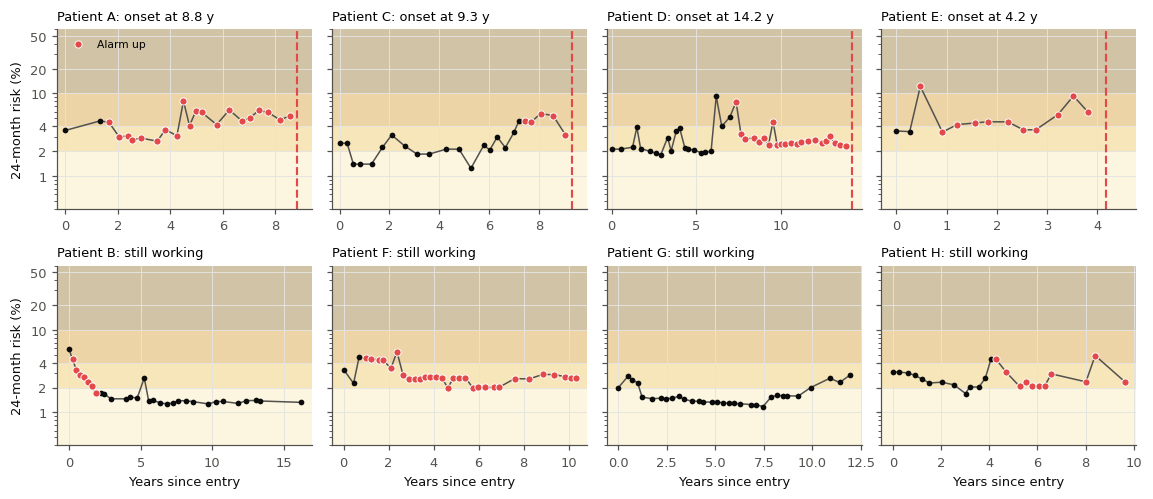

**What this means.** Individual risks move with each visit, but most patients stay within one or two tiers for
years. The red dots show how the alarm follows these trajectories. Patients who go on to leave work tend to sit in the upper tiers for a long time, sometimes with a further rise
before the onset; patients who keep working mostly sit in the lower tiers. The tier, re-checked at each visit, is the
practical output.

In [39]:
"""Risk trajectories of eight patients (cross-validated risk at each working visit)."""
_rng = np.random.RandomState(SEED + 1)
_more_on = [p for p in _rng.permutation(CAND_ONSET) if p != EXAMPLE_PIDS[0]][:3]
_more_w = [p for p in _rng.permutation(CAND_WORKING) if p != EXAMPLE_PIDS[1]][:3]
_show = [EXAMPLE_PIDS[0]] + _more_on + [EXAMPLE_PIDS[1]] + _more_w
_labels = ["A"] + ["C", "D", "E"] + ["B"] + ["F", "G", "H"]
fig, axes = plt.subplots(2, 4, figsize=(10.6, 4.6), sharey=True)
for ax, p, lab in zip(axes.ravel(), _show, _labels):
    r = PT_ROWS[p]
    if p in FIRST_ONSET_DATE.index:
        r = r[land["visit_date"].values[r] < np.datetime64(FIRST_ONSET_DATE[p])]
    x = _yrs(land["visit_date"].values[r], p)
    _tier_bands(ax, orient="y", alpha=0.35)
    ax.plot(x, 100 * P_MAIN[r], "-", color=INK_2, lw=1, zorder=2)
    _f = FLAGS["HazReg"][r]
    ax.scatter(x[~_f], 100 * P_MAIN[r][~_f], s=14, color=INK, zorder=3, linewidths=0)
    ax.scatter(x[_f], 100 * P_MAIN[r][_f], s=22, color="#e34948", zorder=4, edgecolor="white", linewidths=0.6,
               label="Alarm up" if lab == "A" else None)
    if p in FIRST_ONSET_DATE.index:
        xo = _yrs(FIRST_ONSET_DATE[p], p)
        ax.axvline(xo, color="#e34948", lw=1.4, ls="--")
        ax.set_xlim(-0.3, xo + 0.6)
        ttl = f"Patient {lab}: onset at {xo:.1f} y"
    else:
        ttl = f"Patient {lab}: still working"
    ax.set_title(ttl, loc="left", fontsize=8.5)
    ax.set_yscale("log"); ax.set_ylim(0.4, 60)
    ax.set_yticks([1, 2, 4, 10, 20, 50], ["1", "2", "4", "10", "20", "50"])
for ax in axes[1]:
    ax.set_xlabel("Years since entry")
for ax in axes[:, 0]:
    ax.set_ylabel("24-month risk (%)")
axes[0, 0].legend(fontsize=7, loc="upper left")
plt.tight_layout(); save_fig("risk06_individual_trajectories")
say("""
**What this means.** Individual risks move with each visit, but most patients stay within one or two tiers for
years. The red dots show how the alarm follows these trajectories. Patients who go on to leave work tend to sit in the upper tiers for a long time, sometimes with a further rise
before the onset; patients who keep working mostly sit in the lower tiers. The tier, re-checked at each visit, is the
practical output.
""")

---
# Part VII. Checks that do not depend on the analysts

> **Why this part exists.** Everything above was done by the people who built the model. However careful, that is
> not independent evidence. The four checks below are. This part produces the material each one needs and reads
> the results back automatically once they exist.

1. **A frozen model and a future test** (7.1). The final model is written to a file whose SHA-256 hash can be
   registered publicly (for example on OSF) before new data exist. When the clinic issues its next extract, the
   visits after the freeze date are scored with that file and nothing else. This is the only truly prospective
   validation available, and nobody can tune it.
2. **Chart adjudication of the outcome** (7.2). A clinician blinded to the model reviews a stratified sample of
   onsets and non-onsets in the chart. Agreement with the algorithm (κ, PPV, NPV) measures how often the outcome is
   right.
3. **The clinicians' own judgement** (7.3). Rheumatologists estimate the 24-month risk for a sample of visits
   from the same routine fields. If the model does not beat them, it adds nothing to the clinic.
4. **The measures the clinic database holds but this extract does not** (7.4). These are SF-36, the fatigue
   severity scale and patient global, the yearly health-care and work-productivity questionnaire (absence days,
   at-work impairment, self-rated ability to work), the full blood count, albumin, urine protein/creatinine, and
   the social-factor form. When the tables are placed in the `requested` folder, their added value is tested
   block by block with the same validation.

## 7.1 The frozen model

The file holds the final model **and** its temporal recalibration (Section 4.3), with the window it was estimated
on, and the patient-alarm rule (Section 2.5). A future extract is scored with the deployed (recalibrated) risks. The as-developed risks can be reproduced
from the same file.

In [40]:
"""Frozen model: everything needed to compute a risk, in one hashed file; a scorer that reads only that file."""
FREEZE_DATE = str(DATA_END_DATE.date())
FROZEN = {"name": "HazReg", "tag": TAG, "freeze_date": FREEZE_DATE, "horizon_months": H,
          "risk": "cumulative incidence of onset under constant cause-specific hazards: "
                  "l1/(l1+l2)*(1-exp(-(l1+l2)*months/12)), l_k = exp(intercept_k + x . coef_k) per year",
          "preprocessing": FINAL["prep"].to_dict(), "terms": FINAL["prep"].names,
          "coef_onset": FINAL["coef"][0].tolist(), "coef_competing": FINAL["coef"][1].tolist(),
          "intercept": FINAL["intercept"].tolist(), "ridge_alpha": FINAL["alphas"],
          "temporal_recalibration": {"window_start": str(_wdate(W0)), "window_end": str(_wdate(W1)),
                                     "added_to_intercept": DEPLOY_SHIFT.tolist(),
                                     "rule": f"baseline log-hazards re-estimated on the person-time of the {RECAL_YEARS} "
                                             f"years ending {RECAL_LAG_MONTHS} months before the data end"},
          "patient_alarm": {**ALARM_RULE, "rule": "raise when risk >= on at n_on consecutive working visits, or >= high at "
                                                   "one visit; keep until risk < off at n_off consecutive visits; restart "
                                                   "after an onset, another exit or a gap in follow-up"},
          "development": {"landmarks": int(N_LAND), "patients": int(P_N), "onsets": int(D1.sum()),
                          "person_years": round(float(INT_YRS.sum()), 1)},
          "source_sha256": source_hashes()}
FROZEN_JSON = json.dumps(FROZEN, sort_keys=True, indent=1)
FROZEN_HASH = hashlib.sha256(FROZEN_JSON.encode()).hexdigest()
FROZEN_PATH = f"frozen_model_{TAG}.json"
if not SMOKE:
    with open(FROZEN_PATH, "w") as f:
        f.write(FROZEN_JSON)


def score_frozen(frozen, X, deployed=True):
    """24-month risk from the frozen file alone (X: one row per visit, raw inputs). deployed=True adds the temporal
    recalibration; False gives the model as developed."""
    pp = frozen["preprocessing"]
    Z = pd.DataFrame(index=X.index)
    for c in pp["cols"]:
        x = X[c].astype(float)
        Z[c] = np.sign(x) * np.log1p(np.abs(x)) if c in pp["log1p"] else x
    miss = Z[pp["missing_indicators"]].isna().astype(float)
    Z = Z.fillna(pd.Series(pp["median"]))
    for c, kn in pp["knots"].items():
        Z[f"{c}__NL"] = rcs_nl(Z[c].values, kn)
    Z = ((Z - pd.Series(pp["mean"])) / pd.Series(pp["sd"])).clip(-pp["clip_z"], pp["clip_z"])
    M = np.hstack([Z[[t for t in frozen["terms"] if not t.endswith("__MISSING")]].values, miss.values])
    shift = frozen["temporal_recalibration"]["added_to_intercept"] if deployed else [0.0, 0.0]
    eta = np.column_stack([M @ np.array(frozen[k]) + frozen["intercept"][i] + shift[i]
                           for i, k in enumerate(["coef_onset", "coef_competing"])])
    return cif(eta, frozen["horizon_months"])


_chk = score_frozen(json.loads(FROZEN_JSON), LAND_X, deployed=False)
assert np.allclose(_chk, P_FULL, atol=1e-10), "the frozen file does not reproduce the final model"
assert np.allclose(score_frozen(json.loads(FROZEN_JSON), LAND_X), P_DEPLOY, atol=1e-10), \
    "the frozen file does not reproduce the deployed model"
print(f"Frozen model {'(not written in a smoke run) ' if SMOKE else FROZEN_PATH + ' '}| freeze date {FREEZE_DATE} | "
      f"SHA-256 {FROZEN_HASH}\nThe file alone reproduces the final model's risks on all {N_LAND:,} landmarks "
      f"(max difference {np.abs(_chk - P_FULL).max():.1e}), as developed and as deployed.")


def prospective_validation(new_source_dir, frozen_path=FROZEN_PATH):
    """Run on a LATER extract (same table layout). Scores every landmark after the freeze date with the frozen file,
    writes the predictions with a timestamp, and evaluates them on whatever 24-month follow-up exists."""
    frozen = json.load(open(frozen_path))
    assert hashlib.sha256(json.dumps(frozen, sort_keys=True, indent=1).encode()).hexdigest() == FROZEN_HASH, \
        "the frozen file has changed since it was registered"
    v_new = build_visits(new_source_dir)
    l_new = build_landmarks(v_new)
    end_new = v_new["ASSDT"].max()
    l_new = l_new[l_new["visit_date"] > pd.Timestamp(frozen["freeze_date"])].reset_index(drop=True)
    if not len(l_new):
        print("No landmark after the freeze date in this extract.")
        return None
    X = v_new.loc[l_new["visit_row"], frozen["preprocessing"]["cols"]].reset_index(drop=True)
    l_new["risk_24m"] = score_frozen(frozen, X, deployed=False)
    l_new["risk_24m_recalibrated"] = score_frozen(frozen, X, deployed=True)
    out = f"prospective_predictions_{pd.Timestamp.now():%Y%m%d}.csv"
    l_new[["pid", "visit_date", "risk_24m", "risk_24m_recalibrated"]].to_csv(out, index=False)
    t, c = l_new["time_days"].values.astype(float), l_new["cause"].values
    age = v_new.loc[l_new["visit_row"], "age_at_record"].values
    adm = np.minimum((end_new - l_new["visit_date"]).dt.days.values, (AGE_CAP_YEARS - age) * 365.25)
    y, w = ipcw_weights(t, c)
    print(f"{len(l_new):,} landmarks after {frozen['freeze_date']} ({l_new['pid'].nunique():,} patients) -> {out}; "
          f"{int((adm >= HORIZON_DAYS).sum()):,} have 24 months of potential follow-up; onsets within 24 months "
          f"{int((y * (w > 0)).sum())}")
    if (y * (w > 0)).sum() >= 10:
        for col, lab in [("risk_24m", "as developed"), ("risk_24m_recalibrated", "recalibrated")]:
            A = metric_arrays(l_new[col].values, np.ones((1, len(l_new))), y, w, np.full(len(l_new), "prospective"))
            print(f"Prospective ({lab}): AUROC {A['AUROC'][0]:.3f}, O/E {A['O/E'][0]:.2f}, IPA {A['IPA'][0]:.3f}")
    return l_new


print("When the next extract arrives: prospective_validation('<folder of the new extract>').")

Frozen model frozen_model_update_v22.json | freeze date 2024-04-08 | SHA-256 eadad1794b122eab935772983c541d6646787ca7b1bb438bd0a7fda16e04cf79
The file alone reproduces the final model's risks on all 17,338 landmarks (max difference 1.1e-16), as developed and as deployed.
When the next extract arrives: prospective_validation('<folder of the new extract>').


## 7.2 Chart adjudication of the outcome

A stratified sample: onsets by route, and non-onsets of three kinds (a competing exit; censored after leaving the
clinic while employed; followed for ≥ 24 months without an onset). For each sampled episode the file lists the
patient, the landmark, the algorithm's classification and the status sequence around it, with empty columns for
the reviewer. The reviewer works from the chart, blinded to the algorithm's class: hide those columns before
review. The file is written once and never overwritten. A completed copy saved as `..._reviewed.csv` is read
back.

In [41]:
"""Adjudication sample (written once) and agreement once reviewed."""
ADJ_PATH = f"adjudication_sample_{TAG}.csv"
ADJ_REVIEWED = ADJ_PATH.replace(".csv", "_reviewed.csv")


def _status_string(pid, center, before_y=2, after_y=3):
    s = visits.loc[(visits["PTNO"] == pid) & visits["HAS_STATUS"], ["ASSDT", "EMP"]]
    s = s[(s["ASSDT"] >= center - pd.DateOffset(years=before_y)) & (s["ASSDT"] <= center + pd.DateOffset(years=after_y))]
    return "; ".join(f"{d:%Y-%m-%d} {e}" for d, e in zip(s["ASSDT"], s["EMP"]))


if not os.path.exists(ADJ_PATH) and not SMOKE:
    rng = np.random.RandomState(SEED + 11)
    first = land.groupby(["pid", "cause", "exit_type"], sort=False).head(1)
    strata = {"onset: direct (disabled)": first[(first["cause"] == 1) & (first["route"] == "direct")],
              "onset: long sick spell": first[(first["cause"] == 1) & (first["route"] == "long sick spell")],
              "onset: short spell then disabled": first[(first["cause"] == 1) & (first["route"] == "short sick spell")],
              "competing exit": first[first["cause"] == 2],
              "censored: left clinic while employed": first[first["pid"].isin(LEFT_CLINIC_PIDS) & (first["cause"] == 0)],
              "event-free >= 24 months": land[(Y24 == 0) & (C_ALL == 0)].groupby("pid").head(1)}
    n_take = {"onset: direct (disabled)": 25, "onset: long sick spell": 25, "onset: short spell then disabled": 10,
              "competing exit": 20, "censored: left clinic while employed": 20, "event-free >= 24 months": 20}
    rows = []
    for s, d in strata.items():
        d = d.drop_duplicates("pid")
        d = d.iloc[rng.permutation(len(d))[:n_take[s]]]
        for r in d.itertuples():
            center = r.event_date if pd.notna(r.event_date) else r.visit_date + pd.Timedelta(days=r.time_days)
            rows.append({"PTNO": r.pid, "landmark_date": r.visit_date.date(), "stratum": s,
                         "algorithm_onset": int(r.cause == 1),
                         "algorithm_end_date": (r.visit_date + pd.Timedelta(days=r.time_days)).date(),
                         "status_sequence": _status_string(r.pid, center),
                         "reviewer_left_work_for_health": "", "reviewer_date": "", "reviewer_notes": ""})
    pd.DataFrame(rows).sample(frac=1, random_state=SEED).to_csv(ADJ_PATH, index=False)
    print(f"Adjudication sample written: {ADJ_PATH} ({len(rows)} episodes).")
if os.path.exists(ADJ_REVIEWED):
    a = pd.read_csv(ADJ_REVIEWED).dropna(subset=["reviewer_left_work_for_health"])
    yr, ya = a["reviewer_left_work_for_health"].astype(int).values, a["algorithm_onset"].values
    po = (yr == ya).mean(); pe = yr.mean() * ya.mean() + (1 - yr.mean()) * (1 - ya.mean())
    print(f"Adjudicated {len(a)} episodes: agreement {po:.0%}, kappa {(po - pe) / (1 - pe):.2f}, algorithm PPV "
          f"{yr[ya == 1].mean():.0%}, NPV {(1 - yr[ya == 0]).mean():.0%} (sample stratified: not population rates)")
else:
    print(f"Not yet adjudicated: complete {ADJ_PATH} and save it as {ADJ_REVIEWED}.")

Adjudication sample written: adjudication_sample_update_v22.csv (115 episodes).
Not yet adjudicated: complete adjudication_sample_update_v22.csv and save it as adjudication_sample_update_v22_reviewed.csv.


## 7.3 The clinicians' judgement as a comparator

120 landmark visits from different patients: 40 followed by an onset within 24 months and 80 with a known
24-month status and no onset. Each case shows the same fields the model reads, under a random case number. One or
more rheumatologists enter a 24-month risk (%) for each. The key linking case numbers to visits is a separate
file. The comparison is paired, on the same cases.

In [42]:
"""Clinician comparator: export once, compare once completed."""
CLIN_PATH, CLIN_KEY = f"clinician_cases_{TAG}.csv", f"clinician_key_{TAG}.csv"
CLIN_DONE = CLIN_PATH.replace(".csv", "_completed.csv")
if not os.path.exists(CLIN_PATH) and not SMOKE:
    rng = np.random.RandomState(SEED + 13)
    known = np.flatnonzero(~np.isnan(Y24))
    pick = []
    for yv, n in [(1, 40), (0, 80)]:
        cand = known[Y24[known] == yv]
        cand = cand[rng.permutation(len(cand))]
        seen = set()
        for i in cand:
            if PID_ALL[i] not in seen and PID_ALL[i] not in {PID_ALL[j] for j in pick}:
                pick.append(i); seen.add(PID_ALL[i])
            if len(seen) == n:
                break
    pick = rng.permutation(pick)
    cases = LAND_X.iloc[pick][COMPACT_VARS].copy()
    cases.columns = [DISPLAY[c] for c in COMPACT_VARS]
    cases.insert(0, "Sex", np.where(land["SEX_FEMALE"].values[pick] == 1, "F", "M"))
    cases.insert(0, "case", np.arange(1, len(pick) + 1))
    cases["clinician_risk_percent"] = ""
    cases.round(2).to_csv(CLIN_PATH, index=False)
    pd.DataFrame({"case": np.arange(1, len(pick) + 1), "landmark_row": pick}).to_csv(CLIN_KEY, index=False)
    print(f"Clinician cases written: {CLIN_PATH} (key: {CLIN_KEY}).")
if os.path.exists(CLIN_DONE) and os.path.exists(CLIN_KEY):
    cd_ = pd.read_csv(CLIN_DONE).merge(pd.read_csv(CLIN_KEY), on="case").dropna(subset=["clinician_risk_percent"])
    r_ = cd_["landmark_row"].values
    yv, pc, pm = Y24[r_], cd_["clinician_risk_percent"].values.astype(float), P_MAIN[r_]
    rng = np.random.RandomState(SEED)
    Wc = np.vstack([np.ones(len(r_)), rng.multinomial(len(r_), np.full(len(r_), 1 / len(r_)), 1000)])
    ac, am = wauc(yv, pc, Wc), wauc(yv, pm, Wc)
    d = am - ac
    print(f"{len(r_)} cases: clinician AUROC {ac[0]:.3f}, model AUROC {am[0]:.3f}, model - clinician {d[0]:+.3f} "
          f"(95% CI {np.percentile(d[1:], 2.5):+.3f} to {np.percentile(d[1:], 97.5):+.3f})")
else:
    print(f"Not yet completed: fill {CLIN_PATH} (column clinician_risk_percent) and save it as {CLIN_DONE}.")

Clinician cases written: clinician_cases_update_v22.csv (key: clinician_key_update_v22.csv).
Not yet completed: fill clinician_cases_update_v22.csv (column clinician_risk_percent) and save it as clinician_cases_update_v22_completed.csv.


## 7.4 Measures held by the clinic database but not in this extract

Each table, once delivered, gives one **block** of at most three variables. The most recent value
before the landmark is used: within 18 months for the yearly questionnaires, within 12 months for visit-level
tables. Each block is tested on the landmarks where it exists, with HazReg against HazReg + block in the same
cross-validation (5-fold × 2), paired.

In [43]:
"""Requested tables: specification, features, added value (runs only when the tables are present)."""
REQUEST_DIR = os.environ.get("SLE_REQUEST_DIR", REQUEST_DIR)
RAND = {"PF": (["LIMITVA", "LIMITMA", "LIMITLC", "LIMITSF", "LIMITOF", "LIMITBK", "LIMITKM", "LIMITSB", "LIMITOB",
                "LIMITBD"], {1: 0, 2: 50, 3: 100}, {}),
        "VT": (["TMPEP", "TMENER"], {1: 100, 2: 80, 3: 60, 4: 40, 5: 20, 6: 0},
               {"TMWORN": {1: 0, 2: 20, 3: 40, 4: 60, 5: 80, 6: 100}, "TMTIRE": {1: 0, 2: 20, 3: 40, 4: 60, 5: 80, 6: 100}}),
        "MH": (["TMCALM", "TMHAPP"], {1: 100, 2: 80, 3: 60, 4: 40, 5: 20, 6: 0},
               {c: {1: 0, 2: 20, 3: 40, 4: 60, 5: 80, 6: 100} for c in ["TMNERV", "TMDOWN", "TMBLUE"]})}


def _sf36(d):
    out = pd.DataFrame(index=d.index)
    for dom, (items, code, extra) in RAND.items():
        parts = [pd.to_numeric(d[c], errors="coerce").map(code) for c in items if c in d]
        parts += [pd.to_numeric(d[c], errors="coerce").map(m) for c, m in extra.items() if c in d]
        out[f"SF36_{dom}"] = pd.concat(parts, axis=1).mean(axis=1)
    return out


def _fatigue(d):
    items = ["MOTIVATE", "EXERCISE", "EASILY", "INTERFER", "PROBLEMS", "PREVENT", "DUTIES", "DEBILITA", "SOCIAL"]
    x = d[[c for c in items if c in d]].apply(pd.to_numeric, errors="coerce")
    return pd.DataFrame({"FSS_MEAN": x.mean(axis=1).where(x.notna().sum(axis=1) >= 5),
                         "PT_GLOBAL": pd.to_numeric(d.get("GLOBAL"), errors="coerce")})


def _healthc(d):
    num = lambda c: pd.to_numeric(d.get(c), errors="coerce")
    return pd.DataFrame({"ABSENT_DAYS_3M": num("AFW_HEALTH"), "PRESENTEEISM_0_10": num("HEALTH_NEFF_WORK"),
                         "SELF_RATED_UNABLE_FT": ((num("WORK_PT") == 1) | (num("UNABLE_WORK") == 1)).astype(float)
                         .where(num("WORK_FT").notna() | num("WORK_PT").notna() | num("UNABLE_WORK").notna())})


def _lab1(d):
    num = lambda c: pd.to_numeric(d.get(c), errors="coerce")
    return pd.DataFrame({"HGB": num("HGB"), "ALBUMIN": num("ALBUMIN"), "UPCR": num("RPROT_CREAT")})


def _socfact(d):
    num = lambda c: pd.to_numeric(d.get(c), errors="coerce")
    return pd.DataFrame({"HOSP_SINCE_LAST": num("HOSPLV"),
                         "PARTNERED": num("MARITAL").isin([2, 6]).astype(float).where(num("MARITAL").notna())})


REQUESTED = {  # file: (database table, key, date column, feature function, why)
    "sf36.csv": ("SF36", "date", "CLDATE", _sf36, "physical function, vitality, mental health (yearly)"),
    "fatigue.csv": ("FATIGUE", "date", "CLDATE", _fatigue, "fatigue severity scale, patient global (yearly)"),
    "lup_healthc.csv": ("LUP_HEALTHC", "date", "ASSDT", _healthc,
                        "absence days, at-work impairment, self-rated ability to work (yearly, from 2016)"),
    "lab1.csv": ("LAB1", "visit", None, _lab1, "haemoglobin, albumin, urine protein/creatinine"),
    "socfact.csv": ("SOCFACT", "visit", None, _socfact, "hospitalised since last visit, partnered"),
}
_present = {f: spec for f, spec in REQUESTED.items() if os.path.exists(os.path.join(REQUEST_DIR, f))}
display(pd.DataFrame([{"File": f, "Clinic database table": s[0], "Block": s[4],
                       "Present": f in _present} for f, s in REQUESTED.items()]).set_index("File"))


def _attach(fname, spec):
    tab, key, dcol, fn, _ = spec
    d = pd.read_csv(os.path.join(REQUEST_DIR, fname), low_memory=False)
    d.columns = [c.upper() for c in d.columns]
    F = fn(d)
    cols = list(F.columns)
    if key == "visit":
        vv = visits[["ID", "PTNO", "ASSDT"]].merge(pd.concat([d[["ID"]], F], axis=1).drop_duplicates("ID"),
                                                   on="ID", how="left")
        seen = vv["ASSDT"].where(vv[cols].notna().any(axis=1)).groupby(vv["PTNO"]).ffill()
        vv[cols] = vv.groupby("PTNO")[cols].ffill()
        vv.loc[(vv["ASSDT"] - seen).dt.days > 365, cols] = np.nan
        return pd.DataFrame(vv.loc[land["visit_row"].values, cols].values, columns=cols)
    F["PTNO"] = pd.to_numeric(d["PTNO"], errors="coerce").astype(float)
    F["DATE"] = _date(d[dcol.upper()])
    F = F.dropna(subset=["PTNO", "DATE"]).sort_values("DATE")
    L = pd.DataFrame({"PTNO": PID_ALL.astype(float), "DATE": land["visit_date"].values, "_i": np.arange(N_LAND)})
    m = pd.merge_asof(L.sort_values("DATE"), F, on="DATE", by="PTNO", direction="backward",
                      tolerance=pd.Timedelta(days=548)).sort_values("_i")
    return m[cols].reset_index(drop=True)


def _cv_rows_fold(rows, tr_pids, te_pids, cols, spline, seed):
    te_local = np.flatnonzero(np.isin(PID_ALL[rows], te_pids))
    m = fit_procedure(rows[np.isin(PID_ALL[rows], tr_pids)], cols, spline, seed=seed)
    return te_local, cif(predict_eta(m, rows[te_local]))


def _cv_rows(rows, cols, spline, repeats=2, splits=5):
    """Cross-validated risks on a subset of landmarks (patient-grouped, stratified by ever-onset)."""
    pids = np.unique(PID_ALL[rows])
    ev = np.array([int(p in set(PID_ALL[rows][C_ALL[rows] == 1])) for p in pids])
    tasks = [delayed(_cv_rows_fold)(rows, pids[a], pids[b], cols, spline, SEED + 10 * r + f)
             for r in range(repeats)
             for f, (a, b) in enumerate(StratifiedKFold(splits, shuffle=True, random_state=SEED + r).split(pids, ev))]
    P = np.zeros((repeats, len(rows)))
    for k, (te_local, p) in enumerate(Parallel(n_jobs=N_JOBS)(tasks)):
        P[k // splits, te_local] = p
    return P.mean(0)


ADDED_VALUE = []
for fname, spec in _present.items():
    F = _attach(fname, spec)
    for c in F.columns:
        LAND_X[c] = F[c].values
        if F[c].isna().any() and c not in MISSING_COLS:
            MISSING_COLS.append(c)
    rows = np.flatnonzero(F.notna().any(axis=1).values)
    if len(np.unique(PID_ALL[rows])) < 100:
        print(f"{fname}: only {len(np.unique(PID_ALL[rows]))} patients with a value; not tested.")
        continue
    p0 = _cv_rows(rows, COMPACT_VARS, SPLINE_VARS)
    p1 = _cv_rows(rows, COMPACT_VARS + list(F.columns), SPLINE_VARS)
    y, w = ipcw_weights(T_ALL, C_ALL, rows=rows)
    Wb = W_BOOT[:, ROW_PIDX[rows]]
    A0, A1 = metric_arrays(p0, Wb, y, w, ERA_LAB[rows]), metric_arrays(p1, Wb, y, w, ERA_LAB[rows])
    res_ = {"File": fname, "Block": ", ".join(F.columns), "Landmarks": len(rows),
            "Onsets within 24 mo": int((y * (w > 0)).sum()), "AUROC without": A0["AUROC"][0],
            "AUROC with": A1["AUROC"][0]}
    for k in ["AUROC", "IPA"]:
        d = A1[k] - A0[k]
        res_[f"Delta {k} (95% CI)"] = fmt((d[0], *np.nanpercentile(d[1:], [2.5, 97.5])))
    ADDED_VALUE.append(res_)
if ADDED_VALUE:
    display(pd.DataFrame(ADDED_VALUE).set_index("File").round(3))
else:
    print(f"No requested table present in {REQUEST_DIR}. Data request: the tables listed above, with every row "
          f"(patient number, visit ID or date, all fields), for the same patients as this extract.")

,Clinic database table,Block,Present
File,,,
sf36.csv,SF36,"physical function, vitality, mental health (ye...",False
fatigue.csv,FATIGUE,"fatigue severity scale, patient global (yearly)",False
lup_healthc.csv,LUP_HEALTHC,"absence days, at-work impairment, self-rated a...",False
lab1.csv,LAB1,"haemoglobin, albumin, urine protein/creatinine",False
socfact.csv,SOCFACT,"hospitalised since last visit, partnered",False


No requested table present in /Users/javimencia/Desktop/ReSTORE Lab/SLE Toronto Western/SLE SUDS/dataset/requested. Data request: the tables listed above, with every row (patient number, visit ID or date, all fields), for the same patients as this extract.


---
# Part VIII. Summary

## 8.1 Every hypothesis and its result

In the same order as the hypothesis table at the top: the primary hypothesis first, then the secondary ones. Every
number is computed above. The last two columns apply the same rule to the time-matched patient C (Section 3.0.1)
wherever a patient-level counterpart exists.

In [44]:
"""Hypotheses against results."""
_ORDER = [("Primary", ["H1"]),
          ("The model ladder", ["H2a", "H2b"]),
          ("Is the tool accurate enough to use?", ["H3a", "H3b", "H3c"]),
          ("Does a different kind of model do better?", ["H4a", "H4b"]),
          ("Does the model hold up over calendar time?", ["H5a", "H5b", "H5c"]),
          ("Does the result depend on the outcome definition?", ["H6"]),
          ("Does the patient's history add to the current visit?", ["H7a", "H7b"])]
_rows = []
for grp, codes in _ORDER:
    for c in codes:
        h = HYP[c]
        _rows.append({"": grp if c == codes[0] else "", "Code": f"**{c}**" if c == "H1" else c,
                      "Hypothesis": h["Hypothesis"], "Measure": h["Measure"], "Result (95% CI)": h["Result"],
                      "Met": "✔ yes" if h["_met"] else "✘ no",
                      "Patient level: patient C (95% CI)": h.get("Patient", "–"),
                      "Met at patient level": ("✔ yes" if h["_pmet"] else "✘ no") if "_pmet" in h else "–"})
HYP_TABLE = pd.DataFrame(_rows)
_md = "| " + " | ".join(HYP_TABLE.columns) + " |\n|" + "|".join([":--"] * HYP_TABLE.shape[1]) + "|\n"
_md += "\n".join("| " + " | ".join(str(v) for v in r) + " |" for r in HYP_TABLE.values)
display(Markdown(_md))


def _why(c):
    """A short reading of each hypothesis that is not met: absent, or too few data to tell."""
    e, lo, hi = HYP[c]["_est"]
    if c in ("H4a", "H4b"):
        if lo > 0:
            return "the comparator is better"
        if hi < 0:
            return "the comparator is worse"
        return "the interval is wider than the equivalence margin: no difference shown, but equivalence not proven"
    if c in ("H5b", "H5c", "H3a"):
        return "the level of risk is off; ranking is unaffected"
    if c in ("H7a", "H7b"):
        return "the history adds nothing distinguishable from zero to the current visit" if lo <= 0 <= hi else \
            "the history makes the ranking worse"
    return "the interval includes no effect" if lo <= 0 <= hi else "the effect is in the opposite direction"


_not = [c for _, cs in _ORDER for c in cs if not HYP[c]["_met"]]
if _not:
    display(Markdown("**Not met, and why:**\n\n" + "\n".join(f"* **{c}**: {_why(c)}." for c in _not)))


def _why_pt(c):
    """Why a patient-level verdict differs from the visit-level one."""
    e, lo, hi = HYP[c]["_pest"]
    if c in ("H4a", "H4b"):
        if hi < 0:
            return (f"at the patient level the comparator ranks patients worse than HazReg ({HYP[c]['Patient']}), and the "
                    f"interval reaches beyond the -{EQUIV_MARGIN} margin")
        return "the patient-level interval is wider than the equivalence margin"
    return "the patient-level interval includes no effect" if lo <= 0 <= hi else "the patient-level interval excludes no effect"


_diff_pt = [c for _, cs in _ORDER for c in cs if "_pmet" in HYP[c] and HYP[c]["_pmet"] != HYP[c]["_met"]]
if _diff_pt:
    display(Markdown("**Verdicts that differ at the patient level:**\n\n" +
                     "\n".join(f"* **{c}**: {_why_pt(c)}." for c in _diff_pt)))

|  | Code | Hypothesis | Measure | Result (95% CI) | Met | Patient level: patient C (95% CI) | Met at patient level |
|:--|:--|:--|:--|:--|:--|:--|:--|
| Primary | **H1** | Routine clinic data rank risk better than demographics | AUROC, HazReg − Demographics | 0.171 (0.105 to 0.234) | ✔ yes | 0.183 (0.119 to 0.245) | ✔ yes |
| The model ladder | H2a | The first employed visit adds to demographics | AUROC, First visit − Demographics | 0.092 (0.019 to 0.165) | ✔ yes | 0.094 (0.030 to 0.156) | ✔ yes |
|  | H2b | The current visit adds to the first visit | AUROC, HazReg − First visit | 0.079 (0.031 to 0.129) | ✔ yes | 0.089 (0.046 to 0.130) | ✔ yes |
| Is the tool accurate enough to use? | H3a | Predicted risks match observed risks | Calibration slope (and O/E) | 0.88 (0.71 to 1.05); O/E 0.91 (0.75 to 1.08) | ✔ yes | – | – |
|  | H3b | The model beats knowing only the clinic's average risk | IPA | 0.017 (-0.010 to 0.039) | ✘ no | – | – |
|  | H3c | Referring by the model beats referring everyone or no one | Net benefit at 4 %, model − best simple policy | 0.0108 (0.0068 to 0.0148) | ✔ yes | – | – |
| Does a different kind of model do better? | H4a | LogReg performs the same as HazReg | AUROC, LogReg − HazReg (margin ± 0.02) | -0.004 (-0.016 to 0.008) | ✔ yes | -0.014 (-0.029 to -0.000) | ✘ no |
|  | H4b | The LSTM is not materially better than HazReg | AUROC, LSTM − HazReg (margin ± 0.02) | -0.005 (-0.020 to 0.013) | ✔ yes | -0.019 (-0.036 to -0.001) | ✘ no |
| Does the model hold up over calendar time? | H5a | The ranking carries over to later years | Temporal AUROC, HazReg − Demographics, pooled | 0.136 (0.069 to 0.203) | ✔ yes | 0.160 (0.080 to 0.240) | ✔ yes |
|  | H5b | The level of risk carries over without updating | Temporal O/E, HazReg as fitted, pooled | 0.63 (0.43 to 0.91) | ✘ no | – | – |
|  | H5c | Temporal recalibration restores the level | Temporal O/E, HazReg recalibrated, pooled | 0.69 (0.54 to 0.89) | ✘ no | – | – |
| Does the result depend on the outcome definition? | H6 | The model still ranks risk under the broader outcome | AUROC, HazReg − Demographics (broader outcome) | 0.096 (0.055 to 0.137) | ✔ yes | 0.114 (0.076 to 0.155) | ✔ yes |
| Does the patient's history add to the current visit? | H7a | The last 2 years add to the current visit | AUROC, HazReg + 2-year history − HazReg | 0.001 (-0.012 to 0.014) | ✘ no | -0.003 (-0.018 to 0.015) | ✘ no |
|  | H7b | The whole record adds to the current visit | AUROC, HazReg + whole-record history − HazReg | -0.009 (-0.029 to 0.009) | ✘ no | -0.005 (-0.022 to 0.012) | ✘ no |

**Not met, and why:**

* **H3b**: the interval includes no effect.
* **H5b**: the level of risk is off; ranking is unaffected.
* **H5c**: the level of risk is off; ranking is unaffected.
* **H7a**: the history adds nothing distinguishable from zero to the current visit.
* **H7b**: the history adds nothing distinguishable from zero to the current visit.

**Verdicts that differ at the patient level:**

* **H4a**: at the patient level the comparator ranks patients worse than HazReg (-0.014 (-0.029 to -0.000)), and the interval reaches beyond the -0.02 margin.
* **H4b**: at the patient level the comparator ranks patients worse than HazReg (-0.019 (-0.036 to -0.001)), and the interval reaches beyond the -0.02 margin.

## 8.2 What the study shows

In [45]:
"""Plain-language conclusions from the numbers above."""
_h1, _a = HYP["H1"]["_est"], CV_RES["HazReg"]["AUROC"]
_share_txt = f"{100 * _share:.0f} %" if np.isfinite(_share) else "an unknown share"
_t = TIERS
_pt_codes = [c for c in HYP if "_pmet" in HYP[c]]
_n_pt, _disagree = len(_pt_codes), [c for c in _pt_codes if HYP[c]["_pmet"] != HYP[c]["_met"]]
_n_agree = _n_pt - len(_disagree)
say(f"""
1. **Routine clinic data identify who is at higher risk of leaving work for health reasons.** HazReg ranks a future
   case above a non-case {100 * _a[0]:.0f} % of the time (AUROC {_a[0]:.3f}), against
   {100 * CV_RES['Demographics']['AUROC'][0]:.0f} % for age, education and race alone. **H1 is
   {"met" if HYP['H1']['_met'] else "not met"}.**
2. **The risk is largely a stable trait of the patient.** Much of the information is already present at the first
   employed visit (AUROC gain over demographics {HYP['H2a']['Result']}). The current visit adds
   {HYP['H2b']['Result']} on top. A deep-learning model that reads the whole visit history does no better
   (LSTM − HazReg {HYP['H4b']['Result']}), and neither does a logistic regression (LogReg − HazReg
   {HYP['H4a']['Result']}). {" ".join(f"{n} is " + ("equivalent to HazReg within ± " + str(EQUIV_MARGIN) if HYP[c]['_met'] else "no better, but its interval is too wide to prove equivalence within ± " + str(EQUIV_MARGIN)) + "." for n, c in [("LogReg", "H4a"), ("The LSTM", "H4b")])}
   Adding the last 2 years of history ({HYP['H7a']['Result']}) or the whole record ({HYP['H7b']['Result']}) to the
   current visit {"does not" if not (HYP['H7a']['_met'] or HYP['H7b']['_met']) else "does"} improve the ranking, and the LSTM
   family gives the same answer (Section 3.5). This is a tool for **stratification**: it says whom to watch, not when
   someone is about to leave work.
3. **At the patient level the alarm turns this into action.** Raised at two consecutive visits ≥ 4 % (or one ≥ 10 %),
   it caught {100 * PT_RES['HazReg']['Sensitivity'][0]:.0f} % of patients in the 24 months before they left work, with
   a median warning of {PT_RES['HazReg']['Lead time, median (months)']:.0f} months, and left
   {100 * PT_RES['HazReg']['Specificity'][0]:.0f} % of patients who kept working unflagged over the same months
   (patient C {PT_RES['HazReg']['C'][0]:.3f}). The clinic would see
   {PT_RES['HazReg']['Alarm episodes per 100 person-years']:.1f} new alarms per 100 working patient-years, and
   {PT_RES['HazReg']['Episode PPV (%)'][0]:.0f} % of them would be followed by an onset within 24 months.
   {_n_agree} of {_n_pt} hypotheses with a patient-level counterpart reach the same verdict at the patient level as at
   the visit level{"" if _n_agree == _n_pt else " (" + ", ".join(_disagree) + " differ; see 8.1)"}.
4. **The tiers are clinically meaningful.** The lowest tier ({_t.iloc[0]['Landmarks (%)']:.0f} % of visits) carries a
   {_t.iloc[0]['Observed 24-mo risk (%)']:.1f} % 24-month risk; the highest ({_t.iloc[-1]['Landmarks (%)']:.0f} %)
   carries {_t.iloc[-1]['Observed 24-mo risk (%)']:.1f} %. Referring by tier beats referring everyone or no one
   (H3c {HYP['H3c']['Met']}).
5. **Over calendar time the ranking holds but the level does not.** In later periods the model still ranks patients
   (pooled AUROC {IECV_POOLED['HazReg']['AUROC'][0]:.3f}), but over-predicts their risk (pooled O/E
   {IECV_POOLED['HazReg']['O/E'][0]:.2f}). About {_share_txt} of the fall in onsets is explained by healthier
   patients. Temporal recalibration moves the pooled O/E to {IECV_POOLED['HazReg recalibrated']['O/E'][0]:.2f}
   ({"H5c met: recalibration restores the level" if HYP['H5c']['_met'] else "H5c not met: recorded risk kept falling faster than a recent-years baseline could follow"}).
6. **Part of the recent fall is probably missing records, not missing risk.** Sick leave has become a long-term
   status that rarely turns into *disabled*. Other exits fell as fast as work disability. A growing share of
   patients stop attending while recorded as working. Under-recording on the scale needed is plausible
   (Part V). It affects the *level* of predicted risk, not the *ranking*.
7. **The definition of the outcome matters, but not the conclusions.** Counting early retirement, homemaking and
   "other" exits as work disability makes the outcome harder to predict (AUROC
   {BROAD_RES['HazReg']['AUROC'][0]:.3f}) but flags the same patients (H6 {HYP['H6']['Met']}).
""")

1. **Routine clinic data identify who is at higher risk of leaving work for health reasons.** HazReg ranks a future
   case above a non-case 72 % of the time (AUROC 0.724), against
   55 % for age, education and race alone. **H1 is
   met.**
2. **The risk is largely a stable trait of the patient.** Much of the information is already present at the first
   employed visit (AUROC gain over demographics 0.092 (0.019 to 0.165)). The current visit adds
   0.079 (0.031 to 0.129) on top. A deep-learning model that reads the whole visit history does no better
   (LSTM − HazReg -0.005 (-0.020 to 0.013)), and neither does a logistic regression (LogReg − HazReg
   -0.004 (-0.016 to 0.008)). LogReg is equivalent to HazReg within ± 0.02. The LSTM is equivalent to HazReg within ± 0.02.
   Adding the last 2 years of history (0.001 (-0.012 to 0.014)) or the whole record (-0.009 (-0.029 to 0.009)) to the
   current visit does not improve the ranking, and the LSTM
   family gives the same answer (Section 3.5). This is a tool for **stratification**: it says whom to watch, not when
   someone is about to leave work.
3. **At the patient level the alarm turns this into action.** Raised at two consecutive visits ≥ 4 % (or one ≥ 10 %),
   it caught 70 % of patients in the 24 months before they left work, with
   a median warning of 26 months, and left
   60 % of patients who kept working unflagged over the same months
   (patient C 0.745). The clinic would see
   6.6 new alarms per 100 working patient-years, and
   9 % of them would be followed by an onset within 24 months.
   7 of 9 hypotheses with a patient-level counterpart reach the same verdict at the patient level as at
   the visit level (H4a, H4b differ; see 8.1).
4. **The tiers are clinically meaningful.** The lowest tier (37 % of visits) carries a
   1.2 % 24-month risk; the highest (6 %)
   carries 13.0 %. Referring by tier beats referring everyone or no one
   (H3c yes).
5. **Over calendar time the ranking holds but the level does not.** In later periods the model still ranks patients
   (pooled AUROC 0.687), but over-predicts their risk (pooled O/E
   0.63). About 23 % of the fall in onsets is explained by healthier
   patients. Temporal recalibration moves the pooled O/E to 0.69
   (H5c not met: recorded risk kept falling faster than a recent-years baseline could follow).
6. **Part of the recent fall is probably missing records, not missing risk.** Sick leave has become a long-term
   status that rarely turns into *disabled*. Other exits fell as fast as work disability. A growing share of
   patients stop attending while recorded as working. Under-recording on the scale needed is plausible
   (Part V). It affects the *level* of predicted risk, not the *ranking*.
7. **The definition of the outcome matters, but not the conclusions.** Counting early retirement, homemaking and
   "other" exits as work disability makes the outcome harder to predict (AUROC
   0.700) but flags the same patients (H6 yes).

## 8.3 What would change these conclusions

| Evidence | What it would show | Where |
|:--|:--|:--|
| **Chart review** finds that many algorithm onsets are wrong, or many non-onsets are missed | The outcome is too noisy; every result above is attenuated or biased | Section 7.2 |
| **Tracing** shows that patients who stopped attending had *not* left work | The recent fall is real; the recalibrated model is right, not a floor | Sections 1.5, 5.2 |
| **Tracing** shows that many *had* left work | Recalibration is learning missing records; deploy the model as developed, or recalibrate on a fully traced subset | Sections 4.3, 5.2 |
| **The frozen model** scores outside the prediction interval on the next extract | The model has not transported; refit | Section 7.1 |
| **Rheumatologists** rank the same visits as well as the model | The model adds nothing to clinical judgement | Section 7.3 |
| **The work-productivity questionnaire** (absence days, at-work impairment) adds discrimination | The ceiling is the routine variables, not the method | Section 7.4 |

In [46]:
"""Headline numbers for the paper."""
SUMMARY = pd.Series({
    "Patients / working visits / onsets": f"{P_N:,} / {N_LAND:,} / {int(D1.sum())}",
    "AUROC, cross-validated (HazReg)": fmt(CV_RES["HazReg"]["AUROC"]),
    "AUROC, optimism-corrected": f"{OPT_TABLE.loc['AUROC', 'Optimism-corrected']:.3f}",
    "Ladder AUROC: Demographics / First visit / HazReg": " / ".join(f"{CV_RES[n]['AUROC'][0]:.3f}" for n in LADDER),
    "LogReg − HazReg; LSTM − HazReg (AUROC)": f"{HYP['H4a']['Result']}; {HYP['H4b']['Result']}",
    "IPA; calibration slope; O/E": f"{CV_RES['HazReg']['IPA'][0]:.3f}; {CV_RES['HazReg']['Calibration slope'][0]:.2f}; "
                                   f"{CV_RES['HazReg']['O/E'][0]:.2f}",
    "Temporal AUROC, pooled (prediction interval)": "{:.3f} ({:.3f}-{:.3f})".format(
        *np.array(IECV_POOLED["HazReg"]["AUROC"])[[0, 3, 4]]),
    "Temporal O/E as fitted → recalibrated, pooled": f"{IECV_POOLED['HazReg']['O/E'][0]:.2f} → "
                                                     f"{IECV_POOLED['HazReg recalibrated']['O/E'][0]:.2f}",
    "Deployed baseline shift (onset HR)": f"{np.exp(DEPLOY_SHIFT[0]):.2f}",
    "Share of the onset fall explained by case mix": _share_txt,
    "Patient C, time-matched (HazReg)": fmt(PT_RES["HazReg"]["C"]),
    "Patient alarm: sensitivity; specificity": f"{fmt(PT_RES['HazReg']['Sensitivity'], 2)}; {fmt(PT_RES['HazReg']['Specificity'], 2)}",
    "Patient alarm: new alarms /100 py; episode PPV; median lead time":
        f"{PT_RES['HazReg']['Alarm episodes per 100 person-years']:.1f}; {PT_RES['HazReg']['Episode PPV (%)'][0]:.1f} %; "
        f"{PT_RES['HazReg']['Lead time, median (months)']:.0f} months",
    "Temporal patient C, pooled (HazReg)": "{:.3f} ({:.3f}-{:.3f})".format(*IECV_PT_POOLED["HazReg"]["C"][:3]),
    "History: + 2 years; + whole record (visit AUROC gain)": f"{HYP['H7a']['Result']}; {HYP['H7b']['Result']}",
    "Tier < 2 %: visits, observed risk": f"{TIERS.iloc[0]['Landmarks (%)']:.0f}%, {TIERS.iloc[0]['Observed 24-mo risk (%)']:.1f}%",
    "Tier >= 10 %: visits, observed risk": f"{TIERS.iloc[-1]['Landmarks (%)']:.0f}%, {TIERS.iloc[-1]['Observed 24-mo risk (%)']:.1f}%",
    "Broader outcome AUROC (HazReg)": fmt(BROAD_RES["HazReg"]["AUROC"]),
    "Frozen model SHA-256": FROZEN_HASH[:16] + "...",
}).to_frame("Result")
display(SUMMARY)

,Result
Patients / working visits / onsets,"1,059 / 17,338 / 158"
"AUROC, cross-validated (HazReg)",0.724 (0.680 to 0.768)
"AUROC, optimism-corrected",0.725
Ladder AUROC: Demographics / First visit / HazReg,0.552 / 0.644 / 0.724
LogReg − HazReg; LSTM − HazReg (AUROC),-0.004 (-0.016 to 0.008); -0.005 (-0.020 to 0....
IPA; calibration slope; O/E,0.017; 0.88; 0.91
"Temporal AUROC, pooled (prediction interval)",0.687 (0.540-0.803)
"Temporal O/E as fitted → recalibrated, pooled",0.63 → 0.69
Deployed baseline shift (onset HR),0.20
Share of the onset fall explained by case mix,23 %
